### Celda 0 | Configuración del Entorno, Bibliotecas y Estilo Gráfico

1. **¿Qué hace esta celda?**  
   Importa las bibliotecas científicas indispensables para la computación numérica (`numpy`, `matplotlib`, `scipy`) y establece la configuración de estilo visual y tipográfico global de todas las figuras del trabajo.

2. **¿Cómo lo hace?**  
   Define un diccionario centralizado `STYLE` con parámetros normalizados (dimensiones de lienzo, tamaños de fuente legibles, paleta de colores consistente y formateador para el eje angular en múltiplos de $\pi$) y actualiza los parámetros internos de Matplotlib (`plt.rcParams`).

3. **¿Qué devuelve o cuál es su resultado/salida?**  
   Deja el entorno de ejecución preparado, define el formateador de ejes angulares `pi_formatter` y emite el mensaje de confirmación `"✓ Estilo cargado."`.

---

#### Convención de Notación y Unidades
* **Fase:** $\phi \in [0, 2\pi)$, medida en [rad]. La letra $\psi$ se reserva para la densidad empírica $\psi_N(\phi, t)$ de la red finita y $\rho_e(\phi)$ para la densidad estacionaria teórica de campo medio.
* **Acoplamiento:** los pesos sinápticos $\omega_{ij}$ se sortean de $\Omega(\omega)$, cuya media es $\mu_\omega$.
* **Perturbación sináptica:** $\omega_{ij}$ y $\mu_\omega$ representan perturbaciones de potencial de membrana en **unidades arbitrarias de voltaje [u.v.]**. Por ejemplo, $\mu_\omega = 10$ significa 10 u.v., no 10 V. En consecuencia, $\Omega(\omega)$ se mide en [1/u.v.].
* **Tiempo:** **unidades arbitrarias de tiempo [u.t.]**, fijadas por la velocidad libre $v = 2\pi/T = 2$ rad/u.t. (período libre $T = \pi$ u.t.).
* **PRC:** $Z(\phi)$ se mide en [rad/u.v.], de modo que el salto de fase producido por un disparo, $\omega\, Z(\phi)$, está en [rad]. El tren de disparos $\sum_j \delta(t - t_j)$ aporta [1/u.t.], y por eso el término de acoplamiento tiene unidades de velocidad de fase [rad/u.t.].
* **Observables:** $\rho_e(\phi)$ y $\psi_N(\phi)$ en [1/rad]; $s_k$ adimensional; frecuencia angular $\nu = 2\pi f$ en [rad/u.t.]; espectro $P(\nu)$ en unidades arbitrarias [u.a.].

In [49]:
#  CELDA 0 | Imports y estilo global

# 1. Importación de módulos esenciales de computación científica y visualización
import numpy as np                                            # Operaciones vectoriales y numéricas
import pandas as pd                                           # Estructuración y presentación tabular de observables
import matplotlib.pyplot as plt                              # Módulo principal de gráficos
import matplotlib.colors as mcolors                          # Manipulación y normalización de escalas de color
from matplotlib.ticker import MultipleLocator, FuncFormatter # Control y formato avanzado de ejes cartesianos

# Soporte para renderizado interactivo de tablas en Jupyter / IPython
try:
    from IPython.display import display
except ImportError:
    display = print

# 2. Diccionario de estilo global (poster-ready) para coherencia visual en todo el trabajo
STYLE = dict(
    # Tipografía y jerarquía de tamaños de texto:
    fontsize_title   = 16,     # Título de las figuras
    fontsize_label   = 14,     # Etiquetas en los ejes (x, y)
    fontsize_tick    = 12,     # Números y marcas en los ejes
    fontsize_legend  = 12,     # Texto explicativo en leyendas

    # Grosor y prominencia de curvas:
    lw_main  = 2.5,            # Líneas principales y teóricas
    lw_aux   = 1.5,            # Líneas auxiliares y niveles de referencia

    # Dimensiones estandarizadas de lienzo (ancho, alto en pulgadas):
    figsize_single  = (6, 4),  # Gráficos simples o individuales
    figsize_wide    = (10, 4), # Series temporales y barridos extendidos
    figsize_heatmap = (8, 5),  # Mapas de calor 2D para la densidad de fase
    dpi             = 150,     # Resolución de salida (puntos por pulgada)

    # Paleta cromática coordinada:
    color_hist   = '#4878CF',  # Azul suave  — Densidad empírica ψ_N de la simulación
    color_rhoe   = '#D65F5F',  # Rojo cálido — Curvas analíticas de densidad estacionaria ρ_e
    color_unif   = '#888888',  # Gris neutro — Referencia del estado incoherente uniforme
    color_s1     = '#4878CF',  # Azul        — Primer momento de sincronía s₁(t)
    color_s2     = '#D65F5F',  # Rojo        — Segundo momento de sincronía s₂(t)
    color_s3     = '#6ACC65',  # Verde       — Tercer momento de sincronía s₃(t)
    cmap_heatmap = 'viridis',  # Mapa perceptualmente uniforme para la densidad empírica ψ(φ, t)
)

# 3. Formateador de marcas de graduación en unidades angulares de π
def fmt_pi(val, pos):
    """Convierte un valor numérico continuo en radianes a su expresión en múltiplos enteros de π."""
    n = int(round(val / np.pi))
    if n == 0:   return '0'
    if n == 1:   return 'π'
    if n == -1:  return '-π'
    return f'{n}π'

pi_formatter = FuncFormatter(fmt_pi)

# 3b. Compatibilidad NumPy 1.x / 2.x (Colab o entornos locales antiguos):
#     np.trapezoid existe desde NumPy 2.0; en versiones anteriores sólo existe np.trapz.
np.trapezoid = getattr(np, 'trapezoid', getattr(np, 'trapz', None))

# 4. Actualización de parámetros predeterminados de Matplotlib
plt.rcParams.update({
    'font.size'        : STYLE['fontsize_label'],
    'axes.titlesize'   : STYLE['fontsize_title'],
    'axes.labelsize'   : STYLE['fontsize_label'],
    'xtick.labelsize'  : STYLE['fontsize_tick'],
    'ytick.labelsize'  : STYLE['fontsize_tick'],
    'legend.fontsize'  : STYLE['fontsize_legend'],
    'figure.dpi'       : STYLE['dpi'],
    'axes.spines.top'  : False,   # Oculta el borde superior del marco para una estética limpia
    'axes.spines.right': False,   # Oculta el borde derecho del marco
})

print("✓ Estilo cargado.")


✓ Estilo cargado.


### Celda 1 | Modelos Clásicos (QIF, Lineal, Tent): Curvas PRC $Z(\phi)$ y Densidades Estacionarias $\rho_e(\phi)$

1. **¿Qué hace esta celda?**  
   Define las expresiones analíticas exactas de las Curvas de Respuesta de Fase (PRC) $Z(\phi)$ y sus correspondientes distribuciones de probabilidad estacionarias teóricas $\rho_e(\phi)$ para tres dinámicas de referencia: el oscilador cuadrático (QIF / neurona $\phi$), el modelo lineal y el modelo tent (triangular).

2. **¿Cómo lo hace?**  
   A partir de la dinámica de fase libre y la PRC $Z(\phi)$, formula la densidad estacionaria de campo medio bajo acoplamiento homogéneo $\mu_\omega$:
   $$\rho_e(\phi) = \frac{\rho_e(0)}{1 + \mu_\omega \rho_e(0) [Z(\phi) - Z(0)]}$$
   e impone la condición de conservación de probabilidad $\int_0^{2\pi} \rho_e(\phi)\,d\phi = 1$ para despejar analíticamente el valor basal $\rho_e(0)$.

3. **¿Qué devuelve o cuál es su resultado/salida?**  
   Implementa las funciones vectorizadas de evaluación (`Z_QIF`, `rho_e_QIF`, `Z_lineal`, `rho_e_lineal`, `Z_tent`, `rho_e_tent`), y ejecuta un bloque de verificación gráfica y numérica comprobando que la integral de área bajo la curva satisfaga $\int_0^{2\pi} \rho_e(\phi)\,d\phi = 1.000000$.

Normalización ρ_e QIF:    1.000000  (debe ser 1.0)
Normalización ρ_e lineal: 1.000001  (debe ser 1.0)
Normalización ρ_e tent:   1.000003  (debe ser 1.0)


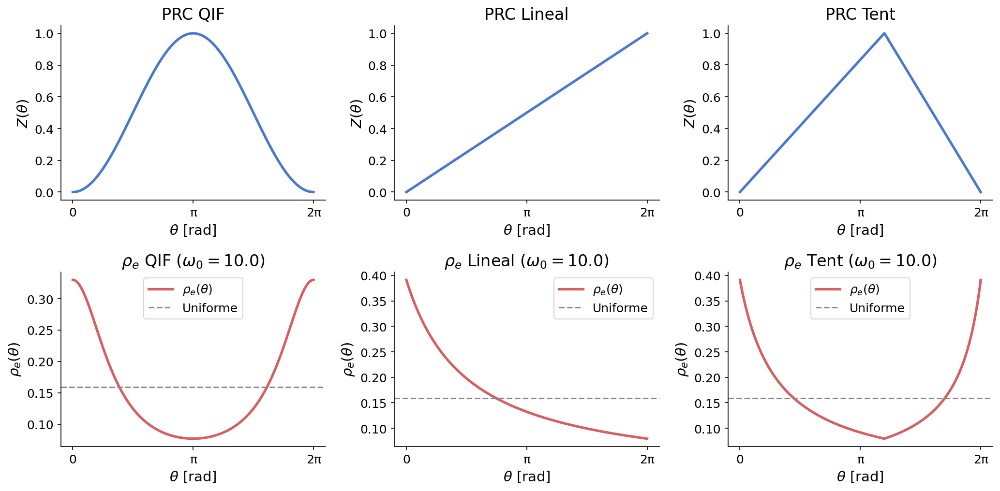

In [50]:
#  CELDA 1 | Funciones analíticas: Z_QIF, Z_lineal, Z_tent y sus ρ_e

# ==============================================================================
# 1. Modelo QIF (Quadratic Integrate-and-Fire / Neurona Theta)
# ==============================================================================

def Z_QIF(phi, I0=1.0):
    """
    Curva de Respuesta de Fase (PRC) para el modelo QIF:
        Z(φ) = sin²(φ / 2) / I₀
    Presenta excitabilidad Tipo I: modulación suave que se anula en los bordes φ = 0, 2π.
    """
    return np.sin(phi / 2)**2 / I0

def rho_e0_QIF(mu_w, I0=1.0):
    """
    Densidad en el origen ρ_e(0) para el modelo QIF, calculada imponiendo
    la condición analítica de normalización ∫₀²π ρ_e(φ) dφ = 1.
    """
    a = mu_w / I0
    return (a + np.sqrt(a**2 + 16 * np.pi**2)) / (8 * np.pi**2)

def rho_e_QIF(phi, mu_w, I0=1.0):
    """
    Distribución de fase estacionaria exacta del modelo QIF con acoplamiento μ_ω:
        ρ_e(φ) = ρ_e(0) / [ 1 + (μ_ω ρ_e(0) / I₀) · sin²(φ / 2) ]
    Válida como referencia teórica exacta cuando la distribución de pesos es una Delta: Ω(ω) = δ(ω - μ_ω).
    """
    r0 = rho_e0_QIF(mu_w, I0)
    return r0 / (1 + (mu_w * r0 / I0) * np.sin(phi / 2)**2)


# ==============================================================================
# 2. Modelo Lineal
# ==============================================================================

def Z_lineal(phi, I0=1.0):
    """
    PRC con perfil lineal monótono creciente:
        Z(φ) = φ / (2π)
    Representa una sensibilidad de fase que crece progresivamente hacia el umbral de disparo.
    """
    return phi / (2 * np.pi)

def rho_e0_lineal(mu_w):
    """
    Densidad en el origen ρ_e(0) para la PRC lineal (Z(0)=0).
    Al integrar y normalizar, la velocidad libre v se cancela, resultando:
        ρ_e(0) = [ exp(μ_ω / 2π) - 1 ] / μ_ω
    """
    return (np.exp(mu_w / (2 * np.pi)) - 1) / mu_w

def rho_e_lineal(phi, mu_w, I0=1.0):
    """
    Distribución estacionaria teórica para el modelo lineal con acoplamiento μ_ω:
        ρ_e(φ) = ρ_e(0) / [ 1 + μ_ω ρ_e(0) · (φ / 2π) ]
    Válida analíticamente para pesos deterministas homogéneos μ_ω.
    """
    r0 = rho_e0_lineal(mu_w)
    return r0 / (1 + mu_w * r0 * phi / (2 * np.pi))


# ==============================================================================
# 3. Modelo Tent (Triangular Simétrico, _TENT_FRAC = 0.5)
# ==============================================================================
# Define un perfil continuo a trozos con subida y bajada lineal:
# Z(0) = Z(2π) = 0, alcanzando un valor máximo Z_max = 1 en el vértice φ = φ_break.

_TENT_FRAC = 0.5                          # Fracción del ciclo en la que se alcanza el máximo (50% → vértice en φ = π, tienda simétrica)
_TENT_PHI1 = _TENT_FRAC * 2 * np.pi      # Fase angular del vértice
_TENT_A    = 1.0 / _TENT_PHI1            # Pendiente del tramo ascendente
_TENT_B    = 1.0 / (2*np.pi - _TENT_PHI1)  # Pendiente del tramo descendente

def Z_tent(phi, I0=1.0):
    """
    PRC tipo tent (triangular; simétrica respecto de π con _TENT_FRAC = 0.5):
        Z(φ) = A · φ           para φ ∈ [0, φ_break]
        Z(φ) = B · (2π - φ)   para φ ∈ [φ_break, 2π]
    """
    phi = np.asarray(phi, dtype=float)
    return np.where(phi <= _TENT_PHI1,
                    _TENT_A * phi,
                    _TENT_B * (2 * np.pi - phi)) / I0

def rho_e0_tent(mu_w):
    """
    Densidad en el origen ρ_e(0) para Z_tent.
    Dado que ambas ramas son lineales y Z(0)=Z(2π)=0, la integral por tramos da:
        ∫₀²π ρ_e(φ) dφ = (1/μ_ω) [ (1/A) + (1/B) ] ln(1 + μ_ω ρ_e(0)) = 1
    Dado que (1/A) + (1/B) = 2π para cualquier vértice, la normalización es idéntica a la lineal:
        ρ_e(0) = [ exp(μ_ω / 2π) - 1 ] / μ_ω
    """
    return (np.exp(mu_w / (2 * np.pi)) - 1) / mu_w

def rho_e_tent(phi, mu_w, I0=1.0):
    """
    Distribución estacionaria exacta para el modelo tent con acoplamiento μ_ω:
        Rama 1: ρ_e(φ) = ρ_e(0) / [ 1 + μ_ω ρ_e(0) · A · φ ]
        Rama 2: ρ_e(φ) = ρ_e(0) / [ 1 + μ_ω ρ_e(0) · B · (2π - φ) ]
    """
    phi = np.asarray(phi, dtype=float)
    r0 = rho_e0_tent(mu_w)
    rama1 = r0 / (1 + mu_w * r0 * _TENT_A * phi)
    rama2 = r0 / (1 + mu_w * r0 * _TENT_B * (2 * np.pi - phi))
    return np.where(phi <= _TENT_PHI1, rama1, rama2)


# ==============================================================================
# 4. Función de diagnóstico y verificación visual
# ==============================================================================

def plot_funciones_analiticas(mu_w=0.5, I0=1.0):
    """Grafica las PRCs Z(φ) y las densidades estacionarias ρ_e(φ) verificando su normalización."""
    phi = np.linspace(0, 2 * np.pi, 1000)

    fig, axes = plt.subplots(2, 3, figsize=(14, 7))

    configs = [
        (Z_QIF,    rho_e_QIF,    'QIF',    True),
        (Z_lineal, rho_e_lineal, 'Lineal', False),
        (Z_tent,   rho_e_tent,   'Tent',   False),
    ]

    for col, (Z_fn, rho_fn, nombre, usa_I0) in enumerate(configs):

        # Fila 0: Gráfico de la PRC Z(φ)
        z_vals = Z_fn(phi, I0) if usa_I0 else Z_fn(phi)
        axes[0, col].plot(phi, z_vals, color=STYLE['color_hist'], lw=STYLE['lw_main'])
        axes[0, col].set_title(f'PRC {nombre}')
        axes[0, col].set_xlabel(r'Fase $\phi$ [rad]')
        axes[0, col].set_ylabel(r'$Z(\phi)$ [rad/u.v.]')
        axes[0, col].set_xticks([0, np.pi, 2 * np.pi])
        axes[0, col].xaxis.set_major_formatter(pi_formatter)

        # Fila 1: Gráfico de la densidad estacionaria teórica ρ_e(φ)
        rho_vals = rho_fn(phi, mu_w, I0) if usa_I0 else rho_fn(phi, mu_w)
        axes[1, col].plot(phi, rho_vals, color=STYLE['color_rhoe'], lw=STYLE['lw_main'], label=r'$\rho_e(\phi)$')
        axes[1, col].axhline(1 / (2 * np.pi), color=STYLE['color_unif'], lw=STYLE['lw_aux'],
                             linestyle='--', label='Uniforme')
        axes[1, col].set_title(rf'$\rho_e$ {nombre} ($\mu_\omega={mu_w}$ u.v.)')
        axes[1, col].set_xlabel(r'Fase $\phi$ [rad]')
        axes[1, col].set_ylabel(r'$\rho_e(\phi)$ [1/rad]')
        axes[1, col].set_xticks([0, np.pi, 2 * np.pi])
        axes[1, col].xaxis.set_major_formatter(pi_formatter)
        axes[1, col].legend()

    # Verificación numérica de la conservación de la probabilidad ∫ ρ_e dφ = 1
    norm_qif = np.trapezoid(rho_e_QIF(phi, mu_w, I0), phi)
    norm_lin = np.trapezoid(rho_e_lineal(phi, mu_w), phi)
    norm_ten = np.trapezoid(rho_e_tent(phi, mu_w), phi)
    print(f"Normalización ρ_e QIF:    {norm_qif:.6f}  (debe ser 1.0)")
    print(f"Normalización ρ_e lineal: {norm_lin:.6f}  (debe ser 1.0)")
    print(f"Normalización ρ_e tent:   {norm_ten:.6f}  (debe ser 1.0)")

    plt.tight_layout()
    plt.savefig('funciones_analiticas.png', bbox_inches='tight')
    plt.show()

# Ejecución de prueba con acoplamiento representativo
plot_funciones_analiticas(mu_w=10.0)

### Celda 1.5 | Familia de Bifurcaciones SNIC–SNL: PRC Continua y Estados Estacionarios

1. **¿Qué hace esta celda?**  
   Introduce la familia continua de curvas de respuesta de fase $Z_{\text{SN}}(\phi; \vartheta)$ que describe la transición continua entre neuronas con excitabilidad Tipo I (bifurcación SNIC en $\vartheta = -\pi/2$) y Tipo II (bifurcación SNL en $\vartheta = 0$), calculando sus densidades estacionarias $\rho_e(\phi)$ y el campo medio macroscópico $p_e$.

2. **¿Cómo lo hace?**  
   Modela la PRC mediante:
   $$Z_{\text{SN}}(\phi, \vartheta) = I_0 \cos^2\left[ \frac{(\pi/2 - \vartheta)\phi}{2\pi} + \vartheta \right]$$
   Para los límites canónicos SNIC y SNL emplea las soluciones cerradas de $\rho_e(0)$, mientras que para valores intermedios de $\vartheta$ resuelve la condición implícita de normalización $\int_0^{2\pi} \rho_e(\phi)\,d\phi = 1$ mediante el método de Brent (`scipy.optimize.root_scalar`).

3. **¿Qué devuelve o cuál es su resultado/salida?**  
   Proporciona funciones vectorizadas para evaluar $Z_{\text{SNIC}}$, $Z_{\text{SNL}}$, $\rho_{e,\text{SNIC}}$, $\rho_{e,\text{SNL}}$, el campo medio $p_e$, y grafica la comparativa junto con la verificación de normalización por cuadratura trapezoidal.

Normalización ρ_e SNIC:   1.000000  (debe ser 1.0)
Normalización ρ_e SNL:    1.000000  (debe ser 1.0)


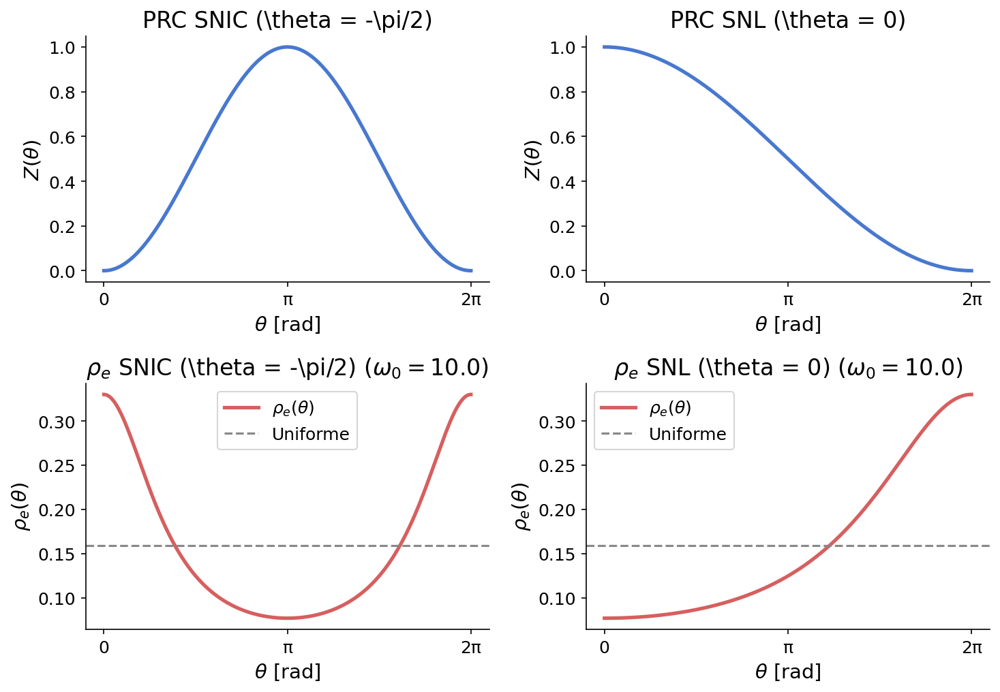

In [51]:
#  CELDA 1.5 | Curvas de respuesta de fase (PRC) y densidades estacionarias para SNIC y SNL

import scipy.integrate as integrate  # Integración numérica por cuadratura adaptativa
import scipy.optimize as optimize    # Algoritmos de búsqueda de raíces para ecuaciones implícitas

# 1. Definición explícita de Z(φ) para la familia de bifurcaciones SNIC-SNL
def Z_SN(phi, theta, I0=1.0):
    """
    Curva de Respuesta de Fase (PRC) para neuronas cercanas a bifurcaciones SNIC y SNL:
        Z(φ) = I₀ · cos²[ ((π/2 - ϑ)·φ) / (2π) + ϑ ]
    donde:
        - I₀: constante de amplitud (default = 1.0)
        - ϑ (theta): parámetro continuo de excitabilidad
          ϑ = -π/2 describe el límite SNIC (excitabilidad Tipo I)
          ϑ = 0    describe el límite SNL (excitabilidad Tipo II)
    """
    return I0 * np.cos(((np.pi/2 - theta) * phi) / (2.0 * np.pi) + theta)**2

# 2. Cálculo de la densidad en el origen rho_e0_SN(ϑ, μ_ω, I₀)
def rho_e0_SN(theta, mu_w, I0=1.0):
    """
    Calcula ρ_e(0) imponiendo la condición de conservación de probabilidad ∫₀²π ρ_e(φ) dφ = 1.
    - Para los límites ϑ = -π/2 (SNIC) y ϑ = 0 (SNL) se emplean expresiones analíticas cerradas.
    - Para valores intermedios de ϑ, se resuelve numéricamente la ecuación implícita de normalización.
    """
    # Límite analítico SNIC (ϑ = -π/2)
    if np.isclose(theta, -np.pi/2):
        term = mu_w * I0
        return (term + np.sqrt(term**2 + 16.0 * np.pi**2)) / (8.0 * np.pi**2)

    # Límite analítico SNL (ϑ = 0)
    elif np.isclose(theta, 0.0):
        term = mu_w * I0
        return (-term + np.sqrt(term**2 + 16.0 * np.pi**2)) / (8.0 * np.pi**2)

    # Caso continuo general: Resolución numérica por búsqueda de ceros
    Z0 = Z_SN(0.0, theta, I0)

    # Cota superior r_max para mantener el denominador estrictamente positivo:
    # 1 + μ_ω · r₀ · [ Z(φ) - Z(0) ] > 0 en todo el dominio angular φ ∈ [0, 2π]
    r_max = np.inf
    if mu_w > 0:
        if Z0 > 0:
            r_max = 1.0 / (mu_w * Z0)
    elif mu_w < 0:
        Z_max_diff = I0 - Z0
        if Z_max_diff > 0:
            r_max = 1.0 / (abs(mu_w) * Z_max_diff)

    # Función residual: F(r₀) = r₀ · ∫₀²π 1 / [ 1 + μ_ω r₀ (Z(φ) - Z(0)) ] dφ - 1 = 0
    def objective(r0):
        integrand = lambda phi: 1.0 / (1.0 + mu_w * r0 * (Z_SN(phi, theta, I0) - Z0))
        val, _ = integrate.quad(integrand, 0.0, 2.0 * np.pi)
        return r0 * val - 1.0

    # Intervalo de búsqueda acotado para el algoritmo robusto de Brent
    a = 1e-12
    b = 100.0 if np.isinf(r_max) else 0.9999 * r_max

    sol = optimize.root_scalar(objective, bracket=[a, b], method='brentq')
    return sol.root

# 3. Distribución de fases estacionaria continua rho_e_SN(φ)
def rho_e_SN(phi, theta, mu_w, I0=1.0):
    """
    Distribución de fase estacionaria teórica ρ_e(φ) para la familia SNIC-SNL:
        ρ_e(φ) = ρ_e(0) / [ 1 + μ_ω · ρ_e(0) · (Z(φ) - Z(0)) ]
    """
    r0 = rho_e0_SN(theta, mu_w, I0)
    Z0 = Z_SN(0.0, theta, I0)
    return r0 / (1.0 + mu_w * r0 * (Z_SN(phi, theta, I0) - Z0))

# 4. Campo medio macroscópico estacionario p_e
def p_e_SN(theta, mu_w, v, I0=1.0):
    """
    Campo medio en el estado estacionario:
        p_e = (μ_ω · v · ρ_e(0)) / [ 1 - μ_ω · Z(0) · ρ_e(0) ]
    donde v es la velocidad de fase libre (v = 2π / T).
    """
    r0 = rho_e0_SN(theta, mu_w, I0)
    Z0 = Z_SN(0.0, theta, I0)
    return (mu_w * v * r0) / (1.0 - mu_w * Z0 * r0)

# 5. Funciones de interfaz para límites estándar SNIC y SNL

def Z_SNIC(phi, I0=1.0):
    """PRC en el límite SNIC (ϑ = -π/2): Z(φ) = I₀ · sin²(φ / 2)"""
    return Z_SN(phi, theta=-np.pi/2, I0=I0)

def rho_e_SNIC(phi, mu_w, I0=1.0):
    """Distribución de fase estacionaria en el límite SNIC (ϑ = -π/2)"""
    return rho_e_SN(phi, theta=-np.pi/2, mu_w=mu_w, I0=I0)

def Z_SNL(phi, I0=1.0):
    """PRC en el límite SNL (ϑ = 0): Z(φ) = I₀ · cos²(φ / 4)"""
    return Z_SN(phi, theta=0.0, I0=I0)

def rho_e_SNL(phi, mu_w, I0=1.0):
    """Distribución de fase estacionaria en el límite SNL (ϑ = 0)"""
    return rho_e_SN(phi, theta=0.0, mu_w=mu_w, I0=I0)

# 6. Gráfico de verificación adaptado del bloque 1

def plot_funciones_analiticas_SN(mu_w=0.5, I0=1.0):
    """Compara visual y cuantitativamente las PRCs y densidades teóricas de SNIC y SNL."""
    phi = np.linspace(0, 2 * np.pi, 1000)

    fig, axes = plt.subplots(2, 2, figsize=(10, 7))

    configs = [
        (Z_SNIC, rho_e_SNIC, 'SNIC ($\\vartheta = -\\pi/2$)', True),
        (Z_SNL,  rho_e_SNL,  'SNL ($\\vartheta = 0$)', True),
    ]

    for col, (Z_fn, rho_fn, nombre, usa_I0) in enumerate(configs):

        # Fila 0: PRC Z(φ)
        z_vals = Z_fn(phi, I0) if usa_I0 else Z_fn(phi)
        axes[0, col].plot(phi, z_vals, color=STYLE['color_hist'], lw=STYLE['lw_main'])
        axes[0, col].set_title(f'PRC {nombre}')
        axes[0, col].set_xlabel(r'Fase $\phi$ [rad]')
        axes[0, col].set_ylabel(r'$Z(\phi)$ [rad/u.v.]')
        axes[0, col].set_xticks([0, np.pi, 2 * np.pi])
        axes[0, col].xaxis.set_major_formatter(pi_formatter)

        # Fila 1: Densidad teórica ρ_e(φ)
        rho_vals = rho_fn(phi, mu_w, I0) if usa_I0 else rho_fn(phi, mu_w)
        axes[1, col].plot(phi, rho_vals, color=STYLE['color_rhoe'], lw=STYLE['lw_main'], label=r'$\rho_e(\phi)$')
        axes[1, col].axhline(1 / (2 * np.pi), color=STYLE['color_unif'], lw=STYLE['lw_aux'],
                             linestyle='--', label='Uniforme')
        axes[1, col].set_title(rf'$\rho_e$ {nombre} ($\mu_\omega={mu_w}$ u.v.)')
        axes[1, col].set_xlabel(r'Fase $\phi$ [rad]')
        axes[1, col].set_ylabel(r'$\rho_e(\phi)$ [1/rad]')
        axes[1, col].set_xticks([0, np.pi, 2 * np.pi])
        axes[1, col].xaxis.set_major_formatter(pi_formatter)
        axes[1, col].legend()

    # Verificación numérica de la integral de normalización
    norm_snic = np.trapezoid(rho_e_SNIC(phi, mu_w, I0), phi)
    norm_snl  = np.trapezoid(rho_e_SNL(phi, mu_w, I0), phi)
    print(f"Normalización ρ_e SNIC:   {norm_snic:.6f}  (debe ser 1.0)")
    print(f"Normalización ρ_e SNL:    {norm_snl:.6f}  (debe ser 1.0)")

    plt.tight_layout()
    plt.savefig('funciones_analiticas_SN.png', bbox_inches='tight')
    plt.show()

# Ejecución del test de diagnóstico
plot_funciones_analiticas_SN(mu_w=10.0)

### Celda 2 | Distribución de Acoplamientos Sinápticos $\Omega(\omega)$: Desorden Recocido

1. **¿Qué hace esta celda?**  
   Implementa la fábrica de distribuciones de probabilidad $\Omega(\omega)$ para los acoplamientos sinápticos instantáneos, permitiendo simular tanto interacciones homogéneas deterministas (Delta de Dirac) como fluctuaciones estocásticas heterogéneas (distribución Uniforme) bajo la hipótesis de desorden recocido (annealed disorder).

2. **¿Cómo lo hace?**  
   A través de la función constructora `make_omega_dist(tipo, mu, Delta)`:
   - Caso `'delta'`: asigna idéntico peso $\omega_i = \mu_\omega$ a cada conexión.
   - Caso `'uniforme'`: sortea $\omega_i \sim \mathcal{U}[\mu_\omega - \Delta/2, \mu_\omega + \Delta/2]$ conservando el valor medio $\langle \omega \rangle = \mu_\omega$.  
   Incluye `plot_omega_dist` para verificar el muestreo numérico frente a la función teórica.

3. **¿Qué devuelve o cuál es su resultado/salida?**  
   Devuelve una función generadora `sampler(size)` que retorna vectores aleatorios de tamaño $N$, un diccionario de metadatos `info` con límites y rótulos en formato LaTeX, y grafica las distribuciones de prueba.

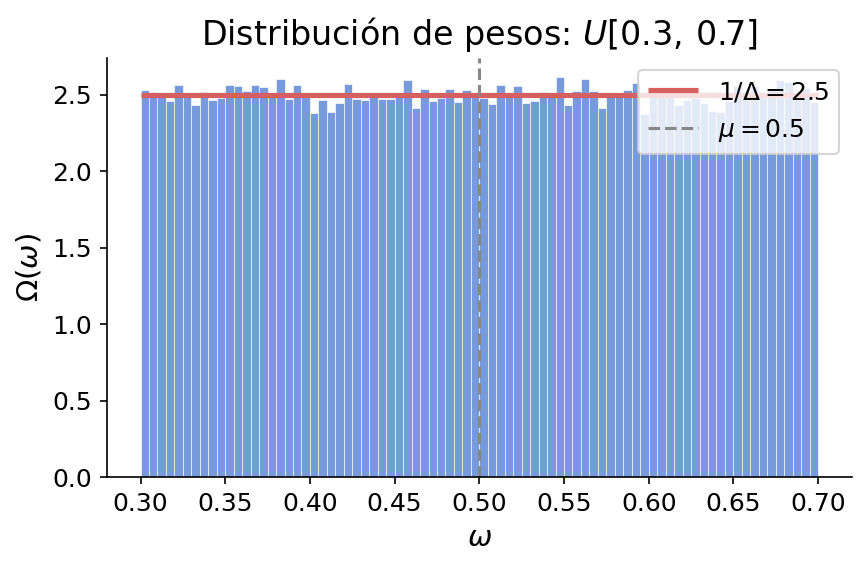

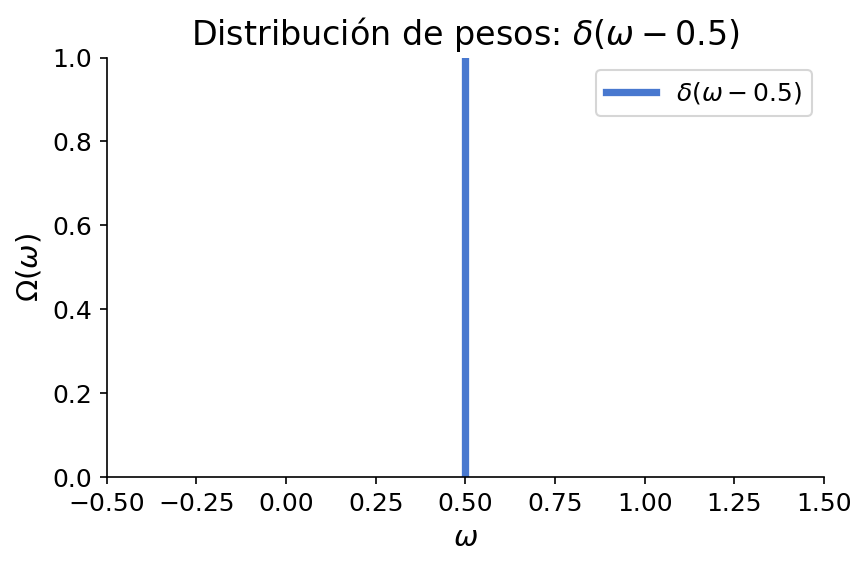

In [52]:
#  CELDA 2 | Distribución Ω(ω): factory y plot

# 1. Fábrica de muestreadores de pesos sinápticos Ω(ω)
def make_omega_dist(tipo, mu, Delta=0.0):
    """
    Crea una función sampler para la distribución de pesos Ω(ω) fijando el valor medio μ_ω.

    Parámetros
    ----------
    tipo  : 'delta'    → ωᵢ = μ_ω para toda neurona (caso determinista/homogéneo)
            'uniforme' → ωᵢ ~ U[μ_ω - Δ/2, μ_ω + Δ/2] (heterogeneidad estocástica)
    mu    : valor medio ⟨ω⟩ (puede ser excitatorio μ_ω > 0 o inhibitorio μ_ω < 0)
    Delta : ancho total de la distribución de soporte (solo para 'uniforme')

    Devuelve
    --------
    sampler(size) → función que devuelve un ndarray con 'size' pesos sorteados
    info          → diccionario con metadatos para títulos, etiquetas y rangos de soporte
    """
    if tipo == 'delta':
        # Vector constante de tamaño especificado
        def sampler(size):
            return np.full(size, mu)
        info = dict(tipo='delta', mu=mu, Delta=0.0,
                    label=rf'$\delta(\omega - {mu})$',
                    omega_min=mu, omega_max=mu)

    elif tipo == 'uniforme':
        # Límites del soporte continuo
        a = mu - Delta / 2.0
        b = mu + Delta / 2.0
        def sampler(size):
            return np.random.uniform(a, b, size)
        info = dict(tipo='uniforme', mu=mu, Delta=Delta,
                    label=rf'$U[{a:.3g},\, {b:.3g}]$',
                    omega_min=a, omega_max=b)

    else:
        raise ValueError("tipo de distribución no reconocido: debe ser 'delta' o 'uniforme'")

    return sampler, info


# 2. Rutina de visualización y verificación de Ω(ω)
def plot_omega_dist(info, n_samples=200_000, n_bins=80):
    """
    Grafica la densidad de probabilidad Ω(ω): histograma de muestras (uniforme) o impulso vertical (delta).
    """
    fig, ax = plt.subplots(figsize=STYLE['figsize_single'])

    if info['tipo'] == 'delta':
        # Línea vertical representando el impulso de Dirac en ω = μ_ω
        ax.axvline(info['mu'], color=STYLE['color_hist'],
                   lw=STYLE['lw_main'] + 1, label=info['label'])
        ax.set_xlim(info['mu'] - 1, info['mu'] + 1)

    elif info['tipo'] == 'uniforme':
        # Generación de muestras estocásticas
        sampler, _ = make_omega_dist('uniforme', info['mu'], info['Delta'])
        samples = sampler(n_samples)

        # Histograma normalizado de las muestras
        ax.hist(samples, bins=n_bins, density=True,
                color=STYLE['color_hist'], alpha=0.75,
                edgecolor='white', linewidth=0.4)

        # Curva de densidad teórica plana 1/Δ en el intervalo [a, b]
        a, b = info['omega_min'], info['omega_max']
        ax.hlines(1.0 / (b - a), a, b,
                  color=STYLE['color_rhoe'], lw=STYLE['lw_main'],
                  label=rf'$1/\Delta = {1/(b-a):.3g}$')
        ax.axvline(info['mu'], color=STYLE['color_unif'],
                   lw=STYLE['lw_aux'], linestyle='--',
                   label=rf'$\mu_\omega = {info["mu"]}$')

    ax.set_xlabel(r'Peso sináptico $\omega$ [u.v.]')
    ax.set_ylabel(r'$\Omega(\omega)$ [1/u.v.]')
    ax.set_title(rf'Distribución de pesos: {info["label"]}')
    ax.legend()

    plt.tight_layout()
    plt.savefig('omega_dist.png', bbox_inches='tight')
    plt.show()

# 3. Test de validación con distribución uniforme y delta
sampler_test, info_test = make_omega_dist('uniforme', mu=0.5, Delta=0.4)
plot_omega_dist(info_test)

sampler_delta, info_delta = make_omega_dist('delta', mu=0.5)
plot_omega_dist(info_delta)

### Celda 3 | Observables Macroscópicos: Densidad Empírica de Fases $\psi_N(\phi)$, Parámetros de Sincronía $s_k$ y Referencia Estacionaria Teórica $s_1^{\text{est}}$

1. **¿Qué hace esta celda?**  
   Define las funciones estadísticas fundamentales para extraer los observables macroscópicos de la red: la **densidad empírica de fases $\psi_N(\phi)$** (estimada a partir del ensamble microscópico discreto de $N$ osciladores), los parámetros de orden de Kuramoto empíricos instantáneos $s_k$, y el cálculo del valor teórico del primer parámetro de orden en el estado estacionario de campo medio $s_1^{\text{est}}$.

2. **¿Cómo lo hace?**  
   - `calcular_histograma`: discretiza el dominio periódico $[0, 2\pi)$ en $n_{\text{bins}}$ intervalos y evalúa la densidad empírica de probabilidad normalizada $\int_0^{2\pi} \psi_N(\phi)\,d\phi = 1$.
   - `calcular_sincronia`: computa vectorialmente el promedio de ensamble microscópico de las exponenciales complejas circulares para los primeros tres armónicos ($k = 1, 2, 3$):
     $$s_k = \left| \frac{1}{N} \sum_{j=1}^N e^{i k \phi_j} \right|$$
   - `calcular_s1_estacionario`: integra numéricamente mediante cuadratura sobre el ciclo periódico $[0, 2\pi)$ la **densidad teórica continua del estado estacionario $\rho_e(\phi)$** ($N \to \infty$):
     $$s_1^{\text{est}} = \left| \int_0^{2\pi} e^{i \phi} \rho_e(\phi) \, d\phi \right|$$
     proporcionando el punto fijo teórico asintótico contra el cual comparar la dinámica microscópica de la red.

3. **¿Qué devuelve o cuál es su resultado/salida?**  
   - `calcular_histograma` retorna la tupla `(phi_centers, counts)` con las coordenadas angulares y la densidad empírica $\psi_N(\phi)$ estimada en cada bin.
   - `calcular_sincronia` retorna el diccionario `{1: s1, 2: s2, 3: s3}`.
   - `calcular_s1_estacionario` retorna el escalar flotante $s_1^{\text{est}} \in [0, 1]$ (o `None` si no se dispone de distribución analítica).


In [53]:
#  CELDA 3 | Histograma de fases (densidad empírica ψ_N) + grados de sincronía y referencia estacionaria teórica

# 1. Función para computar la densidad empírica de fases ψ_N(φ)
def calcular_histograma(phis, n_bins=100):
    """
    Calcula el histograma normalizado de la densidad empírica de fases ψ_N(φ) sobre [0, 2π).

    Parámetros
    ----------
    phis   : ndarray de tamaño (N,) con las fases instantáneas φᵢ del ensamble discreto
    n_bins : cantidad de bins de discretización angular

    Devuelve
    --------
    phi_centers : coordenadas angulares centrales de los bins, shape (n_bins,)
    densidad    : densidad empírica ψ_N(φ) estimada empíricamente, normalizada (∫ ψ_N dφ = 1)
    """
    counts, edges = np.histogram(phis, bins=n_bins,
                                 range=(0, 2 * np.pi), density=True)
    phi_centers = 0.5 * (edges[:-1] + edges[1:])
    return phi_centers, counts


# 2. Función para evaluar los parámetros de orden de Kuramoto empíricos
def calcular_sincronia(phis):
    """
    Calcula la magnitud de los primeros tres momentos circulares de Kuramoto:
        sₖ = |⟨ e^{i k φ} ⟩| = | (1/N) ∑ⱼ exp(i k φⱼ) |   para k = 1, 2, 3

    Parámetros
    ----------
    phis : ndarray de fases de los N osciladores

    Devuelve
    --------
    dict {1: s1, 2: s2, 3: s3} con los escalares de sincronía sₖ ∈ [0, 1]
    """
    return {n: float(np.abs(np.mean(np.exp(1j * n * phis))))
            for n in [1, 2, 3]}


# 3. Función para calcular el primer parámetro de orden en el estado estacionario teórico
def calcular_s1_estacionario(rho_e_fn, mu_w, I0=1.0, n_grid=2000):
    """
    Calcula el valor teórico del primer parámetro de orden de Kuramoto en el estado estacionario:
        s₁ᵉˢᵗ = | ∫₀²π exp(i φ) ρₑ(φ) dφ |

    Parámetros
    ----------
    rho_e_fn : función teórica continua ρ_e(φ, mu_w, I0) de la densidad estacionaria del modelo
    mu_w   : parámetro de acoplamiento medio μ_ω
    I0       : amplitud de corriente / modulación (default = 1.0)
    n_grid   : cantidad de nodos de discretización para la integración numérica

    Devuelve
    --------
    s1_est : float ∈ [0, 1] con la magnitud del grado de sincronía estacionario teórico,
             o None si rho_e_fn o mu_w no fueron especificados.
    """
    if rho_e_fn is None or mu_w is None:
        return None
    phi = np.linspace(0, 2 * np.pi, n_grid)
    try:
        rho = rho_e_fn(phi, mu_w, I0)
    except TypeError:
        rho = rho_e_fn(phi, mu_w)
    # Cuadratura numérica trapezoidal del momento circular complejo z₁ = ∫ exp(i φ) ρ(φ) dφ
    z1 = np.trapezoid(np.exp(1j * phi) * rho, phi)
    return float(np.abs(z1))


### Celda 4 | Visualización: Densidad Empírica Instantánea $\psi_N(\phi)$ vs. $\rho_e(\phi)$ Teórica

1. **¿Qué hace esta celda?**  
   Grafica la distribución angular instantánea de los osciladores de la red sobre el intervalo periódico $[0, 2\pi)$, superponiendo la **densidad empírica** $\psi_N(\phi)$ (obtenida del histograma normalizado de las $N$ neuronas simuladas) con la curva analítica teórica de campo medio $\rho_e(\phi)$ del estado estacionario y la referencia uniforme $1/(2\pi)$.

2. **¿Cómo lo hace?**  
   Utiliza `calcular_histograma` para obtener los bins y la densidad empírica $\psi_N(\phi)$, traza el diagrama de barras con escala normalizada, superpone la función analítica continua $\rho_e(\phi, \mu_\omega)$ y la línea de incoherencia homogénea, e imprime en el encabezado los valores instantáneos de sincronía $s_1, s_2, s_3$.

3. **¿Qué devuelve o cuál es su resultado/salida?**  
   Produce una figura de Matplotlib (y opcionalmente la guarda en disco como imagen `.png`) formateando el eje de abscisas en fracciones de $\pi$.


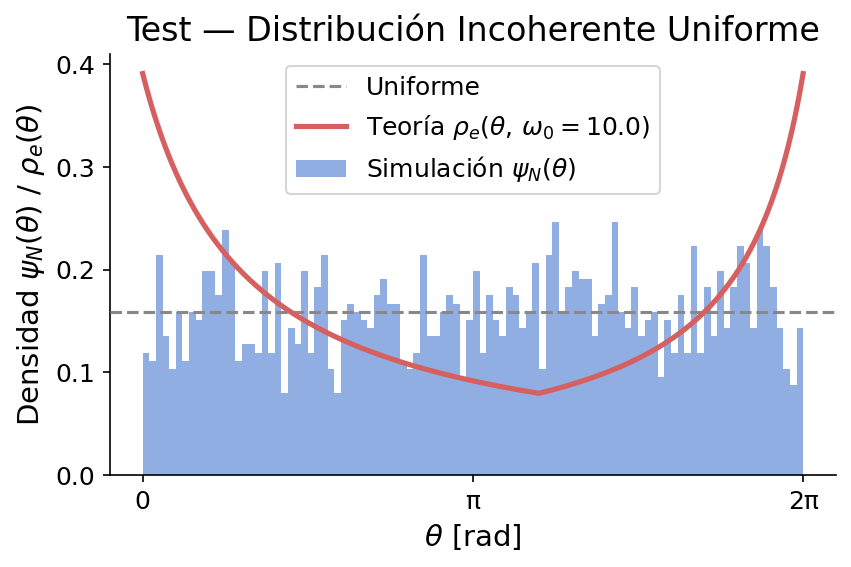

In [54]:
#  CELDA 4 | Plot: densidad empírica de fases ψ_N(φ) vs ρ_e teórica

def plot_histograma(phis, mu_w_ref=None, I0=1.0, rho_e_fn=None,
                    titulo='', n_bins=100, fname=None):
    """
    Grafica la densidad empírica de fases instantánea ψ_N(φ) sobre [0, 2π).
    Superpone la densidad estacionaria teórica continua ρ_e(φ, mu_w_ref, I0) si se proporciona.

    Parámetros
    ----------
    phis       : array con las fases φᵢ de los N osciladores discretos
    mu_w_ref : valor del acoplamiento medio μ_ω para la referencia analítica teórica (None = no graficar)
    rho_e_fn   : función teórica continua ρ_e(φ, μ_ω, I₀) correspondiente al modelo evaluado
    titulo     : texto personalizado para el título de la figura
    n_bins     : número de barras en el histograma
    fname      : nombre de archivo para persistir la figura (opcional)
    """
    if rho_e_fn is None:
        rho_e_fn = rho_e_QIF   # Modelo QIF por defecto

    # Grilla de evaluación para la curva analítica continua
    phi_grid = np.linspace(0, 2 * np.pi, 1000)
    phi_c, dens = calcular_histograma(phis, n_bins)

    fig, ax = plt.subplots(figsize=STYLE['figsize_single'])

    # 1. Barras de la densidad empírica simulada ψ_N(φ)
    ax.bar(phi_c, dens,
           width=(2 * np.pi / n_bins),
           color=STYLE['color_hist'], alpha=0.6,
           label=r'Simulación $\psi_N(\phi)$', zorder=2)

    # 2. Línea horizontal de referencia uniforme (incoherencia total: 1/(2π))
    ax.axhline(1 / (2 * np.pi),
               color=STYLE['color_unif'], lw=STYLE['lw_aux'],
               linestyle='--', label='Uniforme', zorder=3)

    # 3. Curva teórica del estado estacionario analítico ρ_e(φ)
    if mu_w_ref is not None:
        ax.plot(phi_grid, rho_e_fn(phi_grid, mu_w_ref, I0),
                color=STYLE['color_rhoe'], lw=STYLE['lw_main'],
                label=rf'Teoría $\rho_e(\phi,\,\mu_\omega={mu_w_ref})$',
                zorder=4)

    # Métricas de sincronización instantánea para el encabezado
    s = calcular_sincronia(phis)
    ax.set_title(titulo or
                 rf'$s_1={s[1]:.3f},\; s_2={s[2]:.3f},\; s_3={s[3]:.3f}$')
    ax.set_xlabel(r'Fase $\phi$ [rad]')
    ax.set_ylabel(r'Densidad $\psi_N(\phi)$ / $\rho_e(\phi)$ [1/rad]')
    ax.set_xticks([0, np.pi, 2 * np.pi])
    ax.xaxis.set_major_formatter(pi_formatter)
    ax.legend()

    plt.tight_layout()
    if fname:
        plt.savefig(fname, bbox_inches='tight')
    plt.show()

# Test unitario con una distribución uniforme aleatoria
phis_test = np.random.uniform(0, 2 * np.pi, 2000)
plot_histograma(phis_test, mu_w_ref=10.0, I0=1.0, rho_e_fn=rho_e_tent,
                titulo='Test — Distribución Incoherente Uniforme')


### Celda 5 | Visualización: Dinámica Temporal de la Sincronía $s_k(t)$ y Referencia Estacionaria $s_1^{\text{est}}$

1. **¿Qué hace esta celda?**  
   Grafica la evolución temporal simultánea de los tres primeros parámetros de orden de Kuramoto $s_1(t)$, $s_2(t)$ y $s_3(t)$, incorporando opcionalmente el nivel de referencia teórico del estado estacionario ($s_1^{\text{est}}$) para contrastar visualmente el régimen asintótico o las fluctuaciones y oscilaciones colectivas alrededor del punto fijo.

2. **¿Cómo lo hace?**  
   Representa las trayectorias de sincronía con respecto al tiempo normalizado en unidades de $\pi$ ($t/\pi$). Si se proporciona `s1_est`, traza una línea horizontal punteada de color gris (`axhline`) que indica el valor asintótico teórico continuo.

3. **¿Qué devuelve o cuál es su resultado/salida?**  
   Despliega una figura de formato ancho (`figsize_wide`) con leyenda autoexplicativa y opcionalmente almacena la imagen en el archivo `sincronia.png`.


In [55]:
#  CELDA 5 | Plot: grados de sincronía sₙ(t) con referencia teórica estacionaria

def plot_sincronia(tiempos, s_dict, s1_est=None, fname=None):
    """
    Grafica la evolución temporal de los órdenes de sincronización s₁(t), s₂(t), s₃(t).
    El eje de abscisas se expresa en unidades normalizadas de π.

    Parámetros
    ----------
    tiempos : array o lista con los tiempos de muestreo de los snapshots
    s_dict  : diccionario con las series temporales {1: [s₁], 2: [s₂], 3: [s₃]}
    s1_est  : valor teórico del grado de sincronía en el estado estacionario s₁ᵉˢᵗ (opcional)
    fname   : nombre de archivo de salida (opcional)
    """
    t = np.array(tiempos)
    colors = [STYLE['color_s1'], STYLE['color_s2'], STYLE['color_s3']]
    labels = [r'$s_1(t)$', r'$s_2(t)$', r'$s_3(t)$']

    fig, ax = plt.subplots(figsize=STYLE['figsize_wide'])

    # Graficado de cada armónico de sincronía con su estilo respectivo
    for (n, vals), color, label in zip(s_dict.items(), colors, labels):
        ax.plot(t / np.pi, vals,
                color=color, lw=STYLE['lw_main'], label=label)

    # Línea horizontal punteada del estado estacionario teórico s₁ᵉˢᵗ
    if s1_est is not None:
        ax.axhline(s1_est, color='gray', linestyle='--', lw=STYLE['lw_aux'] + 0.5,
                   label=rf'$s_1$ estacionario teó. ($s_1^{{\rm est}} = {s1_est:.4f}$)')

    ax.set_xlabel(r'Tiempo $t$ [$\pi\,$u.t.]')
    ax.set_ylabel(r'$s_k(t)$ [adim.]')
    ax.set_ylim(0, 1.05)           # Los parámetros de orden están acotados en [0, 1]
    ax.set_title('Evolución Temporal de los Parámetros de Sincronía')
    ax.legend(ncol=2 if s1_est is not None else 3)
    ax.grid(True, alpha=0.25, linestyle='--')

    plt.tight_layout()
    if fname:
        plt.savefig(fname, bbox_inches='tight')
    plt.show()


### Celda 6 | Visualización: Mapa Espacio-Temporal de la Densidad Empírica $\psi(\phi, t)$

1. **¿Qué hace esta celda?**  
   Construye un mapa de calor bidimensional continuo (heatmap) que visualiza la evolución espacio-temporal completa de la **densidad empírica de fases $\psi(\phi, t)$** (o $\psi_N(\phi, t)$) a lo largo de la simulación.

2. **¿Cómo lo hace?**  
   Dispone la matriz de histogramas temporales en una grilla ortogonal mediante `pcolormesh`, con el tiempo $t/\pi$ en abscisas y la fase angular $\phi \in [0, 2\pi)$ en ordenadas. Emplea una normalización no lineal por ley de potencias (`PowerNorm(gamma=0.6)`) para amplificar el contraste de regiones de baja densidad empírica sin saturar los cúmulos de disparo.

3. **¿Qué devuelve o cuál es su resultado/salida?**  
   Genera una figura 2D con barra de color calibrada (`heatmap_psi.png` si se guarda), evidenciando si el sistema decae a un perfil asincrónico estacionario o desarrolla ondas viajeras y oscilaciones colectivas.


In [56]:
#  CELDA 6 | Plot: heatmap ψ(φ, t) (densidad empírica espacio-temporal)

def plot_heatmap_psi(tiempos, histogramas, n_bins=100, fname=None):
    """
    Grafica la densidad empírica de fases ψ(φ, t) como mapa de calor 2D (heatmap espacio-temporal).

    Parámetros
    ----------
    tiempos     : array de shape (T,) con los instantes temporales de los snapshots
    histogramas : matriz de shape (T, n_bins) con las densidades empíricas evaluadas
    n_bins      : resolución en cantidad de celdas angulares
    fname       : nombre de archivo de salida (opcional)
    """
    t = np.array(tiempos) / np.pi          # Tiempo escalado en unidades de π
    phi_edges = np.linspace(0, 2 * np.pi, n_bins + 1)
    phi_centers = 0.5 * (phi_edges[:-1] + phi_edges[1:])

    # Matriz traspuesta para alinear tiempo en eje x y fase en eje y: shape (n_bins, T)
    Z_mat = np.array(histogramas).T

    fig, ax = plt.subplots(figsize=STYLE['figsize_heatmap'])

    # Graficado bidimensional con compresión de contraste PowerNorm
    pcm = ax.pcolormesh(
        t, phi_centers, Z_mat,
        cmap=STYLE['cmap_heatmap'],
        shading='auto',
        norm=mcolors.PowerNorm(gamma=0.6),  # Realza detalles finos en regiones de baja densidad
    )

    cbar = fig.colorbar(pcm, ax=ax, pad=0.02)
    cbar.set_label(r'$\psi(\phi, t)$ [1/rad]', fontsize=STYLE['fontsize_label'])

    ax.set_xlabel(r'Tiempo $t$ [$\pi\,$u.t.]')
    ax.set_ylabel(r'Fase $\phi$ [rad]')
    ax.set_yticks([0, np.pi, 2 * np.pi])
    ax.yaxis.set_major_formatter(pi_formatter)
    ax.set_title(r'Evolución Espacio-Temporal de la Densidad Empírica $\psi(\phi, t)$')

    plt.tight_layout()
    if fname:
        plt.savefig(fname, bbox_inches='tight')
    plt.show()

# Alias de compatibilidad hacia atrás (nombre antiguo; la magnitud graficada es ψ, no ρ)
plot_heatmap_rho = plot_heatmap_psi


### Celda 7 | Motor de Simulación Event-Driven con Desorden Recocido y Diagnósticos

1. **¿Qué hace esta celda?**  
   Implementa el núcleo dinámico de la tesis: la simulación microscópica exacta guiada por eventos (event-driven) de una red de $N$ osciladores de fase interactuantes bajo desorden recocido (annealed disorder) en las conexiones sinápticas.  
   Incorpora el **método determinista por cuantiles (inversión de la acumulada)** para inicializar las fases $\{\phi_i\}_{i=1}^N$ siguiendo densidades objetivo continuas $\rho(\phi)$ sin sesgos estocásticos ni fluctuaciones de muestreo en $t=0$. Permite inicializar la red en:
   - Estados equiespaciados uniformes con simetría circular ($s_k = 0$).
   - Muestras estocásticas uniformes incoherentes $\mathcal{U}[0, 2\pi)$.
   - Densidades sinusoidales perturbadas $\rho(\phi) \propto 1 + \varepsilon \sin(k\phi)$ mediante inversión determinista de la CDF.
   - El **estado estacionario teórico continuo** $\rho_{est}(\phi)$ correspondiente a la PRC $Z(\phi)$ simulada.
   - El **estado estacionario perturbado sinusoidalmente**: $\rho(\phi) \propto \rho_{est}(\phi) [1 + \varepsilon \sin(k\phi)]$.  
   Genera automáticamente los diagnósticos gráficos de la densidad empírica $\psi_N(\phi)$, la dinámica temporal de sincronía con la referencia estacionaria teórica $s_1^{\text{est}}$ y el mapa espacio-temporal de la densidad empírica $\psi(\phi, t)$.

2. **¿Cómo lo hace?**  
   - **Método de Inversión de la Acumulada (`invertir_acumulada_cuantiles`):**
     1. *Partición uniforme y simétrica:* Divide la probabilidad $[0, 1]$ en $N$ cuotas iguales de tamaño $\Delta u = 1/N$, evaluando en los puntos medios centrados:
        $$u_i = \frac{i - 0.5}{N}, \quad i = 1, 2, \dots, N$$
        lo cual preserva la simetría y previene superposiciones artificiales en los bordes $\phi = 0 \equiv 2\pi$.
     2. *Integración e inversión de la CDF:* Dada la densidad continua $\rho(\phi)$, integra numéricamente la función acumulada $F(\phi) = \int_0^\phi \rho(\phi') d\phi'$, normaliza con $F(2\pi) = 1.0$ e invierte monótonamente mediante interpolación numérica:
        $$\phi_i = F^{-1}(u_i)$$
   - **Inicialización de Fases (`inicializar_fases`):** Aplica este esquema a densidades sinusoidales puras, al estado estacionario analítico $\rho_{est}(\phi)$ de la PRC o a su combinación perturbada $\rho_{est}(\phi)[1 + \varepsilon \sin(k\phi)]$.
   - **Evolución Libre:** Entre disparos sucesivos, todos los osciladores avanzan a velocidad base constante $v = 2\pi / T$. El intervalo exacto hasta el próximo spike es $dt = (2\pi - \max_j \phi_j) / v$.
   - **Registro de Snapshots de la Densidad Empírica:** Si en $[t, t + dt]$ caen instantes de muestreo periódico $t_{\text{sig}} = m \cdot T_{\text{hist}}$, interpola analíticamente las fases $\phi_j(t_{\text{sig}}) = [\phi_j(t) + v(t_{\text{sig}} - t)] \pmod{2\pi}$ y registra los parámetros de sincronía $s_k$ y la densidad empírica de fases $\psi_N(\phi)$ (histograma).
   - **Disparo y Acoplamiento Sináptico:** Al alcanzar $2\pi$, la neurona líder emite un pulso y resetea su fase a $0$. Se sortea un vector independiente de pesos $\mathbf{w} \sim \Omega(\omega)$ de tamaño $N$, y cada neurona $i \neq \text{disparadora}$ recibe un salto instantáneo modulado por su PRC:
     $$\phi_i \leftarrow \left[ \phi_i + \frac{w_i}{N} Z(\phi_i) \right] \pmod{2\pi}$$
   - **Diagnósticos y Referencia Teórica:** Evalúa el valor teórico estacionario $s_1^{\text{est}}$ mediante `calcular_s1_estacionario` y lo transmite a `plot_sincronia` para trazar la línea horizontal punteada de comparación.

3. **¿Qué devuelve o cuál es su resultado/salida?**  
   Retorna la tupla `(phis, tiempos, s_dict, np.array(histogramas))` con el estado final microscópico, la grilla temporal de muestreo, las trayectorias de sincronía $s_k(t)$ y la matriz de densidades empíricas espaciotemporales $\psi(\phi, t)$, generando además las figuras de diagnóstico con referencias analíticas teóricas.

In [57]:
#  CELDA 7 | Simulación event-driven — Ω(ω) y Z genéricas

# ==============================================================================
# 1. MÉTODO DETERMINISTA POR CUANTILES: INVERSIÓN DE LA ACUMULADA (CDF)
# ==============================================================================
def invertir_acumulada_cuantiles(rho_func_o_vals, N, n_grid=50000):
    r"""
    Genera N fases discretas en [0, 2π) mediante el método determinista de
    inversión de la función de distribución acumulada (CDF):
        φᵢ = F⁻¹(uᵢ),   uᵢ = (i - 0.5) / N,   para i = 1, ..., N.

    Este esquema garantiza una partición simétrica y exacta de la masa de
    probabilidad, eliminando el ruido y las fluctuaciones de muestreo estocásticas
    en el estado inicial t = 0 (a diferencia de métodos Monte Carlo o Rejection Sampling).

    Parámetros
    ----------
    rho_func_o_vals : función vectorizada ρ(φ) o ndarray con valores de densidad evaluados
                      sobre una grilla uniforme en [0, 2π].
    N               : número de osciladores a posicionar.
    n_grid          : resolución de la grilla angular para la integración numérica (default = 50000).

    Devuelve
    --------
    phis : ndarray de tamaño (N,) con las fases iniciales ordenadas en [0, 2π).
    """
    phi_grid = np.linspace(0.0, 2.0 * np.pi, n_grid)
    if callable(rho_func_o_vals):
        rho_vals = np.asarray(rho_func_o_vals(phi_grid), dtype=float)
    else:
        rho_vals = np.asarray(rho_func_o_vals, dtype=float)
        assert len(rho_vals) == n_grid, "rho_vals debe coincidir con la dimensión de phi_grid."

    # Asegurar no negatividad física de la densidad de probabilidad
    rho_vals = np.maximum(rho_vals, 0.0)

    # Integración numérica de la función acumulada F(φ) = ∫₀^φ ρ(φ') dφ'
    F_vals = integrate.cumulative_trapezoid(rho_vals, phi_grid, initial=0.0)
    F_max = F_vals[-1]
    assert F_max > 0.0, "La masa total de la densidad objetivo debe ser estrictamente positiva."
    F_vals /= F_max  # Normalización rigurosa a F(2π) = 1.0

    # Partición uniforme y simétrica en cuantiles centrados uᵢ = (i - 0.5) / N
    u_vals = (np.arange(1, N + 1) - 0.5) / N

    # Inversión determinista por interpolación monotónica φᵢ = F⁻¹(uᵢ)
    phis = np.interp(u_vals, F_vals, phi_grid)
    return phis % (2.0 * np.pi)


# ==============================================================================
# 2. RUTINA DE INICIALIZACIÓN DEL ESTADO MICROSCÓPICO DE FASES
# ==============================================================================
def inicializar_fases(N, modo='equiespaciado', k=1, epsilon=0.5, rho_e_fn=None, mu_w=None, I0=1.0, n_grid=50000):
    r"""
    Inicializa el vector microscópico de fases de las N neuronas en t = 0 siguiendo
    la densidad continua objetivo ρ(φ) mediante inversión determinista de la acumulada.

    Parámetros
    ----------
    N        : número total de osciladores en la red.
    modo     : 'equiespaciado'           → cuantiles uniformes centrados φᵢ = 2π(i - 0.5)/N (sₖ = 0 por simetría)
               'uniforme'                → φᵢ ~ U[0, 2π) (muestra estocástica incoherente)
               'sinusoidal'              → ρ(φ) ∝ 1 + ε · sin(k φ) (determinista vía inversión de la CDF)
               'estacionario'            → ρ(φ) = ρ_est(φ) del modelo (determinista vía inversión de la CDF)
               'estacionario_perturbado' → ρ(φ) ∝ ρ_est(φ) · [1 + ε · sin(k φ)] (determinista vía inversión de la CDF)
    k        : entero positivo que define el armónico de modulación (default = 1).
    epsilon  : flotante en [0, 1] con la amplitud de la modulación sinusoidal (default = 0.5).
    rho_e_fn : función teórica continua ρ_e(φ, mu_w, I0) del modelo simulado (requerida para 'estacionario').
    mu_w   : parámetro de acoplamiento medio μ_ω de referencia para la densidad teórica.
    I0       : amplitud de corriente / modulación de la PRC (default = 1.0).
    n_grid   : cantidad de puntos de la grilla de cuadratura para la CDF (default = 50000).

    Devuelve
    --------
    phis : ndarray de tamaño (N,) con las fases iniciales en [0, 2π).
    """
    if modo == 'equiespaciado':
        # Partición uniforme determinista centrada uᵢ = (i - 0.5)/N, φᵢ = 2π uᵢ
        u_vals = (np.arange(1, N + 1) - 0.5) / N
        return u_vals * (2.0 * np.pi)

    elif modo == 'uniforme':
        # Muestra aleatoria estocástica independiente (con fluctuaciones finitas ~ 1/√N)
        return np.random.uniform(0.0, 2.0 * np.pi, N)

    elif modo in ('sinusoidal', 'seno'):
        assert 0.0 <= epsilon <= 1.0, "epsilon debe estar contenido en el intervalo [0, 1]."
        assert k >= 1 and int(k) == k, "k debe ser un entero positivo mayor o igual a 1."
        k = int(k)
        # Densidad continua normalizada: ρ(φ) ∝ 1 + ε sin(k φ)
        return invertir_acumulada_cuantiles(lambda phi: 1.0 + epsilon * np.sin(k * phi), N, n_grid=n_grid)

    elif modo in ('estacionario', 'rho_est'):
        if rho_e_fn is None or mu_w is None:
            raise ValueError("Para inicializar en 'estacionario' se debe proveer 'rho_e_fn' y 'mu_w'.")
        # Función continua de la densidad estacionaria teórica de campo medio
        def evaluar_rho_est(phi):
            try:
                return rho_e_fn(phi, mu_w, I0)
            except TypeError:
                return rho_e_fn(phi, mu_w)
        return invertir_acumulada_cuantiles(evaluar_rho_est, N, n_grid=n_grid)

    elif modo in ('estacionario_perturbado', 'estacionario_sinusoidal', 'rho_est_perturbado'):
        if rho_e_fn is None or mu_w is None:
            raise ValueError("Para inicializar en 'estacionario_perturbado' se debe proveer 'rho_e_fn' y 'mu_w'.")
        assert 0.0 <= epsilon <= 1.0, "epsilon debe estar contenido en el intervalo [0, 1]."
        assert k >= 1 and int(k) == k, "k debe ser un entero positivo mayor o igual a 1."
        k = int(k)
        # Densidad continua objetivo: ρ(φ) ∝ ρ_est(φ) · [1 + ε sin(k φ)]
        def evaluar_rho_est_pert(phi):
            try:
                rho_base = rho_e_fn(phi, mu_w, I0)
            except TypeError:
                rho_base = rho_e_fn(phi, mu_w)
            return rho_base * (1.0 + epsilon * np.sin(k * phi))
        return invertir_acumulada_cuantiles(evaluar_rho_est_pert, N, n_grid=n_grid)

    else:
        raise ValueError(
            f"Modo de inicialización '{modo}' no reconocido. "
            f"Opciones válidas: 'equiespaciado', 'uniforme', 'sinusoidal', 'estacionario', 'estacionario_perturbado'."
        )


# ==============================================================================
# 3. ALGORITMO PRINCIPAL DE SIMULACIÓN EVENT-DRIVEN
# ==============================================================================
def simular_QIF(
    N            = 5000,
    sampler      = None,       # Función muestreadora de la distribución Ω(ω)
    omega_info   = None,       # Diccionario de metadatos de Ω(ω) para anotaciones
    Z_fn         = Z_QIF,      # Curva de Respuesta de Fase (PRC) del modelo
    T            = np.pi,      # Período de oscilación libre (v = 2π / T)
    rho_e_fn     = None,       # Densidad teórica de referencia de campo medio ρ_e(φ)
    I0           = 1.0,        # Amplitud de corriente / modulación
    T_total      = 10 * np.pi, # Duración temporal total de la simulación
    T_hist       = np.pi / 20, # Intervalo uniforme de registro de snapshots
    n_bins       = 100,        # Resolución en cantidad de bins para el histograma
    cond_inicial = 'estacionario', # Tipo de condición inicial ('equiespaciado', 'uniforme', 'sinusoidal', 'estacionario', 'estacionario_perturbado')
    k_init       = 1,          # Armónico k para modulación sinusoidal
    eps_init     = 0.5,        # Amplitud ε ∈ [0, 1] para modulación sinusoidal
    mu_w_ref   = None,       # Valor medio de acoplamiento de referencia para la teoría
    guardar_figs = True,       # Bandera booleana para guardar figuras en disco
    mostrar_figs = True,       # False → omite las 4 figuras de diagnóstico (útil en barridos)
):
    r"""
    Simulación event-driven de N osciladores de fase con interacción mediada por disparos y desorden recocido.

    En cada evento de disparo:
      1. Se determina analíticamente el tiempo exacto hasta el próximo spike: dt = (2π - max(φ)) / v.
      2. Se registran snapshots intermedios equiespaciados si corresponden al intervalo.
      3. Se avanza el estado de la red y la neurona líder dispara y se resetea a 0.
      4. Se sortea un vector de acoplamientos w ~ Ω(ω) y cada oscilador i ≠ disparador actualiza:
            φᵢ ← [ φᵢ + (wᵢ / N) · Z(φᵢ) ] mod 2π.

    Devuelve
    --------
    phis        : vector con las fases finales de las N neuronas en t = T_total
    tiempos     : array 1D con los instantes de muestreo uniforme
    s_dict      : diccionario con las series temporales de sincronía {1: s₁, 2: s₂, 3: s₃}
    histogramas : matriz (T_snapshots × n_bins) con la evolución de la densidad empírica ψ(φ, t)
    """
    assert sampler is not None, "Error: debe proveerse un sampler válido desde make_omega_dist()."

    # Determinación del acoplamiento medio de referencia para densidades teóricas
    mu_w_val = mu_w_ref if mu_w_ref is not None else (omega_info.get('mu') if omega_info else None)

    # Inicialización determinista de fases mediante el método de inversión de la acumulada
    phis = inicializar_fases(
        N,
        modo=cond_inicial,
        k=k_init,
        epsilon=eps_init,
        rho_e_fn=rho_e_fn,
        mu_w=mu_w_val,
        I0=I0
    )
    v = 2.0 * np.pi / T
    phis_inicial = phis.copy()

    # Contenedores para registro de series temporales
    tiempos     = []
    s_dict      = {1: [], 2: [], 3: []}
    histogramas = []
    t           = 0.0
    t_sig       = 0.0             # Primer snapshot registrado en t = 0

    # Snapshot inicial (t = 0)
    s0 = calcular_sincronia(phis)
    _, dens0 = calcular_histograma(phis, n_bins)
    tiempos.append(t)
    for n in [1, 2, 3]:
        s_dict[n].append(s0[n])
    histogramas.append(dens0)
    t_sig = T_hist

    # Bucle dinámico principal guiado por eventos de disparo
    while t < T_total:

        # 1. Cálculo del intervalo de tiempo exacto hasta el próximo disparo
        dphi = 2.0 * np.pi - np.max(phis)
        dt   = dphi / v

        # 2. Interpolar y capturar snapshots periódicos que ocurren antes del disparo
        while t_sig <= t + dt and t_sig <= T_total:
            # Extrapolación exacta a velocidad constante v
            phis_snap = (phis + v * (t_sig - t)) % (2.0 * np.pi)

            s = calcular_sincronia(phis_snap)
            _, dens = calcular_histograma(phis_snap, n_bins)

            tiempos.append(t_sig)
            for n in [1, 2, 3]:
                s_dict[n].append(s[n])
            histogramas.append(dens)

            t_sig += T_hist

        # 3. Evolución temporal de las fases hasta el instante exacto del spike
        phis += v * dt
        t    += dt

        # 4. Identificación de la neurona que disparó y preparación de la máscara postsináptica
        idx_fire = np.argmax(phis)
        mask = np.ones(N, dtype=bool)
        mask[idx_fire] = False                  # La neurona disparadora no recibe su propio pulso
        phis[idx_fire] = 0.0                    # Reset explícito a la fase basal

        # 5. Desorden recocido: sorteo estocástico de pesos w ~ Ω(ω) e impacto de la PRC
        w = sampler(N)                          # Muestreo independiente de tamaño N
        phis[mask] += (w[mask] / N) * Z_fn(phis[mask], I0)
        phis %= (2.0 * np.pi)                   # Restricción periódica al dominio angular [0, 2π)

    # 6. Generación de diagnósticos gráficos finales (se omiten si mostrar_figs=False)
    if not mostrar_figs:
        return phis, tiempos, s_dict, np.array(histogramas)

    label = omega_info['label'] if omega_info else ''

    # Cálculo del valor teórico estacionario s₁ᵉˢᵗ si se cuenta con modelo y acoplamiento de referencia
    s1_est = None
    if rho_e_fn is not None and mu_w_val is not None:
        s1_est = calcular_s1_estacionario(rho_e_fn, mu_w_val, I0)

    # Gráfico 1: Densidad empírica de fases en la condición inicial
    plot_histograma(
        phis_inicial, mu_w_ref=mu_w_val, I0=I0, rho_e_fn=rho_e_fn,
        titulo=rf'Densidad Empírica Inicial $\psi_N(\phi, 0)$ ({cond_inicial}) | {label}',
        n_bins=n_bins,
        fname='dist_inicial.png' if guardar_figs else None,
    )

    # Gráfico 2: Densidad empírica de fases al tiempo final t = T_total
    plot_histograma(
        phis, mu_w_ref=mu_w_val, I0=I0, rho_e_fn=rho_e_fn,
        titulo=rf'Densidad Empírica Final $\psi_N(\phi, T_{{\rm total}})$ | {label} | $t={T_total/np.pi:.0f}\pi$',
        n_bins=n_bins,
        fname='dist_final.png' if guardar_figs else None,
    )

    # Gráfico 3: Trayectorias temporales de sincronía con referencia teórica estacionaria s₁ᵉˢᵗ
    plot_sincronia(
        tiempos, s_dict, s1_est=s1_est,
        fname='sincronia.png' if guardar_figs else None,
    )

    # Gráfico 4: Mapa espacio-temporal continuo de densidad empírica de fases ψ(φ, t)
    plot_heatmap_psi(
        tiempos, histogramas, n_bins=n_bins,
        fname='heatmap_psi.png' if guardar_figs else None,
    )

    return phis, tiempos, s_dict, np.array(histogramas)


### Celda 7.5 | Análisis Post-Simulación: Espectro $P(\nu)$ en Frecuencia Angular, Detección de Picos y Tabla de Observables

1. **¿Qué hace esta celda?**
   Implementa el análisis espectral de la serie empírica $s_1(t) = \left|\int_0^{2\pi} e^{i\phi}\,\psi_N(\phi,t)\,d\phi\right|$ de la red de $N$ osciladores. Como $s_1$ es un funcional de la **densidad empírica $\psi_N$**, el espectro $P(\nu)$ caracteriza la dinámica de la red finita (incluidas sus fluctuaciones $\mathcal{O}(1/N)$), no la de la densidad teórica de campo medio $\rho$.
   - Trabaja en **frecuencia angular** $\nu = 2\pi f$ y define el período como $T = 2\pi/\nu$.
   - Detecta **todos los picos prominentes** de $P(\nu)$ y destaca el máximo global como frecuencia dominante $\nu_{\text{dom}}$, con $T_{\text{dom}} = 2\pi/\nu_{\text{dom}}$.
   - Expresa frecuencias y períodos en **múltiplos de $\pi$** en tablas, impresiones y ejes.

2. **¿Cómo lo hace?**
   - `calcular_periodo_fft`: remueve la componente continua, aplica `np.fft.rfft`, construye $\nu = 2\pi\,\texttt{rfftfreq}$ y la PSD normalizada $P(\nu)$. Busca picos con `scipy.signal.find_peaks` usando una prominencia mínima relativa (por defecto 0.5 % de $P(\nu_{\text{dom}})$, ajustable con `prominencia_rel`) y siempre incluye el máximo global (aunque caiga en el borde del espectro).
   - `generar_tabla_observables`: resume en un `pandas.DataFrame` los parámetros de control, los observables empíricos (de $\psi_N$), la referencia teórica $s_1^{\text{est}}$ (de $\rho_e$) y $\nu_{\text{dom}}$, $T_{\text{dom}}$ en múltiplos de $\pi$.
   - `plot_espectro_fft`: grafica $P(\nu)$ vs. $\nu$ con marcas del eje en múltiplos de $\pi$ (paso adaptativo $0.25\pi, 0.5\pi, \pi, 2\pi, \dots$ según el rango hasta Nyquist $\nu_{\text{Nyq}} = \pi/\Delta t$), marcando cada pico secundario con una línea vertical punteada gris y la frecuencia dominante $\nu_{\text{dom}}$ con una línea punteada azul.

3. **¿Qué devuelve o cuál es su resultado/salida?**
   - `calcular_periodo_fft` retorna `(T_dom, nu_dom, nus, psd, df_picos)`, donde `df_picos` lista cada pico con $\nu/\pi$, $\nu$, $T/\pi$, $T$, $P(\nu)$, $P/P_{\text{dom}}$ y la marca de dominante.
   - `generar_tabla_observables` retorna el `DataFrame` resumen.
   - `plot_espectro_fft` despliega (y opcionalmente guarda) la figura de $P(\nu)$.


In [58]:
#  CELDA 7.5 | Análisis post-simulación: FFT en frecuencia angular ν = 2πf, detección de picos y tabla de observables

from scipy.signal import find_peaks   # Detección de máximos locales prominentes en el espectro

# ==============================================================================
# 0. Utilidades de formato en múltiplos de π
# ==============================================================================
def fmt_mult_pi(x, dec=3):
    """
    Expresa un valor (frecuencia angular ν o período T) como coeficiente de π.
    Ej.: fmt_mult_pi(4.712) → '1.500π'. Devuelve 'N/A' si x es None o NaN.
    """
    if x is None or not np.isfinite(x):
        return 'N/A'
    return f'{x / np.pi:.{dec}f}π'


def aplicar_ticks_pi(ax, x_max, eje='x', max_ticks=8):
    """
    Coloca marcas en el eje indicado en múltiplos 'redondos' de π (0, 0.5π, 1.0π, 1.5π, ...).
    El paso se elige adaptativamente entre {0.25, 0.5, 1, 2, 5, 10, 20, 50}·π para que
    haya a lo sumo ~max_ticks marcas en [0, x_max] (el Nyquist puede ser ν ≫ π).
    """
    pasos = [0.25, 0.5, 1, 2, 5, 10, 20, 50]
    paso = next((p for p in pasos if x_max / (p * np.pi) <= max_ticks), pasos[-1])
    # Decimales: 0.25π → 2; 0.5π → 1 (0.5π, 1.0π, 1.5π…); paso ≥ π → enteros (2π, 4π…) para no solapar
    dec = 2 if paso < 0.5 else (1 if paso < 1 else 0)

    def _fmt(val, pos):
        c = val / np.pi
        return '0' if abs(c) < 1e-9 else f'{c:.{dec}f}π'

    axis = ax.xaxis if eje == 'x' else ax.yaxis
    axis.set_major_locator(MultipleLocator(paso * np.pi))
    axis.set_major_formatter(FuncFormatter(_fmt))


# ==============================================================================
# 1. Espectro de potencia de s₁(t) en frecuencia angular ν y detección de picos
# ==============================================================================
def calcular_periodo_fft(tiempos, s_1, t_start=None, prominencia_rel=0.005, max_picos=15):
    r"""
    Calcula el espectro de potencia P(ν) de la serie empírica s₁(t) de la red de N osciladores
    en función de la frecuencia ANGULAR ν = 2π f, y detecta sus picos prominentes.

    Observación de notación: s₁(t) = |∫ e^{iφ} ψ_N(φ,t) dφ| es un funcional de la densidad
    EMPÍRICA ψ_N, por lo que P(ν) es un espectro de la red finita (incluye fluctuaciones O(1/N)),
    no de la densidad teórica de campo medio ρ.

    Parámetros
    ----------
    tiempos         : instantes de muestreo uniforme Δt (= T_hist)
    s_1             : serie temporal del primer parámetro de sincronía s₁(t)
    t_start         : tiempo de corte para descartar el transitorio (opcional)
    prominencia_rel : prominencia mínima de un pico, relativa al máximo de P(ν).
                      Default 0.5 %: calibrado para aceptar picos pequeños pero reales
                      (~1 % de P_dom, p. ej. el armónico en ≈5.28π de QIF con μ_ω=10) y descartar
                      protuberancias menores (≲0.3 %). Subirlo si aparecen picos espurios;
                      bajarlo sólo si se pierden picos visibles.
    max_picos       : número máximo de picos reportados (ordenados por potencia decreciente)

    Devuelve
    --------
    T_dom    : período dominante T_dom = 2π / ν_dom
    nu_dom   : frecuencia angular dominante ν_dom = argmax_{ν>0} P(ν)  (máximo global)
    nus      : vector de frecuencias angulares ν ∈ [0, ν_Nyquist = π/Δt]
    psd      : densidad espectral de potencia normalizada P(ν)
    df_picos : DataFrame con todos los picos detectados (ν, ν/π, T, T/π, P(ν), P/P_dom, dominante)
    """
    t = np.asarray(tiempos, dtype=float)
    s = np.asarray(s_1, dtype=float)

    # Descarte opcional del transitorio inicial
    if t_start is not None:
        mask = t >= t_start
        t, s = t[mask], s[mask]

    n_samples = len(s)
    assert n_samples > 2, "La serie temporal debe contener al menos 3 puntos muestreados."
    dt = t[1] - t[0]                                   # Paso de muestreo Δt

    # Remoción de la componente continua (ν = 0) y FFT real
    X = np.fft.rfft(s - np.mean(s))

    # Frecuencia angular: ν = 2π f   (f = rfftfreq en ciclos por unidad de tiempo)
    nus = 2.0 * np.pi * np.fft.rfftfreq(n_samples, d=dt)

    # PSD normalizada por n_samples²
    psd = (np.abs(X) / n_samples) ** 2

    columnas = ['Pico', 'ν / π', 'ν', 'T / π', 'T = 2π/ν', 'P(ν)', 'P / P_dom', 'Dominante']
    idx_pos = np.where(nus > 0)[0]
    if len(idx_pos) == 0 or np.all(psd[idx_pos] == 0):
        return np.nan, np.nan, nus, psd, pd.DataFrame(columns=columnas)

    # --- Máximo global: frecuencia dominante ν_dom y período T_dom = 2π/ν_dom
    idx_dom = idx_pos[np.argmax(psd[idx_pos])]
    nu_dom  = float(nus[idx_dom])
    T_dom   = 2.0 * np.pi / nu_dom
    P_dom   = float(psd[idx_dom])

    # --- Picos prominentes (máximos locales con prominencia ≥ prominencia_rel · P_dom)
    #     La prominencia mide cuánto sobresale un pico respecto de los valles que lo rodean,
    #     por lo que un umbral bajo capta picos pequeños pero aislados sin aceptar la
    #     "rugosidad" del fondo. find_peaks se aplica sólo sobre ν > 0 para excluir el bin DC.
    picos_rel, _ = find_peaks(psd[idx_pos], prominence=prominencia_rel * P_dom)
    idx_picos = set(idx_pos[picos_rel].tolist())
    idx_picos.add(int(idx_dom))       # find_peaks ignora máximos en el borde: forzamos incluir ν_dom

    # Orden por potencia decreciente y truncado a max_picos (ν_dom siempre queda primero)
    idx_picos = sorted(idx_picos, key=lambda i: psd[i], reverse=True)[:max_picos]

    filas = []
    for rank, i in enumerate(idx_picos, start=1):
        nu_i = float(nus[i])
        T_i  = 2.0 * np.pi / nu_i
        filas.append({
            'Pico'      : rank,
            'ν / π'     : nu_i / np.pi,
            'ν'         : nu_i,
            'T / π'     : T_i / np.pi,
            'T = 2π/ν'  : T_i,
            'P(ν)'      : float(psd[i]),
            'P / P_dom' : float(psd[i]) / P_dom,
            'Dominante' : 'Sí' if i == idx_dom else '',
        })
    df_picos = pd.DataFrame(filas, columns=columnas)

    return T_dom, nu_dom, nus, psd, df_picos


# ==============================================================================
# 2. Tabla resumen de parámetros y observables de la simulación
# ==============================================================================
def generar_tabla_observables(
    modelo_nombre,
    omega_info,
    N,
    I0,
    T_total,
    T_hist,
    s_dict,
    s1_est,
    nu_dom,
    T_dom,
    df_picos=None,
):
    """
    Construye un DataFrame con los parámetros de control, los observables empíricos de la red
    (calculados a partir de ψ_N), la referencia teórica de campo medio s₁ᵉˢᵗ (calculada a partir de ρ_e)
    y las métricas espectrales en frecuencia angular ν (expresadas en múltiplos de π).
    """
    s1_vals = np.array(s_dict[1])
    # Régimen asintótico: último 50 % de la serie temporal
    s1_asint = s1_vals[len(s1_vals) // 2:]
    s1_mean  = float(np.mean(s1_asint))
    s1_std   = float(np.std(s1_asint))
    s1_final = float(s1_vals[-1])
    s2_final = float(s_dict[2][-1])
    s3_final = float(s_dict[3][-1])

    disc_abs = abs(s1_mean - s1_est) if s1_est is not None else np.nan
    disc_rel = (disc_abs / s1_est * 100) if (s1_est is not None and s1_est > 0) else np.nan
    n_picos  = len(df_picos) if df_picos is not None else 0

    filas = [
        ("Modelo Neuronal", str(modelo_nombre), "Arquitectura local de fase y PRC"),
        ("Acoplamiento Medio μ_ω [u.v.]", f"{omega_info.get('mu', 'N/A')}", "Parámetro central de la distribución Ω(ω)"),
        ("Distribución de Pesos Ω(ω)", str(omega_info.get('tipo', 'N/A')).capitalize(), str(omega_info.get('label', ''))),
        ("Número de Osciladores (N)", f"{N}", "Tamaño del ensamble microscópico"),
        ("Amplitud de Corriente (I₀)", f"{I0}", "Factor de modulación de la PRC"),
        ("Tiempo Total T_total [u.t.]", f"{fmt_mult_pi(T_total, 1)} ({T_total:.2f})", "Ventana de integración temporal"),
        ("Paso de Muestreo Δt = T_hist [u.t.]", f"{fmt_mult_pi(T_hist)} ({T_hist:.3f})", "Intervalo entre snapshots de ψ_N"),
        ("Sincronía Estacionaria Teórica (s₁ᵉˢᵗ)", f"{s1_est:.4f}" if s1_est is not None else "N/A", "Punto fijo de campo medio, calculado con ρ_e"),
        ("Sincronía Media Asintótica ⟨s₁⟩", f"{s1_mean:.4f} ± {s1_std:.4f}", "Media temporal y fluctuación empírica (ψ_N)"),
        ("Sincronía Final (s₁, s₂, s₃)", f"({s1_final:.4f}, {s2_final:.4f}, {s3_final:.4f})", "Valores instantáneos al corte t = T_total"),
        ("Discrepancia con Teoría |⟨s₁⟩ - s₁ᵉˢᵗ|", f"{disc_abs:.4f} ({disc_rel:.2f}%)" if not np.isnan(disc_abs) else "N/A", "Diferencia absoluta y porcentual con el punto fijo"),
        ("Frecuencia Angular Dominante ν_dom [rad/u.t.]", f"{fmt_mult_pi(nu_dom, 4)} ({nu_dom:.4f})" if np.isfinite(nu_dom) else "N/A", "Máximo global de P(ν), ν = 2πf"),
        ("Período Dominante T_dom = 2π/ν_dom [u.t.]", f"{fmt_mult_pi(T_dom, 4)} ({T_dom:.4f})" if np.isfinite(T_dom) else "N/A", "Período colectivo característico"),
        ("Picos Espectrales Detectados", f"{n_picos}", "Máximos locales prominentes de P(ν)"),
    ]

    return pd.DataFrame(filas, columns=["Característica / Observable", "Valor Simulado / Teórico", "Descripción Física"])


# ==============================================================================
# 3. Gráfico del espectro P(ν) con eje en múltiplos de π y picos marcados
# ==============================================================================
def plot_espectro_fft(nus, psd, nu_dom, T_dom, df_picos=None, nu_max=None,
                      anotar=True, fname='espectro_fft.png'):
    """
    Grafica P(ν) vs ν (frecuencia angular) con marcas del eje x en múltiplos de π.
    Cada pico detectado se marca con una línea vertical punteada (gris); la frecuencia
    dominante ν_dom (máximo global) usa la misma línea punteada en otro color (azul).

    Parámetros
    ----------
    nus, psd : salida de calcular_periodo_fft
    nu_dom   : frecuencia angular dominante;  T_dom : período dominante 2π/ν_dom
    df_picos : DataFrame de picos (de calcular_periodo_fft); si es None sólo se marca ν_dom
    nu_max   : límite superior del eje ν (None → frecuencia de Nyquist π/Δt)
    anotar   : si True, rotula cada pico secundario con su valor ν/π
    fname    : nombre de archivo de salida (None → no guardar)
    """
    fig, ax = plt.subplots(figsize=STYLE['figsize_single'])

    idx_pos = nus > 0
    ax.plot(nus[idx_pos], psd[idx_pos], color=STYLE['color_s2'], lw=STYLE['lw_main'],
            label=r'Espectro $P(\nu)$', zorder=2)

    color_sec = STYLE['color_unif']   # Gris: picos secundarios
    color_dom = STYLE['color_hist']   # Azul: frecuencia dominante ν_dom

    # Picos secundarios: líneas verticales punteadas grises (detrás de la curva)
    if df_picos is not None and len(df_picos) > 0:
        sec = df_picos[df_picos['Dominante'] == '']
        for j, (_, fila) in enumerate(sec.iterrows()):
            ax.axvline(fila['ν'], color=color_sec, lw=STYLE['lw_aux'], linestyle=':', zorder=1,
                       label=f'Picos secundarios ({len(sec)})' if j == 0 else None)
            if anotar:   # Rótulo discreto ν/π junto a la cima de cada pico
                ax.annotate(f"{fila['ν / π']:.2f}π", (fila['ν'], fila['P(ν)']),
                            textcoords='offset points', xytext=(3, 4),
                            fontsize=STYLE['fontsize_tick'] - 3, color=color_sec)

    # Frecuencia dominante ν_dom: línea vertical punteada en color distinto
    if np.isfinite(nu_dom) and nu_dom > 0:
        ax.axvline(nu_dom, color=color_dom, lw=STYLE['lw_aux'] + 0.3, linestyle='--', zorder=1,
                   label=rf'$\nu_{{\rm dom}} = {nu_dom/np.pi:.3f}\pi$, '
                         + rf'$T_{{\rm dom}} = 2\pi/\nu_{{\rm dom}} = {T_dom/np.pi:.3f}\pi$')

    # Eje ν en múltiplos de π
    x_max = nu_max if nu_max is not None else float(nus[-1])
    ax.set_xlim(0, x_max)
    aplicar_ticks_pi(ax, x_max, eje='x')

    ax.set_xlabel(r'Frecuencia angular $\nu$ [rad/u.t.]')
    ax.set_ylabel(r'Densidad espectral $P(\nu)$ [u.a.]')
    ax.set_title(r'Espectro de potencia $P(\nu)$ de $s_1(t)$ y frecuencia dominante')
    ax.grid(True, alpha=0.25, linestyle='--')
    ax.legend(loc='upper right')

    plt.tight_layout()
    if fname:
        plt.savefig(fname, bbox_inches='tight')
    plt.show()


# 4. Alias de compatibilidad hacia atrás (firma antigua con s₁(t) redundante)
def plot_analisis_periodo(tiempos, s_1, nus, psd, nu_dom, T_dom, s1_est=None,
                          df_picos=None, fname='espectro_fft.png'):
    """Redirige al gráfico único del espectro de potencia P(ν)."""
    plot_espectro_fft(nus, psd, nu_dom, T_dom, df_picos=df_picos, fname=fname)


### Celda 8 | Configuración de Parámetros, Ejecución y Análisis Post-Simulación

1. **¿Qué hace esta celda?**  
   Ejecuta el flujo de trabajo completo y ordenado de simulación y análisis cuantitativo:
   1. Configura e inicializa los parámetros microscópicos, el modelo neuronal y el tipo de condición inicial mediante inversión determinista de la acumulada (`'equiespaciado'`, `'uniforme'`, `'sinusoidal'`, `'estacionario'` o `'estacionario_perturbado'`).
   2. Lanza la simulación event-driven generando sus figuras diagnósticas, incluyendo el **gráfico único de sincronía temporal** $s_k(t)$ con la referencia del punto fijo estacionario $s_1^{\text{est}}$.
   3. Construye y despliega la **tabla resumen de características y observables** principales de la red simulada.
   4. Realiza el análisis espectral vía FFT y despliega el **gráfico del espectro de potencia $P(\nu)$** con la tabla de picos, $\nu_{\text{dom}}$ y $T_{\text{dom}} = 2\pi/\nu_{\text{dom}}$ en múltiplos de $\pi$ (sin duplicar $s_1(t)$).

2. **¿Cómo lo hace?**  
   - Ejecuta `simular_QIF(...)` permitiendo parametrizar la condición inicial (`cond_inicial`, `k_init`, `eps_init`).
   - Evalúa `calcular_s1_estacionario(...)` y `calcular_periodo_fft(...)`.
   - Invoca `generar_tabla_observables(...)` y muestra la tabla resultante mediante `display(...)`.
   - Genera el gráfico espectral con `plot_espectro_fft(...)`.

3. **¿Qué devuelve o cuál es su resultado/salida?**  
   Despliega en secuencia limpia:
   - Los diagnósticos de simulación (densidad empírica inicial $\psi_N(\phi, 0)$ con su tipo correspondiente, densidad empírica final $\psi_N(\phi, T_{\text{total}})$, gráfico único de sincronía $s_k(t)$ con $s_1^{\text{est}}$, y mapa de calor 2D de la densidad empírica $\psi(\phi, t)$).
   - La tabla estructurada de observables microscópicos, asintóticos y de discrepancia teórica.
   - La tabla de picos espectrales y la figura de $P(\nu)$ con líneas punteadas en los picos y $\nu_{\text{dom}}$ en otro color.


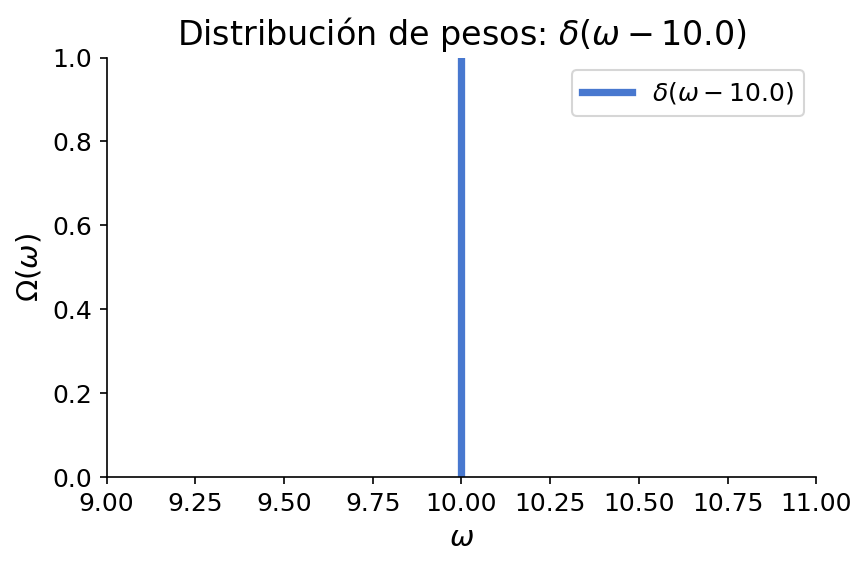

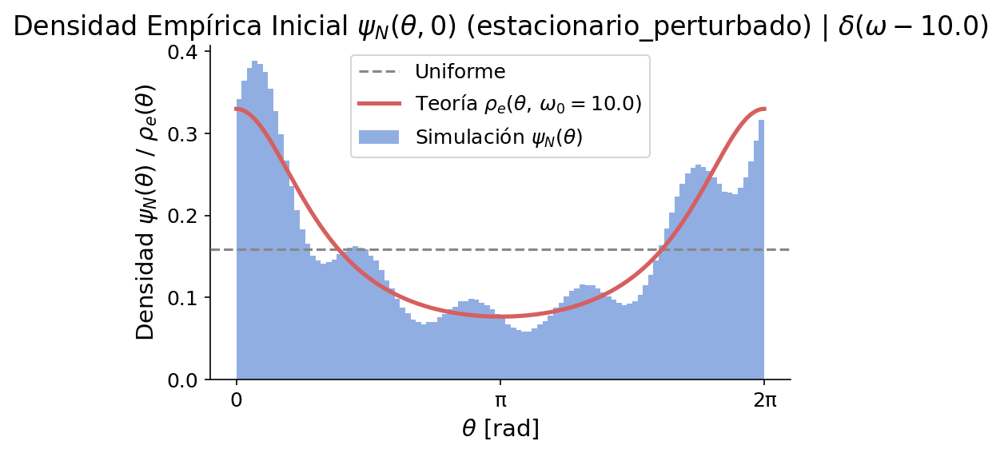

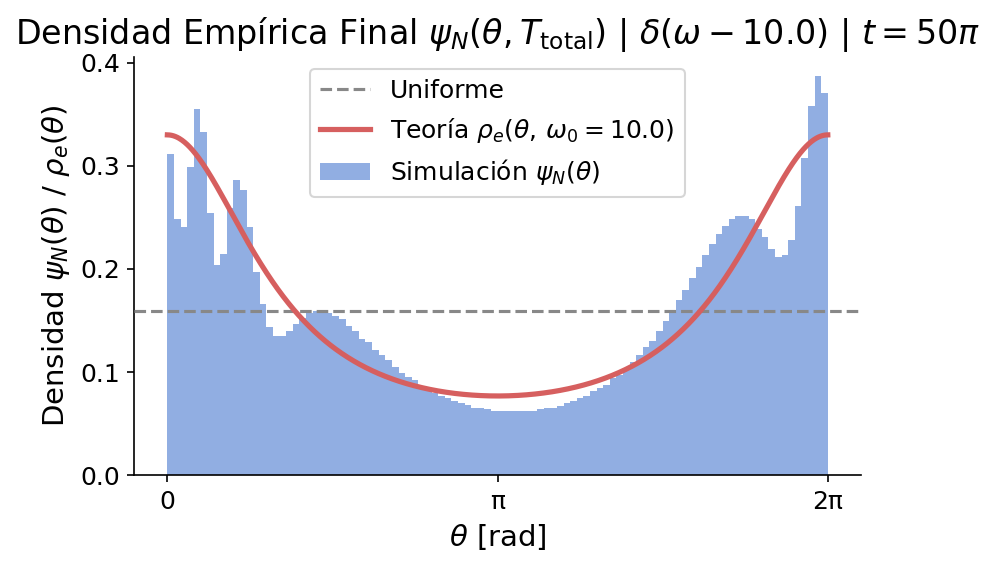

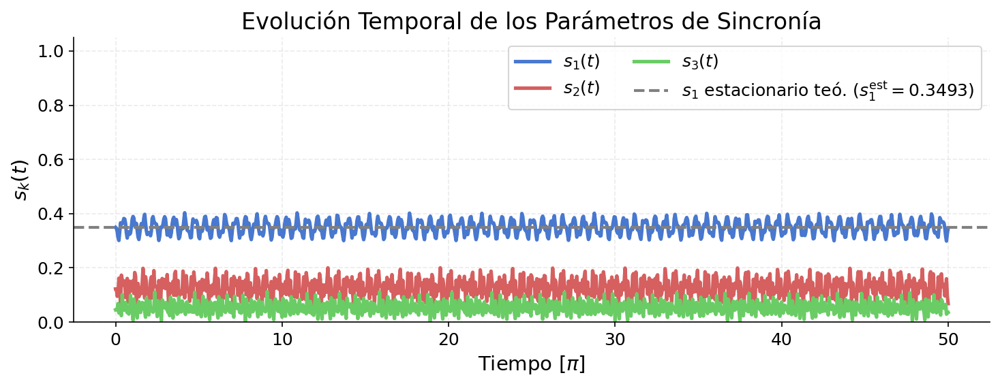

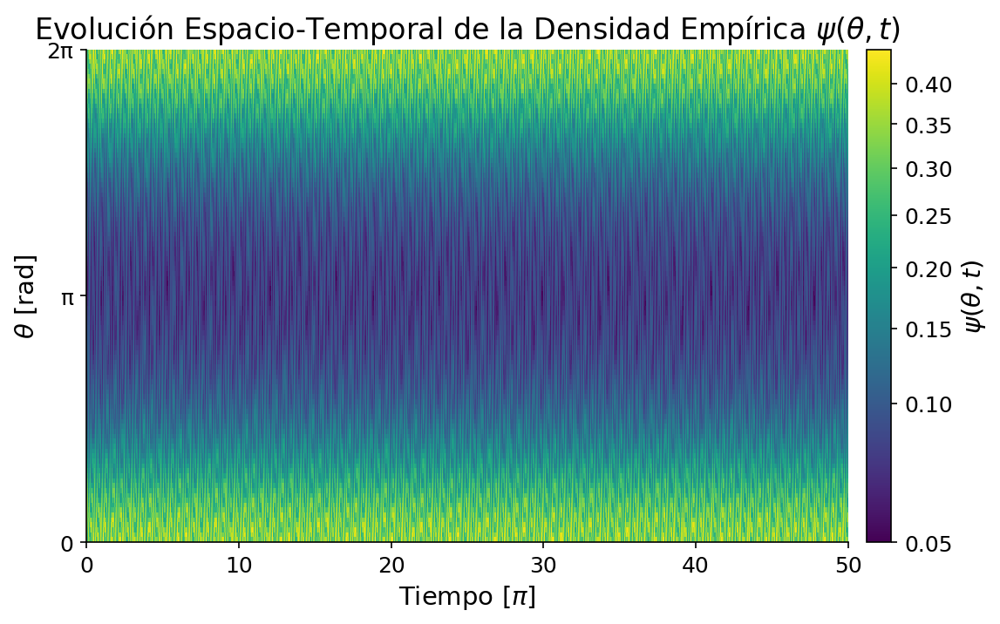


  TABLA DE CARACTERÍSTICAS Y OBSERVABLES PRINCIPALES DE LA SIMULACIÓN


,Característica / Observable,Valor Simulado / Teórico,Descripción Física
0,Modelo Neuronal,QIF,Arquitectura local de fase y PRC
1,Acoplamiento Medio (μ = ω₀),10.0,Parámetro central de la distribución Ω(ω)
2,Distribución de Pesos Ω(ω),Delta,$\delta(\omega - 10.0)$
3,Número de Osciladores (N),10000,Tamaño del ensamble microscópico
4,Amplitud de Corriente (I₀),1.0,Factor de modulación de la PRC
5,Tiempo Total (T_total),50.0π (157.08),Ventana de integración temporal
6,Paso de Muestreo (Δt = T_hist),0.050π (0.157),Intervalo entre snapshots de ψ_N
7,Sincronía Estacionaria Teórica (s₁ᵉˢᵗ),0.3493,"Punto fijo de campo medio, calculado con ρ_e"
8,Sincronía Media Asintótica ⟨s₁⟩,0.3495 ± 0.0251,Media temporal y fluctuación empírica (ψ_N)
9,"Sincronía Final (s₁, s₂, s₃)","(0.3455, 0.0681, 0.0355)",Valores instantáneos al corte t = T_total



  PICOS ESPECTRALES DE P(ν)  (ν = 2πf, T = 2π/ν)


,Pico,ν / π,ν,T / π,T = 2π/ν,P(ν),P / P_dom,Dominante
0,1,1.030294,3.236763,0.617901,1.941194,0.000111,1.000000,Sí
1,2,2.632973,8.271728,0.241787,0.759598,0.000026,0.234425,
2,3,3.955819,12.427572,0.160932,0.505584,0.000005,0.044687,
3,4,5.278665,16.583417,0.120602,0.378884,0.000001,0.011741,


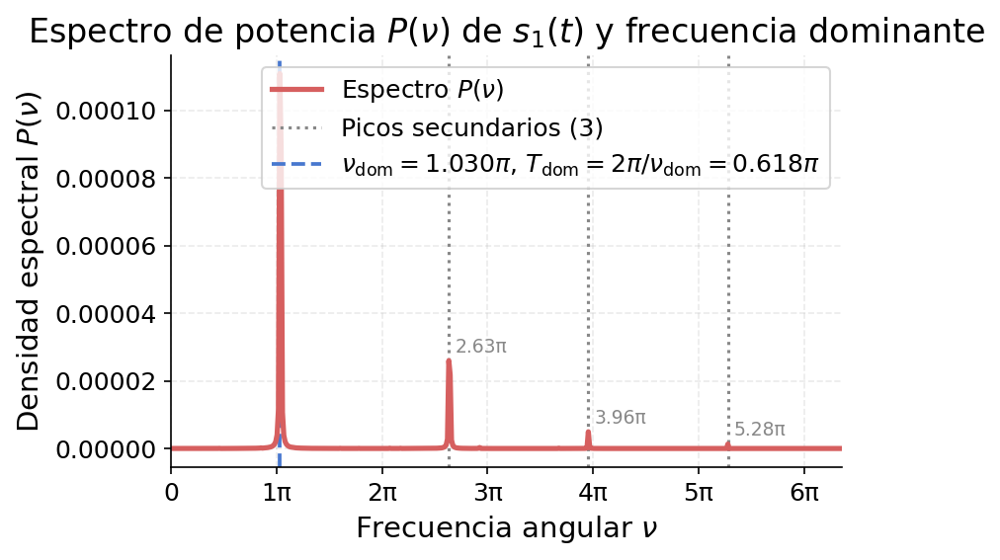

In [59]:
#  CELDA 8 | Parámetros, ejecución y análisis post-simulación (Tabla + FFT)

# 1. Configuración de parámetros físicos y numéricos
N            = 10000           # Número total de osciladores de fase en la red
I0           = 1.0            # Amplitud de corriente / modulación de la PRC
T_total      = 50 * np.pi     # Tiempo total de integración
T_hist       = np.pi / 20     # Intervalo de muestreo entre snapshots (Δt)
n_bins       = 100            # Resolución del histograma angular de fases

# Condición inicial de fases mediante inversión determinista de la acumulada:
#   'equiespaciado'           -> cuantiles uniformes centrados φᵢ = 2π(i - 0.5)/N (sₖ = 0 por simetría)
#   'uniforme'                -> muestra aleatoria estocástica U[0, 2π)
#   'sinusoidal'              -> ρ(φ) ∝ 1 + ε sin(k φ) (determinista por acumulada)
#   'estacionario'            -> ρ(φ) = ρ_est(φ) del modelo (determinista por acumulada)
#   'estacionario_perturbado' -> ρ(φ) ∝ ρ_est(φ) · [1 + ε sin(k φ)] (determinista por acumulada)
cond_inicial = 'estacionario_perturbado'
k_init       = 5              # Armónico k (para condición sinusoidal o perturbada)
eps_init     = 0.25            # Amplitud ε ∈ [0, 1] (para condición sinusoidal o perturbada)

# 2. Selección del modelo neuronal (descomentar la opción deseada)

# Opción A: Modelo QIF (Quadratic Integrate-and-Fire / Neurona Theta)
Z_modelo      = Z_QIF
T_modelo      = np.pi          # Período libre base T = π  →  v = 2π / T = 2
rho_e_modelo  = rho_e_QIF
nombre_modelo = 'QIF'

# Opción B: Modelo Tent (Triangular Simétrico, _TENT_FRAC = 0.5)
#Z_modelo      = Z_tent
#T_modelo      = np.pi
#rho_e_modelo  = rho_e_tent
#nombre_modelo = 'Tent'

# Opción C: Modelo Lineal (descomentar para activar)
# Z_modelo      = Z_lineal
# T_modelo      = np.pi
# rho_e_modelo  = rho_e_lineal
# nombre_modelo = 'Lineal'


# 3. Configuración de la distribución de pesos sinápticos Ω(ω) con desorden recocido
# Caso A: Conectividad determinista homogénea (distribución Delta)
sampler, omega_info = make_omega_dist('delta', mu=10.0)

# Caso B: Fluctuaciones estocásticas heterogéneas (distribución Uniforme)
# sampler, omega_info = make_omega_dist('uniforme', mu=0.5, Delta=0.4)

# Visualización previa de la distribución seleccionada
plot_omega_dist(omega_info)


# 4. Lanzamiento de la simulación event-driven (genera el gráfico único de sincronía sₖ(t) con s₁ᵉˢᵗ)
phis_f, tiempos, s_dict, histogramas = simular_QIF(
    N            = N,
    sampler      = sampler,
    omega_info   = omega_info,
    Z_fn         = Z_modelo,
    T            = T_modelo,
    rho_e_fn     = rho_e_modelo,
    I0           = I0,
    T_total      = T_total,
    T_hist       = T_hist,
    n_bins       = n_bins,
    cond_inicial = cond_inicial,
    k_init       = k_init,
    eps_init     = eps_init,
    mu_w_ref   = omega_info['mu'],
    guardar_figs = True,
)


# ==============================================================================
# ANÁLISIS POST-SIMULACIÓN: TABLA DE OBSERVABLES Y ESPECTRO FFT
# ==============================================================================

# 5. Cálculo del parámetro de orden de Kuramoto teórico en el estado estacionario (s₁ᵉˢᵗ)
s1_est = calcular_s1_estacionario(rho_e_modelo, omega_info['mu'], I0)

# 6. Espectro P(ν) de s₁(t) en frecuencia angular ν = 2πf y detección de picos
s_1_serie = s_dict[1]
# Devuelve también df_picos: tabla de todos los picos prominentes de P(ν)
T_dom, nu_dom, nus, psd, df_picos = calcular_periodo_fft(tiempos, s_1_serie)

# 7. Construcción y despliegue de la tabla con las características y observables principales
df_observables = generar_tabla_observables(
    modelo_nombre = nombre_modelo,
    omega_info    = omega_info,
    N             = N,
    I0            = I0,
    T_total       = T_total,
    T_hist        = T_hist,
    s_dict        = s_dict,
    s1_est        = s1_est,
    nu_dom        = nu_dom,
    T_dom         = T_dom,
    df_picos      = df_picos,
)

print(f"\n{'='*70}\n  TABLA DE CARACTERÍSTICAS Y OBSERVABLES PRINCIPALES DE LA SIMULACIÓN\n{'='*70}")
display(df_observables)

# 8. Tabla de picos y gráfico del espectro P(ν) con eje en múltiplos de π
print(f"\n{'='*70}\n  PICOS ESPECTRALES DE P(ν)  (ν = 2πf, T = 2π/ν)\n{'='*70}")
display(df_picos)

plot_espectro_fft(
    nus, psd, nu_dom, T_dom,
    df_picos = df_picos,      # Líneas punteadas en cada pico; ν_dom en otro color
    nu_max   = None,          # None → hasta Nyquist π/Δt; p. ej. 6*np.pi para hacer zoom
    fname    = 'espectro_fft.png'
)


### Celda 8.1 | Barrido en la Amplitud de Perturbación Inicial $\varepsilon$: Respuesta Espectral $P(\nu)$

1. **¿Qué hace esta celda?**  
   Estudia cómo cambian los picos del espectro de potencia $P(\nu)$ de $s_1(t)$, calculado sobre la densidad empírica $\psi_N(\phi,t)$ de la red de $N$ osciladores, cuando la condición inicial se acerca al estado estacionario teórico de campo medio $\rho_{est}$. Usa la condición inicial
   $$\psi_N(\phi, 0) \;\approx\; \rho(\phi) \propto \rho_{est}(\phi)\,[1 + \varepsilon \sin(k\phi)]$$
   y recorre $\varepsilon \in \{0.5,\, 0.25,\, 0.10,\, 0.05,\, 0.01\}$. Las fases se generan con el método determinista de inversión de la acumulada.
   Todos los demás parámetros quedan fijos: QIF con $Z_{QIF}$, $\Omega(\omega) = \delta(\omega - \mu_\omega)$ con $\mu_\omega = 10$, $N = 5000$, $k = 5$ y los mismos $T_{total}$ y $\Delta t$ que la Celda 8.

2. **¿Cómo lo hace?**  
   - `correr_simulacion_espectral` ejecuta `simular_QIF` sin figuras de diagnóstico y luego `calcular_periodo_fft`. Devuelve el espectro, la tabla de picos, $\nu_{dom}$ y $T_{dom} = 2\pi/\nu_{dom}$.
   - En cada $\varepsilon$ se muestran la tabla de picos (con $\nu/\pi$ y $T/\pi$) y la figura de $P(\nu)$ con el eje en múltiplos de $\pi$.
   - Al final se muestran todos los espectros superpuestos en escala logarítmica y una tabla resumen con $\nu_{dom}$, $T_{dom}$ y la lista de picos de cada $\varepsilon$. Ambas permiten seguir cómo se apagan o desplazan los picos cuando $\varepsilon \to 0$.

3. **¿Qué devuelve o cuál es su resultado/salida?**  
   El diccionario `resultados_eps` = {ε: resultados}, el DataFrame `tabla_barrido_eps` y las figuras.

> Tiempo estimado: ~1 min por simulación con $N = 5000$ y $T_{total} = 50\pi$ (depende del equipo).



  QIF + Delta | μ = 10.0 | N = 5000 | k = 5 | ε = 0.5
ν_dom = 1.0303π | T_dom = 2π/ν_dom = 0.6179π | picos detectados = 5


,Pico,ν / π,ν,T / π,T = 2π/ν,P(ν),P / P_dom,Dominante
0,1,1.030294,3.236763,0.617901,1.941194,0.000486,1.000000,Sí
1,2,2.632973,8.271728,0.241787,0.759598,0.000212,0.437160,
2,3,3.955819,12.427572,0.160932,0.505584,0.000013,0.027791,
3,4,2.912806,9.150849,0.218559,0.686623,0.000006,0.012413,
4,5,5.265946,16.543457,0.120894,0.379799,0.000005,0.010589,


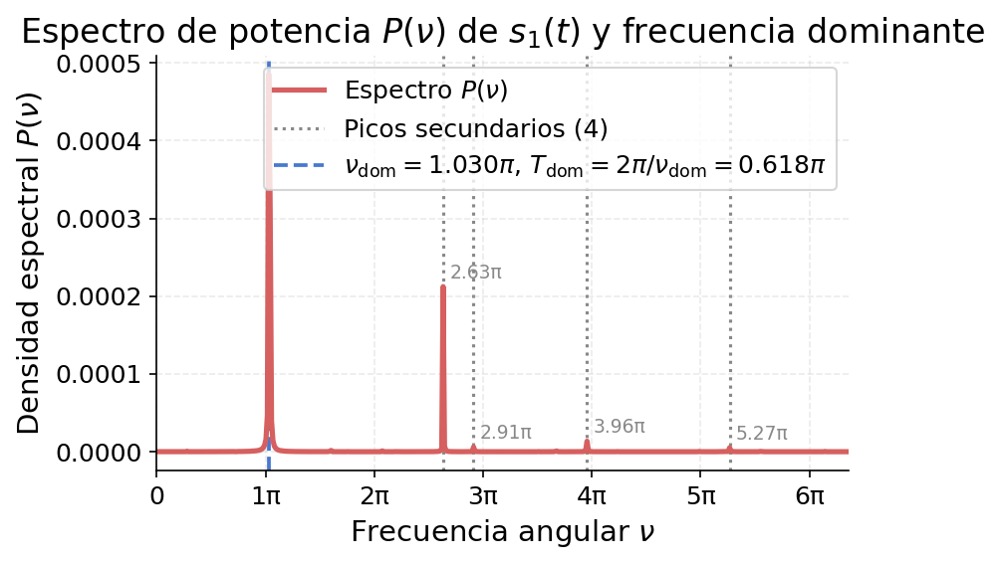


  QIF + Delta | μ = 10.0 | N = 5000 | k = 5 | ε = 0.25
ν_dom = 1.0303π | T_dom = 2π/ν_dom = 0.6179π | picos detectados = 4


,Pico,ν / π,ν,T / π,T = 2π/ν,P(ν),P / P_dom,Dominante
0,1,1.030294,3.236763,0.617901,1.941194,0.000113,1.000000,Sí
1,2,2.632973,8.271728,0.241787,0.759598,0.000026,0.227697,
2,3,3.955819,12.427572,0.160932,0.505584,0.000005,0.044296,
3,4,5.278665,16.583417,0.120602,0.378884,0.000001,0.011444,


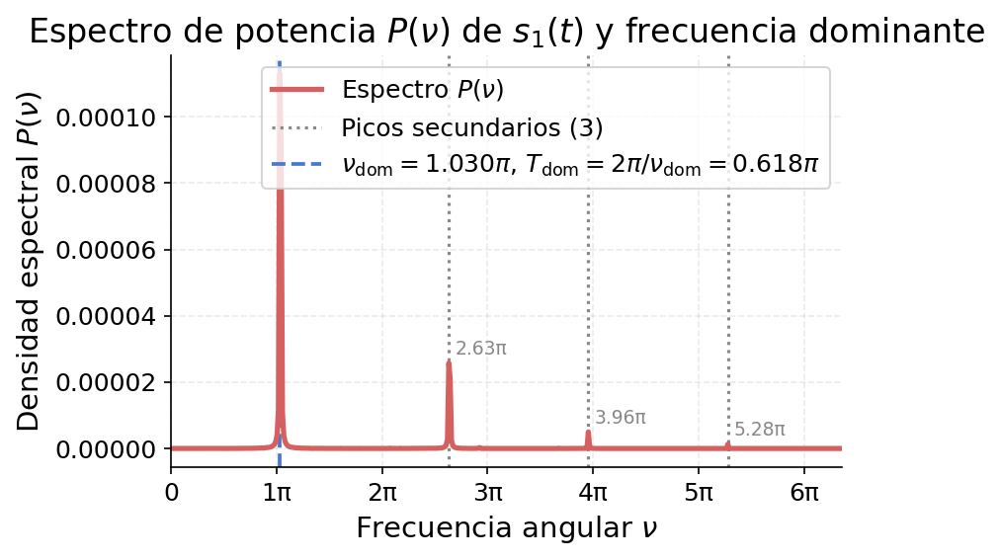


  QIF + Delta | μ = 10.0 | N = 5000 | k = 5 | ε = 0.1
ν_dom = 1.0303π | T_dom = 2π/ν_dom = 0.6179π | picos detectados = 4


,Pico,ν / π,ν,T / π,T = 2π/ν,P(ν),P / P_dom,Dominante
0,1,1.030294,3.236763,0.617901,1.941194,1.762181e-05,1.000000,Sí
1,2,2.645693,8.311688,0.240625,0.755946,4.760160e-06,0.270129,
2,3,3.955819,12.427572,0.160932,0.505584,6.656381e-07,0.037774,
3,4,5.278665,16.583417,0.120602,0.378884,1.805020e-07,0.010243,


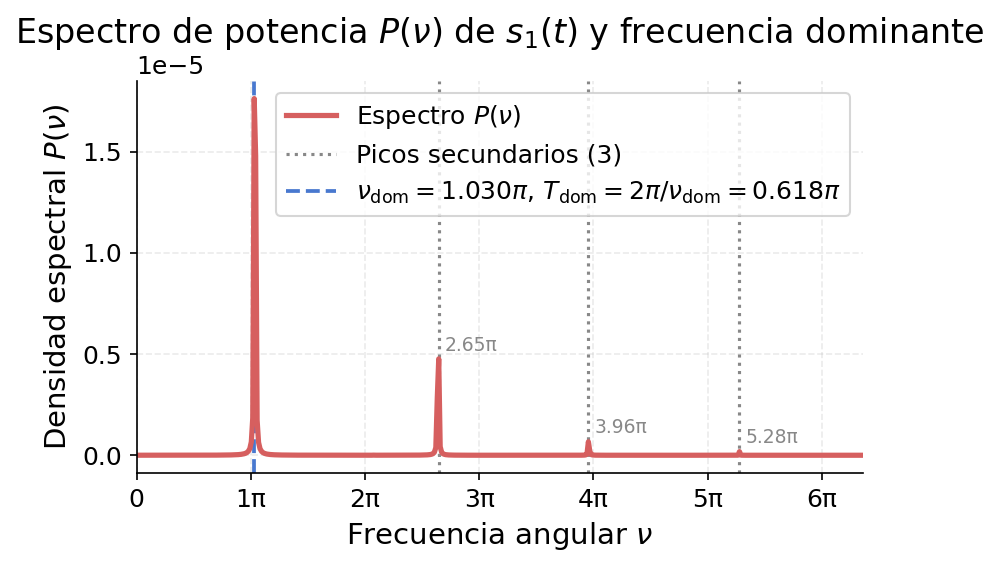


  QIF + Delta | μ = 10.0 | N = 5000 | k = 5 | ε = 0.05
ν_dom = 1.0303π | T_dom = 2π/ν_dom = 0.6179π | picos detectados = 4


,Pico,ν / π,ν,T / π,T = 2π/ν,P(ν),P / P_dom,Dominante
0,1,1.030294,3.236763,0.617901,1.941194,4.327077e-06,1.000000,Sí
1,2,2.645693,8.311688,0.240625,0.755946,1.252701e-06,0.289503,
2,3,3.955819,12.427572,0.160932,0.505584,1.599984e-07,0.036976,
3,4,5.278665,16.583417,0.120602,0.378884,4.349262e-08,0.010051,


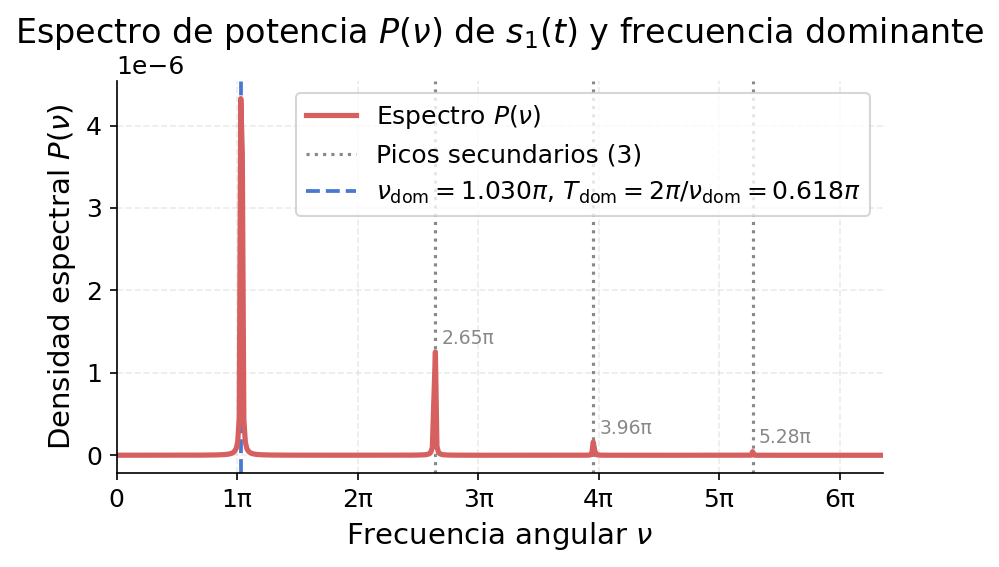


  QIF + Delta | μ = 10.0 | N = 5000 | k = 5 | ε = 0.01
ν_dom = 1.0303π | T_dom = 2π/ν_dom = 0.6179π | picos detectados = 4


,Pico,ν / π,ν,T / π,T = 2π/ν,P(ν),P / P_dom,Dominante
0,1,1.030294,3.236763,0.617901,1.941194,1.523175e-07,1.000000,Sí
1,2,2.645693,8.311688,0.240625,0.755946,5.490497e-08,0.360464,
2,3,3.955819,12.427572,0.160932,0.505584,6.240347e-09,0.040969,
3,4,5.278665,16.583417,0.120602,0.378884,1.731453e-09,0.011367,


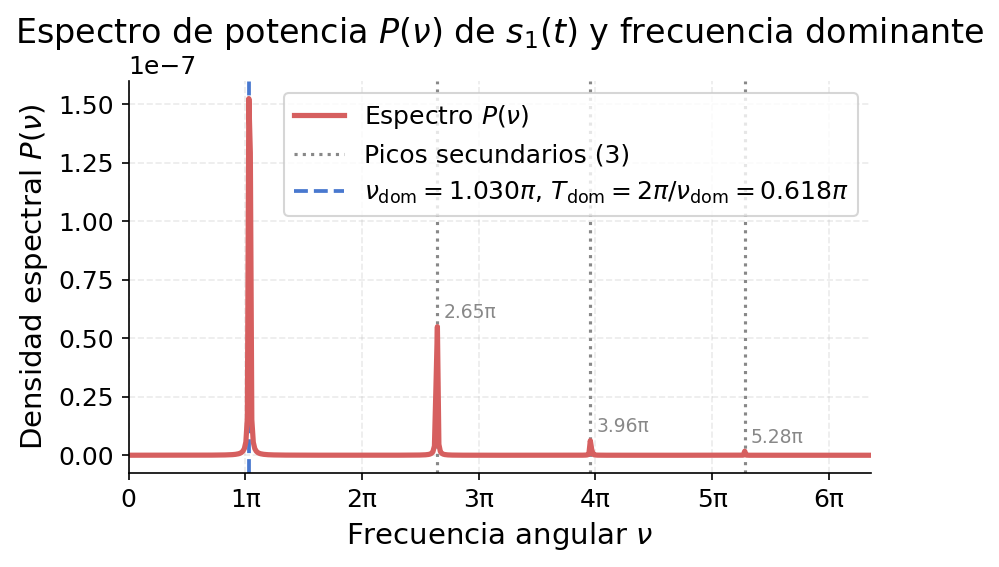

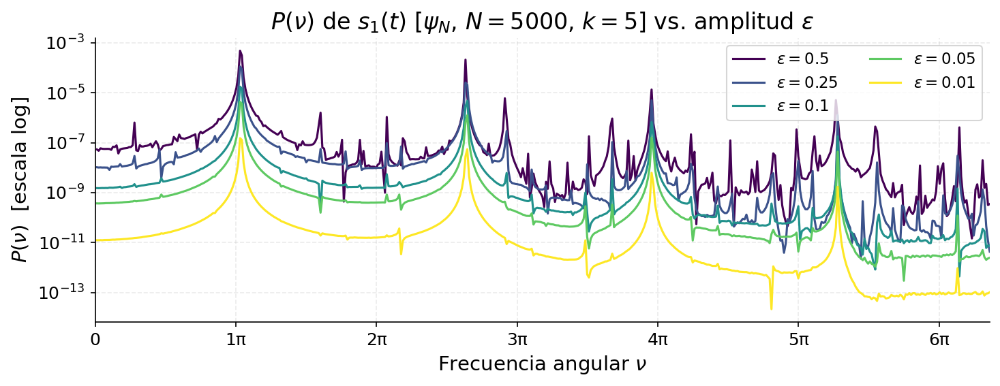


  RESUMEN DEL BARRIDO EN ε  (ν y T en múltiplos de π)


,ε,ν_dom / π,T_dom / π,N° picos,Picos ν / π
0,0.50,1.030294,0.617901,5,"1.03, 2.63, 2.91, 3.96, 5.27"
1,0.25,1.030294,0.617901,4,"1.03, 2.63, 3.96, 5.28"
2,0.10,1.030294,0.617901,4,"1.03, 2.65, 3.96, 5.28"
3,0.05,1.030294,0.617901,4,"1.03, 2.65, 3.96, 5.28"
4,0.01,1.030294,0.617901,4,"1.03, 2.65, 3.96, 5.28"


In [60]:
#  CELDA 8.1 | Barrido en la amplitud de perturbación inicial ε  (QIF + Delta, N fijo)

# ==============================================================================
# 0. Utilidades compartidas por los barridos en ε (Celda 8.1) y en N (Celda 8.2)
# ==============================================================================
def correr_simulacion_espectral(N, eps, k, sampler, omega_info, Z_fn, rho_e_fn, T, I0,
                                T_total, T_hist, n_bins,
                                cond_inicial='estacionario_perturbado',
                                t_start=None, prominencia_rel=0.005,
                                mostrar_diagnosticos=False):
    """
    Ejecuta UNA simulación de la red finita y su análisis espectral.

    La simulación produce la densidad empírica ψ_N(φ, t) y la serie s₁(t) = |∫ e^{iφ} ψ_N dφ|;
    el espectro P(ν) se calcula sobre s₁(t). La densidad teórica ρ_est sólo interviene como
    densidad objetivo de la condición inicial y como referencia s₁ᵉˢᵗ.

    Devuelve un dict con:
      tiempos, s_dict, histogramas   → series de la simulación (ψ_N)
      nus, psd, picos                → espectro P(ν) y tabla de picos (calcular_periodo_fft)
      nu_dom, T_dom                  → frecuencia angular dominante y período T_dom = 2π/ν_dom
    """
    # 1. Simulación event-driven (sin figuras de diagnóstico, salvo que se pidan)
    _, tiempos, s_dict, histogramas = simular_QIF(
        N=N, sampler=sampler, omega_info=omega_info, Z_fn=Z_fn, T=T, rho_e_fn=rho_e_fn, I0=I0,
        T_total=T_total, T_hist=T_hist, n_bins=n_bins, cond_inicial=cond_inicial,
        k_init=k, eps_init=eps, mu_w_ref=omega_info['mu'],
        guardar_figs=False, mostrar_figs=mostrar_diagnosticos,
    )

    # 2. Espectro P(ν) de s₁(t) y detección de picos (Celda 7.5)
    T_dom, nu_dom, nus, psd, df_picos = calcular_periodo_fft(
        tiempos, s_dict[1], t_start=t_start, prominencia_rel=prominencia_rel)

    return dict(
        tiempos=np.asarray(tiempos), s_dict=s_dict, histogramas=histogramas,
        nus=nus, psd=psd, picos=df_picos,
        nu_dom=nu_dom, T_dom=T_dom,
    )


def plot_espectros_superpuestos(resultados, etiqueta, titulo, nu_max=None, fname=None):
    """
    Superpone los espectros P(ν) de un barrido en escala logarítmica de potencia
    (los picos pueden variar varios órdenes de magnitud) con el eje ν en múltiplos de π.

    resultados : dict {valor_del_parámetro: dict de correr_simulacion_espectral}
    etiqueta   : función valor → texto de la leyenda (admite LaTeX)
    """
    fig, ax = plt.subplots(figsize=STYLE['figsize_wide'])
    cmap = plt.get_cmap('viridis')
    n = len(resultados)

    for j, (val, res) in enumerate(resultados.items()):
        m = (res['nus'] > 0) & (res['psd'] > 0)          # log: excluir ν = 0 y potencias nulas
        ax.plot(res['nus'][m], res['psd'][m], color=cmap(j / max(n - 1, 1)),
                lw=STYLE['lw_aux'], label=etiqueta(val))

    ax.set_yscale('log')
    x_max = nu_max if nu_max is not None else max(float(r['nus'][-1]) for r in resultados.values())
    ax.set_xlim(0, x_max)
    aplicar_ticks_pi(ax, x_max, eje='x')                  # Marcas 0, π, 2π, … (Celda 7.5)

    ax.set_xlabel(r'Frecuencia angular $\nu$ [rad/u.t.]')
    ax.set_ylabel(r'$P(\nu)$ [u.a., escala log]')
    ax.set_title(titulo)
    ax.grid(True, which='major', alpha=0.25, linestyle='--')
    ax.legend(loc='upper right', ncol=2, fontsize=STYLE['fontsize_legend'] - 1)

    plt.tight_layout()
    if fname:
        plt.savefig(fname, bbox_inches='tight')
    plt.show()


def tabla_resumen_barrido(resultados, nombre_param):
    """
    DataFrame comparativo: una fila por valor del parámetro barrido, con ν_dom, T_dom y la
    lista de todos los picos detectados (ν en múltiplos de π), para seguir cómo se mueven.
    """
    filas = []
    for val, r in resultados.items():
        picos = r['picos']
        filas.append({
            nombre_param  : val,
            'ν_dom / π [rad/u.t.]'   : r['nu_dom'] / np.pi,
            'T_dom / π [u.t.]'   : r['T_dom'] / np.pi,
            'N° picos'    : len(picos),
            'Picos ν / π' : ', '.join(f'{x:.2f}' for x in sorted(picos['ν / π'])),
        })
    return pd.DataFrame(filas)


# ==============================================================================
# 1. Parámetros fijos (configuración de la Celda 8, con N = 5000)
# ==============================================================================
N_eps        = 5000            # Tamaño de la red (fijo en este barrido)
I0           = 1.0             # Amplitud de la PRC
T_total      = 50 * np.pi      # Tiempo total de integración
T_hist       = np.pi / 20      # Δt entre snapshots → ν_Nyquist = π/Δt = 20 ≈ 6.4π
n_bins       = 100             # Bins del histograma de ψ_N
k_eps        = 5               # Armónico fijo de la perturbación (el mismo que la Celda 8)
mu_eps       = 10.0            # Acoplamiento medio μ_ω [u.v.]

Z_modelo, rho_e_modelo, T_modelo = Z_QIF, rho_e_QIF, np.pi   # QIF: v = 2π/T = 2
sampler_eps, info_eps = make_omega_dist('delta', mu=mu_eps)  # Ω(ω) = δ(ω − μ_ω)

MOSTRAR_DIAGNOSTICOS = False   # True → también ψ_N inicial/final, s_k(t) y heatmap de cada corrida

# Parámetro variable: amplitud de la perturbación (decreciente, ε → 0 ⇒ ψ_N(·,0) → ρ_est)
eps_barrido = [0.5, 0.25, 0.10, 0.05, 0.01]

# ==============================================================================
# 2. Bucle del barrido
# ==============================================================================
resultados_eps = {}
for eps in eps_barrido:
    print(f"\n{'='*70}\n  QIF + Delta | μ_ω = {mu_eps} | N = {N_eps} | k = {k_eps} | ε = {eps}\n{'='*70}")

    res = correr_simulacion_espectral(
        N=N_eps, eps=eps, k=k_eps, sampler=sampler_eps, omega_info=info_eps,
        Z_fn=Z_modelo, rho_e_fn=rho_e_modelo, T=T_modelo, I0=I0,
        T_total=T_total, T_hist=T_hist, n_bins=n_bins,
        mostrar_diagnosticos=MOSTRAR_DIAGNOSTICOS,
    )
    resultados_eps[eps] = res

    # Resumen en una línea con ν_dom y T_dom en múltiplos de π
    print(f"ν_dom = {fmt_mult_pi(res['nu_dom'], 4)} | T_dom = 2π/ν_dom = {fmt_mult_pi(res['T_dom'], 4)} | "
          f"picos detectados = {len(res['picos'])}")

    # Tabla de picos de esta iteración y espectro P(ν) individual (ν en múltiplos de π)
    display(res['picos'])
    plot_espectro_fft(res['nus'], res['psd'], res['nu_dom'], res['T_dom'],
                      df_picos=res['picos'], fname=f'espectro_eps_{eps}.png')

# ==============================================================================
# 3. Comparación entre valores de ε
# ==============================================================================
# 3a. Espectros superpuestos (escala log): permite ver qué picos se apagan o se desplazan
plot_espectros_superpuestos(
    resultados_eps, etiqueta=lambda e: rf'$\varepsilon = {e}$',
    titulo=rf'$P(\nu)$ de $s_1(t)$ [$\psi_N$, $N={N_eps}$, $k={k_eps}$] vs. amplitud $\varepsilon$',
    fname='espectros_barrido_eps.png',
)

# 3b. Tabla resumen del barrido
tabla_barrido_eps = tabla_resumen_barrido(resultados_eps, 'ε')
print(f"\n{'='*70}\n  RESUMEN DEL BARRIDO EN ε  (ν y T en múltiplos de π)\n{'='*70}")
display(tabla_barrido_eps)


### Celda 8.1.1 | Barrido en la Amplitud de Perturbación Inicial $\varepsilon$ — Modelo Tent Simétrico

1. **¿Qué hace esta celda?**  
   Repite exactamente el barrido de la Celda 8.1, pero con la PRC triangular simétrica $Z_{\rm tent}$ (`_TENT_FRAC = 0.5`, vértice en $\phi = \pi$) y su densidad estacionaria $\rho_e^{\rm tent}$ en lugar del modelo QIF. La condición inicial es $\rho(\phi) \propto \rho_{est}(\phi)\,[1 + \varepsilon \sin(k\phi)]$ con $\varepsilon \in \{0.5,\, 0.25,\, 0.10,\, 0.05,\, 0.01\}$. El resto de los parámetros queda fijo e igual al de la 8.1: $\Omega(\omega) = \delta(\omega - \mu_\omega)$ con $\mu_\omega = 10$, $N = 5000$, $k = 5$, $T_{total} = 50\pi$ y $\Delta t = \pi/20$.

2. **¿Cómo lo hace?**  
   Reutiliza las utilidades definidas en la Celda 8.1 (`correr_simulacion_espectral`, `plot_espectros_superpuestos` y `tabla_resumen_barrido`), así que **la Celda 8.1 debe ejecutarse antes**. Los resultados se guardan en variables con sufijo `_tent` y las figuras en archivos `espectro_eps_tent_*.png`, para no sobrescribir los resultados del QIF.

3. **¿Qué devuelve o cuál es su resultado/salida?**  
   El diccionario `resultados_eps_tent` = {ε: resultados}, el DataFrame `tabla_barrido_eps_tent`, la tabla de picos y el espectro $P(\nu)$ de cada $\varepsilon$, y la figura con todos los espectros superpuestos.

> Los picos $\nu_{dom}$ se pueden contrastar con las frecuencias $\nu_n$ de las soluciones puramente imaginarias de la ecuación trascendental para el modelo tent (notebook `SolucionesEcTrascendentalEstabilidadEstacionario.ipynb`). Para $\mu_\omega = 10$, el modo fundamental es $\nu_1 \approx 3.842$ rad/u.t. ($\approx 1.22\pi$).

In [ ]:
#  CELDA 8.1.1 | Barrido en la amplitud de perturbación inicial ε  (Tent simétrico + Delta, N fijo)
#  Requiere haber ejecutado la Celda 8.1 (define correr_simulacion_espectral, plot_espectros_superpuestos
#  y tabla_resumen_barrido) y la Celda 1 con _TENT_FRAC = 0.5 (Z_tent simétrica).

# ==============================================================================
# 1. Parámetros fijos (idénticos a la Celda 8.1, salvo el modelo de PRC)
# ==============================================================================
N_eps_tent   = 5000            # Tamaño de la red (fijo en este barrido)
I0           = 1.0             # Amplitud de la PRC
T_total      = 50 * np.pi      # Tiempo total de integración
T_hist       = np.pi / 20      # Δt entre snapshots → ν_Nyquist = π/Δt = 20 ≈ 6.4π
n_bins       = 100             # Bins del histograma de ψ_N
k_eps_tent   = 5               # Armónico fijo de la perturbación (el mismo que la Celda 8.1)
mu_eps_tent  = 10.0            # Acoplamiento medio μ_ω [u.v.] (el mismo que la Celda 8.1)

# Control: la PRC tent debe ser simétrica (vértice en π) para comparar con la ecuación trascendental
assert np.isclose(_TENT_FRAC, 0.5), "Z_tent no es simétrica: fijar _TENT_FRAC = 0.5 en la Celda 1 y re-ejecutarla."

Z_modelo_tent, rho_e_modelo_tent, T_modelo_tent = Z_tent, rho_e_tent, np.pi   # Tent: v = 2π/T = 2
sampler_eps_tent, info_eps_tent = make_omega_dist('delta', mu=mu_eps_tent)    # Ω(ω) = δ(ω − μ_ω)

MOSTRAR_DIAGNOSTICOS = False   # True → también ψ_N inicial/final, s_k(t) y heatmap de cada corrida

# Parámetro variable: amplitud de la perturbación (decreciente, ε → 0 ⇒ ψ_N(·,0) → ρ_est)
eps_barrido_tent = [0.5, 0.25, 0.10, 0.05, 0.01]

# ==============================================================================
# 2. Bucle del barrido
# ==============================================================================
resultados_eps_tent = {}                                   # Contenedor {ε: resultados} propio del modelo tent
for eps in eps_barrido_tent:
    print(f"\n{'='*70}\n  Tent + Delta | μ_ω = {mu_eps_tent} | N = {N_eps_tent} | k = {k_eps_tent} | ε = {eps}\n{'='*70}")

    # Simulación event-driven + espectro P(ν) de s₁(t) (utilidad de la Celda 8.1)
    res = correr_simulacion_espectral(
        N=N_eps_tent, eps=eps, k=k_eps_tent, sampler=sampler_eps_tent, omega_info=info_eps_tent,
        Z_fn=Z_modelo_tent, rho_e_fn=rho_e_modelo_tent, T=T_modelo_tent, I0=I0,
        T_total=T_total, T_hist=T_hist, n_bins=n_bins,
        mostrar_diagnosticos=MOSTRAR_DIAGNOSTICOS,
    )
    resultados_eps_tent[eps] = res                         # Se guarda el resultado de esta amplitud

    # Resumen en una línea con ν_dom y T_dom en múltiplos de π
    print(f"ν_dom = {fmt_mult_pi(res['nu_dom'], 4)} | T_dom = 2π/ν_dom = {fmt_mult_pi(res['T_dom'], 4)} | "
          f"picos detectados = {len(res['picos'])}")

    # Tabla de picos de esta iteración y espectro P(ν) individual (ν en múltiplos de π)
    display(res['picos'])
    plot_espectro_fft(res['nus'], res['psd'], res['nu_dom'], res['T_dom'],
                      df_picos=res['picos'], fname=f'espectro_eps_tent_{eps}.png')

# ==============================================================================
# 3. Comparación entre valores de ε
# ==============================================================================
# 3a. Espectros superpuestos (escala log): permite ver qué picos se apagan o se desplazan
plot_espectros_superpuestos(
    resultados_eps_tent, etiqueta=lambda e: rf'$\varepsilon = {e}$',
    titulo=rf'Tent: $P(\nu)$ de $s_1(t)$ [$\psi_N$, $N={N_eps_tent}$, $k={k_eps_tent}$] vs. amplitud $\varepsilon$',
    fname='espectros_barrido_eps_tent.png',
)

# 3b. Tabla resumen del barrido
tabla_barrido_eps_tent = tabla_resumen_barrido(resultados_eps_tent, 'ε')
print(f"\n{'='*70}\n  RESUMEN DEL BARRIDO EN ε — MODELO TENT  (ν y T en múltiplos de π)\n{'='*70}")
display(tabla_barrido_eps_tent)

### Celda 8.2 | Barrido en el Tamaño de la Red $N$: Efectos de Tamaño Finito sobre $P(\nu)$

1. **¿Qué hace esta celda?**  
   Evalúa cómo el tamaño finito de la red modifica la respuesta espectral. Recorre $N \in \{5000,\, 2000,\, 1000,\, 500,\, 250,\, 50\}$ y deja fijos los demás parámetros: QIF, $\Omega(\omega) = \delta(\omega - \mu_\omega)$ con $\mu_\omega = 10$, condición inicial `'estacionario_perturbado'` con $k = 5$ y $\varepsilon = 0.25$, y los mismos $T_{total}$ y $\Delta t$.
   La densidad empírica $\psi_N(\phi,t) = \frac{1}{N}\sum_i \delta(\phi - \phi_i(t))$ se aparta de la densidad de campo medio $\rho$ en fluctuaciones de orden $\mathcal{O}(1/N)$, que pueden ensanchar los picos, agregar ruido al espectro o cambiar la visibilidad de $\nu_{dom}$.

2. **¿Cómo lo hace?**  
   - Para cada $N$ llama a `correr_simulacion_espectral` (definida en la Celda 8.1) y muestra la tabla de picos y la figura de $P(\nu)$ con el eje en múltiplos de $\pi$.
   - Al final se muestran los espectros superpuestos en escala log y una tabla resumen con $\nu_{dom}$, $T_{dom}$ y la lista de picos de cada $N$.

3. **¿Qué devuelve o cuál es su resultado/salida?**  
   El diccionario `resultados_N` = {N: resultados}, el DataFrame `tabla_barrido_N` y las figuras.

> Requiere haber ejecutado antes la Celda 8.1.



  QIF + Delta | μ = 10.0 | k = 5 | ε = 0.25 | N = 5000
ν_dom = 1.0303π | T_dom = 2π/ν_dom = 0.6179π | picos detectados = 4


,Pico,ν / π,ν,T / π,T = 2π/ν,P(ν),P / P_dom,Dominante
0,1,1.030294,3.236763,0.617901,1.941194,0.000113,1.000000,Sí
1,2,2.632973,8.271728,0.241787,0.759598,0.000026,0.227697,
2,3,3.955819,12.427572,0.160932,0.505584,0.000005,0.044296,
3,4,5.278665,16.583417,0.120602,0.378884,0.000001,0.011444,


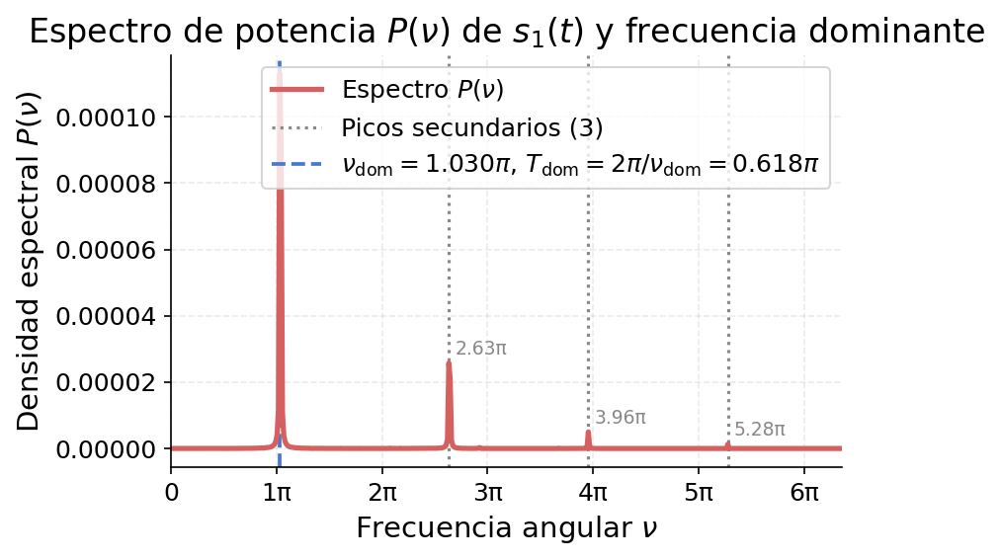


  QIF + Delta | μ = 10.0 | k = 5 | ε = 0.25 | N = 2000
ν_dom = 1.0303π | T_dom = 2π/ν_dom = 0.6179π | picos detectados = 4


,Pico,ν / π,ν,T / π,T = 2π/ν,P(ν),P / P_dom,Dominante
0,1,1.030294,3.236763,0.617901,1.941194,0.000120,1.000000,Sí
1,2,2.632973,8.271728,0.241787,0.759598,0.000025,0.208764,
2,3,3.955819,12.427572,0.160932,0.505584,0.000005,0.043163,
3,4,5.278665,16.583417,0.120602,0.378884,0.000001,0.010566,


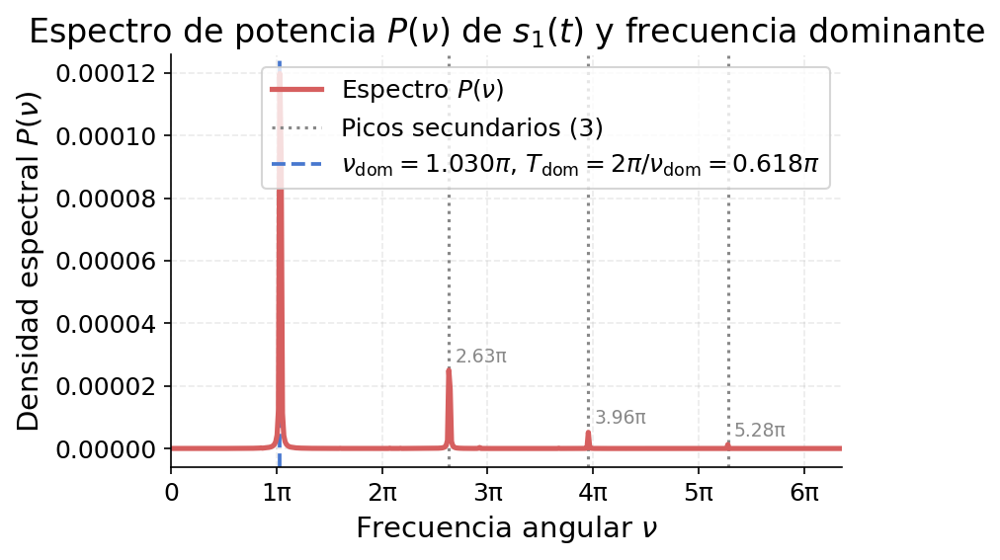


  QIF + Delta | μ = 10.0 | k = 5 | ε = 0.25 | N = 1000
ν_dom = 1.0303π | T_dom = 2π/ν_dom = 0.6179π | picos detectados = 4


,Pico,ν / π,ν,T / π,T = 2π/ν,P(ν),P / P_dom,Dominante
0,1,1.030294,3.236763,0.617901,1.941194,0.000132,1.000000,Sí
1,2,2.632973,8.271728,0.241787,0.759598,0.000024,0.180797,
2,3,3.955819,12.427572,0.160932,0.505584,0.000005,0.041149,
3,4,5.278665,16.583417,0.120602,0.378884,0.000001,0.009198,


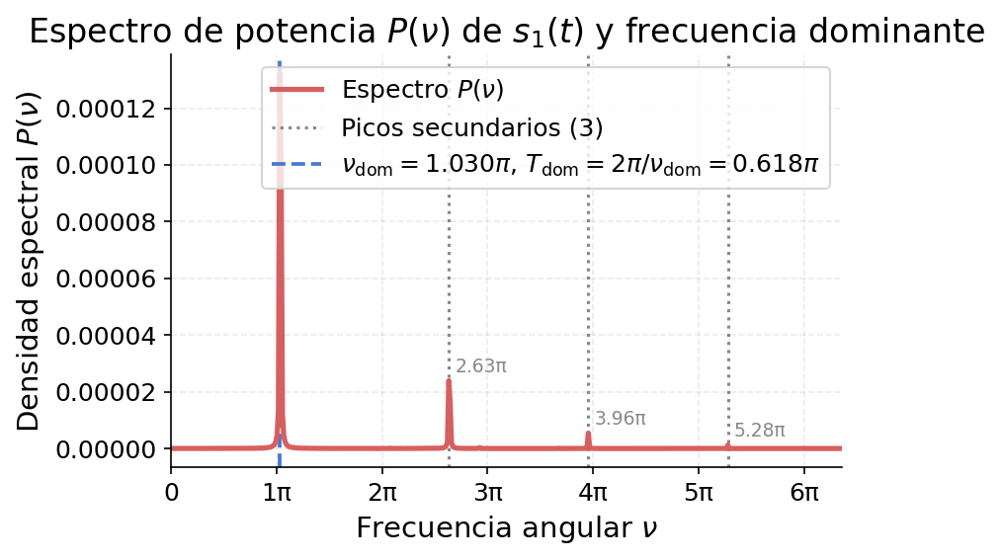


  QIF + Delta | μ = 10.0 | k = 5 | ε = 0.25 | N = 500
ν_dom = 1.0303π | T_dom = 2π/ν_dom = 0.6179π | picos detectados = 4


,Pico,ν / π,ν,T / π,T = 2π/ν,P(ν),P / P_dom,Dominante
0,1,1.030294,3.236763,0.617901,1.941194,0.000163,1.000000,Sí
1,2,2.632973,8.271728,0.241787,0.759598,0.000022,0.135711,
2,3,3.955819,12.427572,0.160932,0.505584,0.000006,0.036643,
3,4,5.278665,16.583417,0.120602,0.378884,0.000001,0.006715,


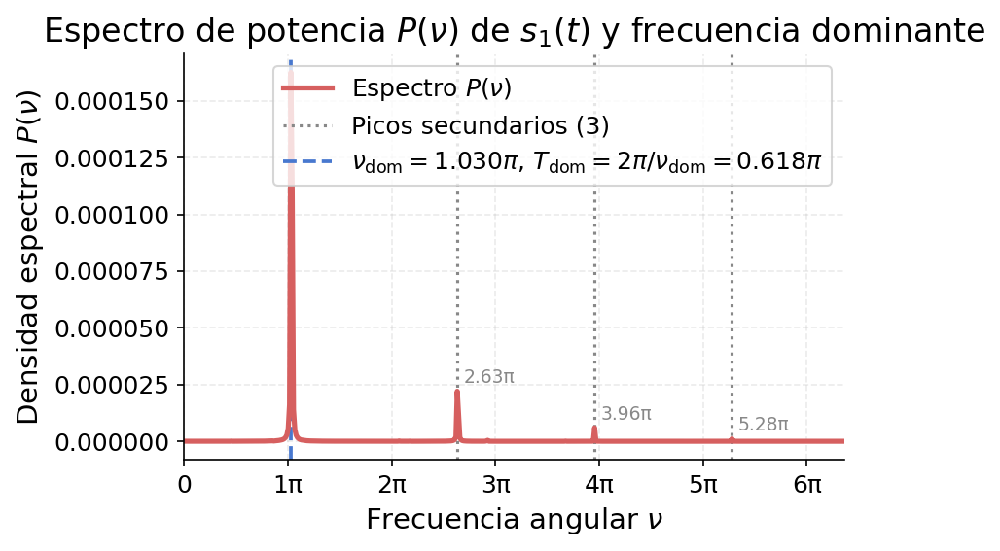


  QIF + Delta | μ = 10.0 | k = 5 | ε = 0.25 | N = 250
ν_dom = 1.0303π | T_dom = 2π/ν_dom = 0.6179π | picos detectados = 3


,Pico,ν / π,ν,T / π,T = 2π/ν,P(ν),P / P_dom,Dominante
0,1,1.030294,3.236763,0.617901,1.941194,0.000254,1.000000,Sí
1,2,2.632973,8.271728,0.241787,0.759598,0.000019,0.075999,
2,3,3.955819,12.427572,0.160932,0.505584,0.000007,0.025913,


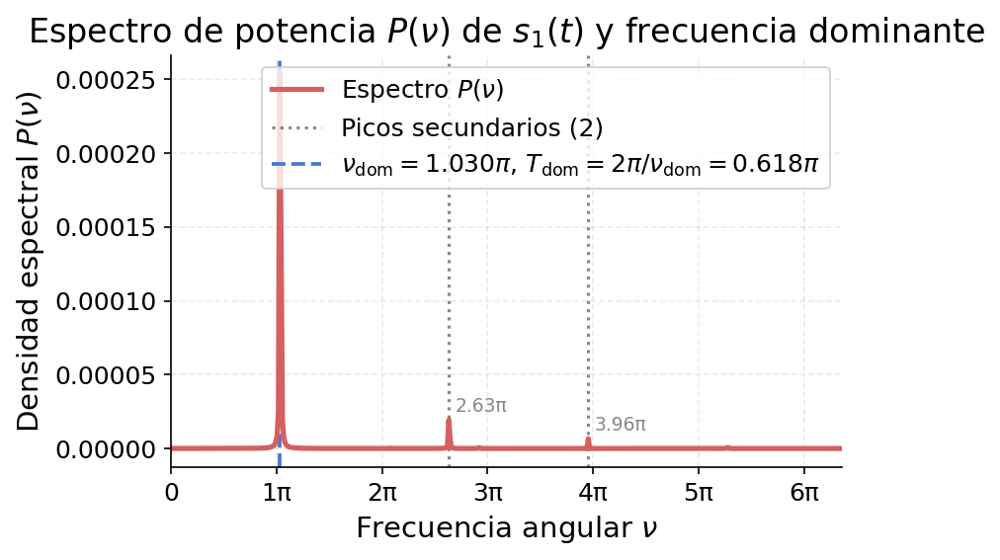


  QIF + Delta | μ = 10.0 | k = 5 | ε = 0.25 | N = 50
ν_dom = 1.0049π | T_dom = 2π/ν_dom = 0.6335π | picos detectados = 8


,Pico,ν / π,ν,T / π,T = 2π/ν,P(ν),P / P_dom,Dominante
0,1,1.004854,3.156843,0.633544,1.990338,0.000729,1.000000,Sí
1,2,1.030294,3.236763,0.617901,1.941194,0.000700,0.960163,
2,3,0.941256,2.957043,0.676351,2.124820,0.000455,0.623560,
3,4,1.996989,6.273726,0.318790,1.001508,0.000006,0.008535,
4,5,2.645693,8.311688,0.240625,0.755946,0.000006,0.008410,
5,6,0.750461,2.357642,0.848305,2.665029,0.000005,0.007502,
6,7,2.722011,8.551449,0.233879,0.734751,0.000004,0.005778,
7,8,0.699582,2.197802,0.910000,2.858849,0.000004,0.005629,


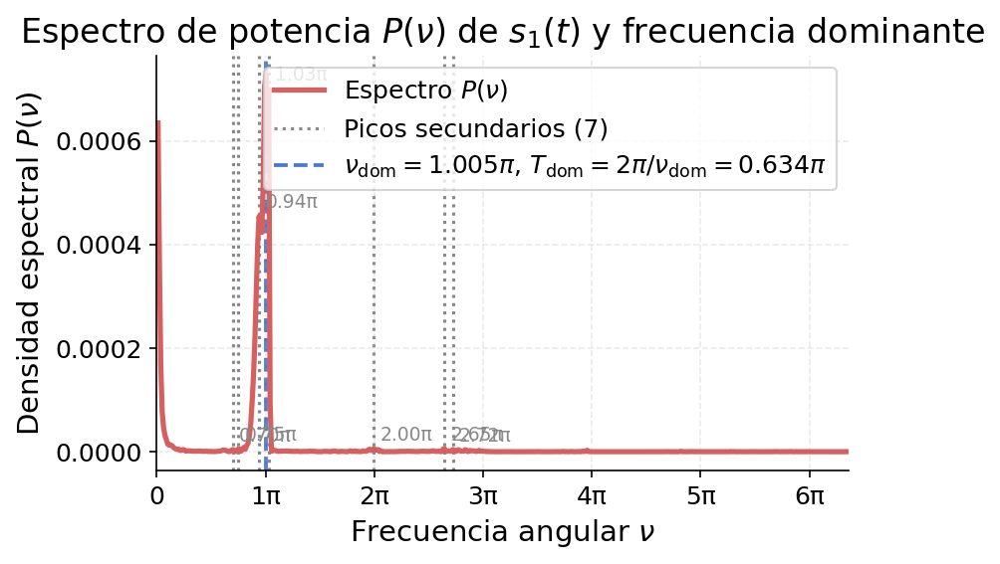

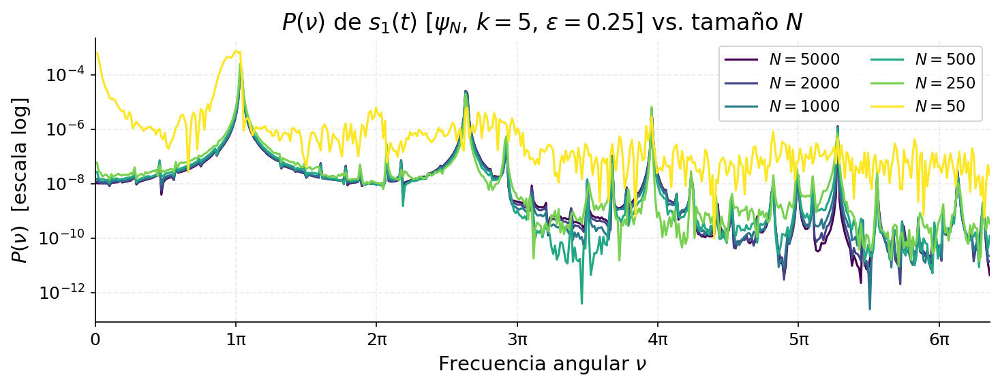


  RESUMEN DEL BARRIDO EN N  (ν y T en múltiplos de π)


,N,ν_dom / π,T_dom / π,N° picos,Picos ν / π
0,5000,1.030294,0.617901,4,"1.03, 2.63, 3.96, 5.28"
1,2000,1.030294,0.617901,4,"1.03, 2.63, 3.96, 5.28"
2,1000,1.030294,0.617901,4,"1.03, 2.63, 3.96, 5.28"
3,500,1.030294,0.617901,4,"1.03, 2.63, 3.96, 5.28"
4,250,1.030294,0.617901,3,"1.03, 2.63, 3.96"
5,50,1.004854,0.633544,8,"0.70, 0.75, 0.94, 1.00, 1.03, 2.00, 2.65, 2.72"


In [61]:
#  CELDA 8.2 | Barrido en el tamaño de la red N  (efectos de tamaño finito sobre P(ν))
#  Requiere haber ejecutado la Celda 8.1 (correr_simulacion_espectral, plot_espectros_superpuestos,
#  tabla_resumen_barrido).

# ==============================================================================
# 1. Parámetros fijos (configuración de la Celda 8)
# ==============================================================================
I0           = 1.0
T_total      = 50 * np.pi      # Tiempo total de integración
T_hist       = np.pi / 20      # Δt entre snapshots → ν_Nyquist = π/Δt
n_bins       = 100
k_N          = 5               # Armónico de la perturbación inicial
eps_N        = 0.25            # Amplitud representativa de la perturbación
mu_N         = 10.0            # Acoplamiento medio μ_ω

Z_modelo, rho_e_modelo, T_modelo = Z_QIF, rho_e_QIF, np.pi   # QIF: v = 2π/T = 2
sampler_N, info_N = make_omega_dist('delta', mu=mu_N)        # Ω(ω) = δ(ω − μ_ω), como en la Celda 8

MOSTRAR_DIAGNOSTICOS = False   # True → también ψ_N inicial/final, s_k(t) y heatmap de cada corrida

# Parámetro variable: tamaño de la red (decreciente → fluctuaciones O(1/N) crecientes en ψ_N)
N_barrido = [5000, 2000, 1000, 500, 250, 50]

# ==============================================================================
# 2. Bucle del barrido
# ==============================================================================
resultados_N = {}
for N_i in N_barrido:
    print(f"\n{'='*70}\n  QIF + Delta | μ_ω = {mu_N} | k = {k_N} | ε = {eps_N} | N = {N_i}\n{'='*70}")

    res = correr_simulacion_espectral(
        N=N_i, eps=eps_N, k=k_N, sampler=sampler_N, omega_info=info_N,
        Z_fn=Z_modelo, rho_e_fn=rho_e_modelo, T=T_modelo, I0=I0,
        T_total=T_total, T_hist=T_hist, n_bins=n_bins,
        mostrar_diagnosticos=MOSTRAR_DIAGNOSTICOS,
    )
    resultados_N[N_i] = res

    print(f"ν_dom = {fmt_mult_pi(res['nu_dom'], 4)} | T_dom = 2π/ν_dom = {fmt_mult_pi(res['T_dom'], 4)} | "
          f"picos detectados = {len(res['picos'])}")

    # Tabla de picos y espectro P(ν) individual
    display(res['picos'])
    plot_espectro_fft(res['nus'], res['psd'], res['nu_dom'], res['T_dom'],
                      df_picos=res['picos'], fname=f'espectro_N_{N_i}.png')

# ==============================================================================
# 3. Comparación entre tamaños de red
# ==============================================================================
# 3a. Espectros superpuestos (escala log): piso de ruido y picos espurios crecen al bajar N
plot_espectros_superpuestos(
    resultados_N, etiqueta=lambda n: rf'$N = {n}$',
    titulo=rf'$P(\nu)$ de $s_1(t)$ [$\psi_N$, $k={k_N}$, $\varepsilon={eps_N}$] vs. tamaño $N$',
    fname='espectros_barrido_N.png',
)

# 3b. Tabla resumen del barrido
tabla_barrido_N = tabla_resumen_barrido(resultados_N, 'N')
print(f"\n{'='*70}\n  RESUMEN DEL BARRIDO EN N  (ν y T en múltiplos de π)\n{'='*70}")
display(tabla_barrido_N)


### Barrido A | Modelo QIF — Distribución Delta (Acoplamiento Excitatorio Determinista)

1. **¿Qué hace esta celda?**  
   Ejecuta un barrido sistemático de la intensidad media de acoplamiento $\mu_\omega \in [0.01, 100]$ en una red de neuronas QIF bajo interacciones deterministas homogéneas $\Omega(\omega) = \delta(\omega - \mu_\omega)$, caracterizando la sincronización y midiendo el período colectivo $T_{\text{dom}}$ y frecuencia angular dominante $\nu_{\text{dom}}$ mediante FFT.

2. **¿Cómo lo hace?**  
   Itera sobre una escala logarítmica de acoplamientos $\mu_\omega \in \{0.01, 0.1, 1.0, 10.0, 100.0\}$. En cada iteración:
   - Ejecuta la simulación event-driven (`simular_QIF`).
   - Aplica el análisis espectral (`calcular_periodo_fft`) sobre $s_1(t)$ para estimar $\nu_{\text{dom}}$ y $T_{\text{dom}} = 2\pi/\nu_{\text{dom}}$.
   - Evalúa el punto fijo estacionario teórico $s_1^{\text{est}}$ mediante `calcular_s1_estacionario`.
   - Genera el espectro de potencia FFT (`plot_espectro_fft`).
   - Almacena las series y observables en el diccionario `resultados_A` y construye una tabla comparativa consolidada.

3. **¿Qué devuelve o cuál es su resultado/salida?**  
   Despliega los diagnósticos visuales y espectros para cada valor de $\mu_\omega$, compila `resultados_A` con las series y métricas espectrales, y presenta una tabla resumen final con la evolución de la sincronía y el período en función de $\mu_\omega$.



  QIF + Delta | μ = 0.01


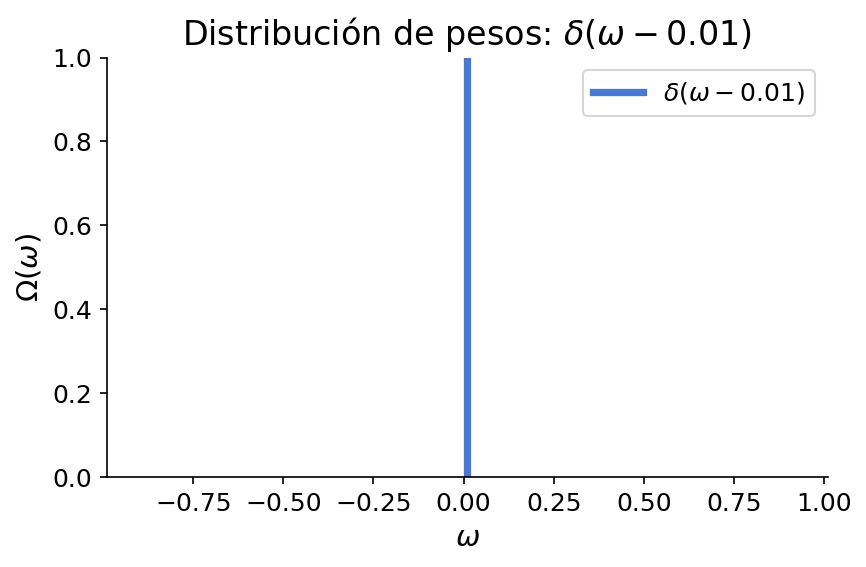

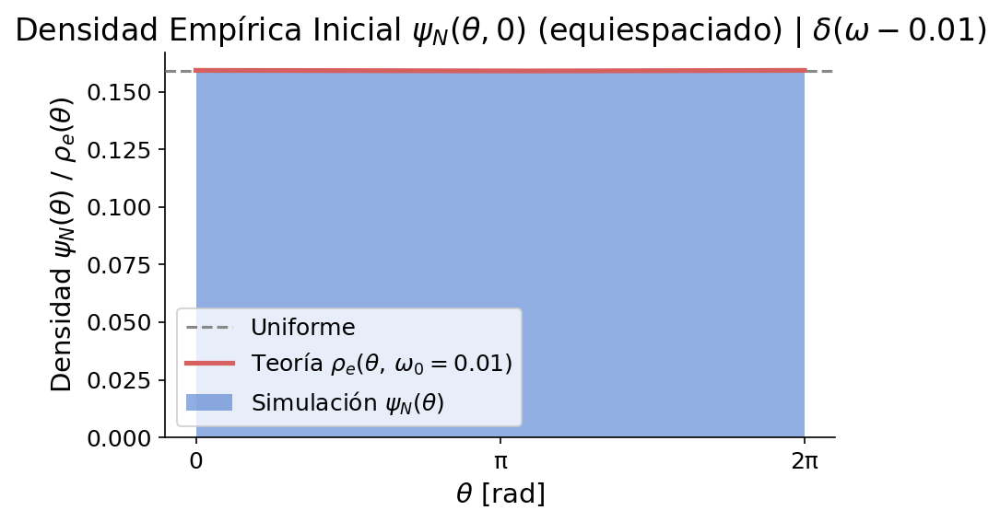

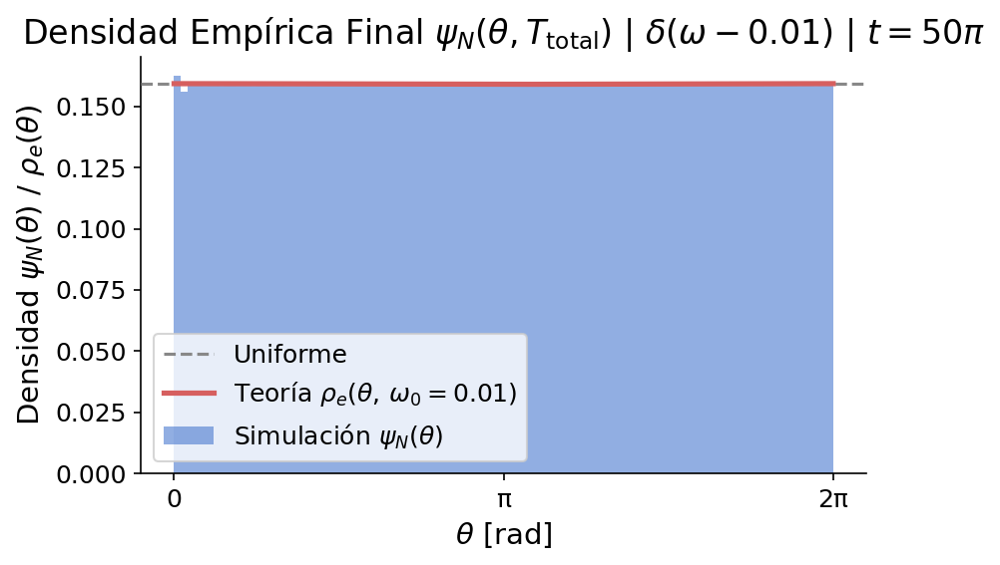

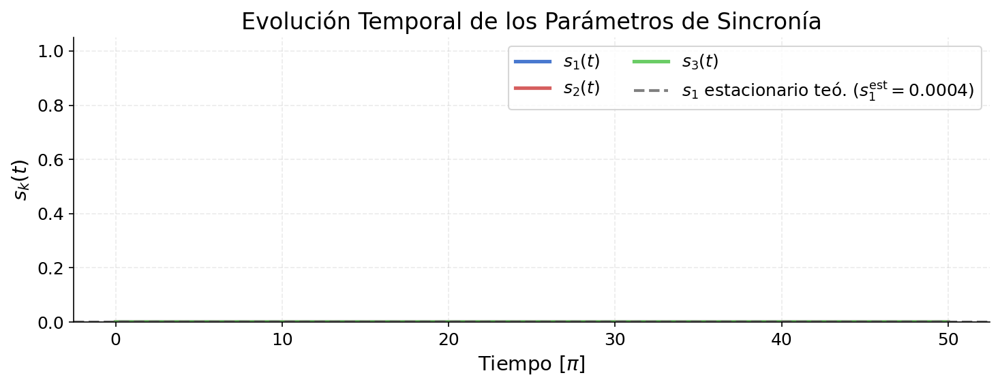

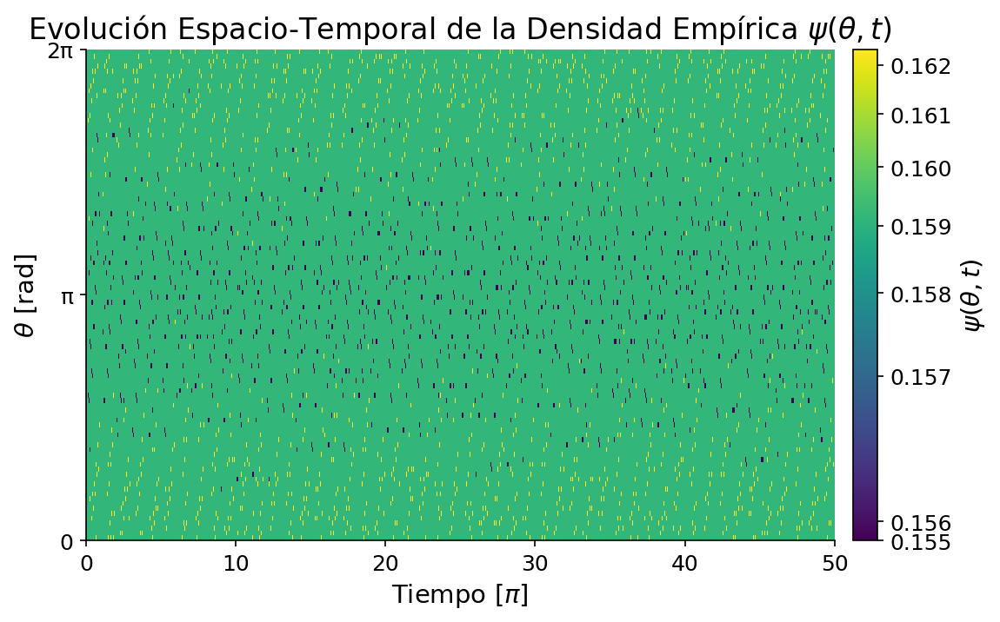

,Pico,ν / π,ν,T / π,T = 2π/ν,P(ν),P / P_dom,Dominante
0,1,0.636408,1.999334,1.000333,3.142640,2.846160e-08,1.000000,Sí
1,2,1.272815,3.998667,0.500167,1.571320,1.120185e-09,0.039358,
2,3,1.909223,5.998001,0.333444,1.047547,2.011167e-10,0.007066,


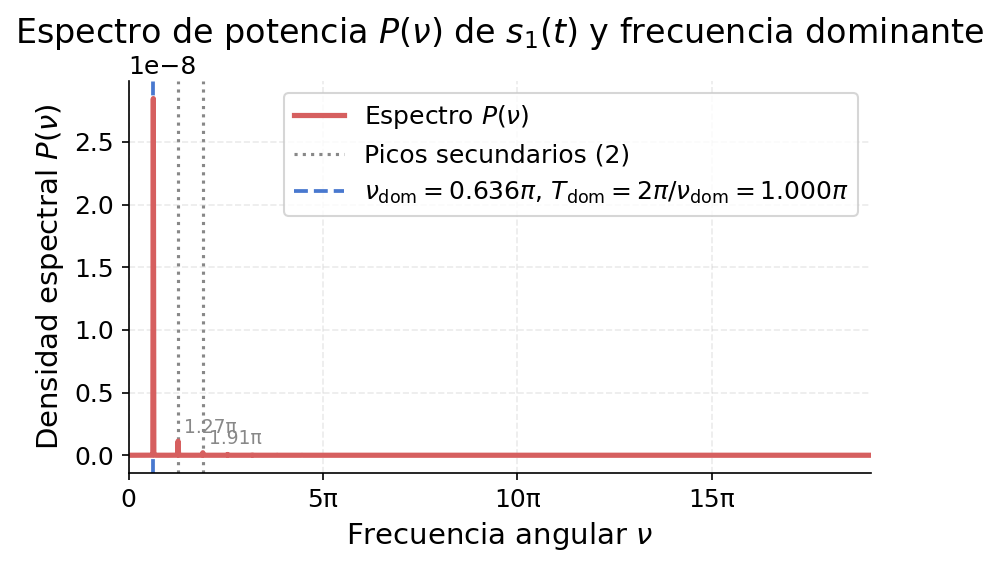

s₁ final = 0.0000 | s₁ᵉˢᵗ = 0.0004 | ν_dom = 0.6364π | T_dom = 2π/ν_dom = 1.0003π

  QIF + Delta | μ = 0.1


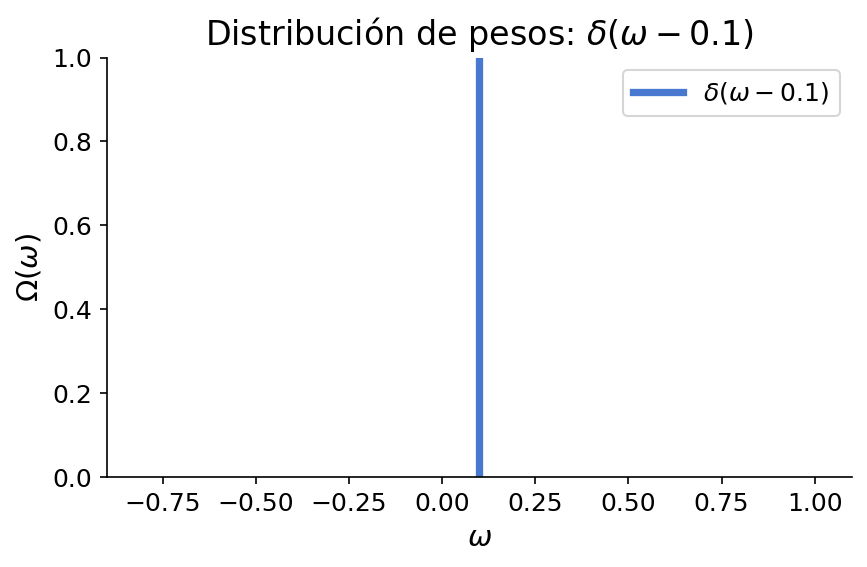

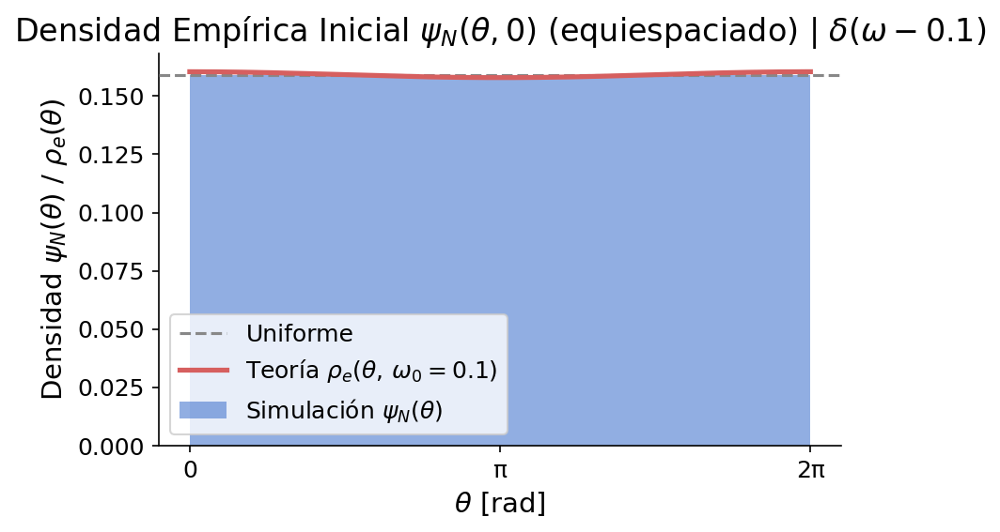

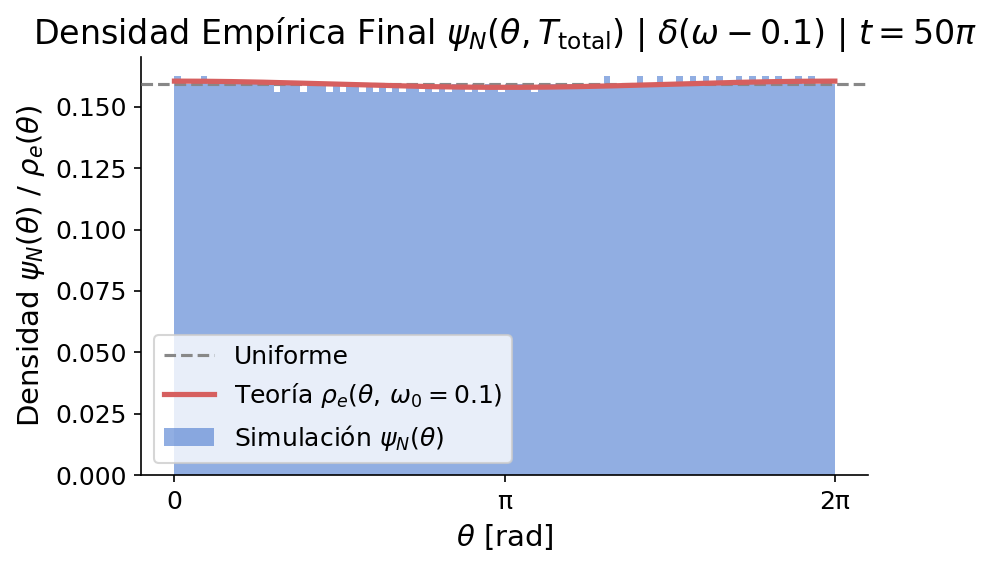

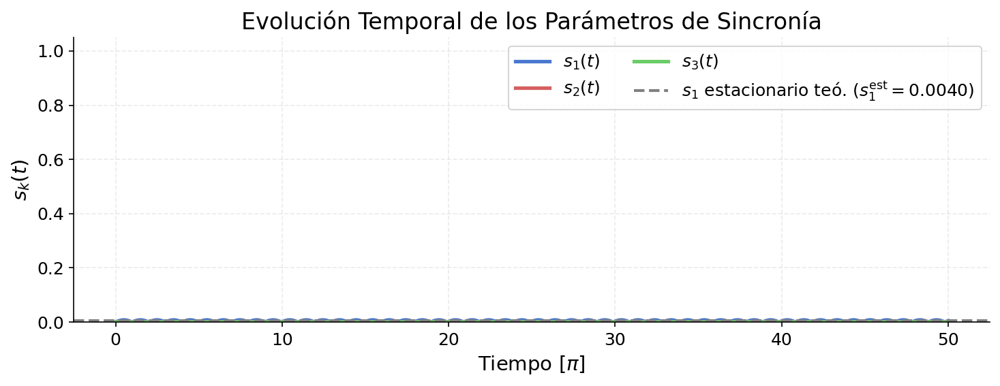

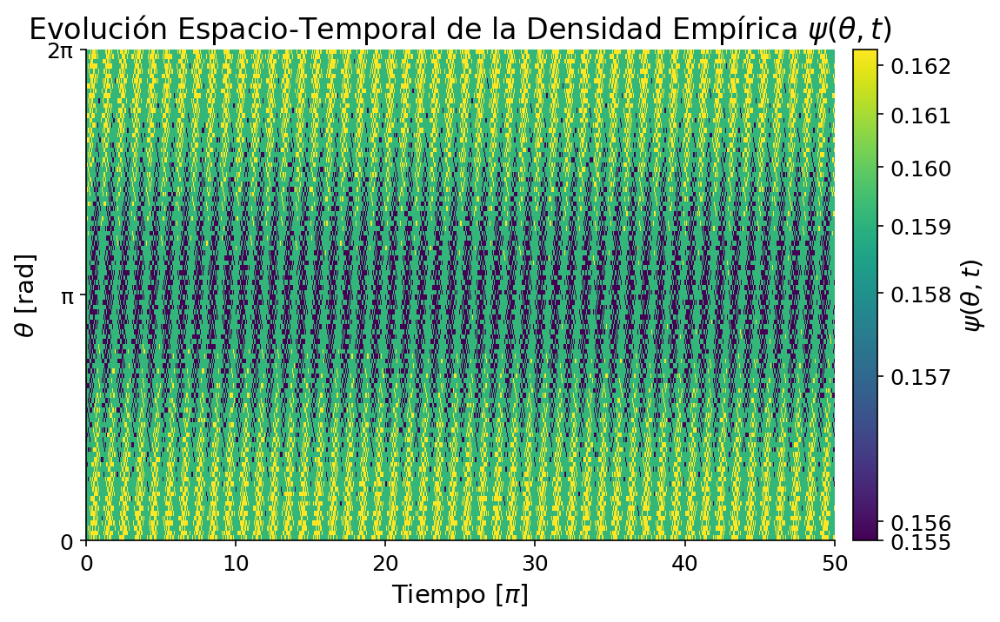

,Pico,ν / π,ν,T / π,T = 2π/ν,P(ν),P / P_dom,Dominante
0,1,0.636408,1.999334,1.000333,3.142640,2.448448e-06,1.000000,Sí
1,2,1.272815,3.998667,0.500167,1.571320,5.506472e-08,0.022490,
2,3,1.921951,6.037987,0.331236,1.040609,1.471840e-08,0.006011,


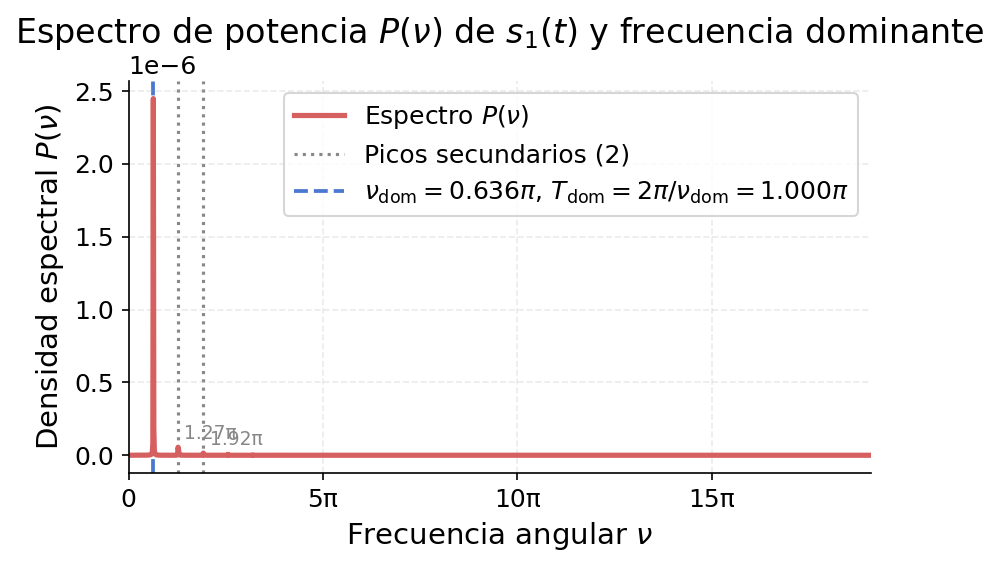

s₁ final = 0.0047 | s₁ᵉˢᵗ = 0.0040 | ν_dom = 0.6364π | T_dom = 2π/ν_dom = 1.0003π

  QIF + Delta | μ = 1.0


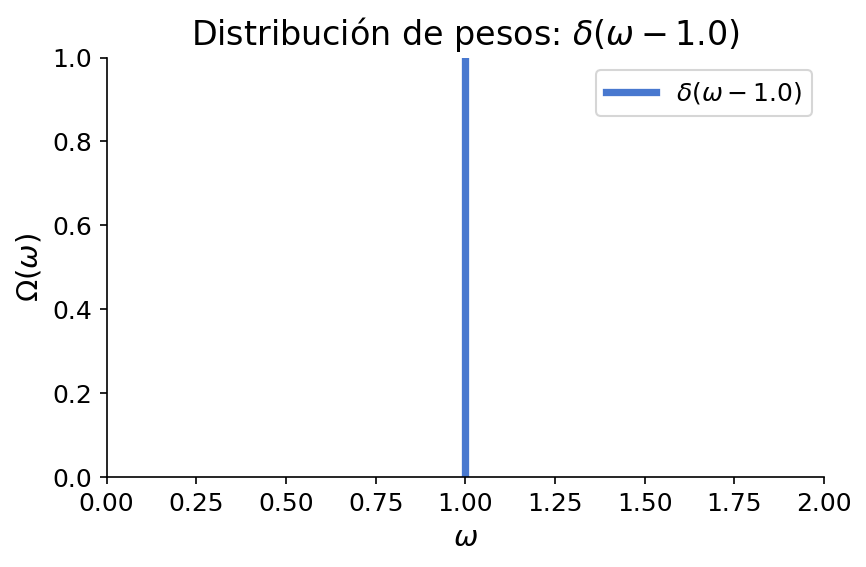

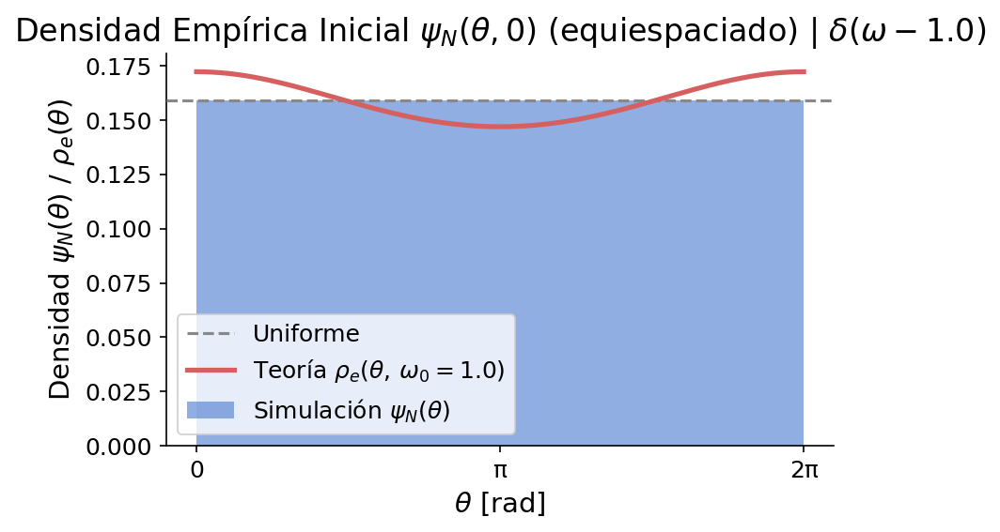

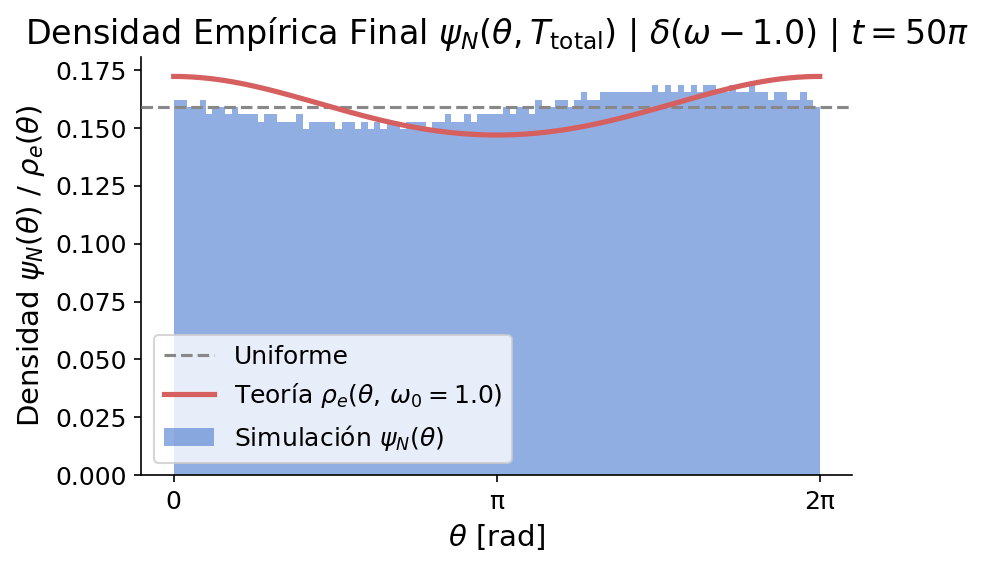

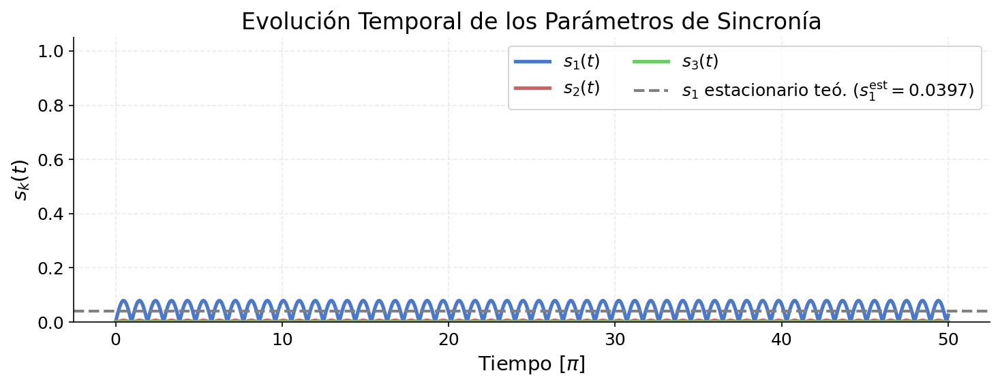

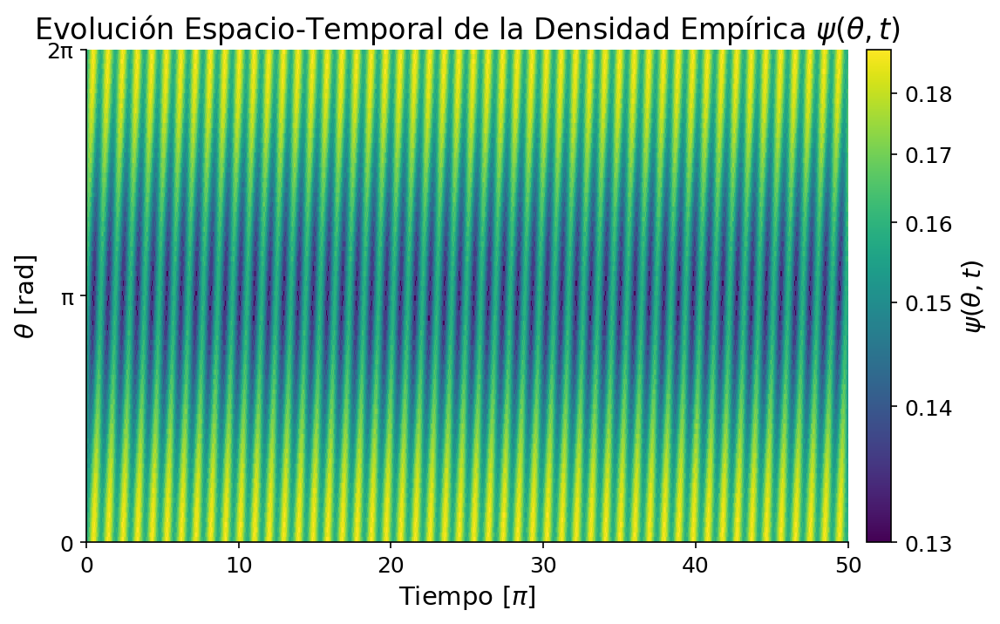

,Pico,ν / π,ν,T / π,T = 2π/ν,P(ν),P / P_dom,Dominante
0,1,0.661864,2.079307,0.961859,3.021769,0.000274,1.000000,Sí
1,2,1.323728,4.158614,0.480929,1.510885,0.000008,0.028648,


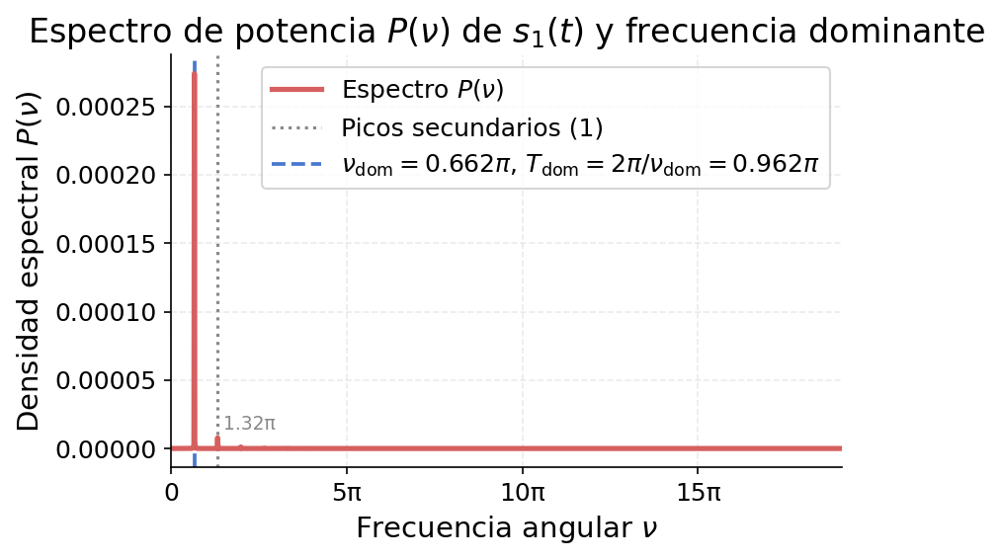

s₁ final = 0.0251 | s₁ᵉˢᵗ = 0.0397 | ν_dom = 0.6619π | T_dom = 2π/ν_dom = 0.9619π

  QIF + Delta | μ = 10.0


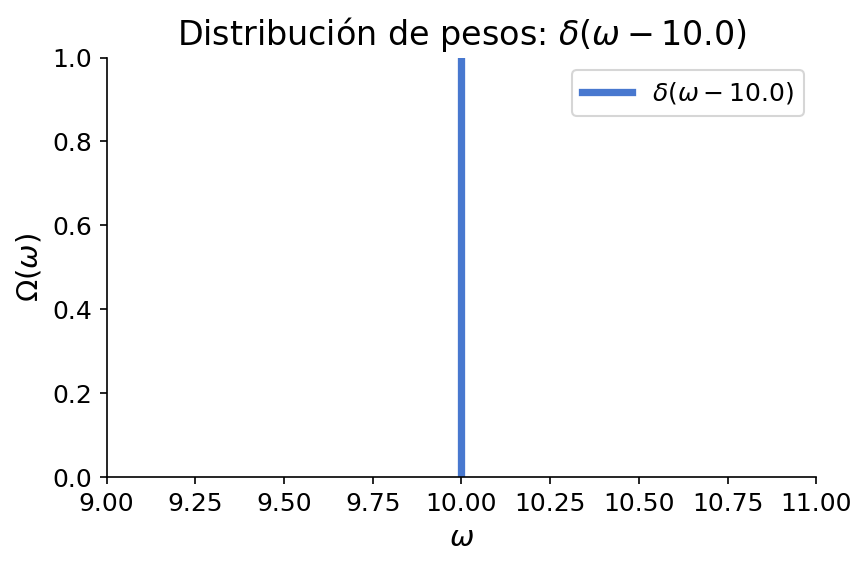

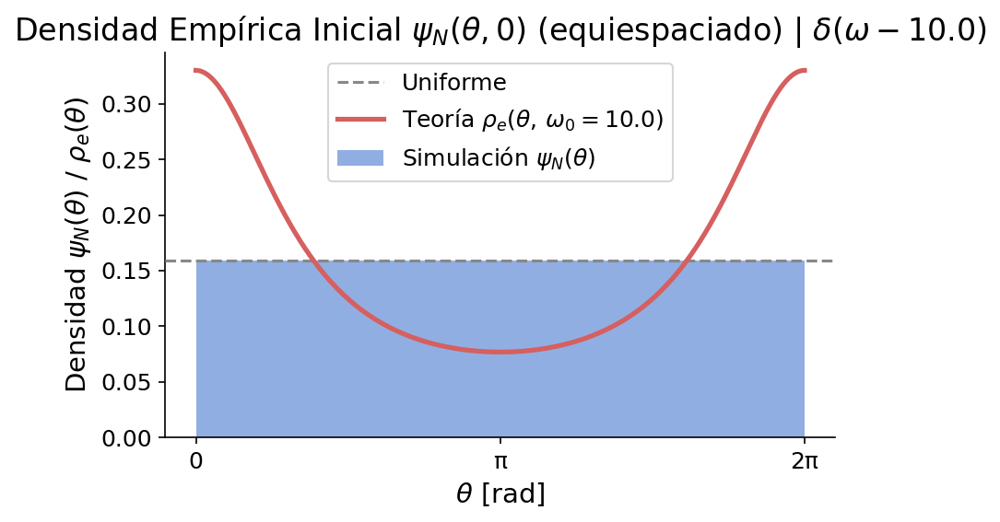

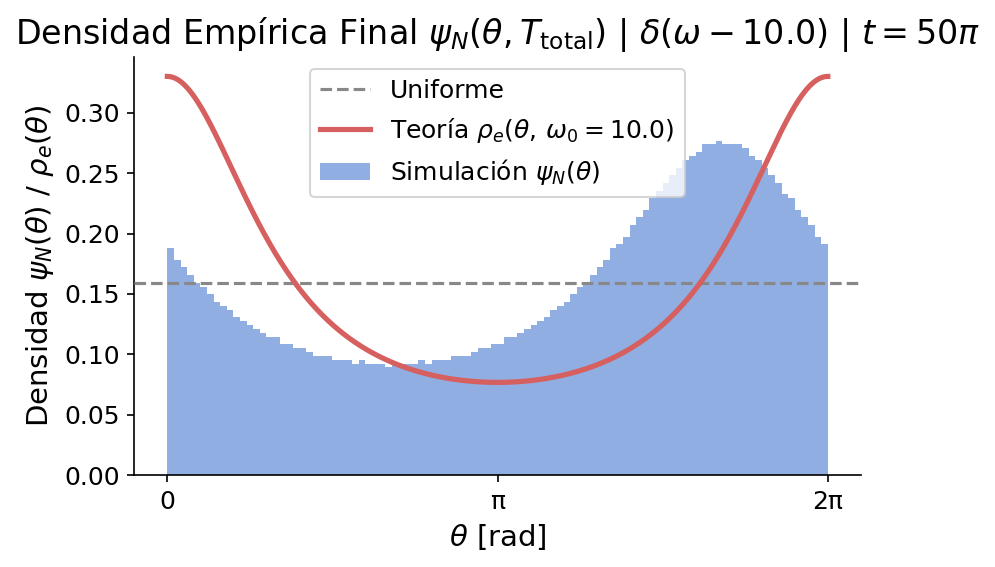

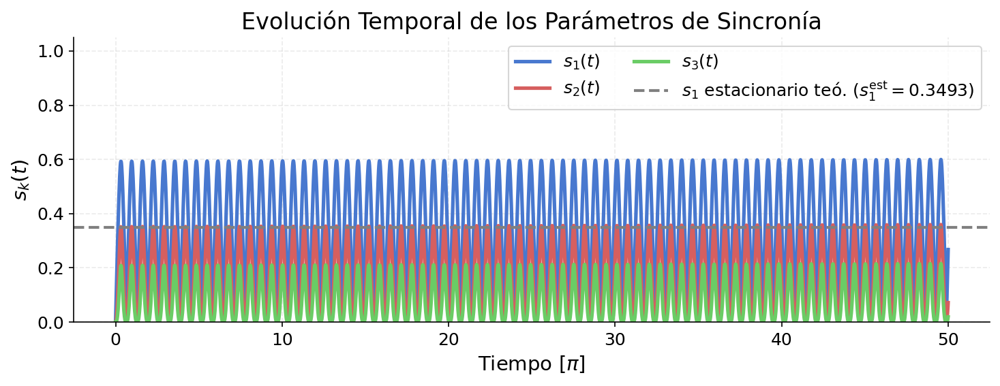

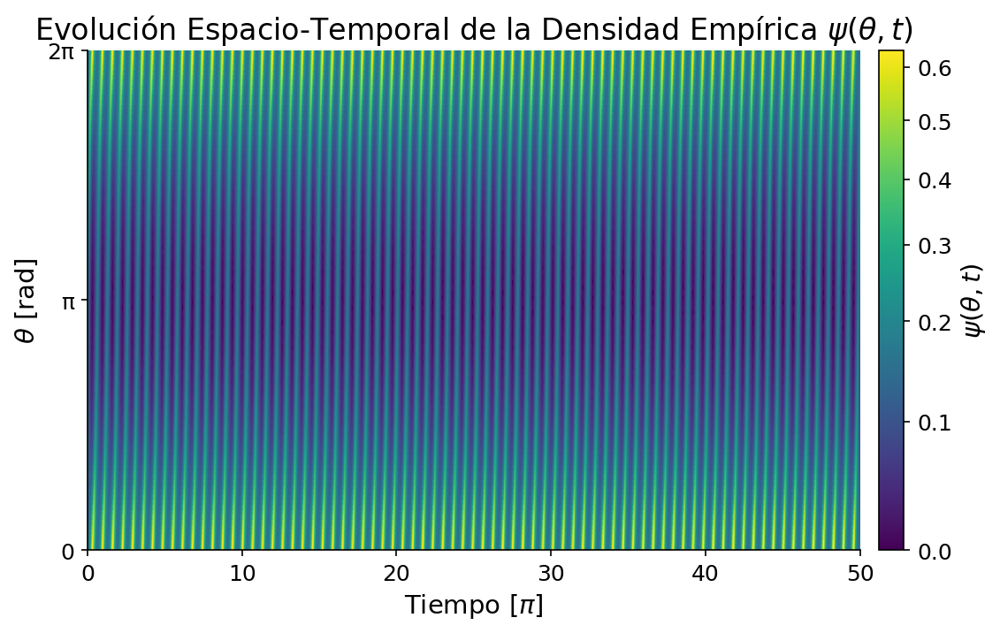

,Pico,ν / π,ν,T / π,T = 2π/ν,P(ν),P / P_dom,Dominante
0,1,0.980068,3.078974,0.649567,2.040675,0.014539,1.000000,Sí
1,2,1.960136,6.157947,0.324784,1.020338,0.000151,0.010397,


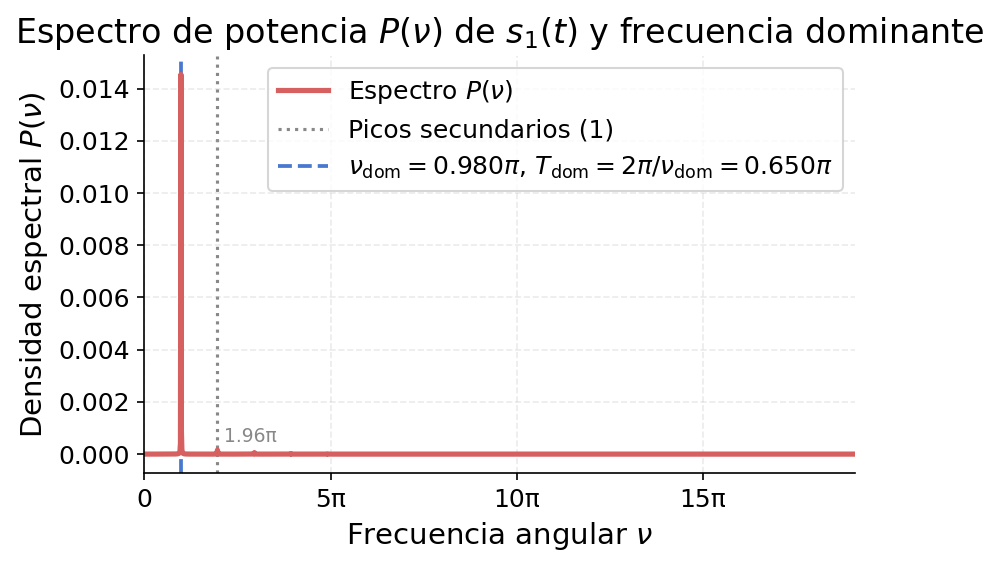

s₁ final = 0.2675 | s₁ᵉˢᵗ = 0.3493 | ν_dom = 0.9801π | T_dom = 2π/ν_dom = 0.6496π

  QIF + Delta | μ = 100.0


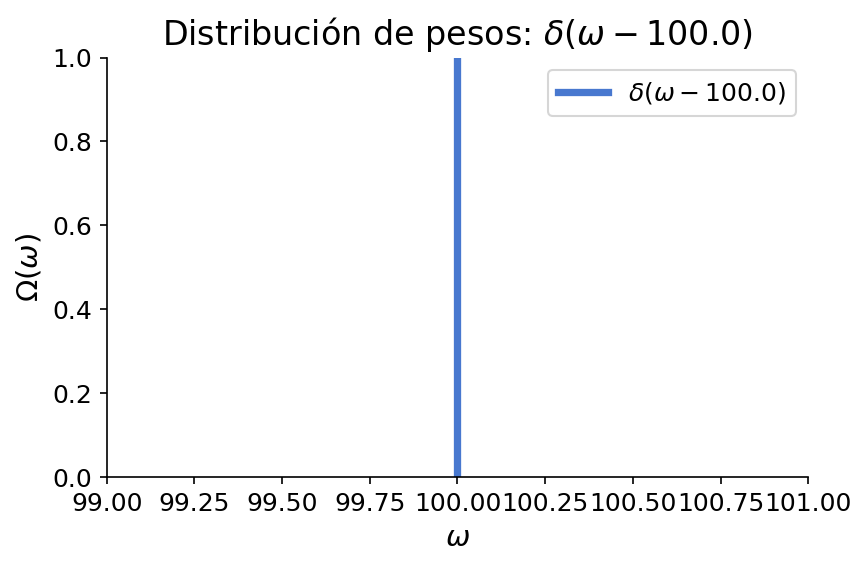

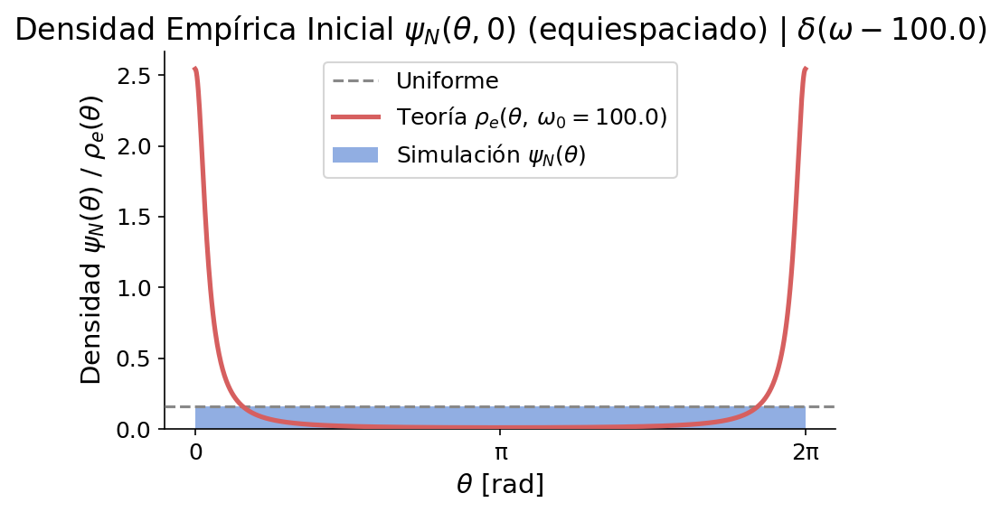

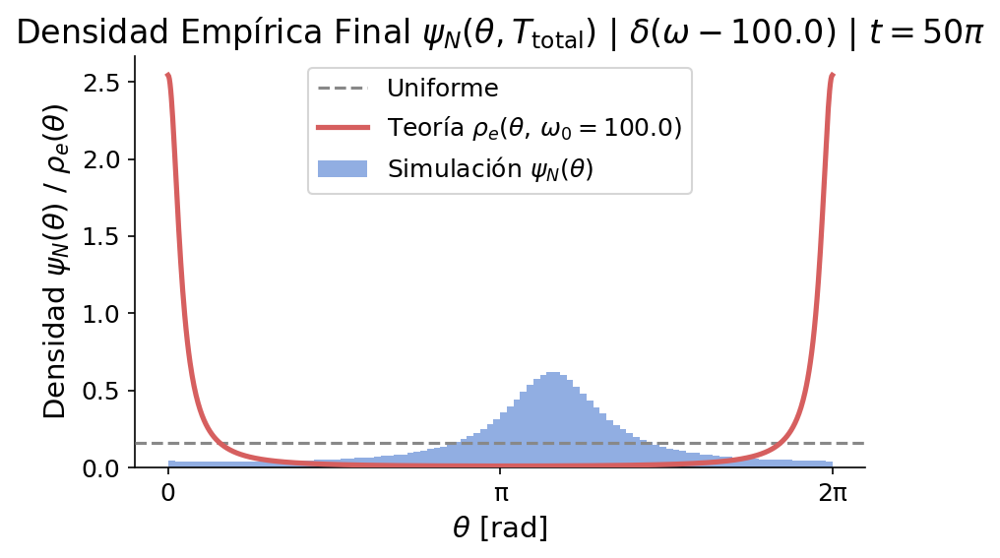

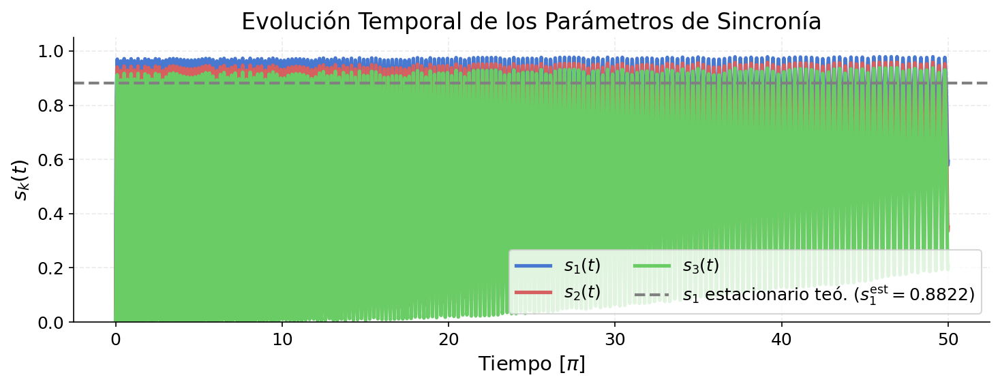

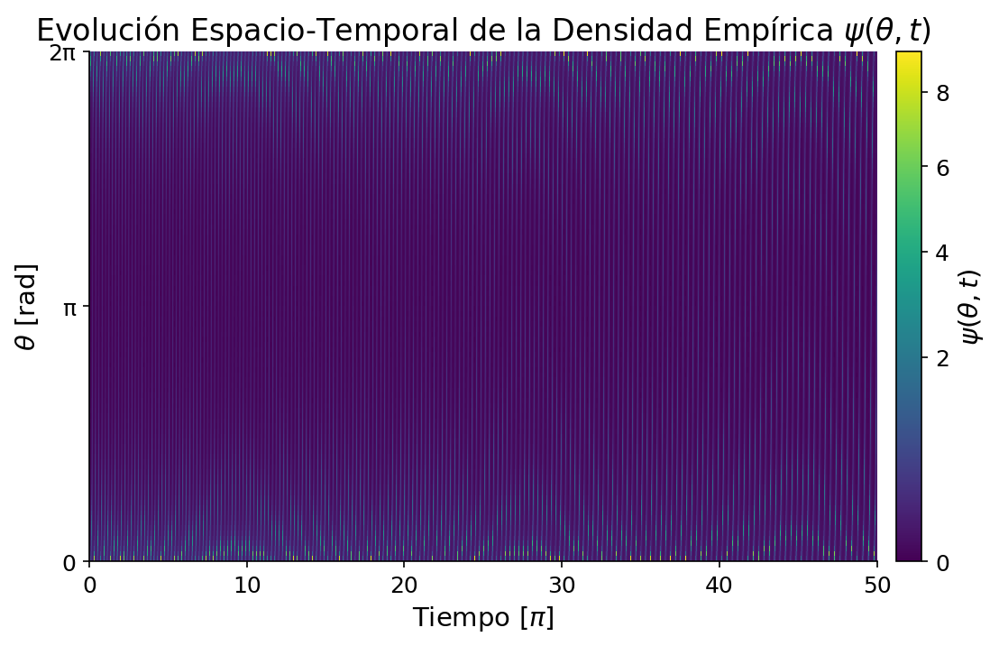

,Pico,ν / π,ν,T / π,T = 2π/ν,P(ν),P / P_dom,Dominante
0,1,0.012728,0.039987,50.016667,157.131993,0.000370,1.000000,Sí
1,2,2.965660,9.316894,0.214664,0.674386,0.000307,0.828160,
2,3,2.851106,8.957014,0.223289,0.701482,0.000264,0.712348,
3,4,2.774737,8.717094,0.229434,0.720789,0.000249,0.671593,
4,5,2.711097,8.517161,0.234820,0.737709,0.000241,0.650294,
5,6,2.660184,8.357214,0.239314,0.751828,0.000236,0.637842,
6,7,1.921951,6.037987,0.331236,1.040609,0.000231,0.625443,
7,8,2.609271,8.197268,0.243984,0.766498,0.000226,0.611705,
8,9,2.571087,8.077308,0.247607,0.777881,0.000226,0.611203,
9,10,2.532902,7.957348,0.251340,0.789608,0.000219,0.592220,


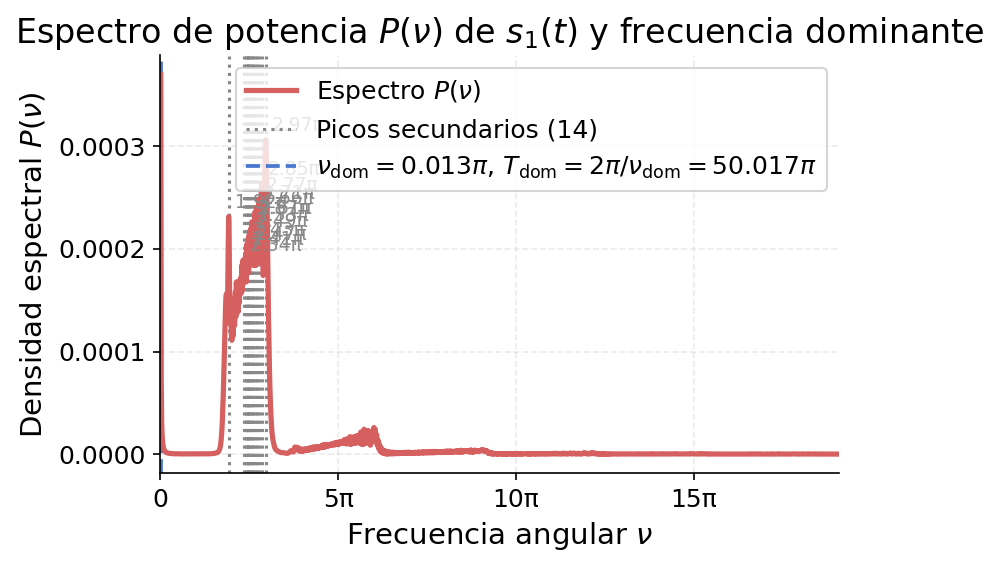

s₁ final = 0.5919 | s₁ᵉˢᵗ = 0.8822 | ν_dom = 0.0127π | T_dom = 2π/ν_dom = 50.0167π

  RESUMEN DEL BARRIDO A (QIF + DELTA): SINCRONÍA Y ESPECTRO P(ν)


,μ (Acoplamiento),s₁ final,s₁ᵉˢᵗ (teórico),ν_dom / π,T_dom / π,N° picos
0,0.01,0.000050,0.000398,0.636408,1.000333,3
1,0.10,0.004667,0.003979,0.636408,1.000333,3
2,1.00,0.025099,0.039726,0.661864,0.961859,2
3,10.00,0.267491,0.349332,0.980068,0.649567,2
4,100.00,0.591932,0.882201,0.012728,50.016667,15


In [62]:
#  BARRIDO A | Modelo QIF — Distribución Delta

# 1. Configuración de parámetros físicos y grilla de barrido
N              = 5000
I0             = 1.0
T_total        = 50 * np.pi
T_hist         = np.pi / 60
n_bins         = 100
omegas_barrido = [0.01, 0.1, 1.0, 10.0, 100.0]

# 2. Contenedor de almacenamiento para los resultados del barrido
resultados_A = {}

# 3. Bucle iterativo sobre los acoplamientos medios μ_ω
for mu in omegas_barrido:
    print(f"\n{'='*60}\n  QIF + Delta | μ_ω = {mu}\n{'='*60}")

    # Instanciación y verificación gráfica de la distribución Ω(ω)
    sampler, omega_info = make_omega_dist('delta', mu=mu)
    plot_omega_dist(omega_info)

    # Ejecución de la simulación event-driven (genera gráfico único sₖ(t) con s₁ᵉˢᵗ)
    phis_f, tiempos, s_dict, histogramas = simular_QIF(
        N            = N,
        sampler      = sampler,
        omega_info   = omega_info,
        Z_fn         = Z_QIF,
        T            = np.pi,
        rho_e_fn     = rho_e_QIF,
        I0           = I0,
        T_total      = T_total,
        T_hist       = T_hist,
        n_bins       = n_bins,
        cond_inicial = 'equiespaciado',
        mu_w_ref   = mu,
        guardar_figs = True,
    )

    # Espectro P(ν) de s₁(t) (ν = 2πf), picos prominentes y frecuencia dominante ν_dom
    s_1_serie = s_dict[1]
    T_dom, nu_dom, nus, psd, df_picos = calcular_periodo_fft(tiempos, s_1_serie)
    s1_est = calcular_s1_estacionario(rho_e_QIF, mu, I0)

    # Tabla de picos y espectro P(ν) con ν en múltiplos de π (picos con líneas punteadas)
    display(df_picos)
    plot_espectro_fft(nus, psd, nu_dom, T_dom, df_picos=df_picos, fname=f'espectro_fft_QIF_delta_mu_{mu}.png')

    # Persistencia de resultados con métricas espectrales
    resultados_A[mu] = dict(
        s_dict   = s_dict,
        tiempos  = tiempos,
        s1_est   = s1_est,
        nu_dom   = nu_dom,
        T_dom    = T_dom,
        nus      = nus,
        psd      = psd,
        picos    = df_picos,
    )

    print(f"s₁ final = {s_dict[1][-1]:.4f} | s₁ᵉˢᵗ = {s1_est:.4f} | ν_dom = {fmt_mult_pi(nu_dom, 4)} | T_dom = 2π/ν_dom = {fmt_mult_pi(T_dom, 4)}")

# 4. Tabla resumen comparativa del barrido paramétrico
tabla_resumen_A = pd.DataFrame([
    {
        'μ_ω [u.v.]': mu,
        's₁ final': float(res['s_dict'][1][-1]),
        's₁ᵉˢᵗ (teórico)': res['s1_est'],
        'ν_dom / π [rad/u.t.]': res['nu_dom'] / np.pi,      # Frecuencia angular dominante en múltiplos de π
        'T_dom / π [u.t.]': res['T_dom'] / np.pi,       # Período dominante T_dom = 2π/ν_dom en múltiplos de π
        'N° picos': len(res['picos']),
    }
    for mu, res in resultados_A.items()
])

print(f"\n{'='*70}\n  RESUMEN DEL BARRIDO A (QIF + DELTA): SINCRONÍA Y ESPECTRO P(ν)\n{'='*70}")
display(tabla_resumen_A)


### Barrido B | Modelo QIF — Distribución Uniforme (Fluctuaciones Estocásticas $\Delta = \mu_\omega$)

1. **¿Qué hace esta celda?**  
   Analiza la respuesta de la red QIF frente a desorden recocido estocástico con dispersión proporcional a la media: $\omega_i \sim \mathcal{U}[\mu_\omega/2, 3\mu_\omega/2]$ (con ancho $\Delta = \mu_\omega$), midiendo el impacto del ruido sobre el período colectivo $T_{\text{dom}}$ y la frecuencia angular dominante $\nu_{\text{dom}}$ mediante FFT.

2. **¿Cómo lo hace?**  
   Recorre la grilla de acoplamientos $\mu_\omega \in [0.01, 100]$ sampleando pesos independientes con dispersión finita. Para cada simulación:
   - Registra la dinámica macroscópica con `simular_QIF`.
   - Realiza el procesamiento espectral FFT sobre $s_1(t)$ con `calcular_periodo_fft`.
   - Grafica el espectro de potencia $P(\nu)$ vía `plot_espectro_fft`.
   - Almacena las series, frecuencias y períodos en `resultados_B` y genera la tabla comparativa del barrido.

3. **¿Qué devuelve o cuál es su resultado/salida?**  
   Genera las figuras de densidad empírica $\psi_N$, sincronía y espectros $P(\nu)$ con tabla de picos para cada nivel de ruido, compila `resultados_B` y presenta la tabla resumen comparativa de sincronía y período frente a $\mu_\omega$.



  QIF + Uniforme | μ = 0.01, Δ = 0.01


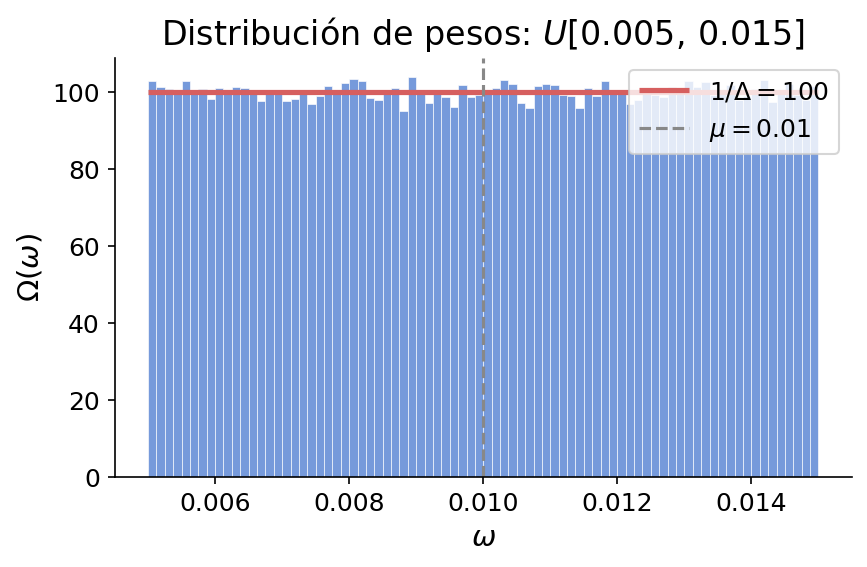

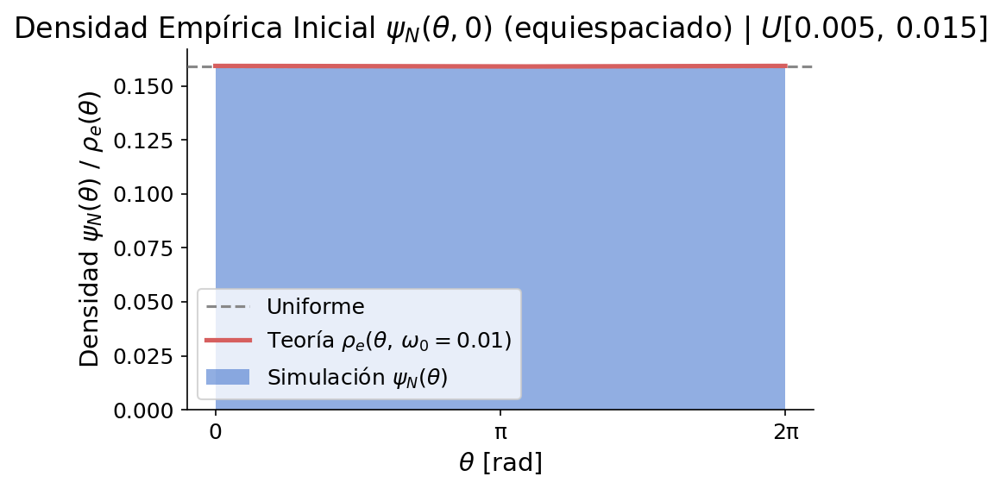

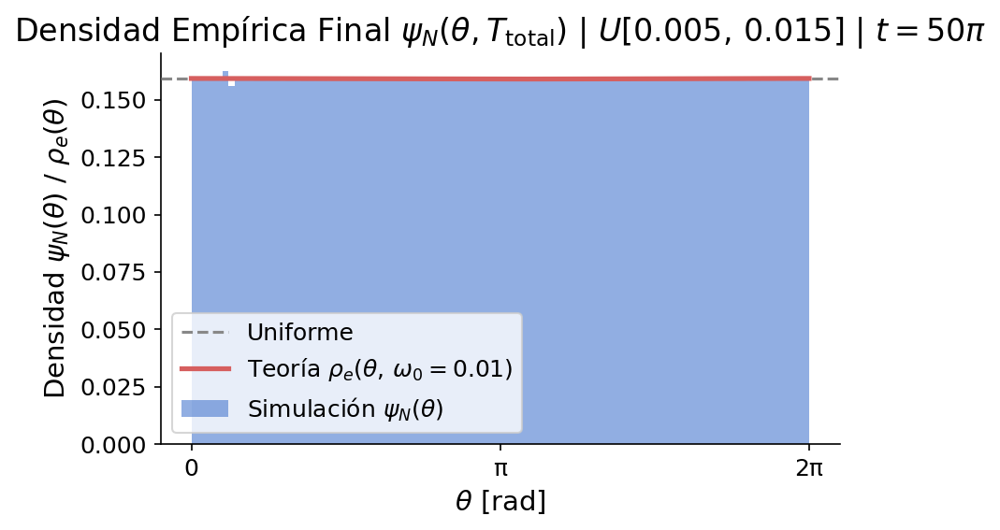

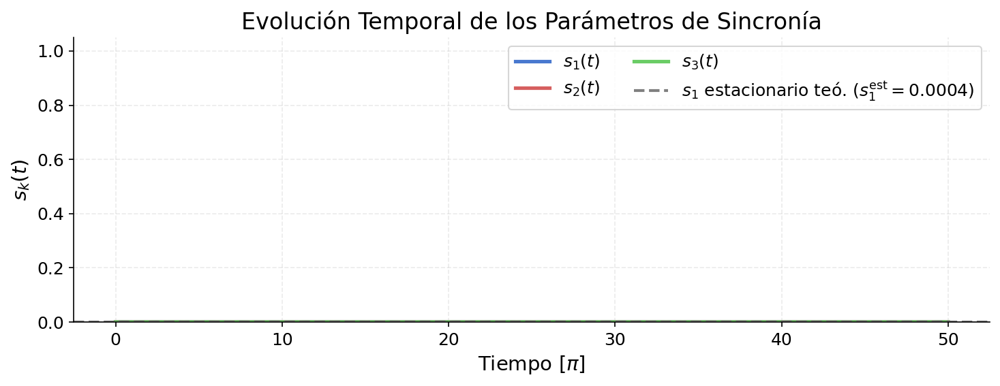

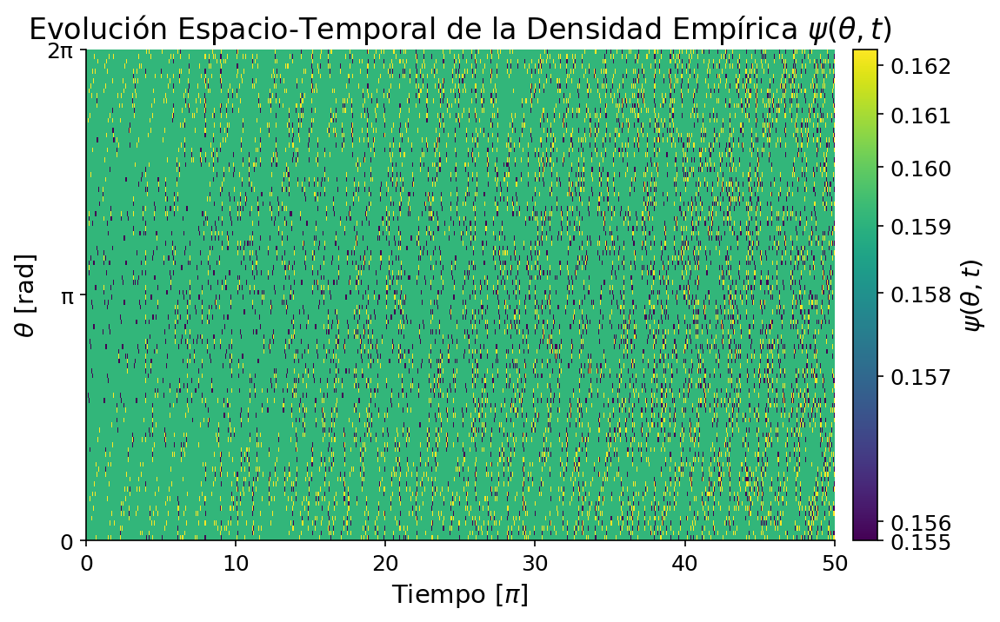

,Pico,ν / π,ν,T / π,T = 2π/ν,P(ν),P / P_dom,Dominante
0,1,0.636408,1.999334,1.000333,3.142640,2.854915e-08,1.00000,Sí
1,2,1.272815,3.998667,0.500167,1.571320,1.122541e-09,0.03932,
2,3,1.909223,5.998001,0.333444,1.047547,2.012624e-10,0.00705,


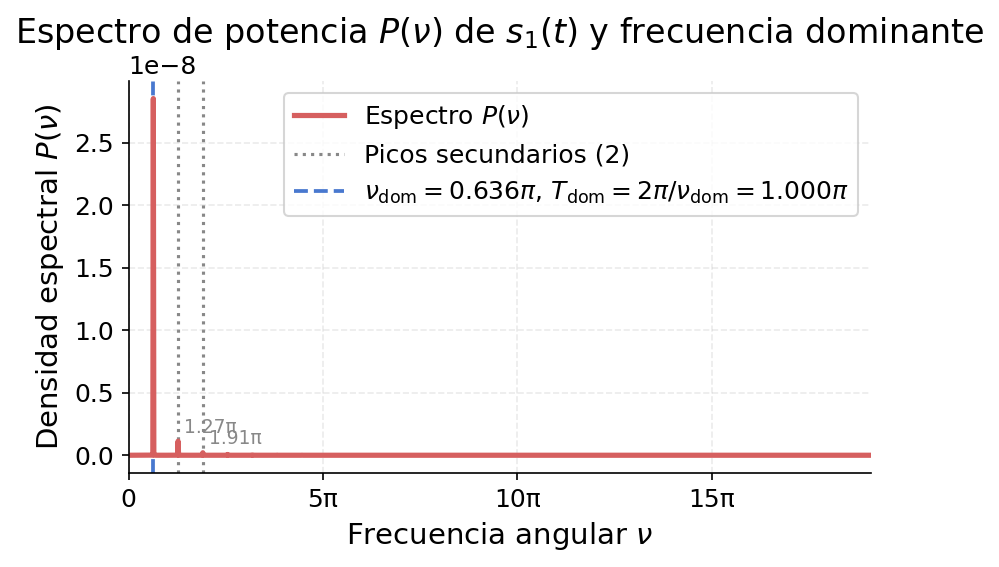

s₁ final = 0.0001 | s₁ᵉˢᵗ = 0.0004 | ν_dom = 0.6364π | T_dom = 2π/ν_dom = 1.0003π

  QIF + Uniforme | μ = 0.1, Δ = 0.1


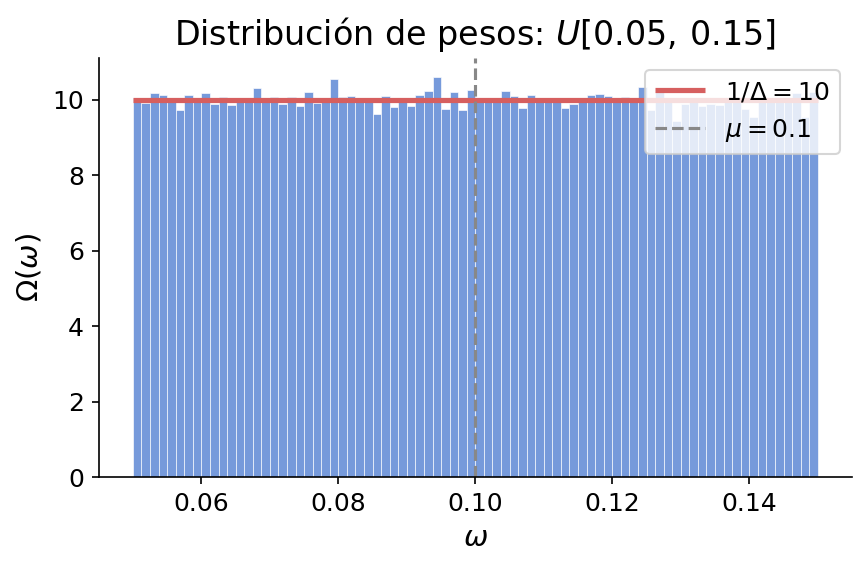

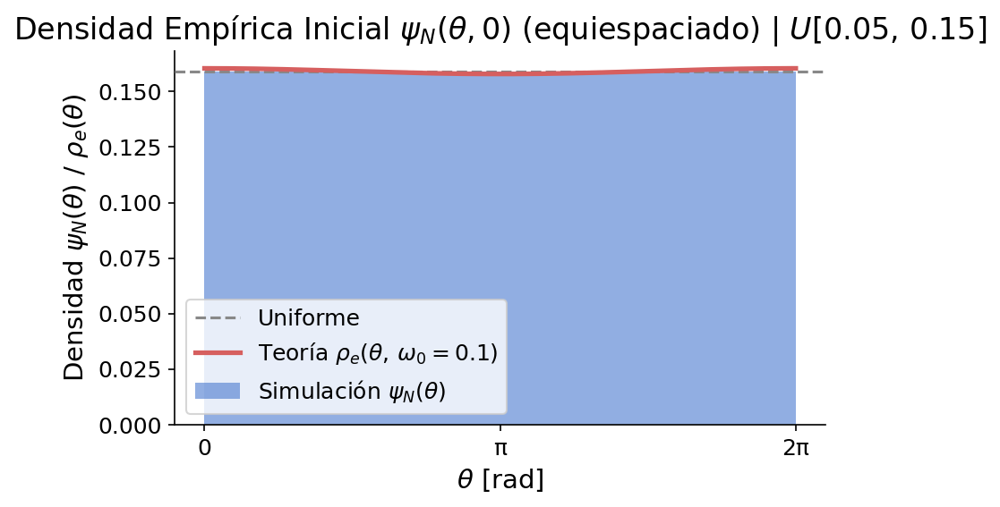

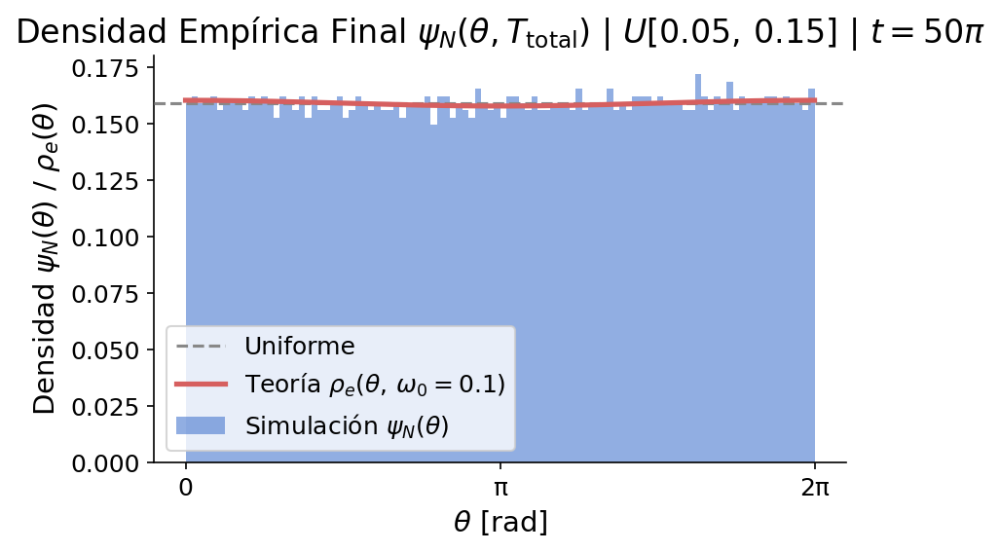

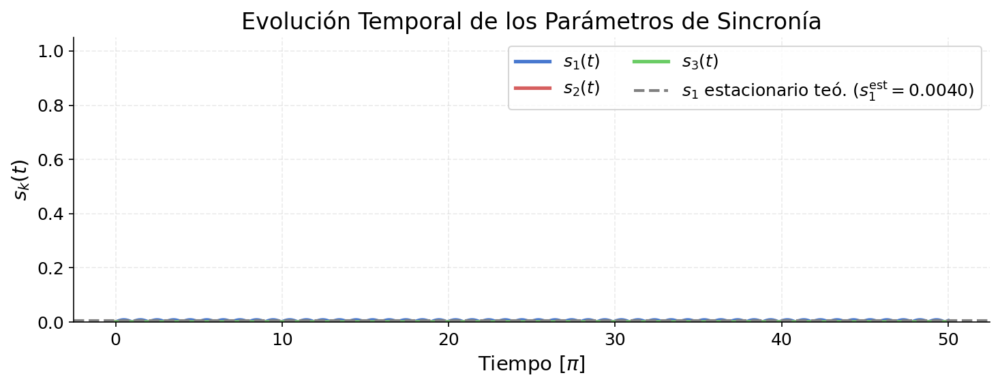

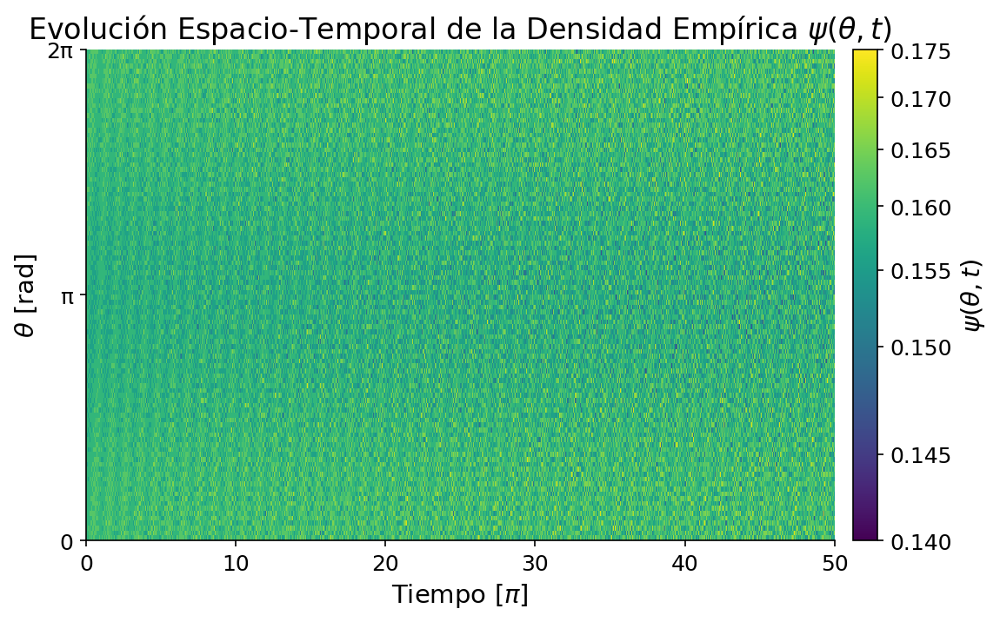

,Pico,ν / π,ν,T / π,T = 2π/ν,P(ν),P / P_dom,Dominante
0,1,0.636408,1.999334,1.000333,3.142640,2.438299e-06,1.000000,Sí
1,2,1.272815,3.998667,0.500167,1.571320,5.467987e-08,0.022425,
2,3,1.921951,6.037987,0.331236,1.040609,1.473102e-08,0.006042,


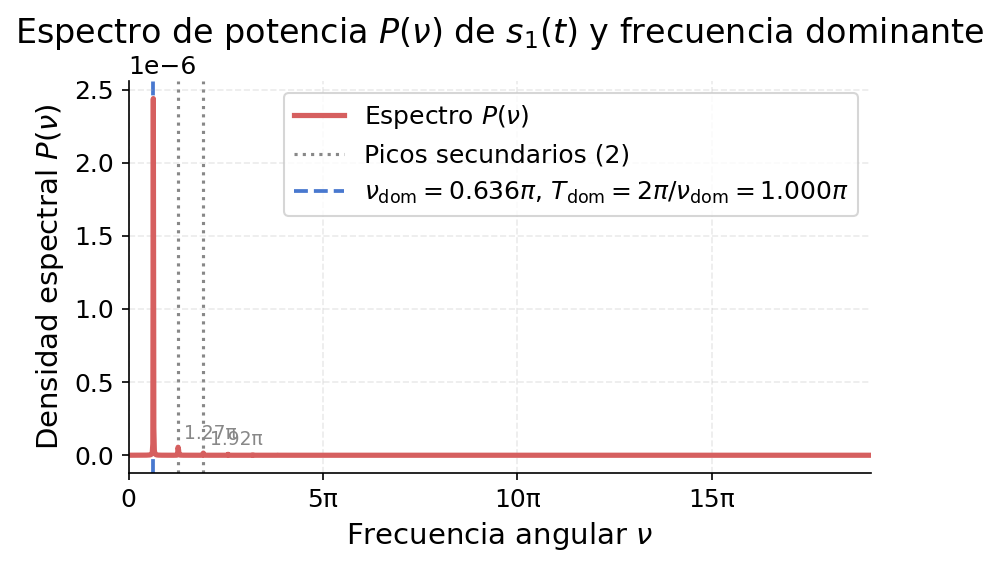

s₁ final = 0.0047 | s₁ᵉˢᵗ = 0.0040 | ν_dom = 0.6364π | T_dom = 2π/ν_dom = 1.0003π

  QIF + Uniforme | μ = 1.0, Δ = 1.0


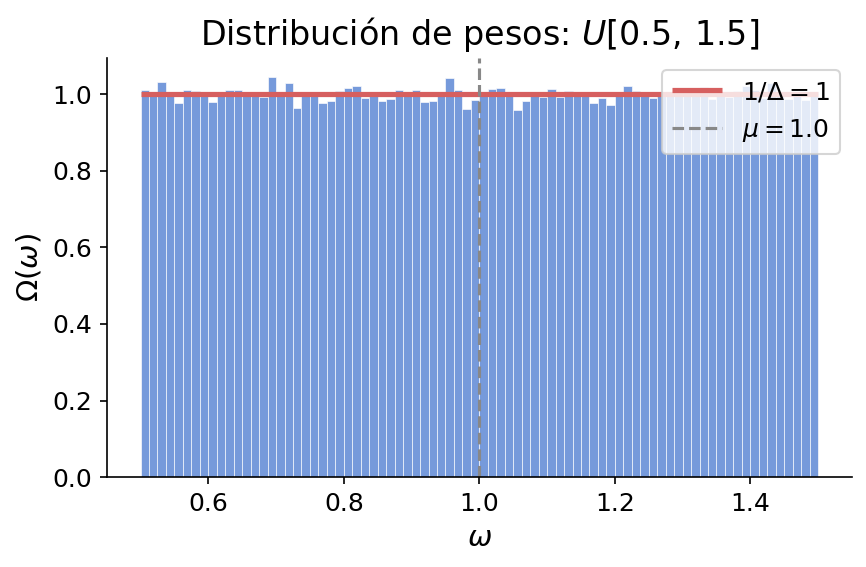

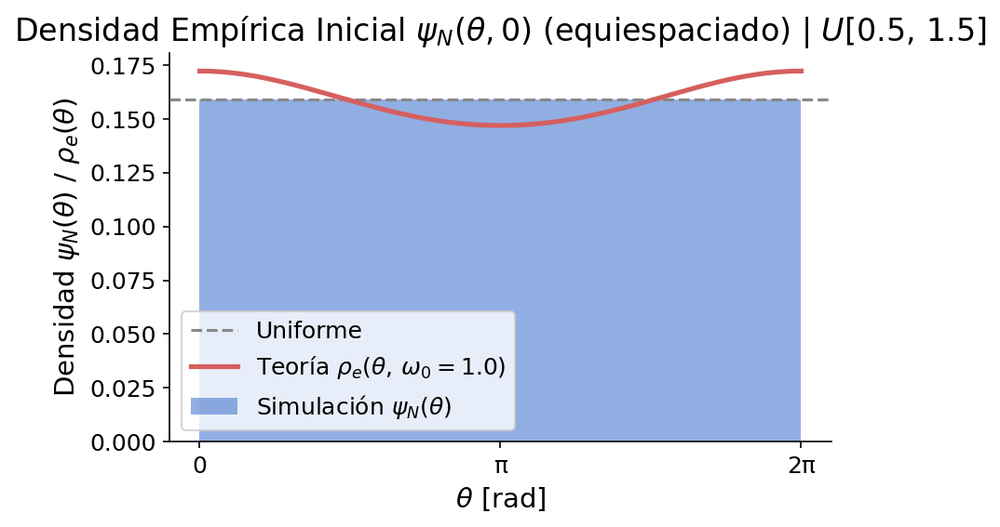

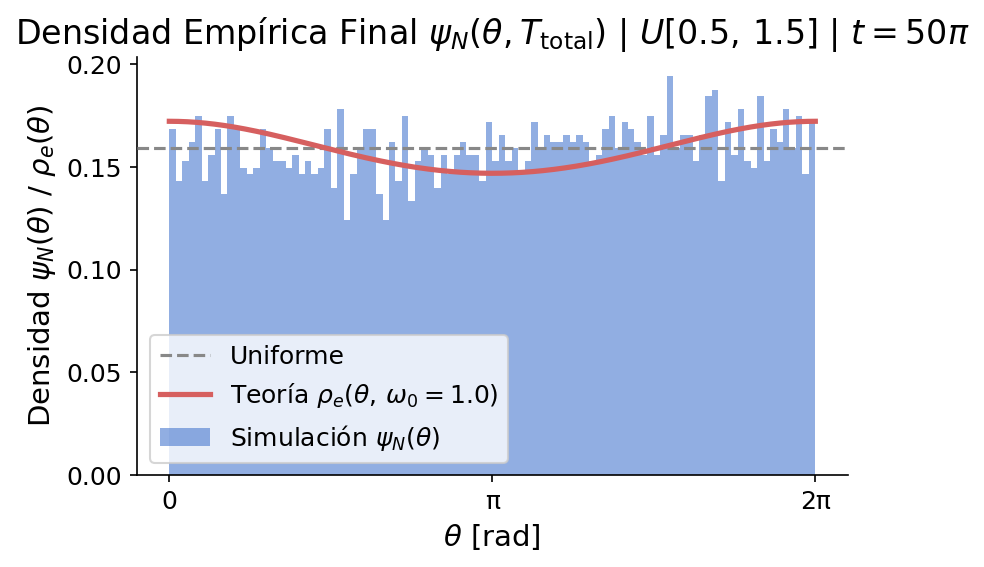

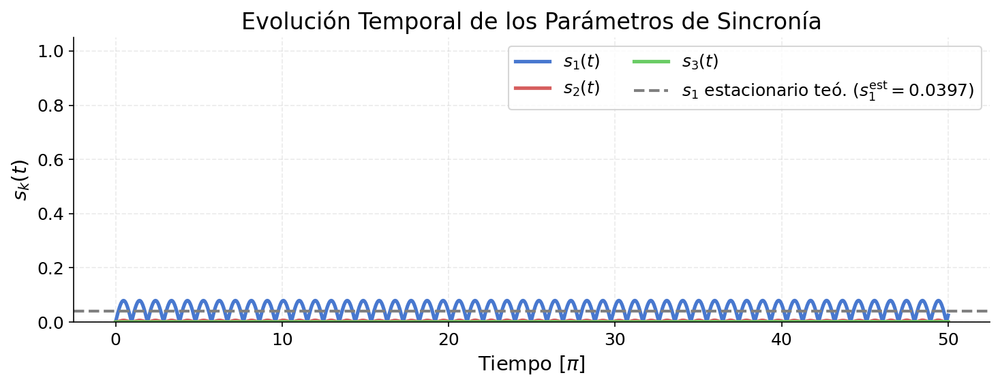

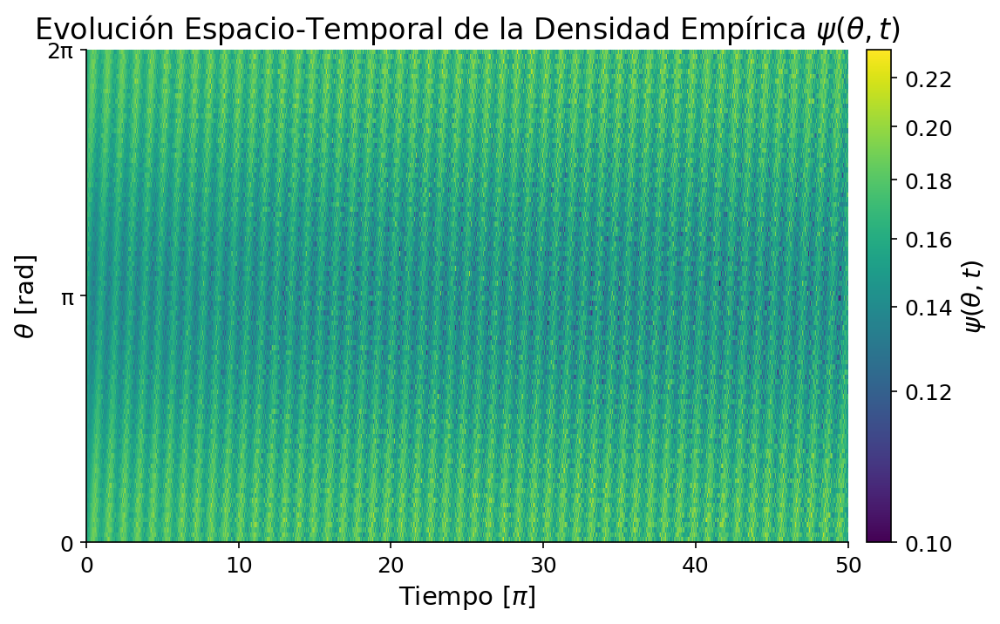

,Pico,ν / π,ν,T / π,T = 2π/ν,P(ν),P / P_dom,Dominante
0,1,0.661864,2.079307,0.961859,3.021769,0.000275,1.000000,Sí
1,2,1.323728,4.158614,0.480929,1.510885,0.000008,0.028585,


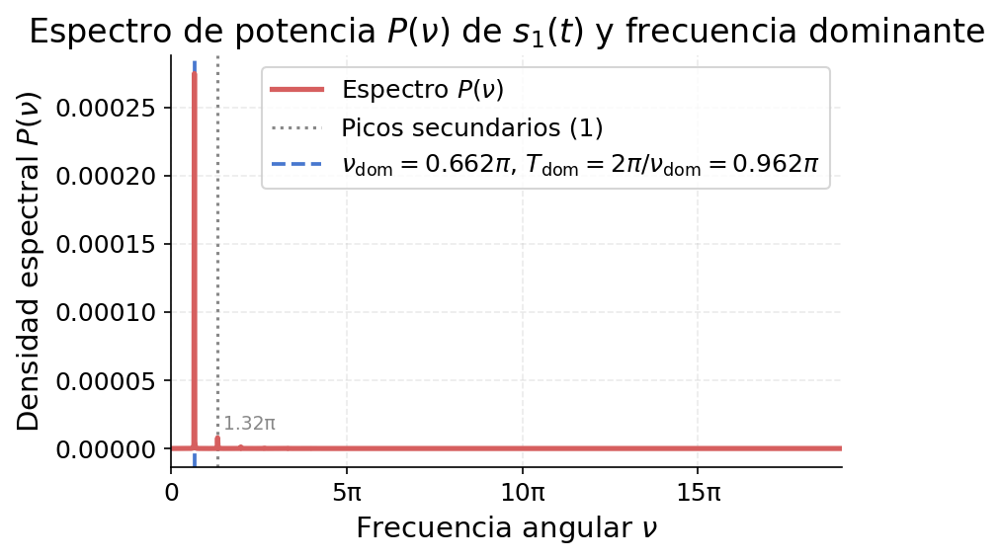

s₁ final = 0.0251 | s₁ᵉˢᵗ = 0.0397 | ν_dom = 0.6619π | T_dom = 2π/ν_dom = 0.9619π

  QIF + Uniforme | μ = 10.0, Δ = 10.0


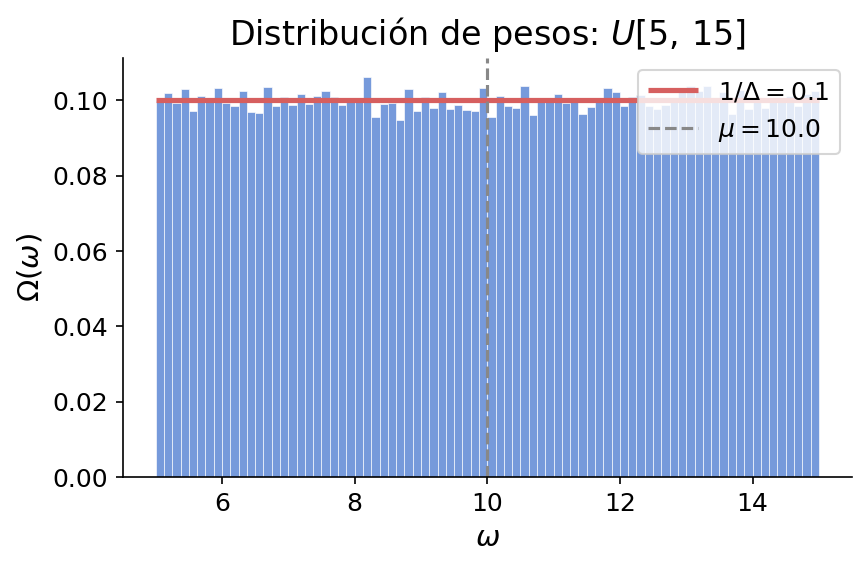

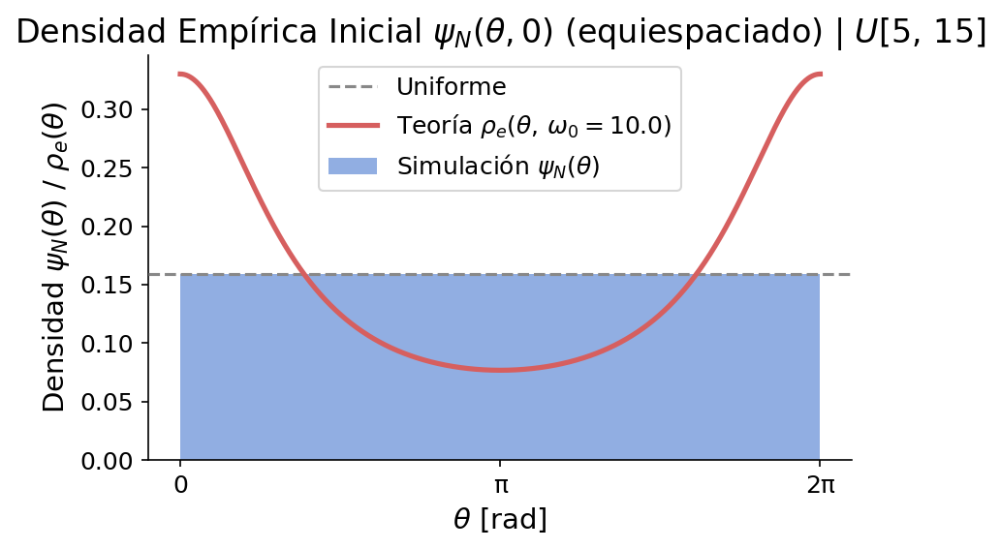

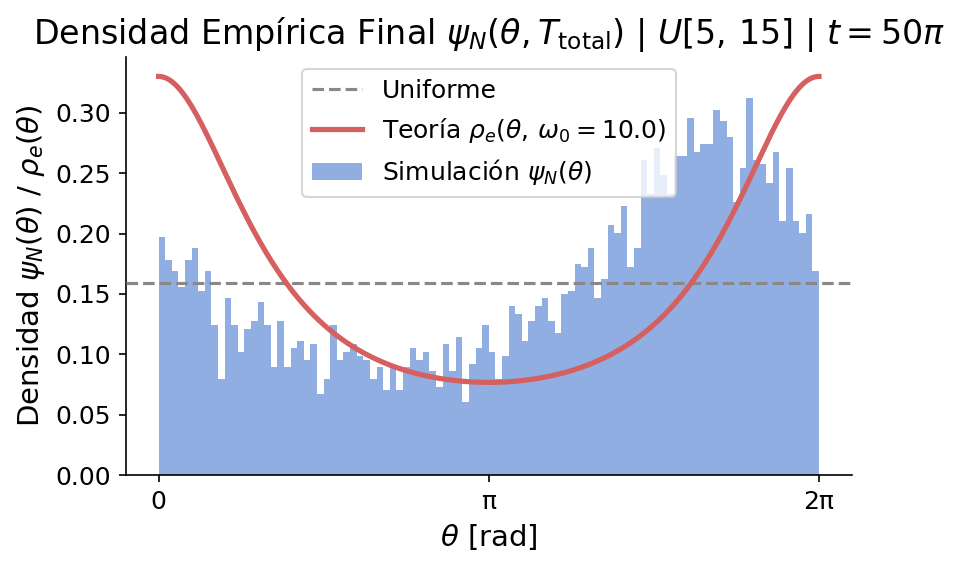

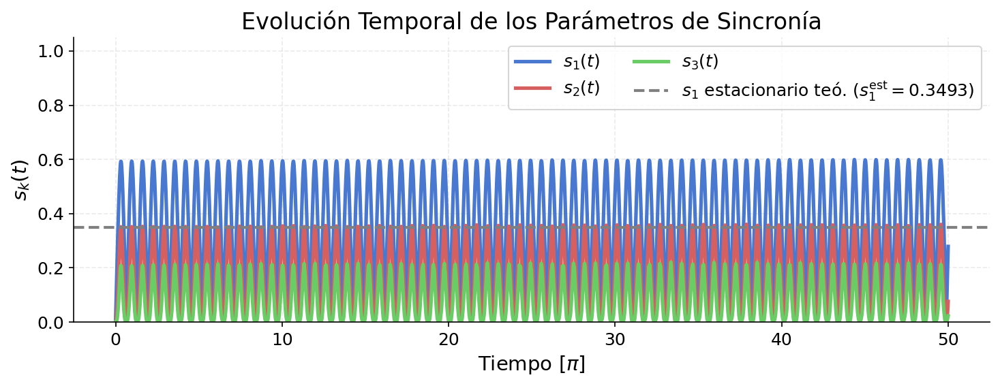

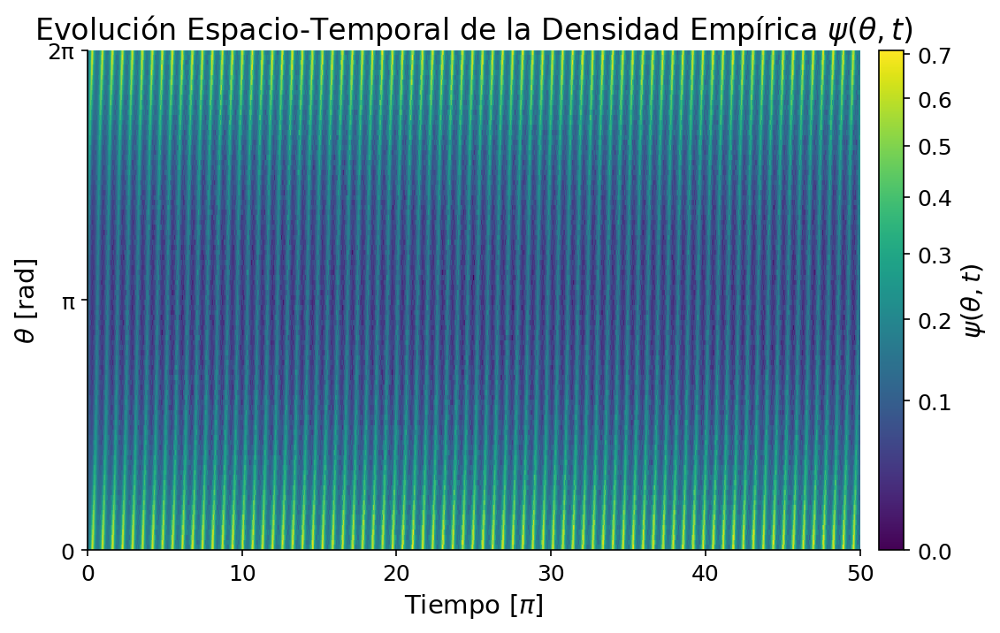

,Pico,ν / π,ν,T / π,T = 2π/ν,P(ν),P / P_dom,Dominante
0,1,0.980068,3.078974,0.649567,2.040675,0.014472,1.000000,Sí
1,2,1.960136,6.157947,0.324784,1.020338,0.000149,0.010275,


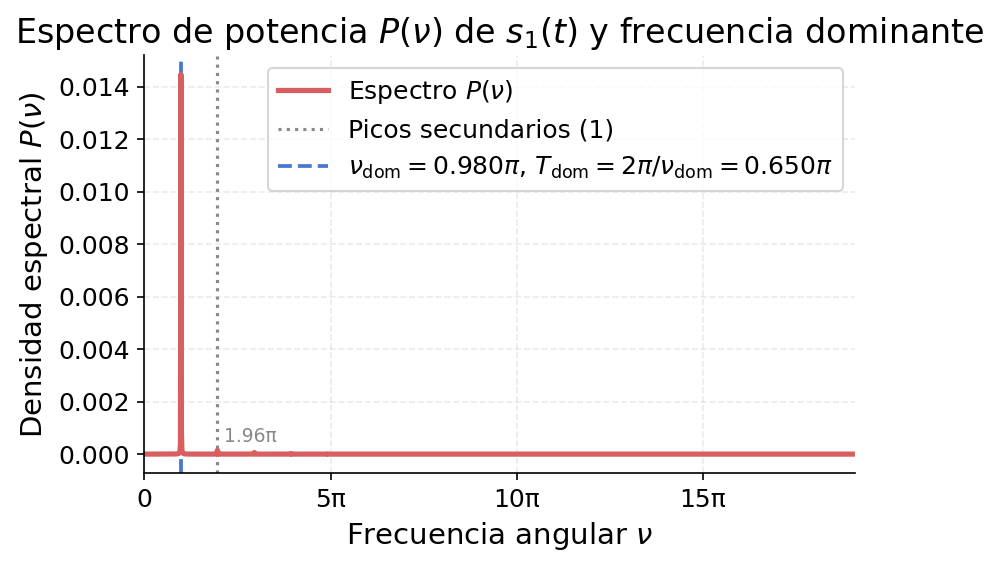

s₁ final = 0.2791 | s₁ᵉˢᵗ = 0.3493 | ν_dom = 0.9801π | T_dom = 2π/ν_dom = 0.6496π

  QIF + Uniforme | μ = 100.0, Δ = 100.0


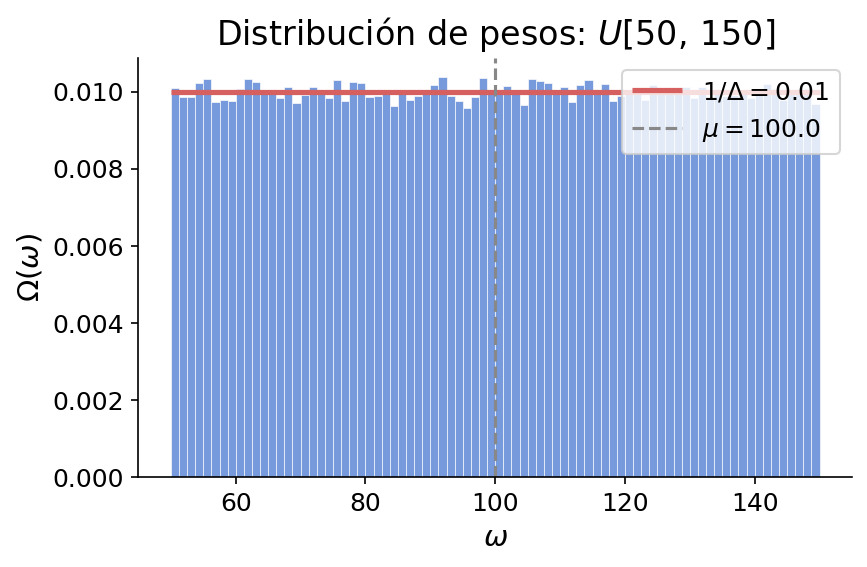

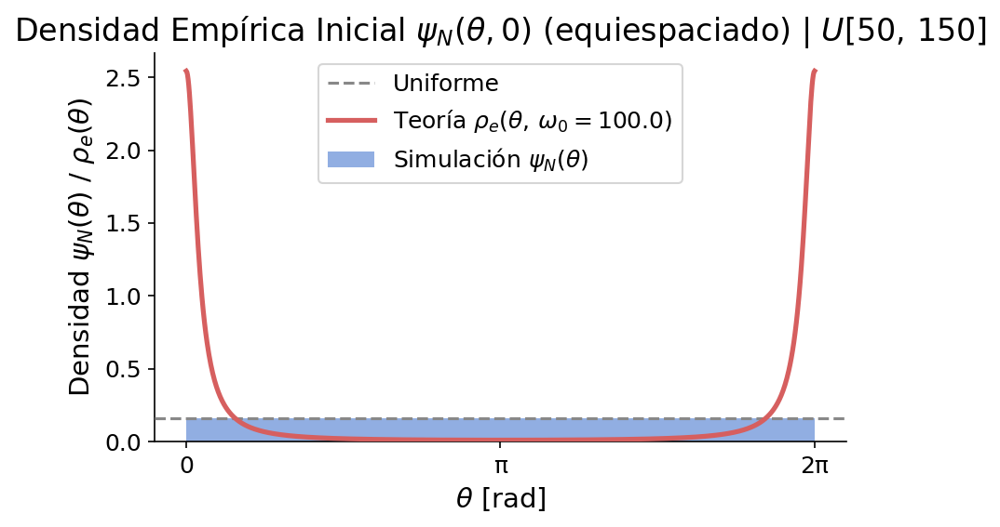

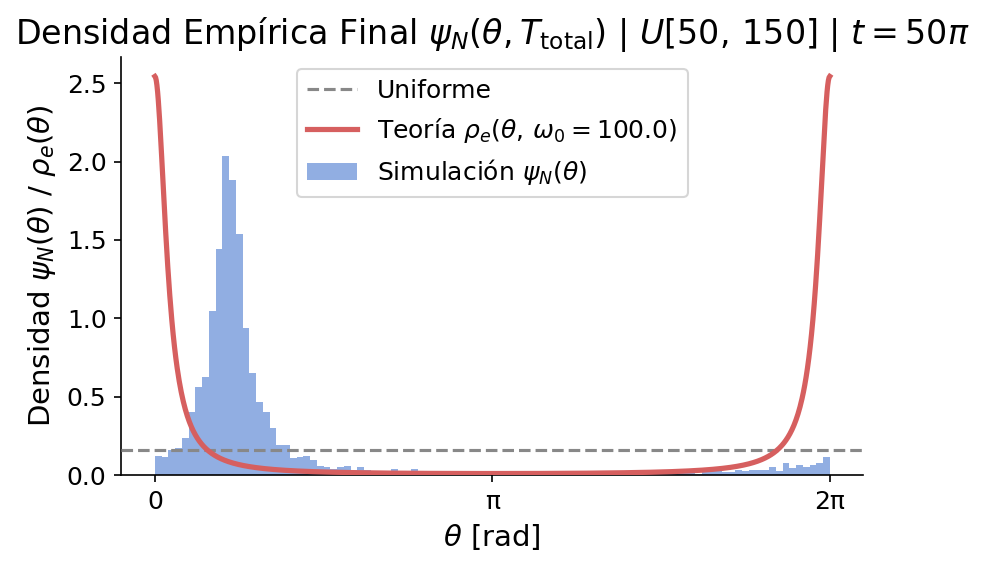

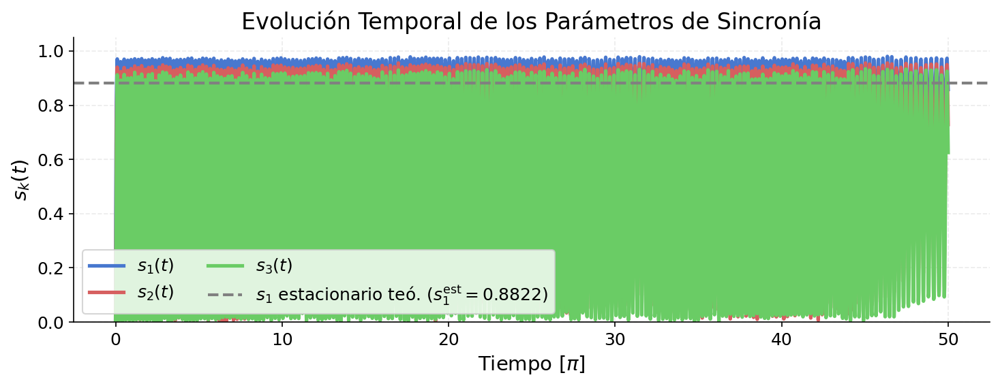

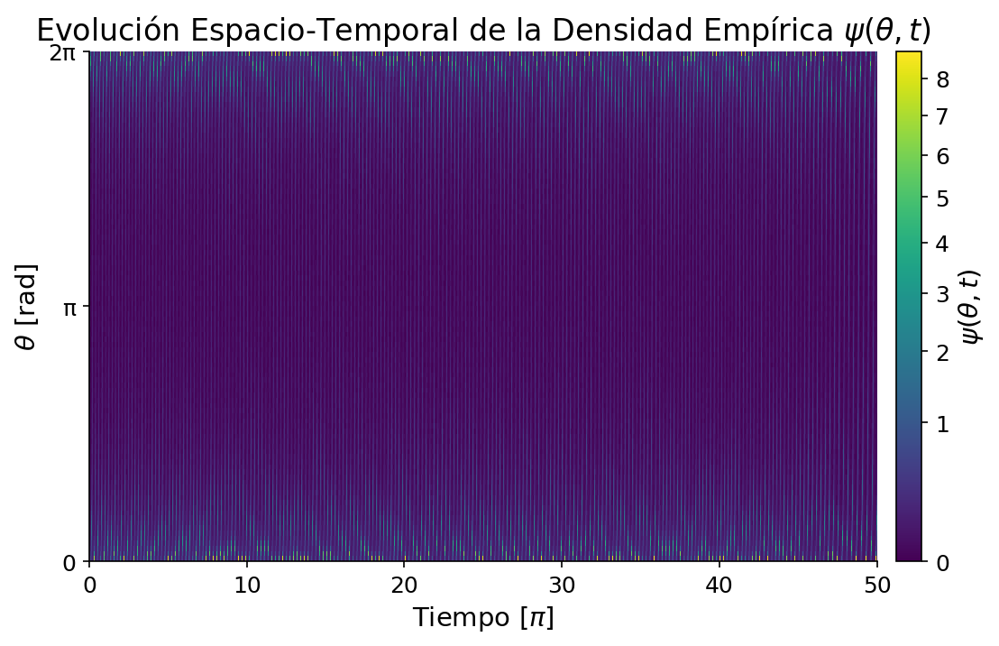

,Pico,ν / π,ν,T / π,T = 2π/ν,P(ν),P / P_dom,Dominante
0,1,2.711097,8.517161,0.234820,0.737709,0.002901,1.000000,Sí
1,2,2.571087,8.077308,0.247607,0.777881,0.002276,0.784592,
2,3,2.634728,8.277241,0.241626,0.759092,0.001567,0.540188,
3,4,2.774737,8.717094,0.229434,0.720789,0.000901,0.310783,
4,5,2.736553,8.597134,0.232636,0.730846,0.000848,0.292323,
5,6,2.660184,8.357214,0.239314,0.751828,0.000737,0.253991,
6,7,2.800194,8.797068,0.227348,0.714236,0.000616,0.212410,
7,8,2.609271,8.197268,0.243984,0.766498,0.000518,0.178605,
8,9,2.889291,9.076974,0.220338,0.692211,0.000445,0.153484,
9,10,2.494718,7.837388,0.255187,0.801694,0.000401,0.138258,


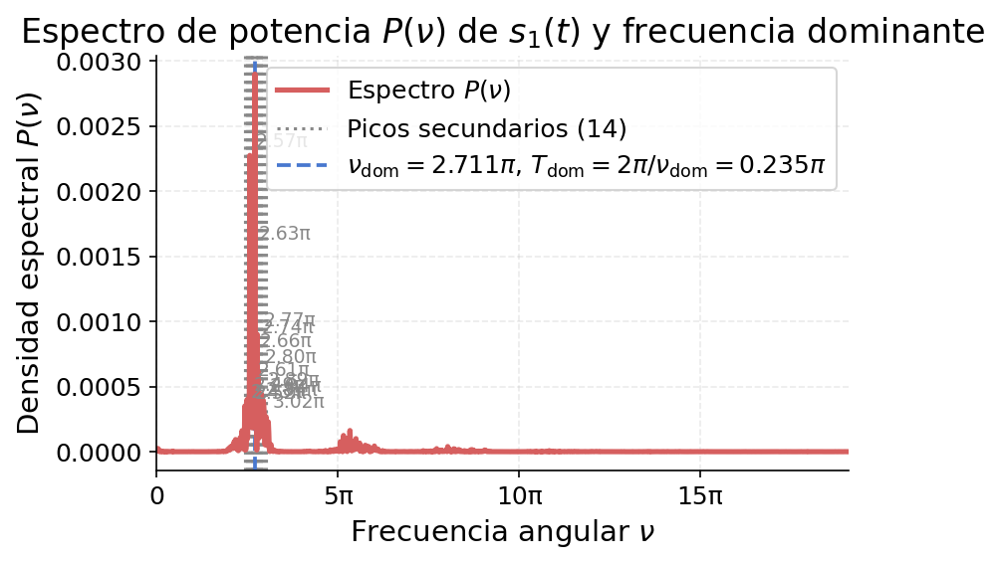

s₁ final = 0.8580 | s₁ᵉˢᵗ = 0.8822 | ν_dom = 2.7111π | T_dom = 2π/ν_dom = 0.2348π

  RESUMEN DEL BARRIDO B (QIF + UNIFORME): SINCRONÍA Y ESPECTRO P(ν)


,μ (Acoplamiento),s₁ final,s₁ᵉˢᵗ (teórico),ν_dom / π,T_dom / π,N° picos
0,0.01,0.000052,0.000398,0.636408,1.000333,3
1,0.10,0.004675,0.003979,0.636408,1.000333,3
2,1.00,0.025071,0.039726,0.661864,0.961859,2
3,10.00,0.279110,0.349332,0.980068,0.649567,2
4,100.00,0.857959,0.882201,2.711097,0.234820,15


In [63]:
#  BARRIDO B | Modelo QIF — Distribución Uniforme (Δ = μ_ω)

# 1. Configuración de parámetros y reutilización de la grilla de barrido
N              = 5000
I0             = 1.0
T_total        = 50 * np.pi
T_hist         = np.pi / 60
n_bins         = 100
omegas_barrido = [0.01, 0.1, 1.0, 10.0, 100.0]

# 2. Contenedor de almacenamiento para los resultados del barrido
resultados_B = {}

# 3. Bucle iterativo sobre los acoplamientos medios con fluctuaciones finitas Δ = μ_ω
for mu in omegas_barrido:
    print(f"\n{'='*60}\n  QIF + Uniforme | μ_ω = {mu}, Δ = {mu}\n{'='*60}")

    # Instanciación y verificación gráfica de la distribución con desorden recocido
    sampler, omega_info = make_omega_dist('uniforme', mu=mu, Delta=mu)
    plot_omega_dist(omega_info)

    # Ejecución de la simulación event-driven (genera gráfico único sₖ(t) con s₁ᵉˢᵗ)
    phis_f, tiempos, s_dict, histogramas = simular_QIF(
        N            = N,
        sampler      = sampler,
        omega_info   = omega_info,
        Z_fn         = Z_QIF,
        T            = np.pi,
        rho_e_fn     = rho_e_QIF,
        I0           = I0,
        T_total      = T_total,
        T_hist       = T_hist,
        n_bins       = n_bins,
        cond_inicial = 'equiespaciado',
        mu_w_ref   = mu,
        guardar_figs = True,
    )

    # Espectro P(ν) de s₁(t) (ν = 2πf), picos prominentes y frecuencia dominante ν_dom
    s_1_serie = s_dict[1]
    T_dom, nu_dom, nus, psd, df_picos = calcular_periodo_fft(tiempos, s_1_serie)
    s1_est = calcular_s1_estacionario(rho_e_QIF, mu, I0)

    # Tabla de picos y espectro P(ν) con ν en múltiplos de π (picos con líneas punteadas)
    display(df_picos)
    plot_espectro_fft(nus, psd, nu_dom, T_dom, df_picos=df_picos, fname=f'espectro_fft_QIF_unif_mu_{mu}.png')

    # Persistencia de resultados con métricas espectrales
    resultados_B[mu] = dict(
        s_dict   = s_dict,
        tiempos  = tiempos,
        s1_est   = s1_est,
        nu_dom   = nu_dom,
        T_dom    = T_dom,
        nus      = nus,
        psd      = psd,
        picos    = df_picos,
    )

    print(f"s₁ final = {s_dict[1][-1]:.4f} | s₁ᵉˢᵗ = {s1_est:.4f} | ν_dom = {fmt_mult_pi(nu_dom, 4)} | T_dom = 2π/ν_dom = {fmt_mult_pi(T_dom, 4)}")

# 4. Tabla resumen comparativa del barrido paramétrico
tabla_resumen_B = pd.DataFrame([
    {
        'μ_ω [u.v.]': mu,
        's₁ final': float(res['s_dict'][1][-1]),
        's₁ᵉˢᵗ (teórico)': res['s1_est'],
        'ν_dom / π [rad/u.t.]': res['nu_dom'] / np.pi,      # Frecuencia angular dominante en múltiplos de π
        'T_dom / π [u.t.]': res['T_dom'] / np.pi,       # Período dominante T_dom = 2π/ν_dom en múltiplos de π
        'N° picos': len(res['picos']),
    }
    for mu, res in resultados_B.items()
])

print(f"\n{'='*70}\n  RESUMEN DEL BARRIDO B (QIF + UNIFORME): SINCRONÍA Y ESPECTRO P(ν)\n{'='*70}")
display(tabla_resumen_B)


### Barrido C | Modelo Lineal — Distribución Delta (Acoplamiento Inhibitorio Determinista)

1. **¿Qué hace esta celda?**  
   Evalúa el comportamiento de la red neuronal con PRC lineal $Z(\phi) = \phi/(2\pi)$ bajo acoplamientos puramente inhibitorios deterministas $\mu_\omega < 0$, cuantificando la emergencia de ritmos colectivos y extrayendo su período característico vía FFT.

2. **¿Cómo lo hace?**  
   Itera sobre la grilla $\mu_\omega \in \{-0.01, -0.1, -1.0, -10.0, -100.0\}$. Para cada paso:
   - Simula la red con `simular_QIF` utilizando $Z_{\text{lineal}}$ y $\rho_{e,\text{lineal}}$.
   - Ejecuta `calcular_periodo_fft` sobre la serie temporal $s_1(t)$.
   - Grafica el espectro de potencia de Fourier con `plot_espectro_fft`.
   - Compila las series y parámetros en `resultados_C` y genera la tabla resumen del barrido.

3. **¿Qué devuelve o cuál es su resultado/salida?**  
   Genera las 4 figuras diagnósticas y el espectro FFT por cada nivel inhibitorio, guarda los resultados en `resultados_C` y despliega la tabla comparativa de sincronía y período colectivo.



  Lineal + Delta | μ = -0.01


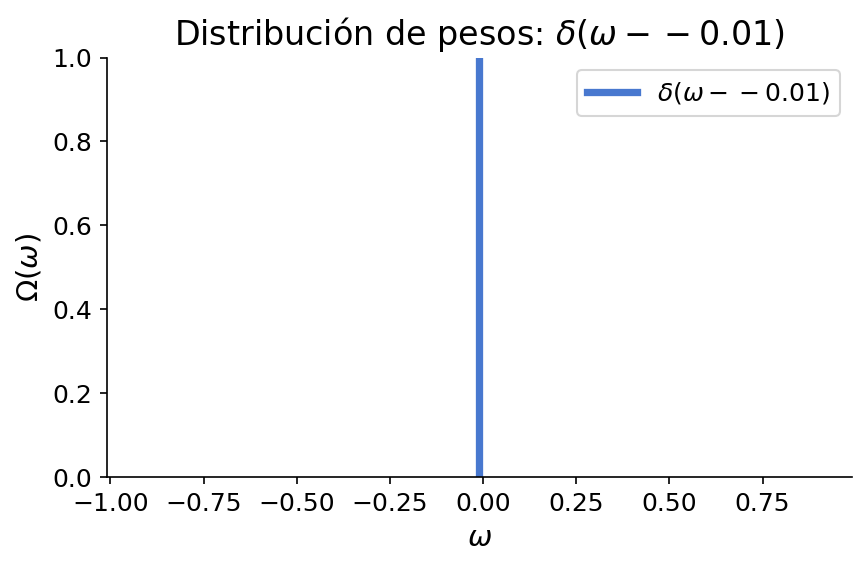

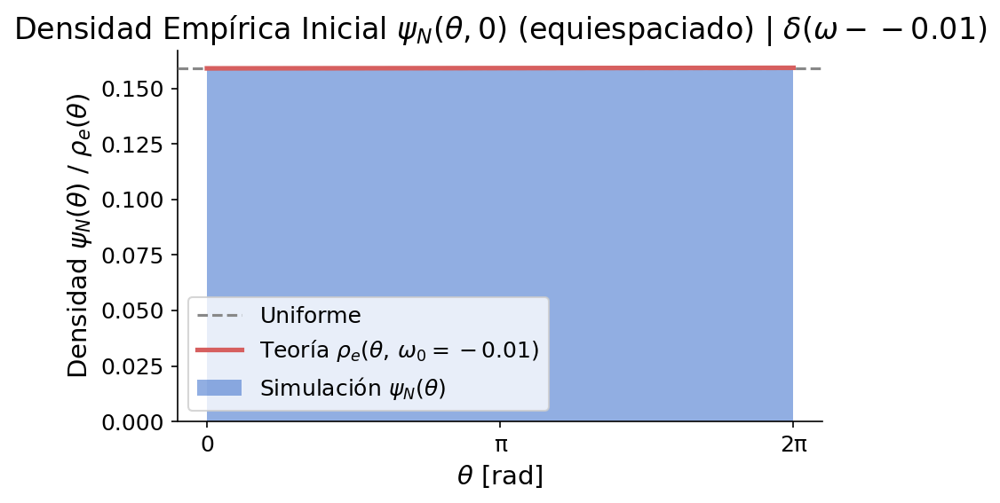

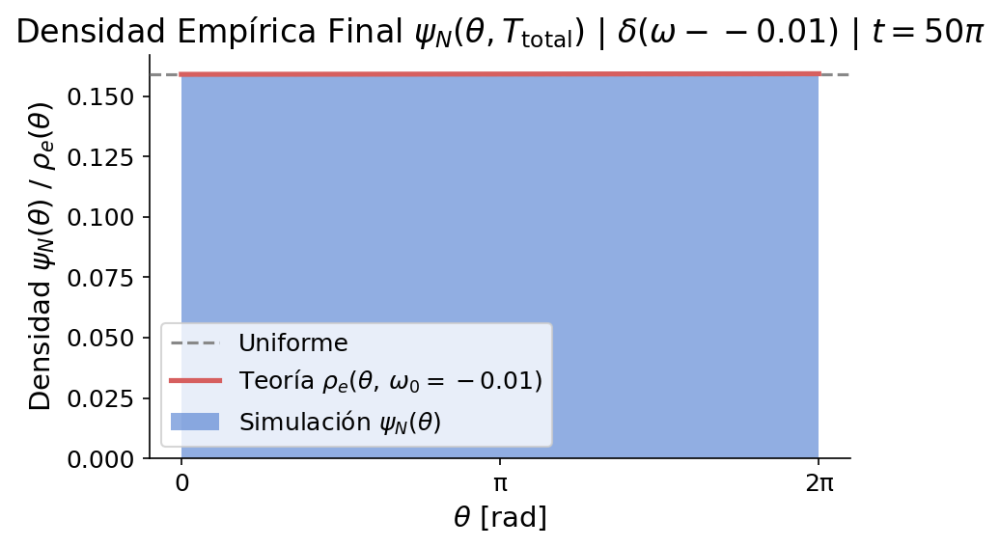

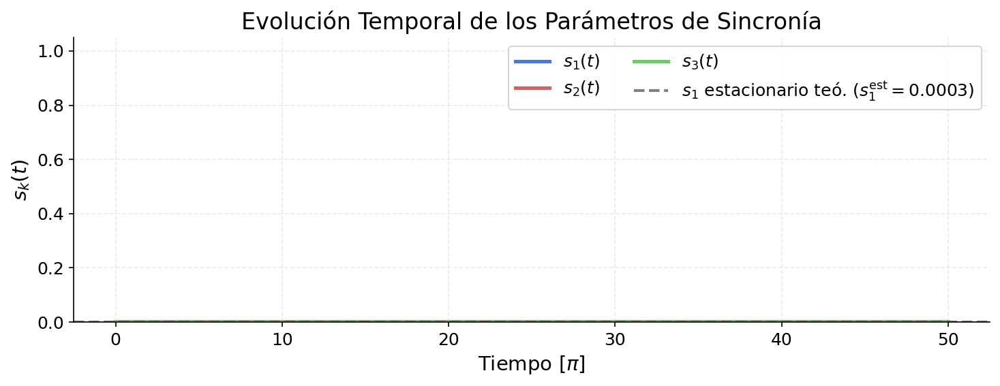

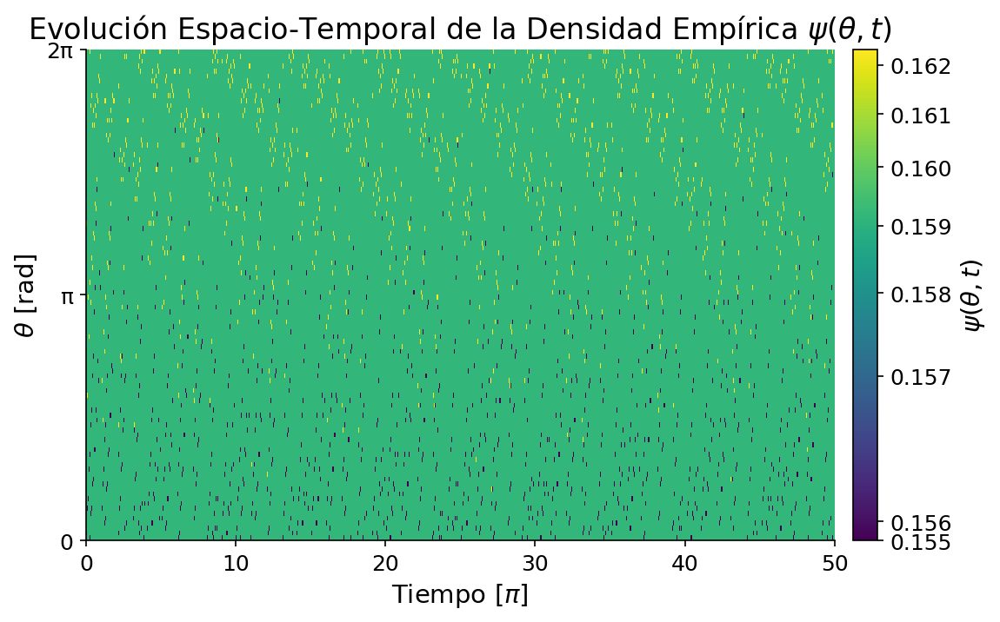

,Pico,ν / π,ν,T / π,T = 2π/ν,P(ν),P / P_dom,Dominante
0,1,0.636408,1.999334,1.000333,3.142640,1.101581e-08,1.000000,Sí
1,2,1.272815,3.998667,0.500167,1.571320,4.319824e-10,0.039215,
2,3,1.909223,5.998001,0.333444,1.047547,7.711478e-11,0.007000,


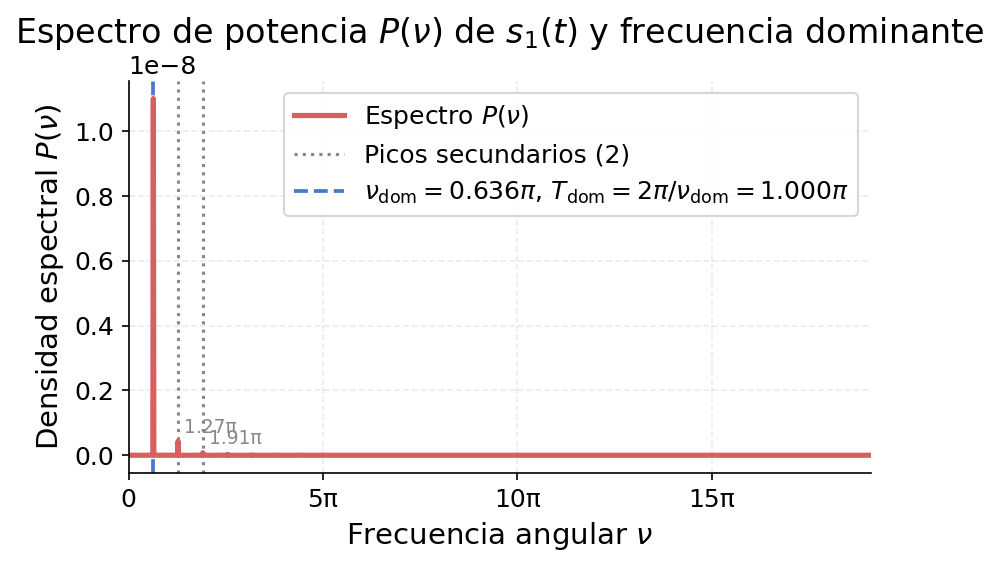

s₁ final = 0.0001 | s₁ᵉˢᵗ = 0.0003 | ν_dom = 0.6364π | T_dom = 2π/ν_dom = 1.0003π

  Lineal + Delta | μ = -0.1


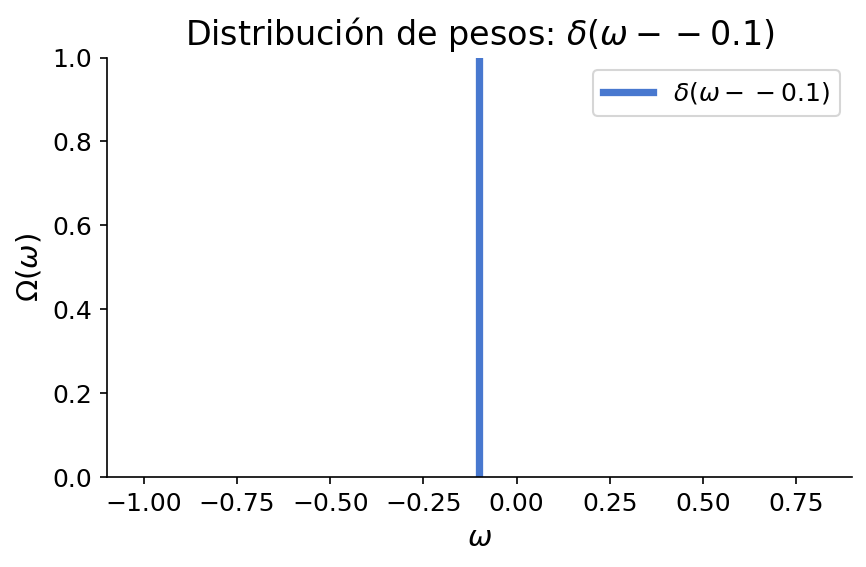

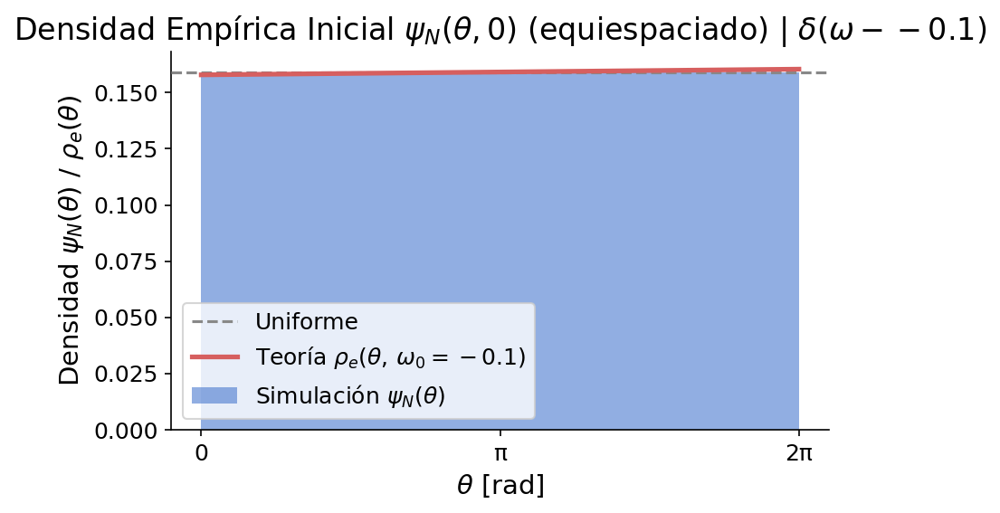

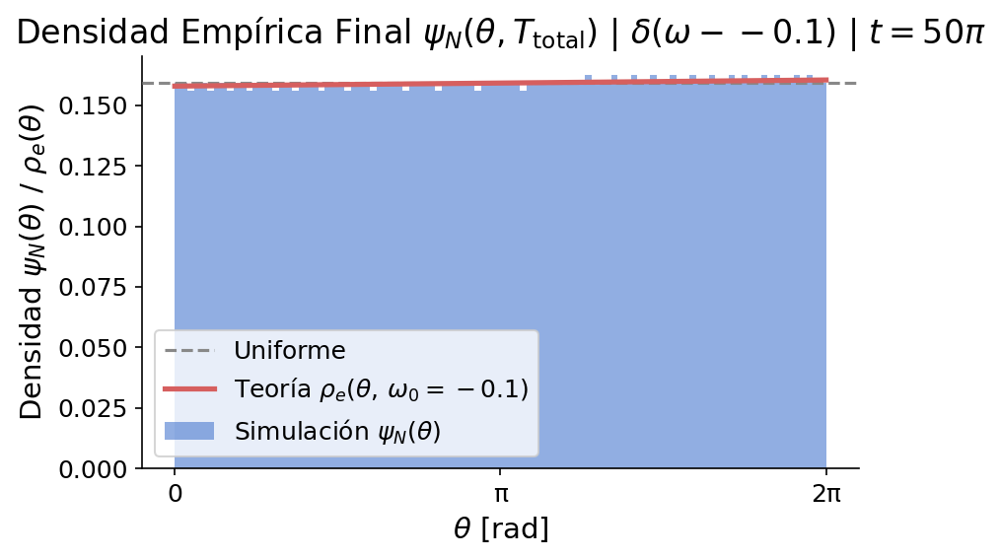

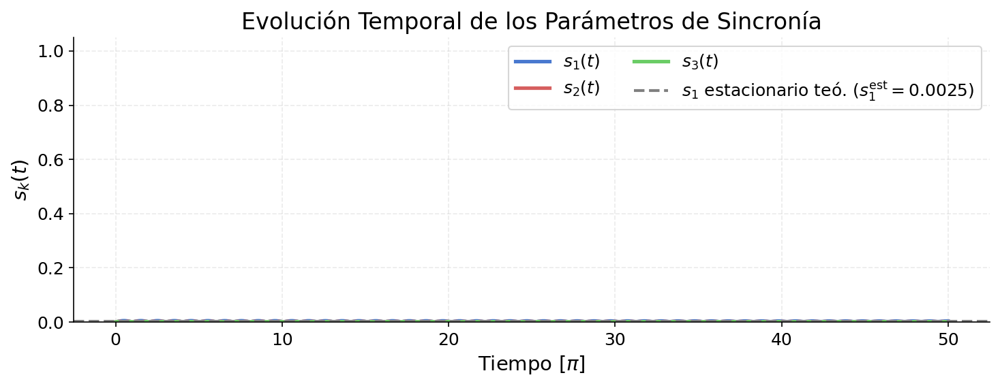

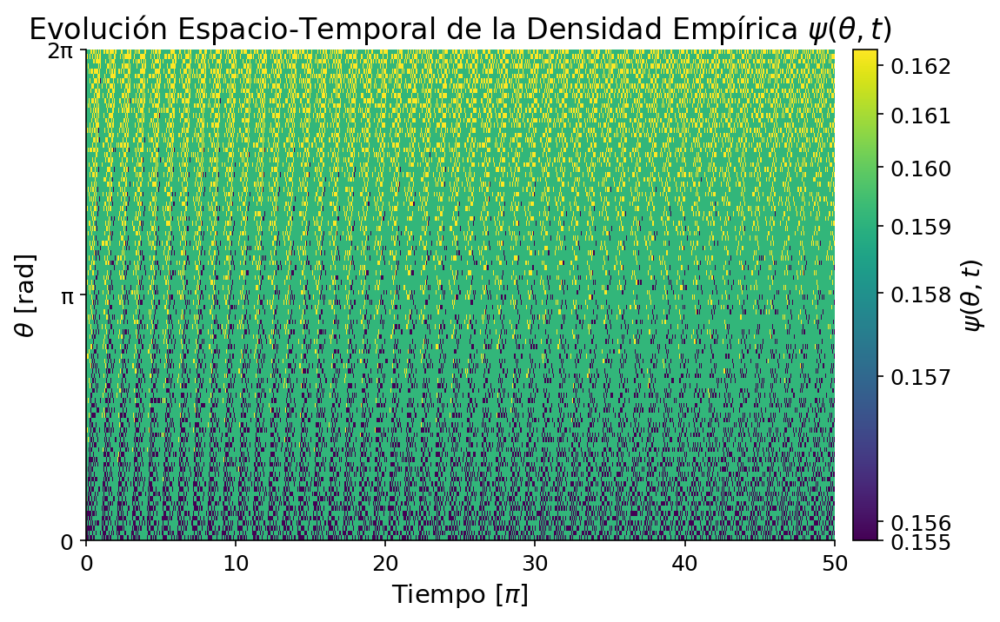

,Pico,ν / π,ν,T / π,T = 2π/ν,P(ν),P / P_dom,Dominante
0,1,0.636408,1.999334,1.000333,3.142640,4.042456e-07,1.000000,Sí
1,2,1.260087,3.958680,0.505219,1.587192,1.409718e-08,0.034873,
2,3,1.896495,5.958014,0.335682,1.054577,2.169015e-09,0.005366,


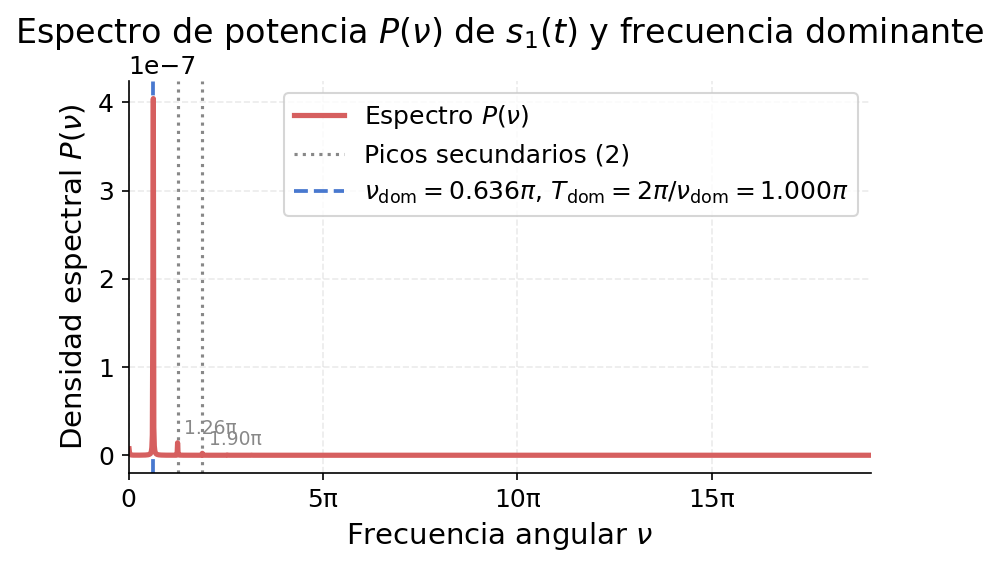

s₁ final = 0.0035 | s₁ᵉˢᵗ = 0.0025 | ν_dom = 0.6364π | T_dom = 2π/ν_dom = 1.0003π

  Lineal + Delta | μ = -1.0


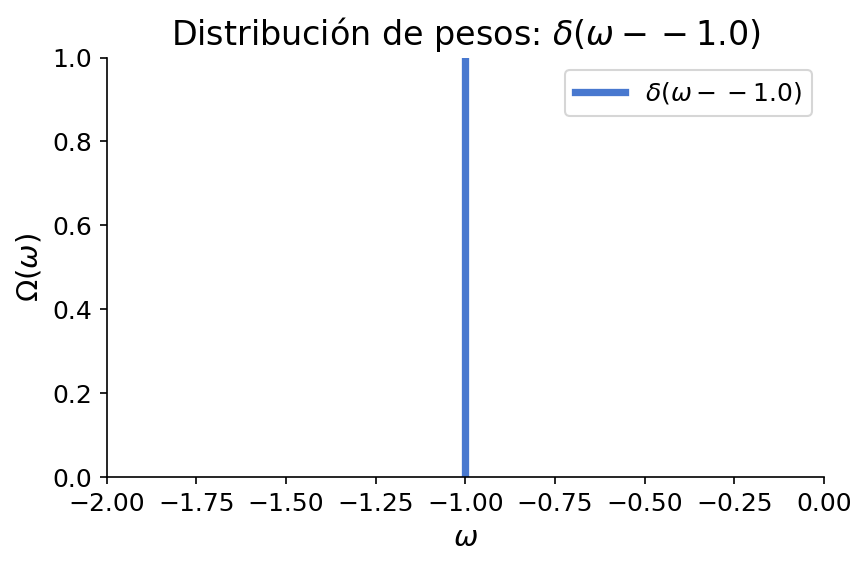

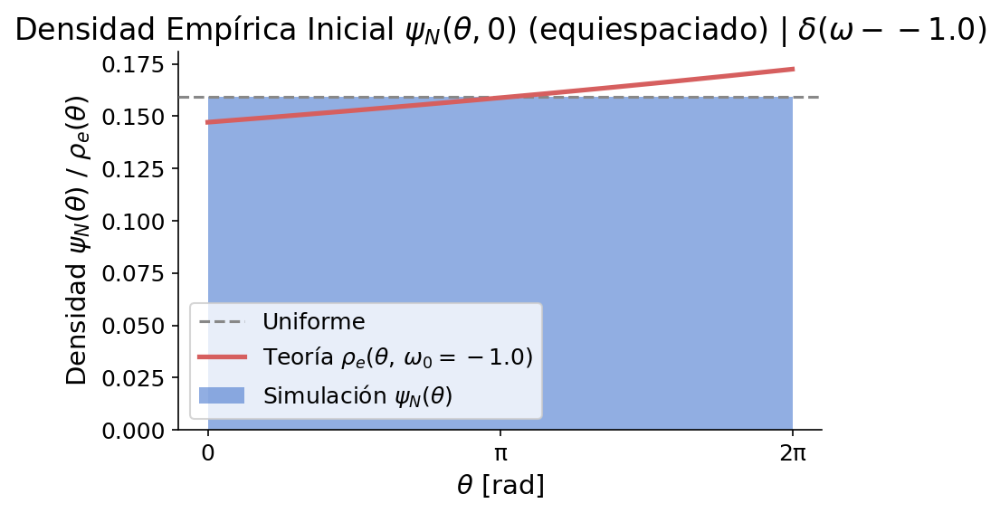

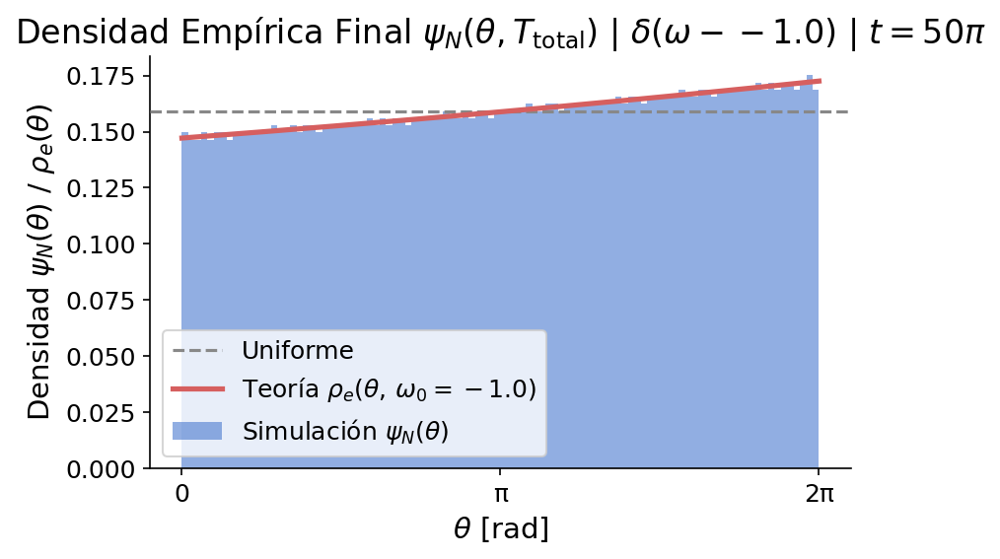

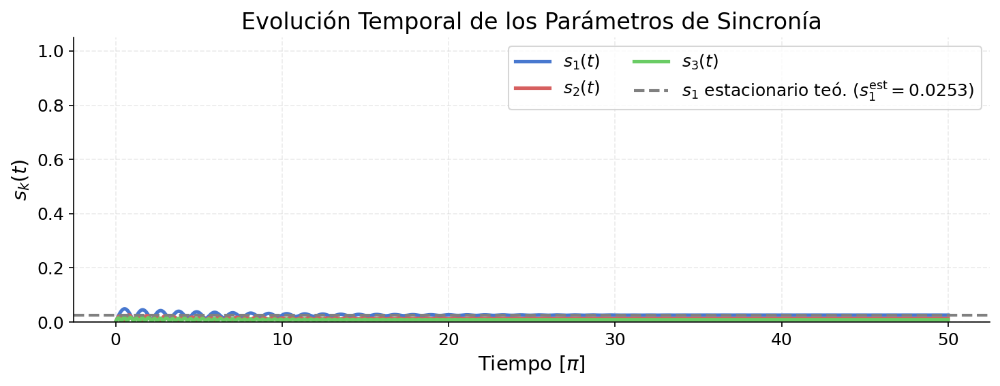

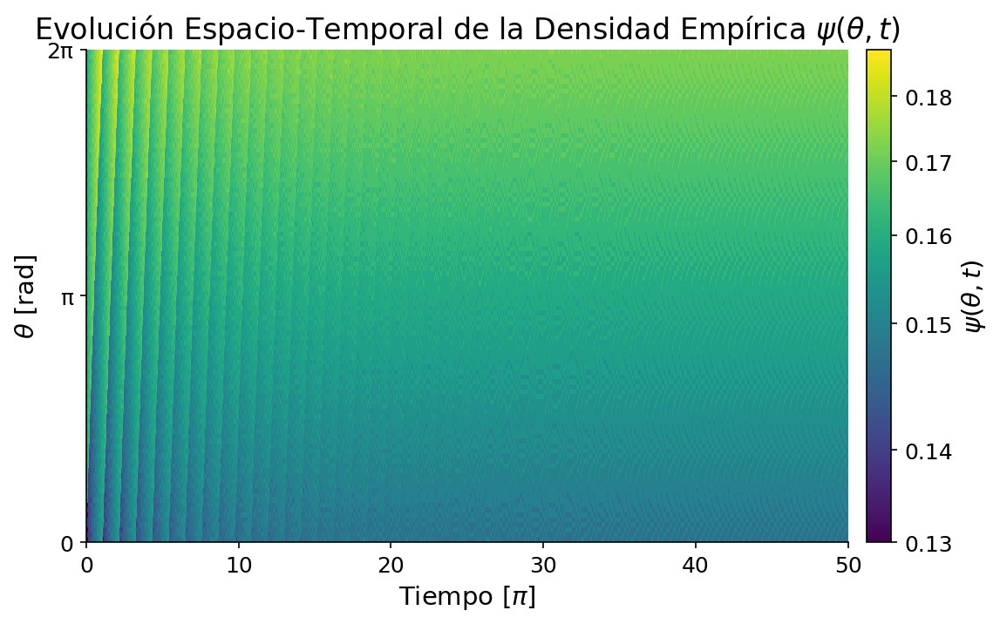

,Pico,ν / π,ν,T / π,T = 2π/ν,P(ν),P / P_dom,Dominante
0,1,0.585495,1.839387,1.087319,3.415913,2.609083e-06,1.000000,Sí
1,2,1.183718,3.718760,0.537814,1.689591,3.818020e-08,0.014634,


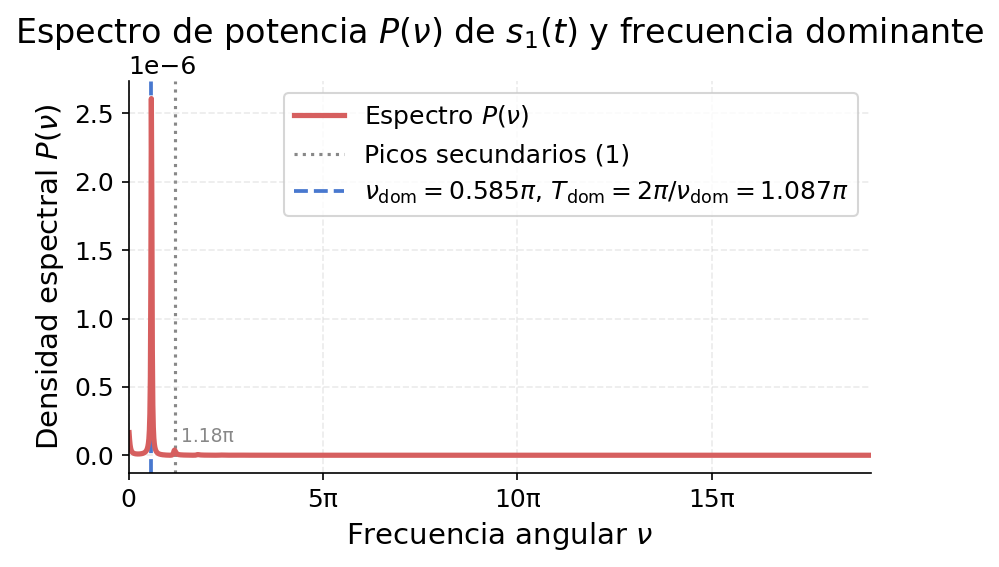

s₁ final = 0.0253 | s₁ᵉˢᵗ = 0.0253 | ν_dom = 0.5855π | T_dom = 2π/ν_dom = 1.0873π

  Lineal + Delta | μ = -10.0


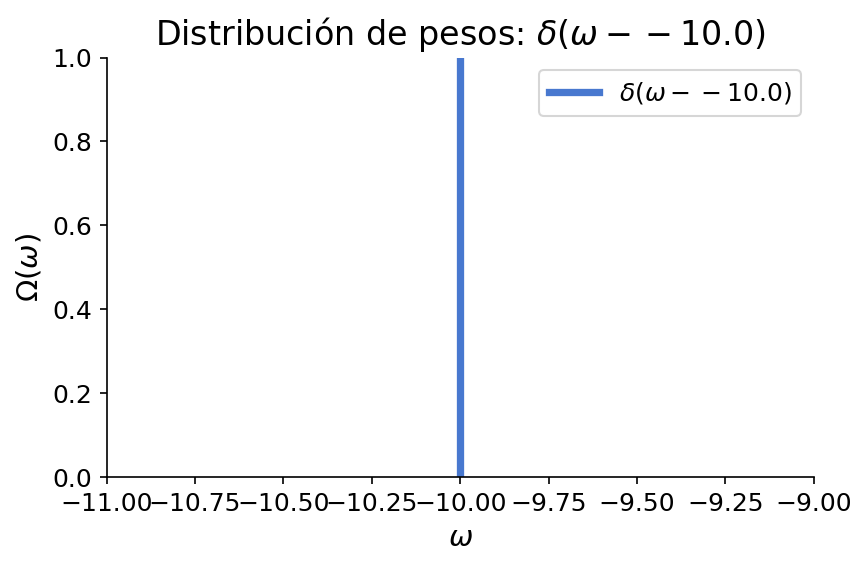

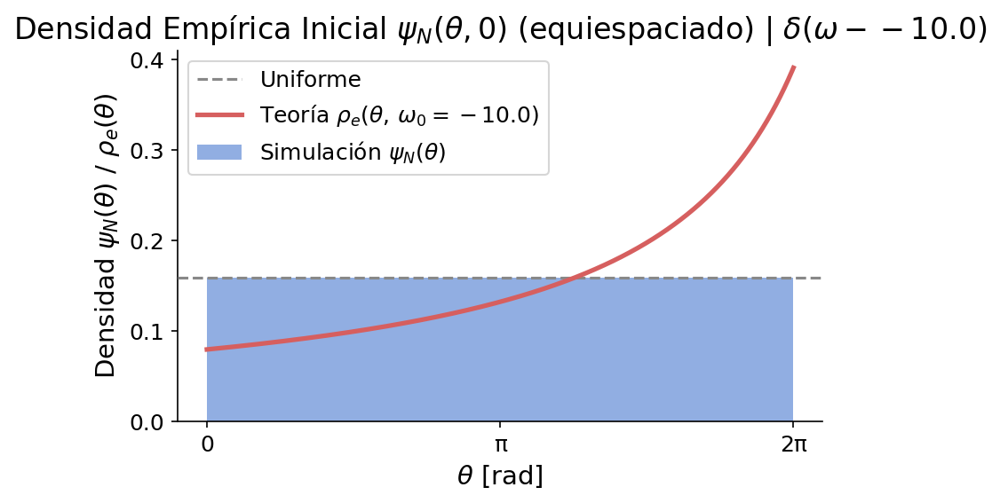

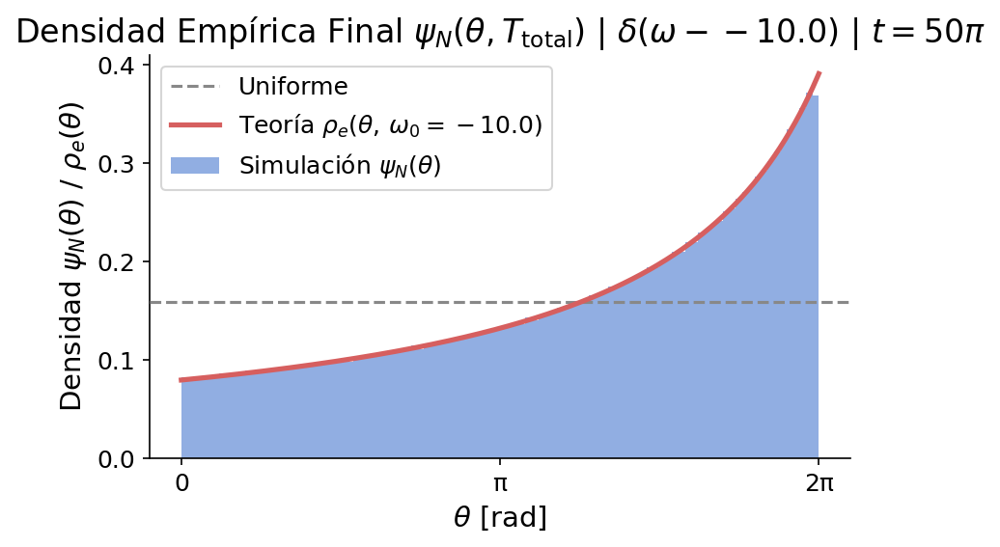

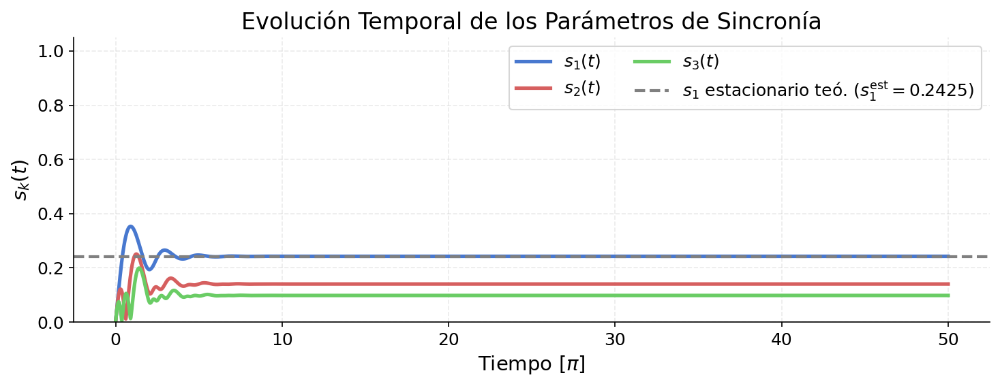

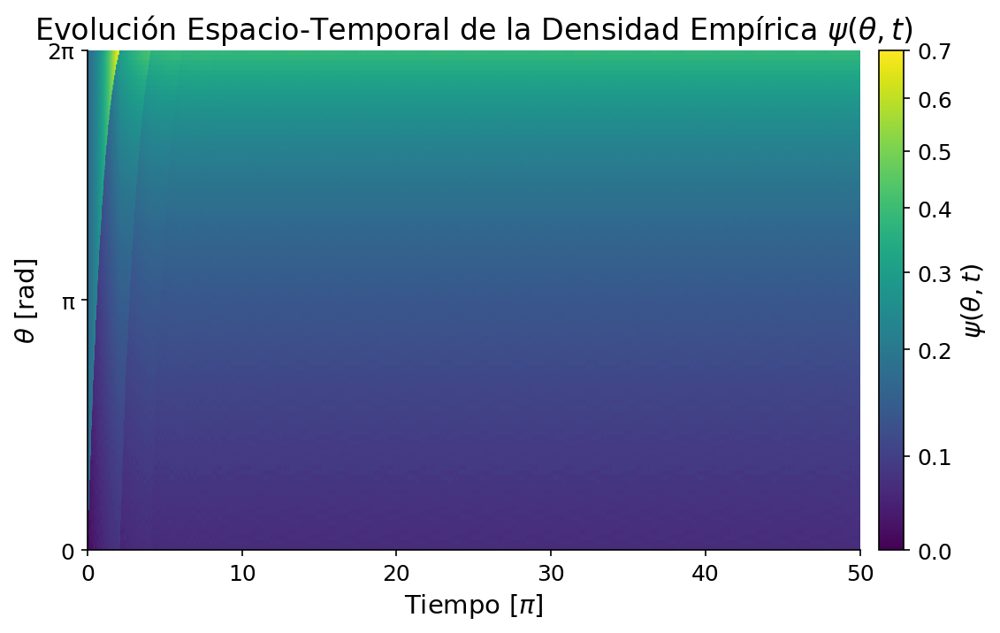

,Pico,ν / π,ν,T / π,T = 2π/ν,P(ν),P / P_dom,Dominante
0,1,0.318204,0.999667,2.000667,6.28528,0.000009,1.0,Sí


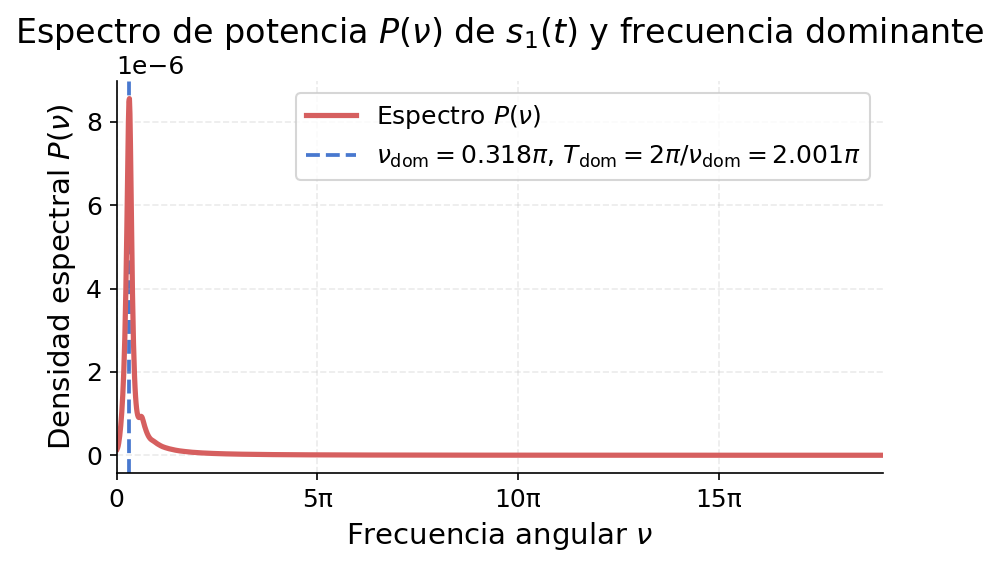

s₁ final = 0.2426 | s₁ᵉˢᵗ = 0.2425 | ν_dom = 0.3182π | T_dom = 2π/ν_dom = 2.0007π

  Lineal + Delta | μ = -100.0


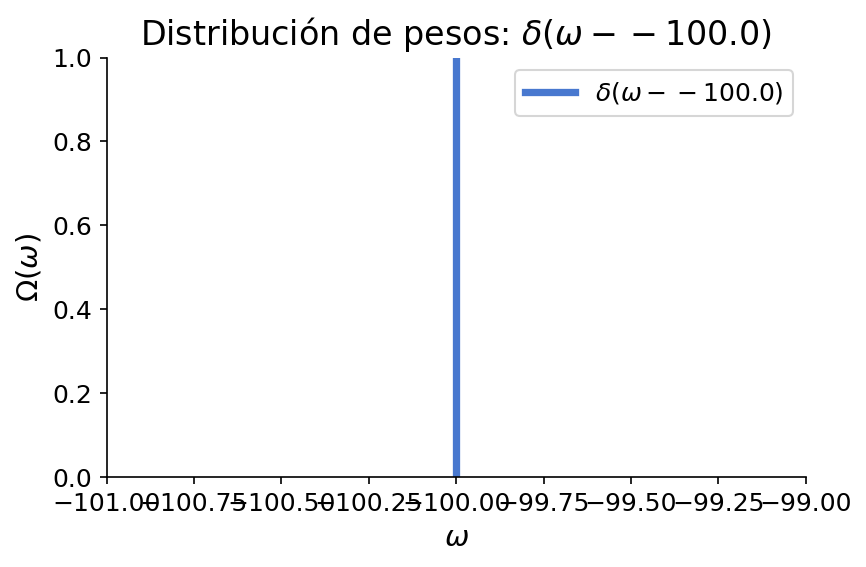

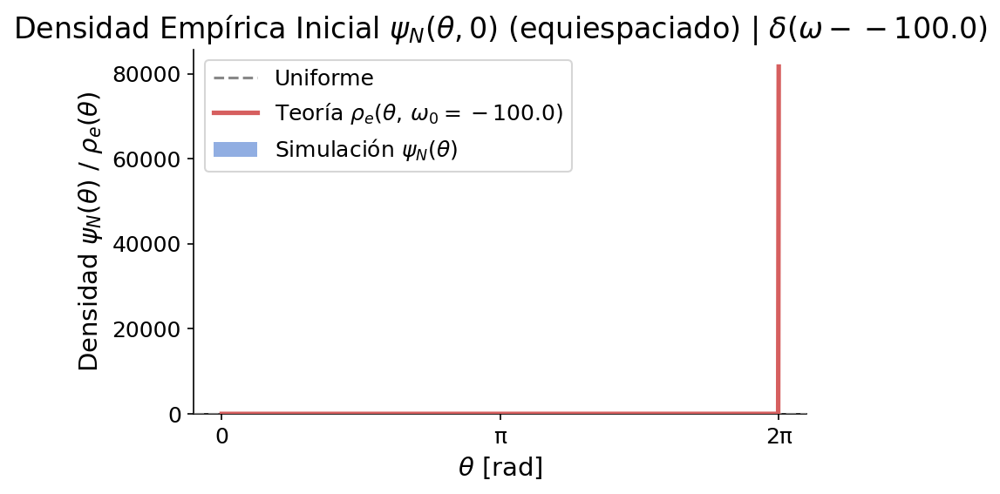

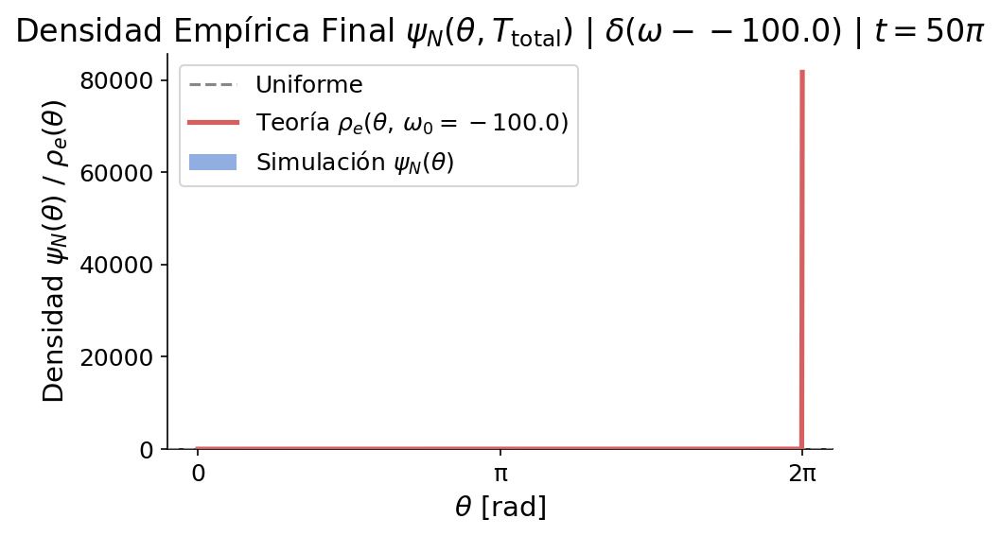

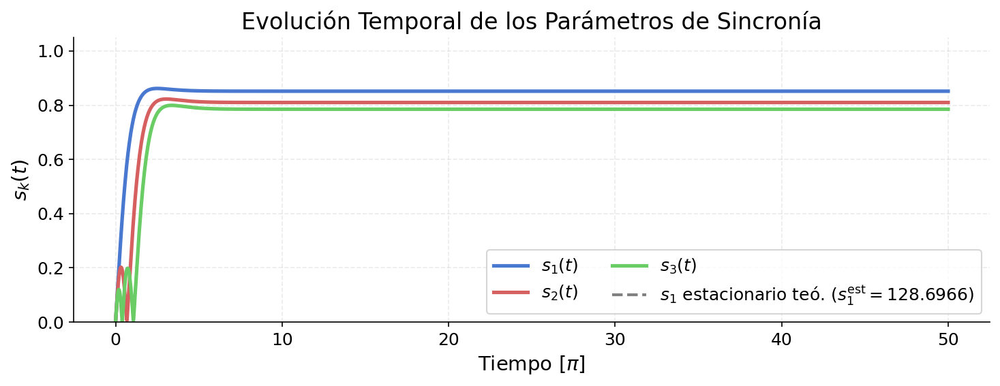

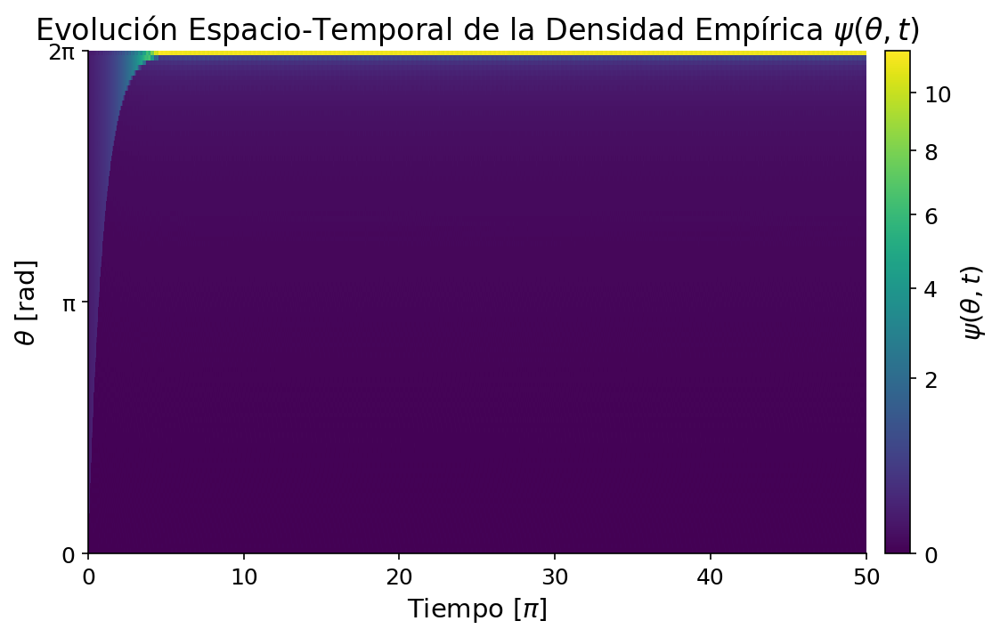

,Pico,ν / π,ν,T / π,T = 2π/ν,P(ν),P / P_dom,Dominante
0,1,0.063641,0.199933,10.003333,31.426399,0.000084,1.0,Sí


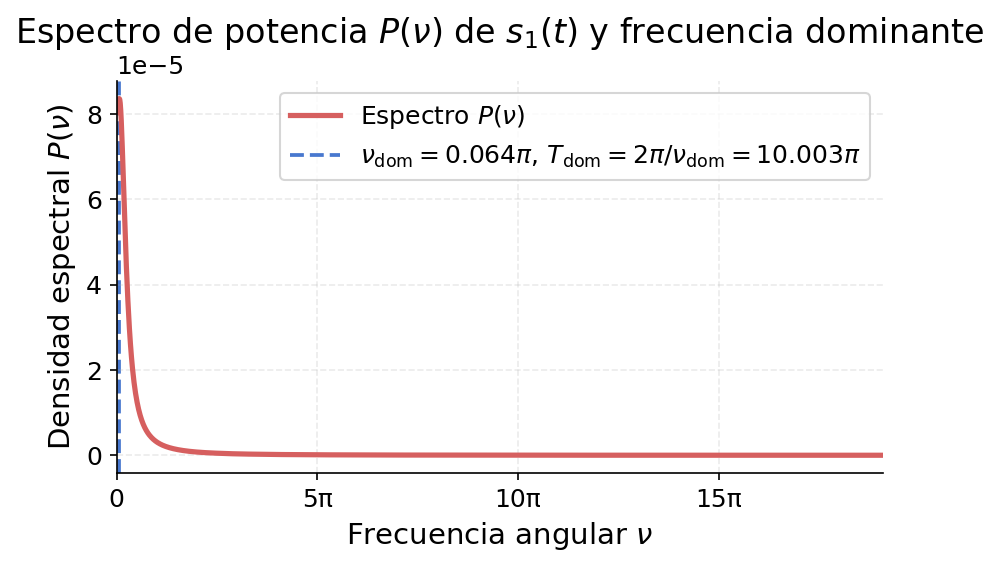

s₁ final = 0.8517 | s₁ᵉˢᵗ = 128.6966 | ν_dom = 0.0636π | T_dom = 2π/ν_dom = 10.0033π

  RESUMEN DEL BARRIDO C (LINEAL + DELTA): SINCRONÍA Y ESPECTRO P(ν)


,μ (Acoplamiento),s₁ final,s₁ᵉˢᵗ (teórico),ν_dom / π,T_dom / π,N° picos
0,-0.01,0.000064,0.000253,0.636408,1.000333,3
1,-0.10,0.003519,0.002533,0.636408,1.000333,3
2,-1.00,0.025316,0.025319,0.585495,1.087319,2
3,-10.00,0.242564,0.242528,0.318204,2.000667,1
4,-100.00,0.851740,128.696623,0.063641,10.003333,1


In [64]:
#  BARRIDO C | Modelo Lineal — Distribución Delta

# 1. Configuración de parámetros y grilla de barrido inhibitorio
N              = 5000
I0             = 1.0
T_total        = 50 * np.pi
T_hist         = np.pi / 60
n_bins         = 100
omegas_barrido = [-0.01, -0.1, -1.0, -10.0, -100.0]

# 2. Contenedor de almacenamiento para los resultados del barrido
resultados_C = {}

# 3. Bucle iterativo sobre intensidades inhibitorias μ_ω < 0
for mu in omegas_barrido:
    print(f"\n{'='*60}\n  Lineal + Delta | μ_ω = {mu}\n{'='*60}")

    # Distribución homogénea determinista inhibitoria
    sampler, omega_info = make_omega_dist('delta', mu=mu)
    plot_omega_dist(omega_info)

    # Ejecución de la dinámica con PRC lineal (genera gráfico único sₖ(t) con s₁ᵉˢᵗ)
    phis_f, tiempos, s_dict, histogramas = simular_QIF(
        N            = N,
        sampler      = sampler,
        omega_info   = omega_info,
        Z_fn         = Z_lineal,
        T            = np.pi,
        rho_e_fn     = rho_e_lineal,
        I0           = I0,
        T_total      = T_total,
        T_hist       = T_hist,
        n_bins       = n_bins,
        cond_inicial = 'equiespaciado',
        mu_w_ref   = mu,
        guardar_figs = True,
    )

    # Espectro P(ν) de s₁(t) (ν = 2πf), picos prominentes y frecuencia dominante ν_dom
    s_1_serie = s_dict[1]
    T_dom, nu_dom, nus, psd, df_picos = calcular_periodo_fft(tiempos, s_1_serie)
    s1_est = calcular_s1_estacionario(rho_e_lineal, mu, I0)

    # Tabla de picos y espectro P(ν) con ν en múltiplos de π (picos con líneas punteadas)
    display(df_picos)
    plot_espectro_fft(nus, psd, nu_dom, T_dom, df_picos=df_picos, fname=f'espectro_fft_lineal_delta_mu_{mu}.png')

    # Persistencia de resultados con métricas espectrales
    resultados_C[mu] = dict(
        s_dict   = s_dict,
        tiempos  = tiempos,
        s1_est   = s1_est,
        nu_dom   = nu_dom,
        T_dom    = T_dom,
        nus      = nus,
        psd      = psd,
        picos    = df_picos,
    )

    print(f"s₁ final = {s_dict[1][-1]:.4f} | s₁ᵉˢᵗ = {s1_est:.4f} | ν_dom = {fmt_mult_pi(nu_dom, 4)} | T_dom = 2π/ν_dom = {fmt_mult_pi(T_dom, 4)}")

# 4. Tabla resumen comparativa del barrido paramétrico
tabla_resumen_C = pd.DataFrame([
    {
        'μ_ω [u.v.]': mu,
        's₁ final': float(res['s_dict'][1][-1]),
        's₁ᵉˢᵗ (teórico)': res['s1_est'],
        'ν_dom / π [rad/u.t.]': res['nu_dom'] / np.pi,      # Frecuencia angular dominante en múltiplos de π
        'T_dom / π [u.t.]': res['T_dom'] / np.pi,       # Período dominante T_dom = 2π/ν_dom en múltiplos de π
        'N° picos': len(res['picos']),
    }
    for mu, res in resultados_C.items()
])

print(f"\n{'='*70}\n  RESUMEN DEL BARRIDO C (LINEAL + DELTA): SINCRONÍA Y ESPECTRO P(ν)\n{'='*70}")
display(tabla_resumen_C)


### Barrido D | Modelo Lineal — Distribución Uniforme (Inhibición Heterogénea $\Delta = |\mu_\omega|$)

1. **¿Qué hace esta celda?**  
   Estudia el modelo neuronal lineal bajo inhibición estocástica con desorden recocido $\omega_i \sim \mathcal{U}[\mu_\omega - \Delta/2, \mu_\omega + \Delta/2]$, midiendo la frecuencia angular colectiva $\nu_{\text{dom}}$ y el período de oscilación $T$ mediante análisis FFT.

2. **¿Cómo lo hace?**  
   Somete la red a intensidades inhibitorias $\mu_\omega \in \{-0.01, -0.1, -1.0, -10.0, -100.0\}$ con dispersión $\Delta = |\mu_\omega|$. Aplica la simulación event-driven, calcula la FFT sobre $s_1(t)$ con `calcular_periodo_fft`, despliega el espectro $P(\nu)$ y almacena los resultados en `resultados_D`.

3. **¿Qué devuelve o cuál es su resultado/salida?**  
   Genera las figuras de evolución temporal y espectros $P(\nu)$ con tabla de picos para cada nivel inhibitorio con ruido, guarda `resultados_D` y presenta la tabla resumen comparativa del barrido.



  Lineal + Uniforme | μ = -0.01, Δ = -0.01


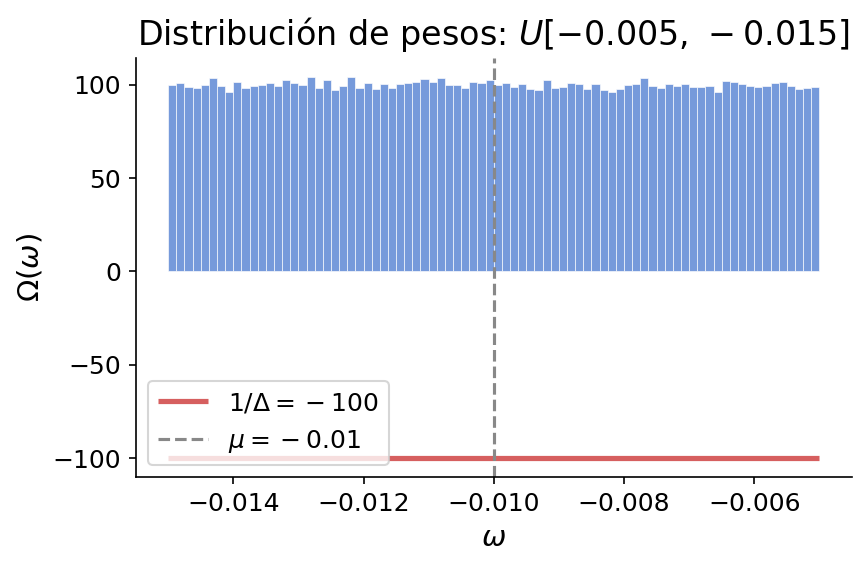

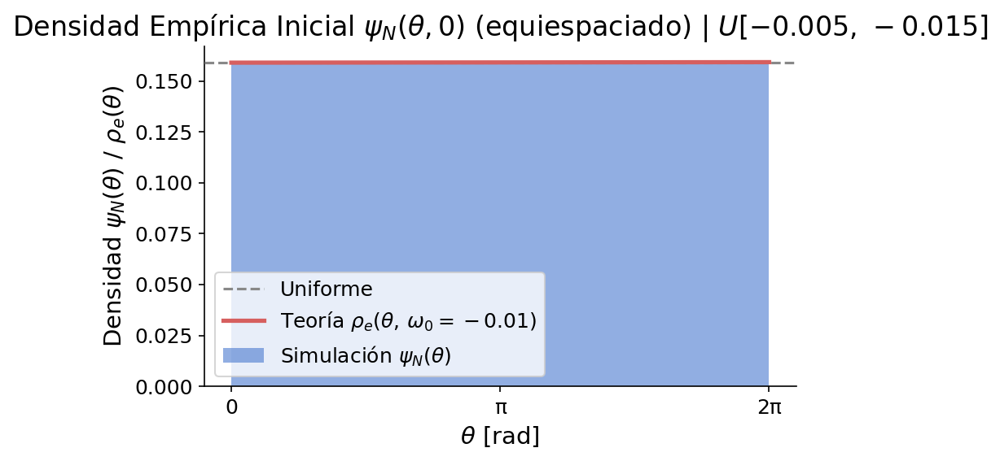

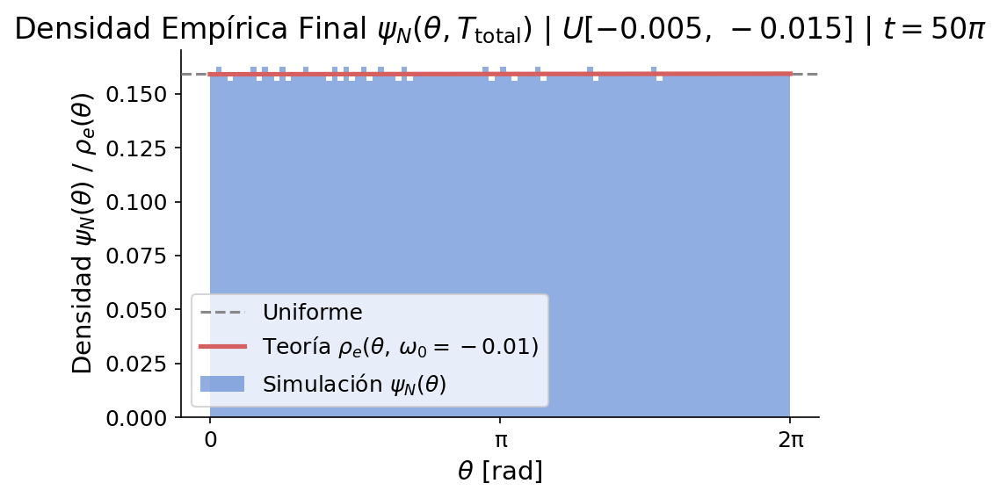

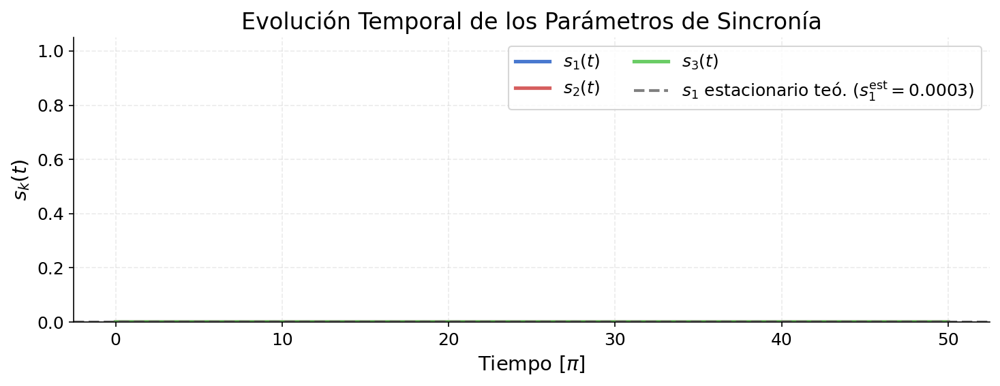

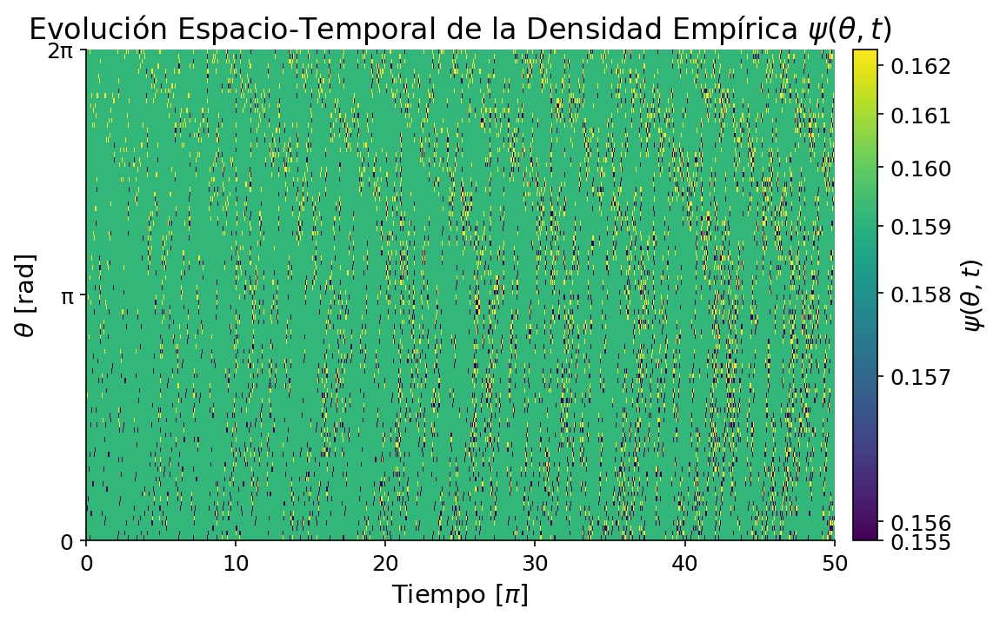

,Pico,ν / π,ν,T / π,T = 2π/ν,P(ν),P / P_dom,Dominante
0,1,0.636408,1.999334,1.000333,3.142640,1.098886e-08,1.000000,Sí
1,2,1.272815,3.998667,0.500167,1.571320,4.299914e-10,0.039130,
2,3,1.909223,5.998001,0.333444,1.047547,7.658080e-11,0.006969,


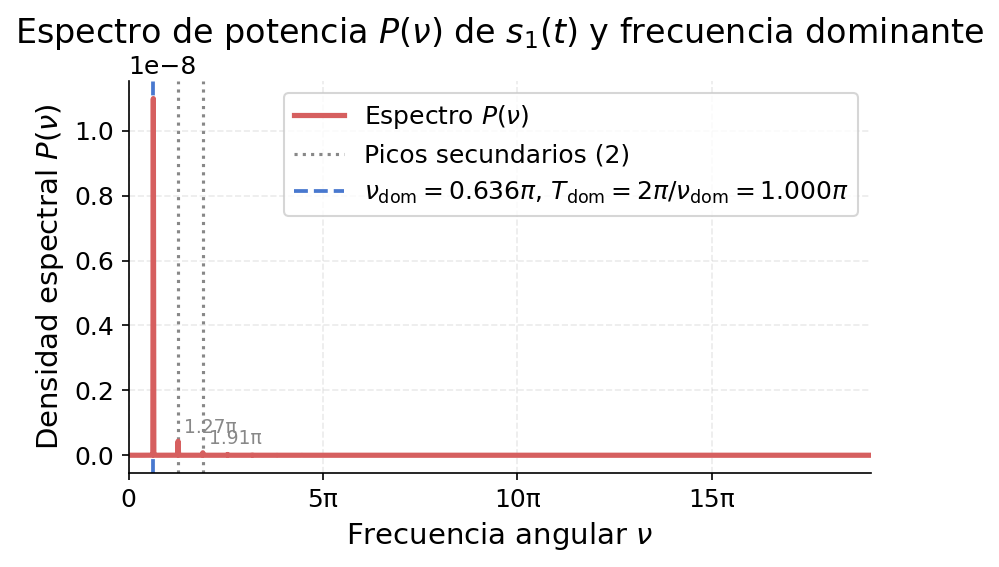

s₁ final = 0.0001 | s₁ᵉˢᵗ = 0.0003 | ν_dom = 0.6364π | T_dom = 2π/ν_dom = 1.0003π

  Lineal + Uniforme | μ = -0.1, Δ = -0.1


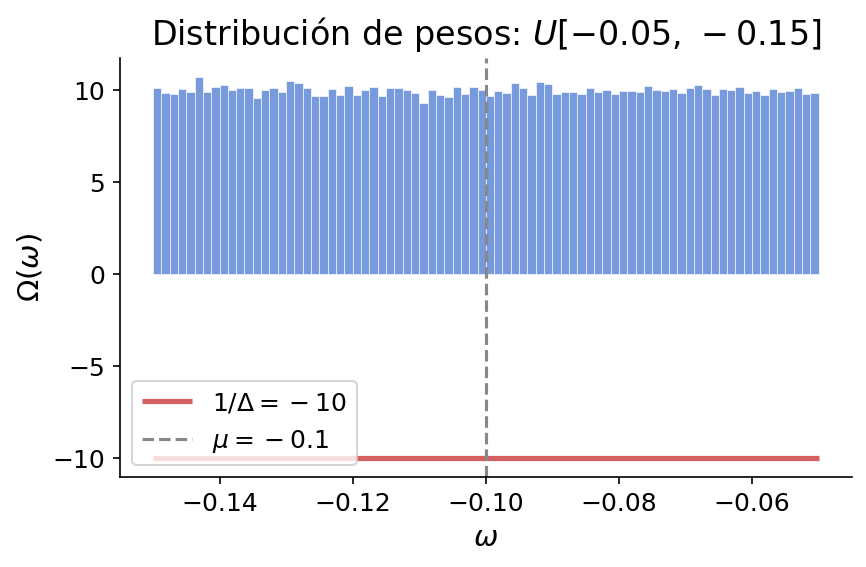

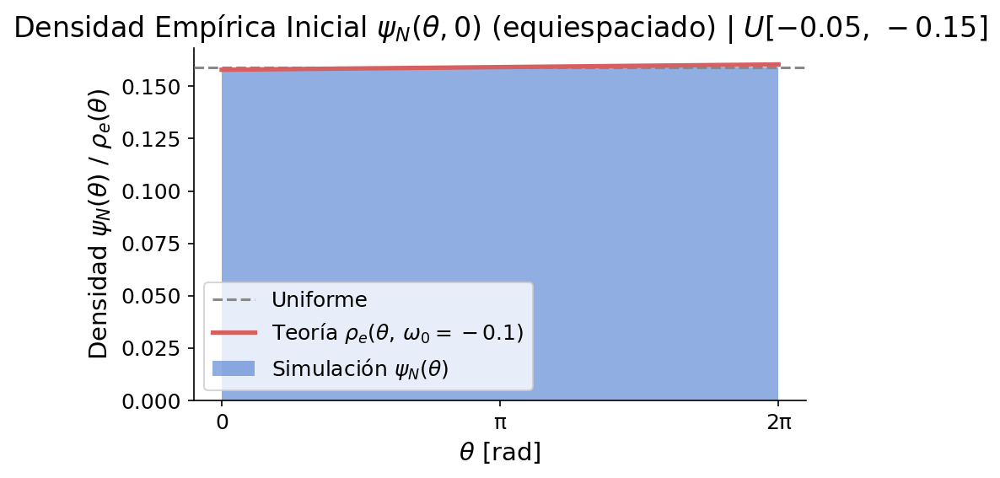

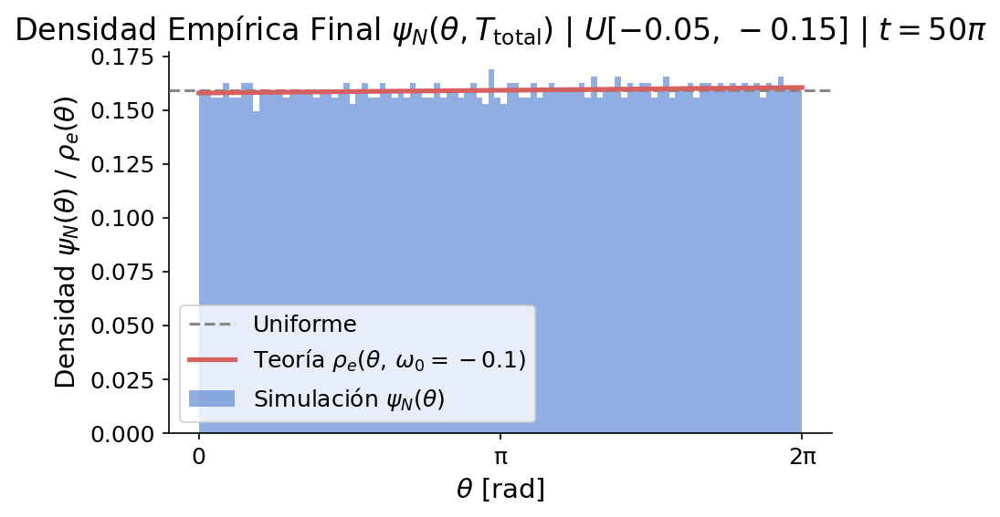

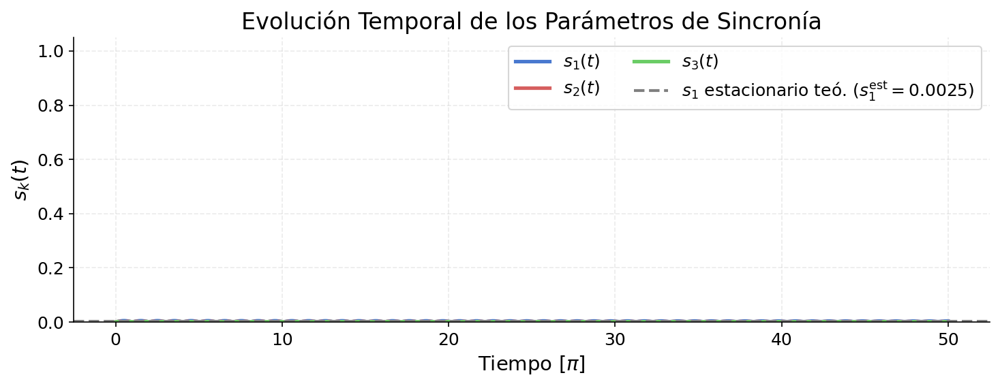

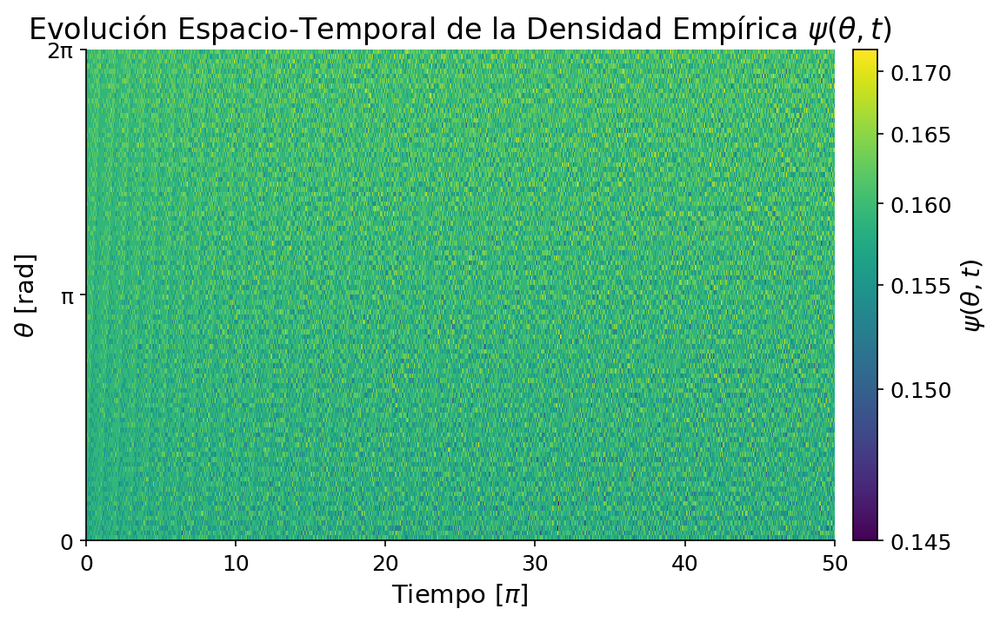

,Pico,ν / π,ν,T / π,T = 2π/ν,P(ν),P / P_dom,Dominante
0,1,0.636408,1.999334,1.000333,3.142640,4.035320e-07,1.000000,Sí
1,2,1.260087,3.958680,0.505219,1.587192,1.407294e-08,0.034874,
2,3,1.896495,5.958014,0.335682,1.054577,2.163351e-09,0.005361,


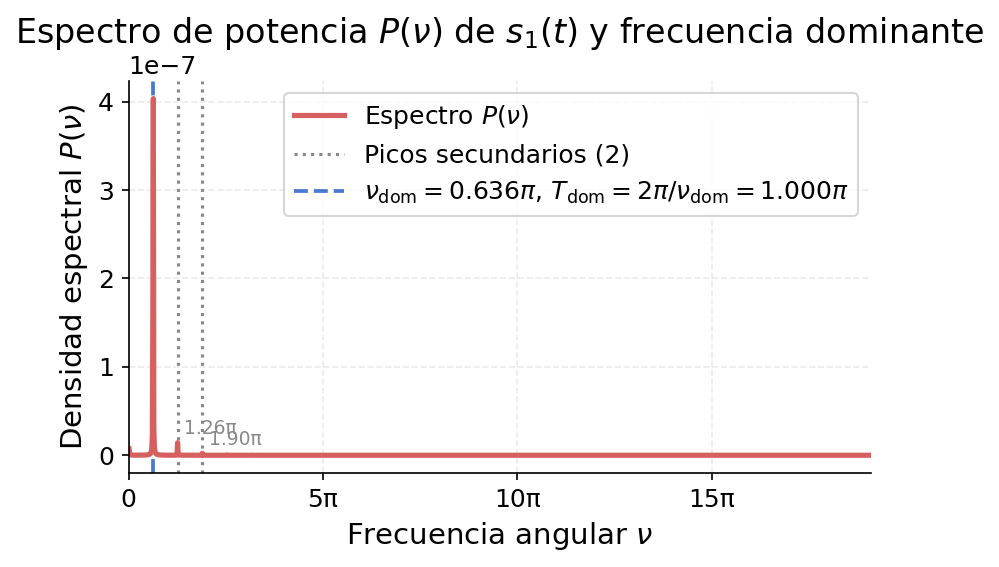

s₁ final = 0.0035 | s₁ᵉˢᵗ = 0.0025 | ν_dom = 0.6364π | T_dom = 2π/ν_dom = 1.0003π

  Lineal + Uniforme | μ = -1.0, Δ = -1.0


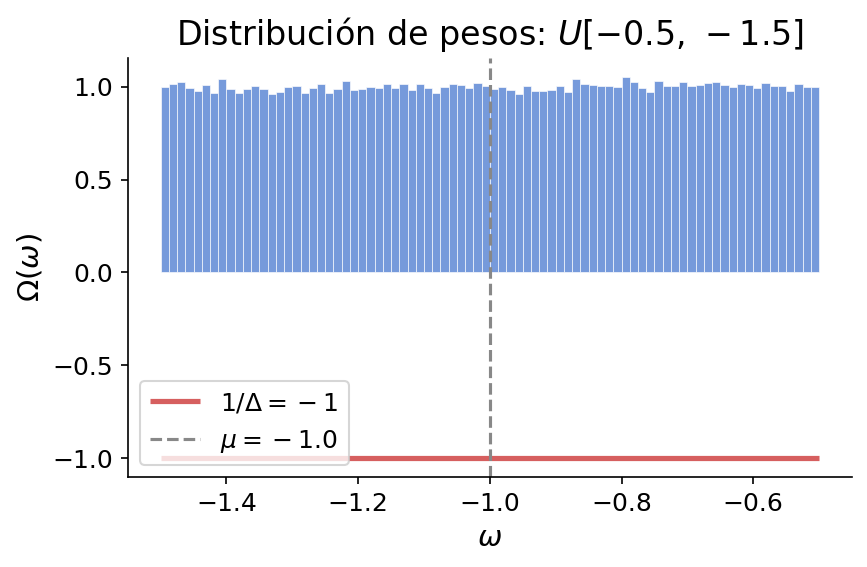

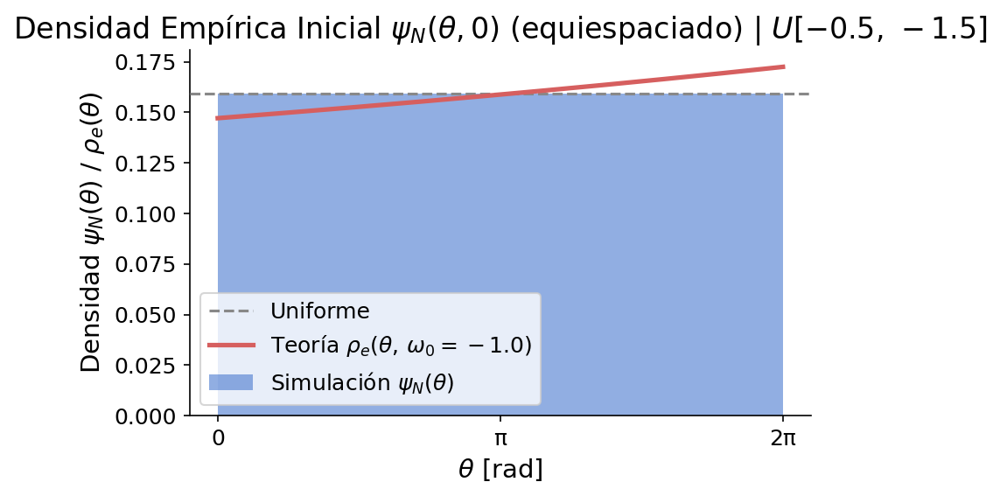

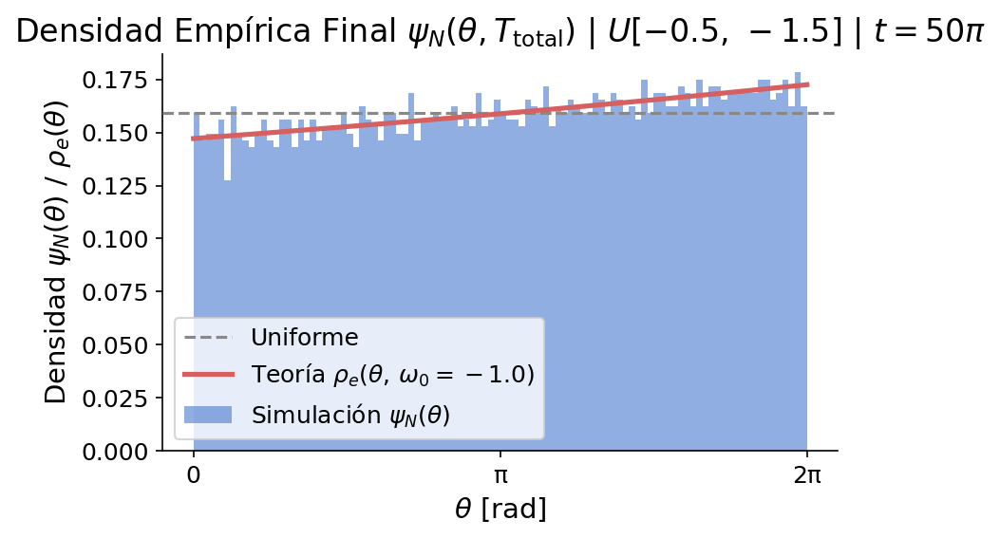

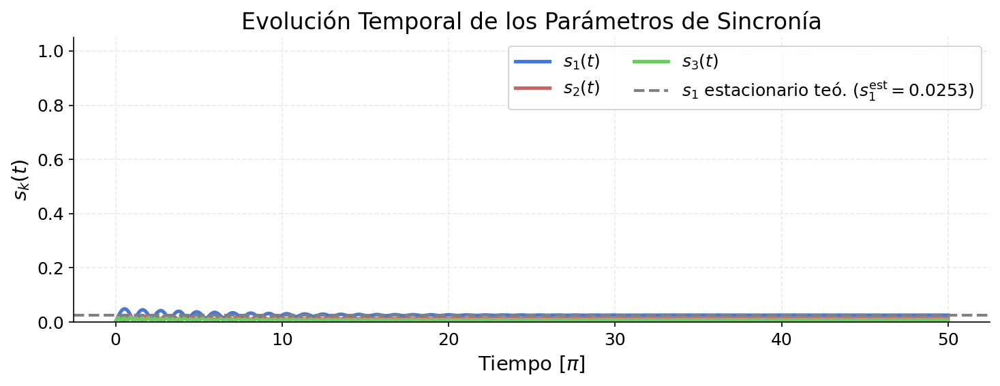

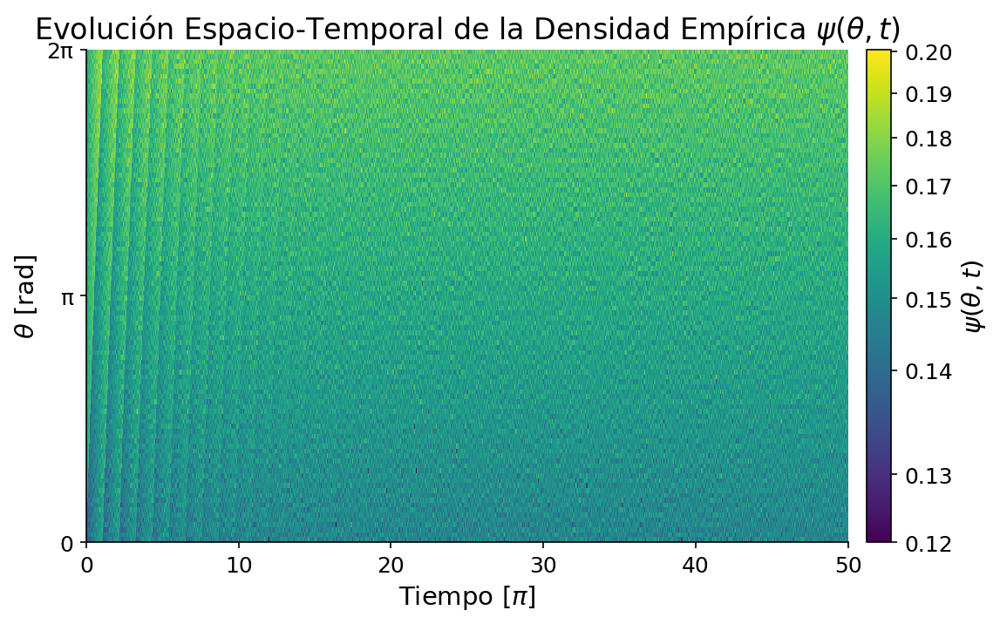

,Pico,ν / π,ν,T / π,T = 2π/ν,P(ν),P / P_dom,Dominante
0,1,0.585495,1.839387,1.087319,3.415913,2.605342e-06,1.000000,Sí
1,2,1.183718,3.718760,0.537814,1.689591,3.790297e-08,0.014548,


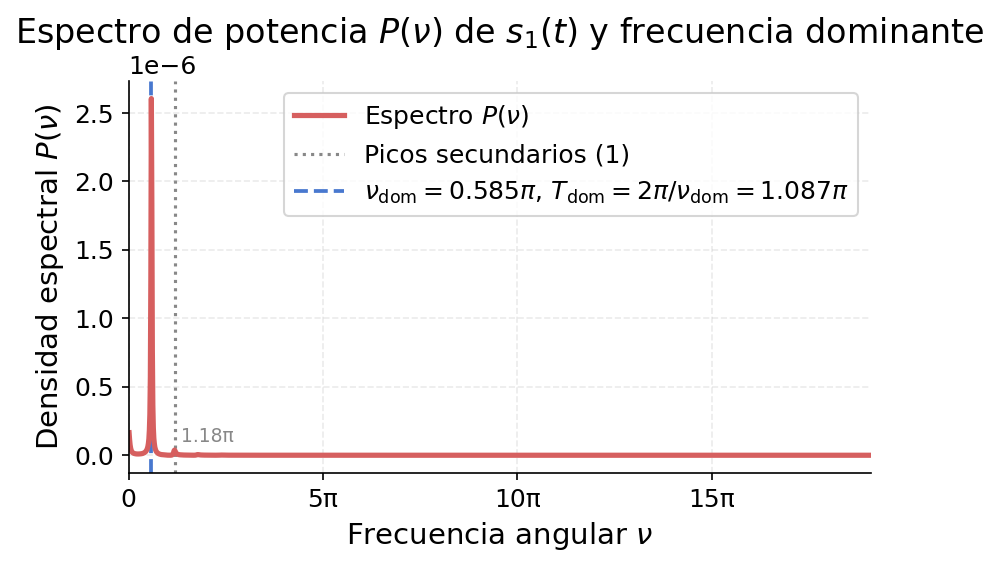

s₁ final = 0.0253 | s₁ᵉˢᵗ = 0.0253 | ν_dom = 0.5855π | T_dom = 2π/ν_dom = 1.0873π

  Lineal + Uniforme | μ = -10.0, Δ = -10.0


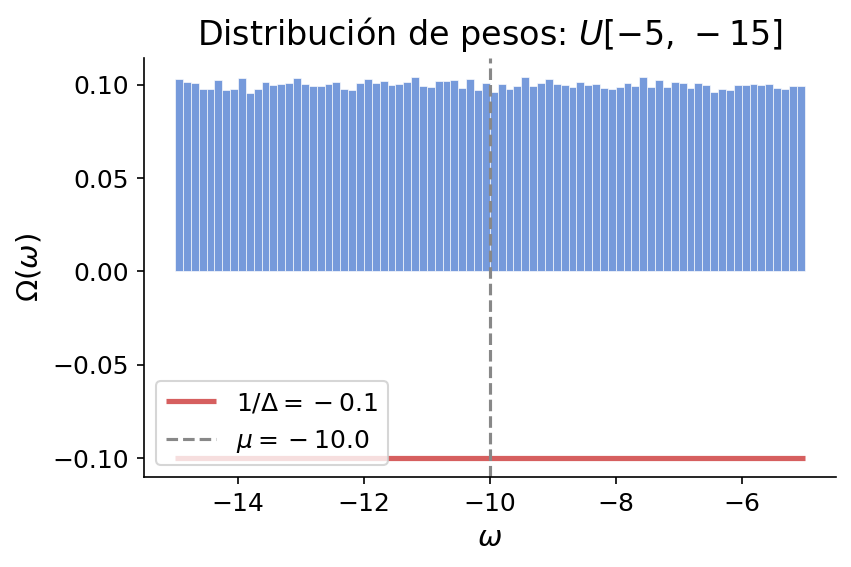

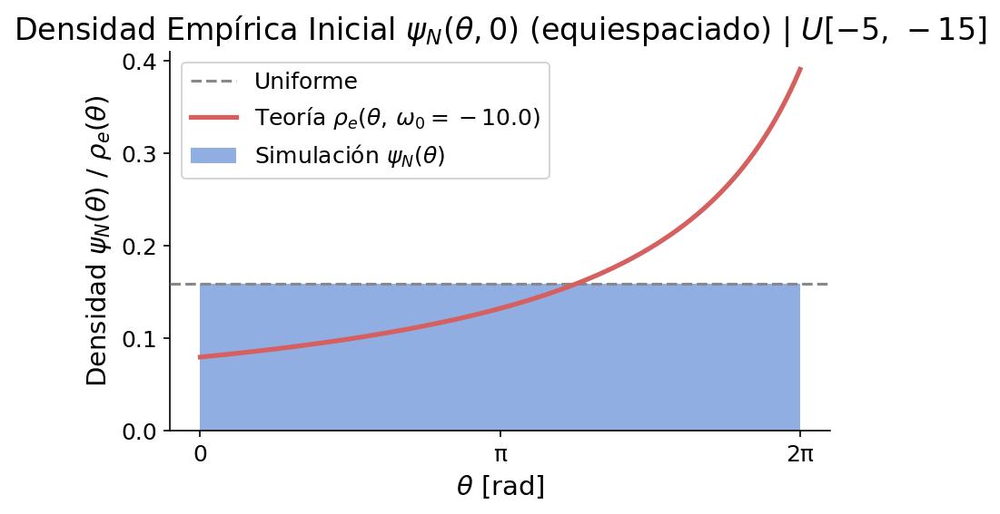

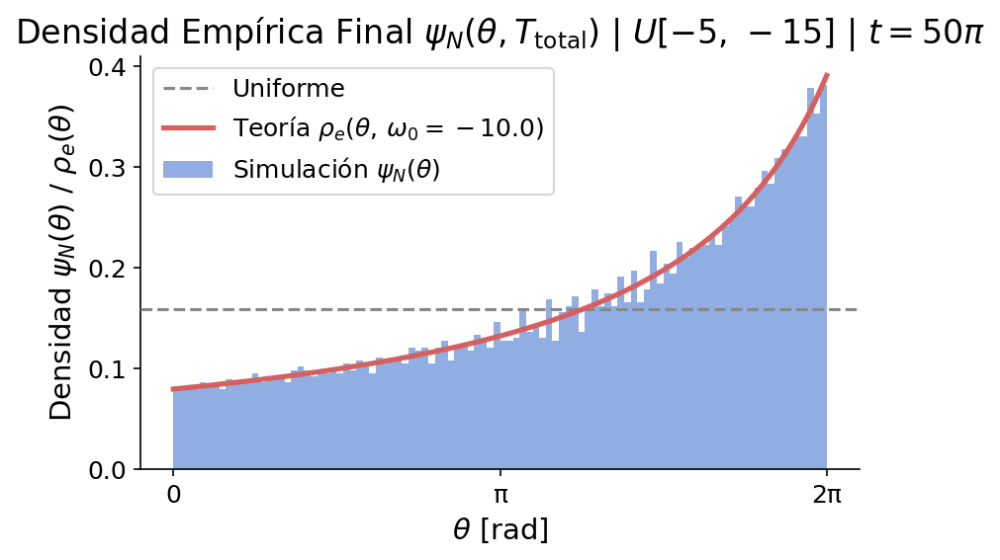

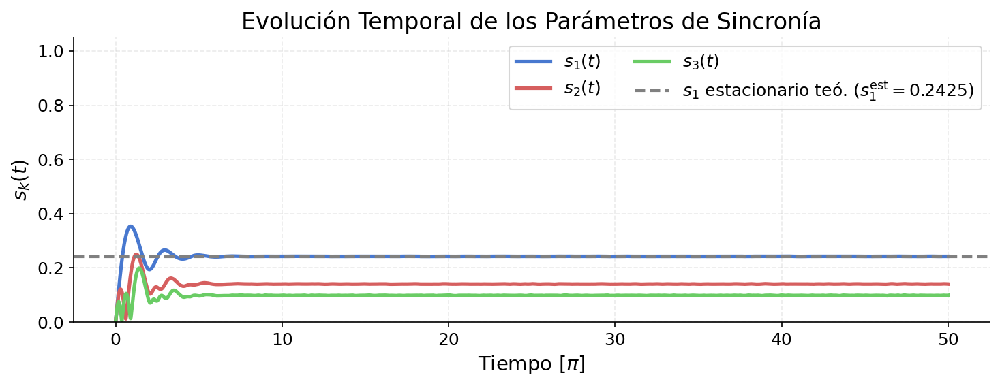

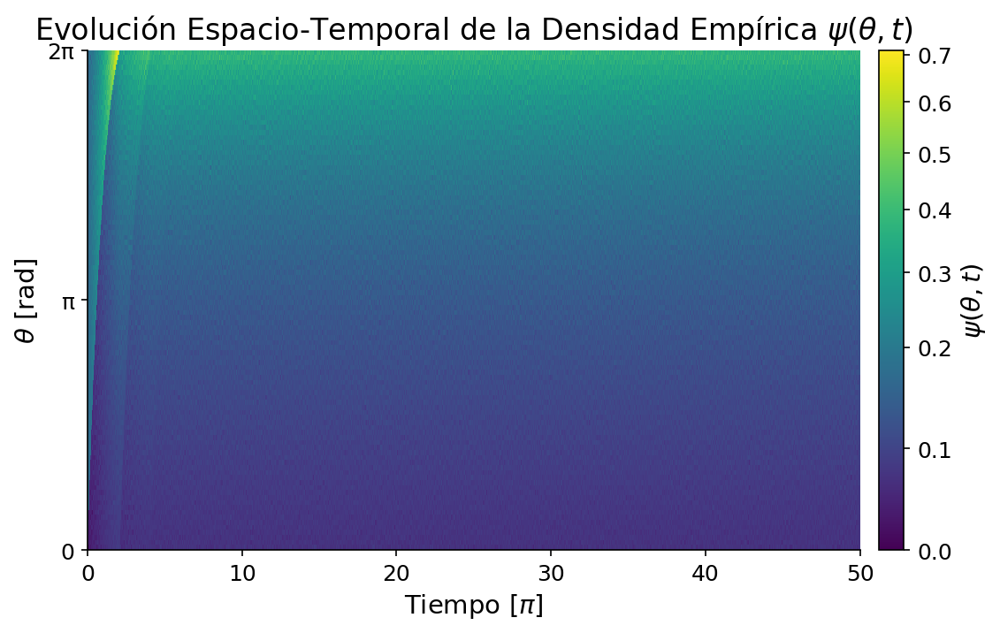

,Pico,ν / π,ν,T / π,T = 2π/ν,P(ν),P / P_dom,Dominante
0,1,0.318204,0.999667,2.000667,6.28528,0.000009,1.0,Sí


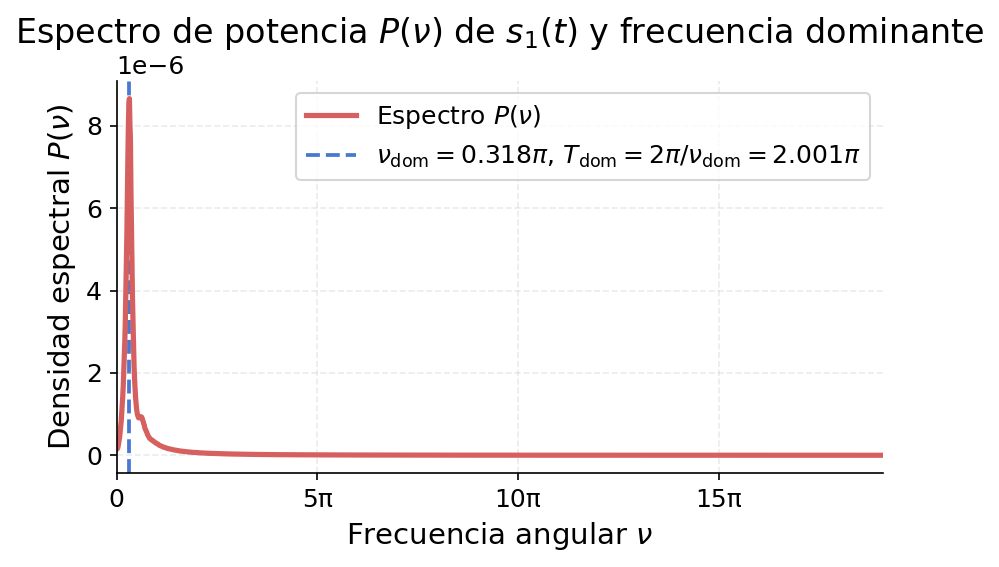

s₁ final = 0.2426 | s₁ᵉˢᵗ = 0.2425 | ν_dom = 0.3182π | T_dom = 2π/ν_dom = 2.0007π

  Lineal + Uniforme | μ = -100.0, Δ = -100.0


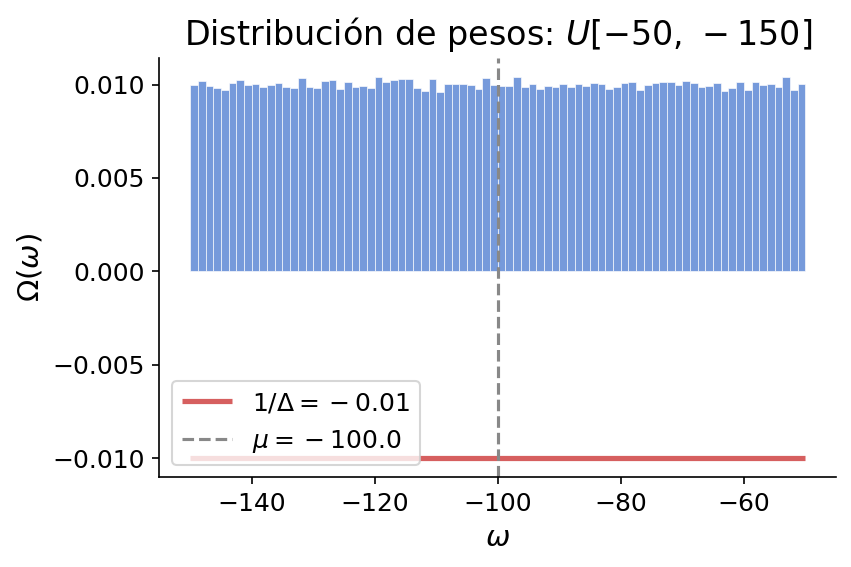

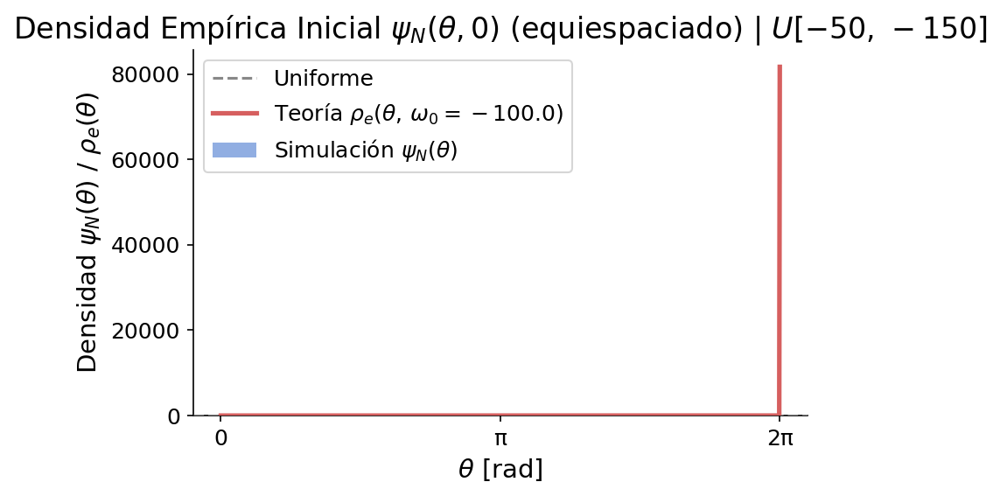

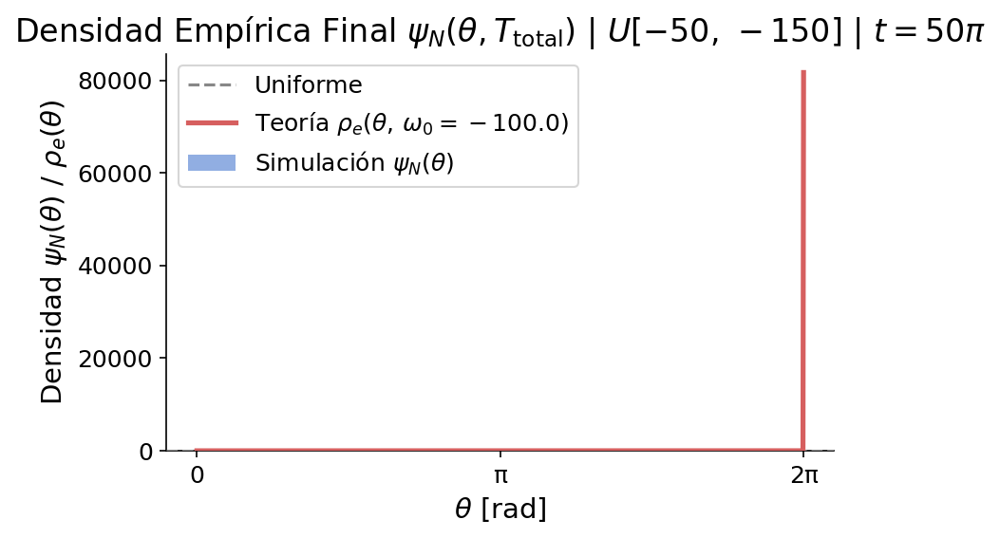

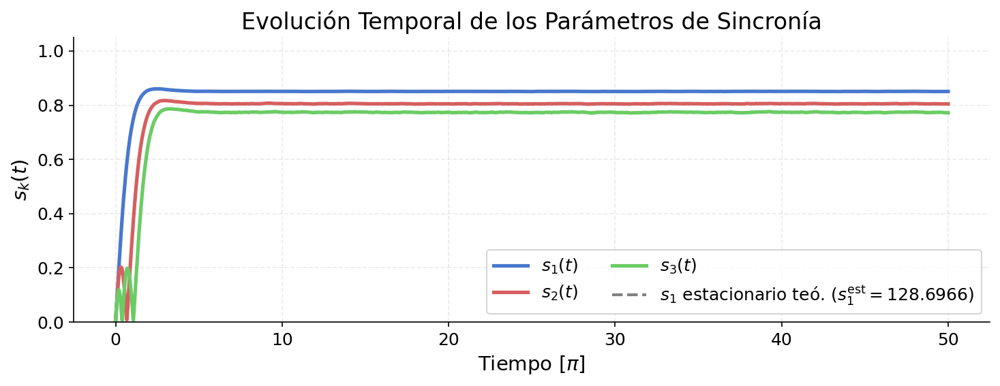

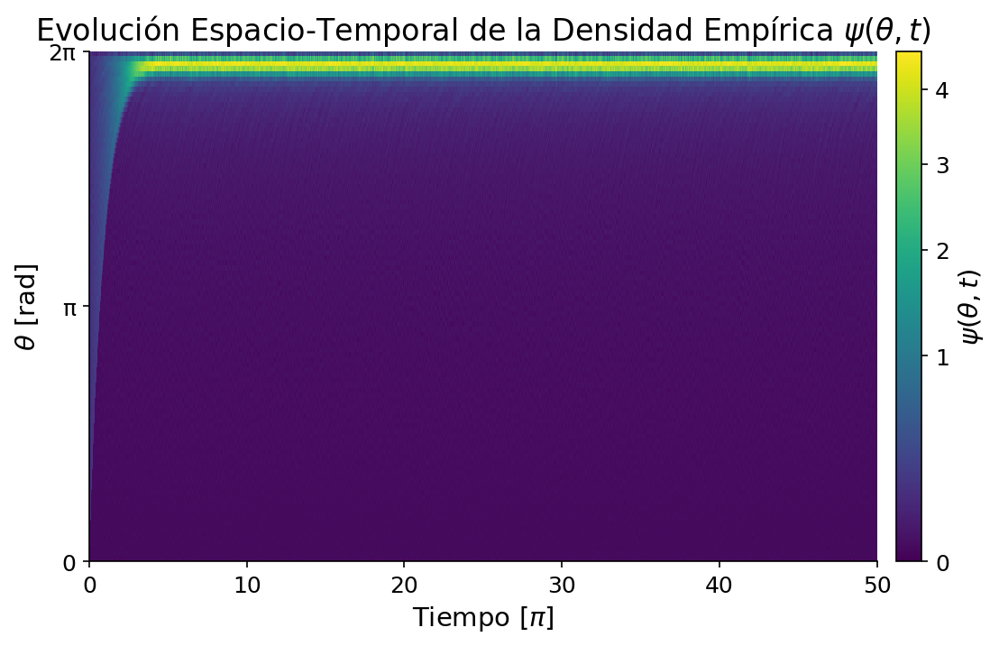

,Pico,ν / π,ν,T / π,T = 2π/ν,P(ν),P / P_dom,Dominante
0,1,0.063641,0.199933,10.003333,31.426399,0.000081,1.0,Sí


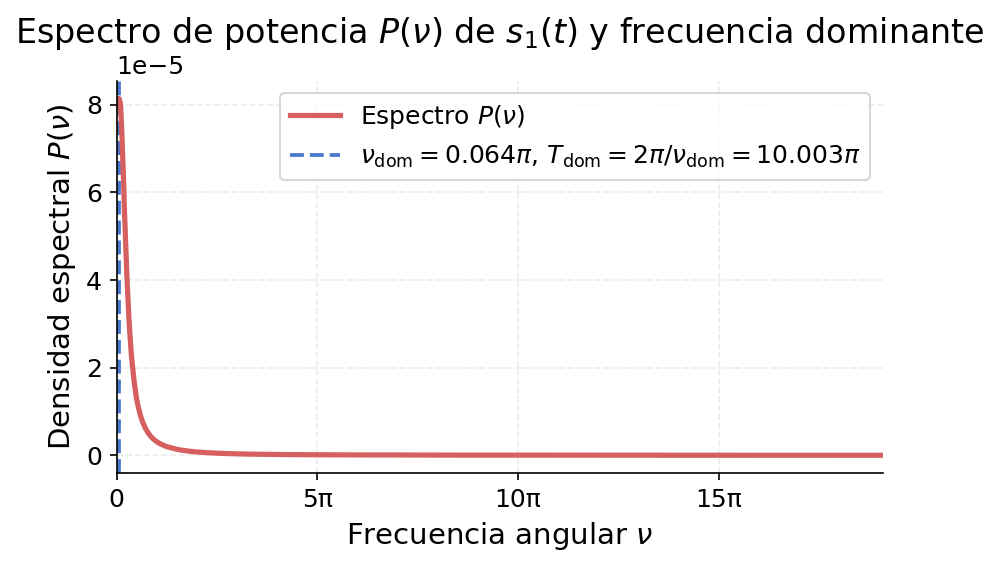

s₁ final = 0.8508 | s₁ᵉˢᵗ = 128.6966 | ν_dom = 0.0636π | T_dom = 2π/ν_dom = 10.0033π

  RESUMEN DEL BARRIDO D (LINEAL + UNIFORME): SINCRONÍA Y ESPECTRO P(ν)


,μ (Acoplamiento),s₁ final,s₁ᵉˢᵗ (teórico),ν_dom / π,T_dom / π,N° picos
0,-0.01,0.000063,0.000253,0.636408,1.000333,3
1,-0.10,0.003529,0.002533,0.636408,1.000333,3
2,-1.00,0.025252,0.025319,0.585495,1.087319,2
3,-10.00,0.242562,0.242528,0.318204,2.000667,1
4,-100.00,0.850843,128.696623,0.063641,10.003333,1


In [65]:
#  BARRIDO D | Modelo Lineal — Distribución Uniforme (Δ = μ_ω)

# 1. Configuración de parámetros y definición explícita de la grilla
N              = 5000
I0             = 1.0
T_total        = 50 * np.pi
T_hist         = np.pi / 60
n_bins         = 100
omegas_barrido = [-0.01, -0.1, -1.0, -10.0, -100.0]

# 2. Contenedor de almacenamiento para los resultados del barrido
resultados_D = {}

# 3. Bucle iterativo con fluctuaciones finitas inhibitorias
for mu in omegas_barrido:
    print(f"\n{'='*60}\n  Lineal + Uniforme | μ_ω = {mu}, Δ = {mu}\n{'='*60}")

    # Distribución uniforme con desorden recocido
    sampler, omega_info = make_omega_dist('uniforme', mu=mu, Delta=mu)
    plot_omega_dist(omega_info)

    # Ejecución de la dinámica con PRC lineal (genera gráfico único sₖ(t) con s₁ᵉˢᵗ)
    phis_f, tiempos, s_dict, histogramas = simular_QIF(
        N            = N,
        sampler      = sampler,
        omega_info   = omega_info,
        Z_fn         = Z_lineal,
        T            = np.pi,
        rho_e_fn     = rho_e_lineal,
        I0           = I0,
        T_total      = T_total,
        T_hist       = T_hist,
        n_bins       = n_bins,
        cond_inicial = 'equiespaciado',
        mu_w_ref   = mu,
        guardar_figs = True,
    )

    # Espectro P(ν) de s₁(t) (ν = 2πf), picos prominentes y frecuencia dominante ν_dom
    s_1_serie = s_dict[1]
    T_dom, nu_dom, nus, psd, df_picos = calcular_periodo_fft(tiempos, s_1_serie)
    s1_est = calcular_s1_estacionario(rho_e_lineal, mu, I0)

    # Tabla de picos y espectro P(ν) con ν en múltiplos de π (picos con líneas punteadas)
    display(df_picos)
    plot_espectro_fft(nus, psd, nu_dom, T_dom, df_picos=df_picos, fname=f'espectro_fft_lineal_unif_mu_{mu}.png')

    # Persistencia de resultados con métricas espectrales
    resultados_D[mu] = dict(
        s_dict   = s_dict,
        tiempos  = tiempos,
        s1_est   = s1_est,
        nu_dom   = nu_dom,
        T_dom    = T_dom,
        nus      = nus,
        psd      = psd,
        picos    = df_picos,
    )

    print(f"s₁ final = {s_dict[1][-1]:.4f} | s₁ᵉˢᵗ = {s1_est:.4f} | ν_dom = {fmt_mult_pi(nu_dom, 4)} | T_dom = 2π/ν_dom = {fmt_mult_pi(T_dom, 4)}")

# 4. Tabla resumen comparativa del barrido paramétrico
tabla_resumen_D = pd.DataFrame([
    {
        'μ_ω [u.v.]': mu,
        's₁ final': float(res['s_dict'][1][-1]),
        's₁ᵉˢᵗ (teórico)': res['s1_est'],
        'ν_dom / π [rad/u.t.]': res['nu_dom'] / np.pi,      # Frecuencia angular dominante en múltiplos de π
        'T_dom / π [u.t.]': res['T_dom'] / np.pi,       # Período dominante T_dom = 2π/ν_dom en múltiplos de π
        'N° picos': len(res['picos']),
    }
    for mu, res in resultados_D.items()
])

print(f"\n{'='*70}\n  RESUMEN DEL BARRIDO D (LINEAL + UNIFORME): SINCRONÍA Y ESPECTRO P(ν)\n{'='*70}")
display(tabla_resumen_D)


### Barrido E | Modelo Tent — Distribución Delta (Acoplamiento Inhibitorio Determinista)

1. **¿Qué hace esta celda?**  
   Explora la respuesta de una red con PRC triangular continua a trozos (modelo tent) frente a distintos niveles de inhibición uniforme determinista $\mu_\omega < 0$, midiendo el período colectivo $T_{\text{dom}}$ y la frecuencia angular dominante $\nu_{\text{dom}}$ mediante FFT.

2. **¿Cómo lo hace?**  
   Somete la red a la grilla de acoplamientos $\mu_\omega \in \{-0.01, -0.1, -1.0, -10.0, -100.0\}$. En cada caso ejecuta la simulación event-driven, calcula la FFT sobre la serie temporal $s_1(t)$ con `calcular_periodo_fft`, despliega el espectro $P(\nu)$ y compila los resultados en `resultados_E`.

3. **¿Qué devuelve o cuál es su resultado/salida?**  
   Produce las gráficas de densidades empíricas $\psi_N$, sincronía, heatmap y espectros $P(\nu)$ con tabla de picos, reporta las métricas en el diccionario `resultados_E` y presenta la tabla resumen final de sincronía y período en función de $\mu_\omega$.



  Tent + Delta | μ = -0.01


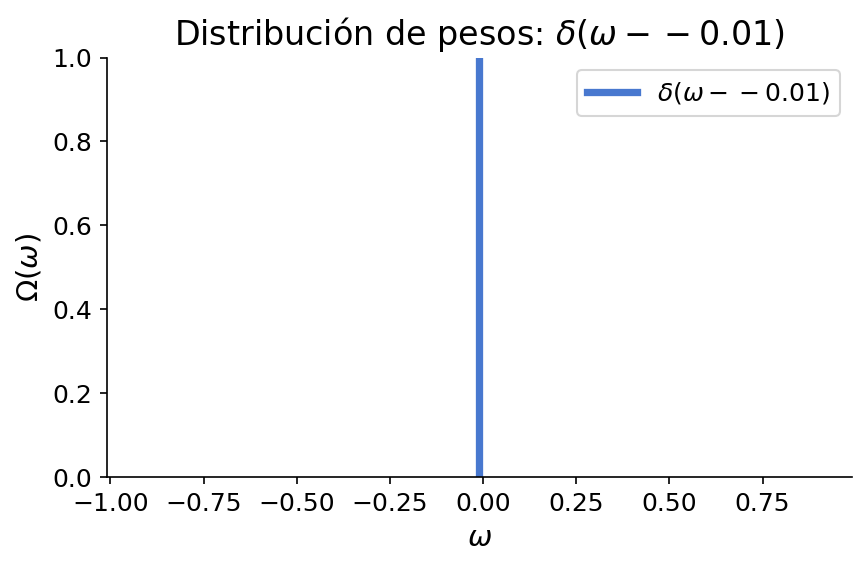

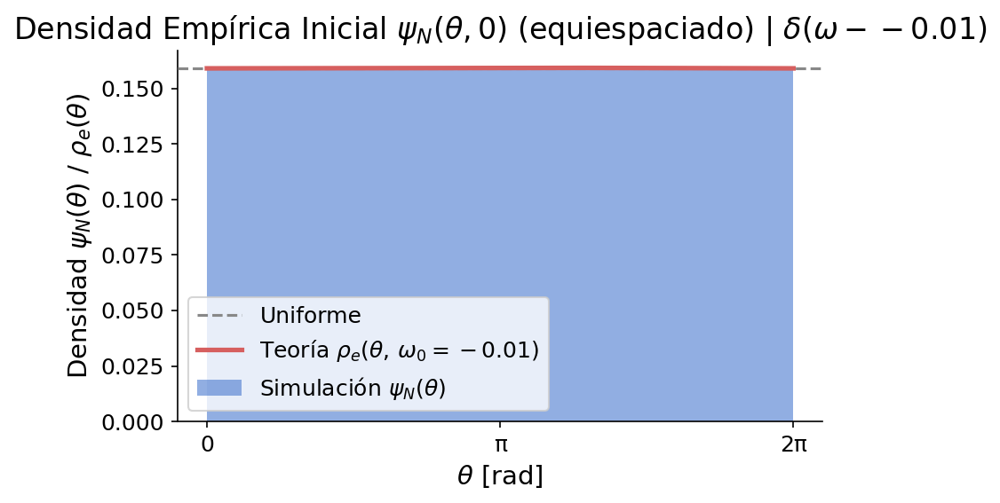

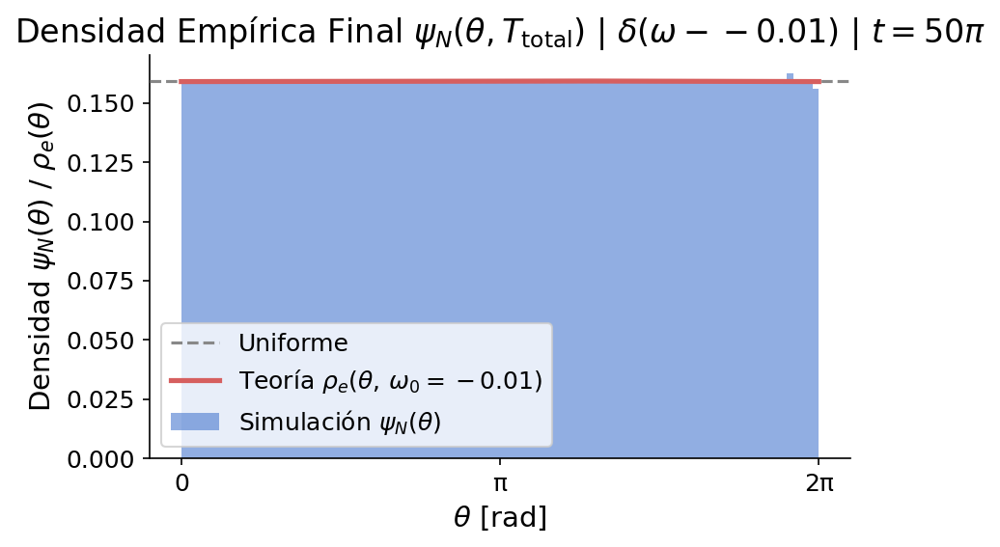

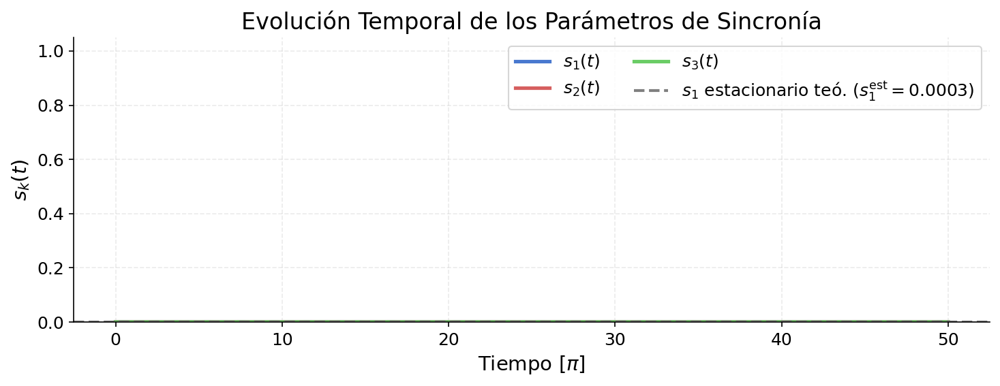

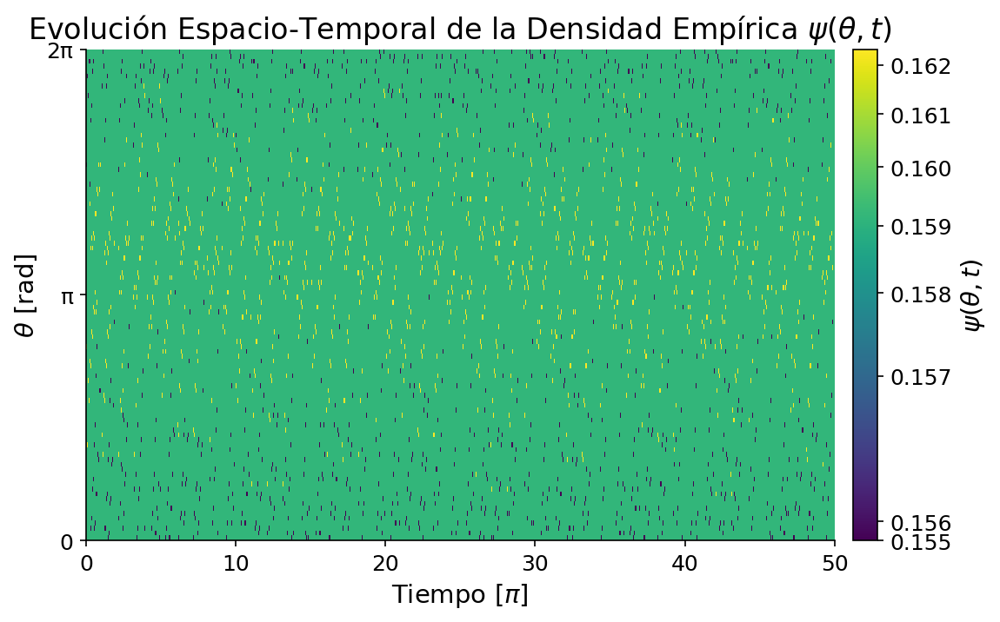

,Pico,ν / π,ν,T / π,T = 2π/ν,P(ν),P / P_dom,Dominante
0,1,0.636408,1.999334,1.000333,3.142640,1.807153e-08,1.000000,Sí
1,2,1.272815,3.998667,0.500167,1.571320,7.212318e-10,0.039910,
2,3,1.909223,5.998001,0.333444,1.047547,1.317522e-10,0.007291,


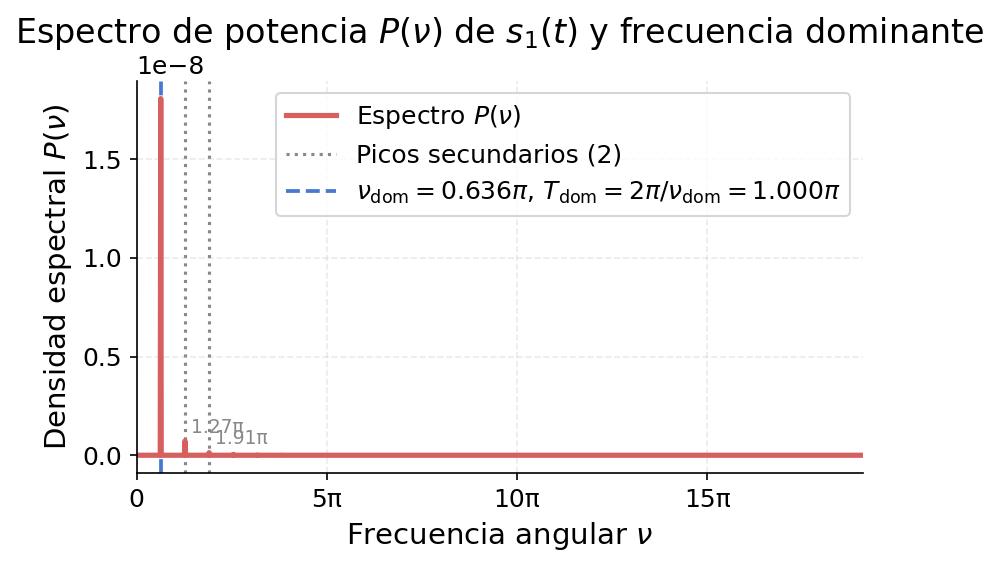

s₁ final = 0.0000 | s₁ᵉˢᵗ = 0.0003 | ν_dom = 0.6364π | T_dom = 2π/ν_dom = 1.0003π

  Tent + Delta | μ = -0.1


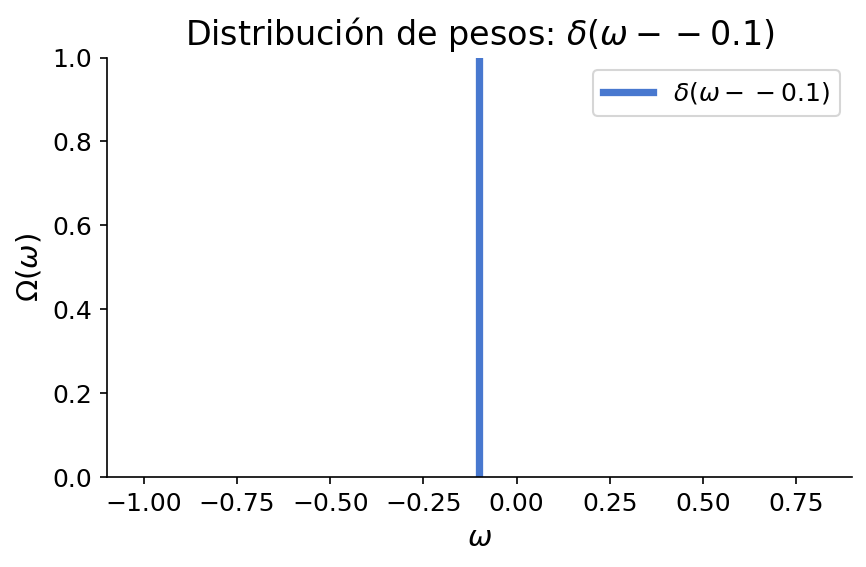

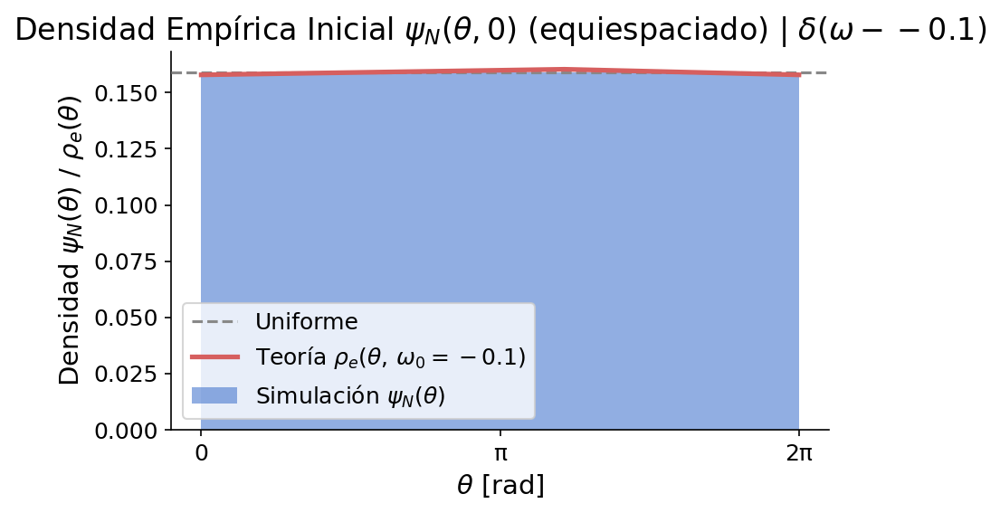

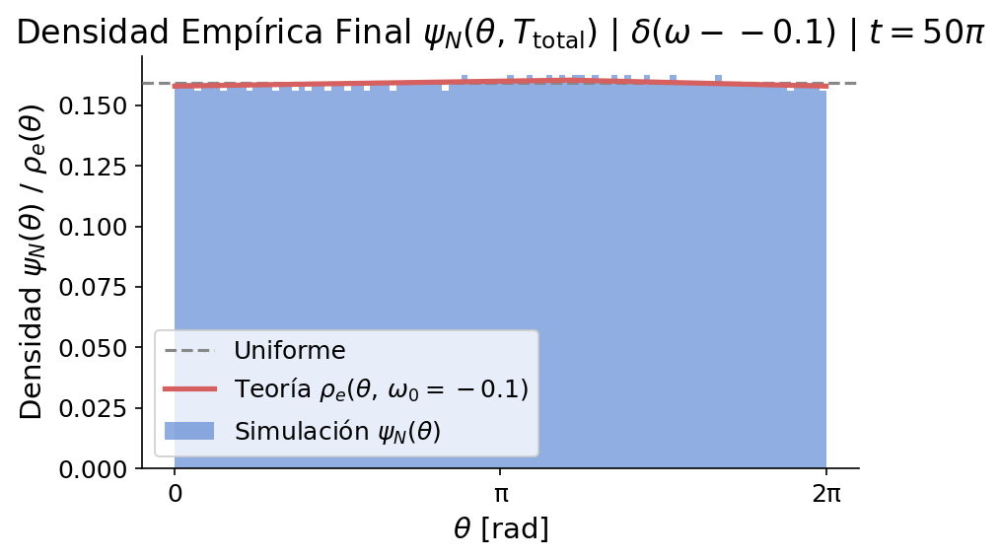

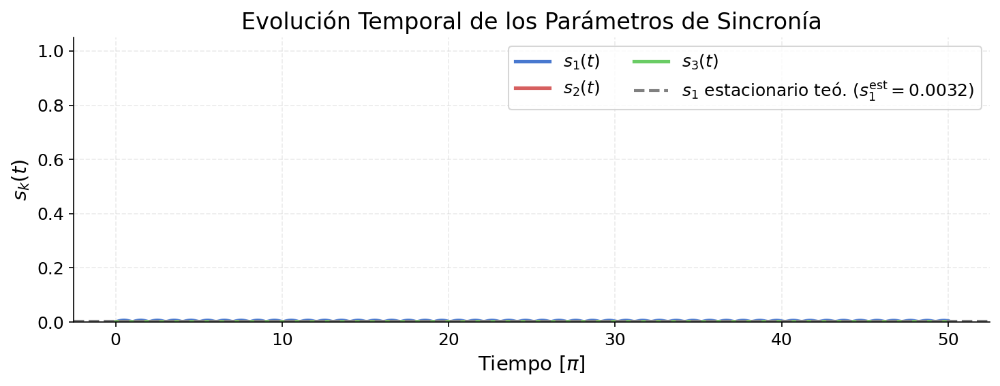

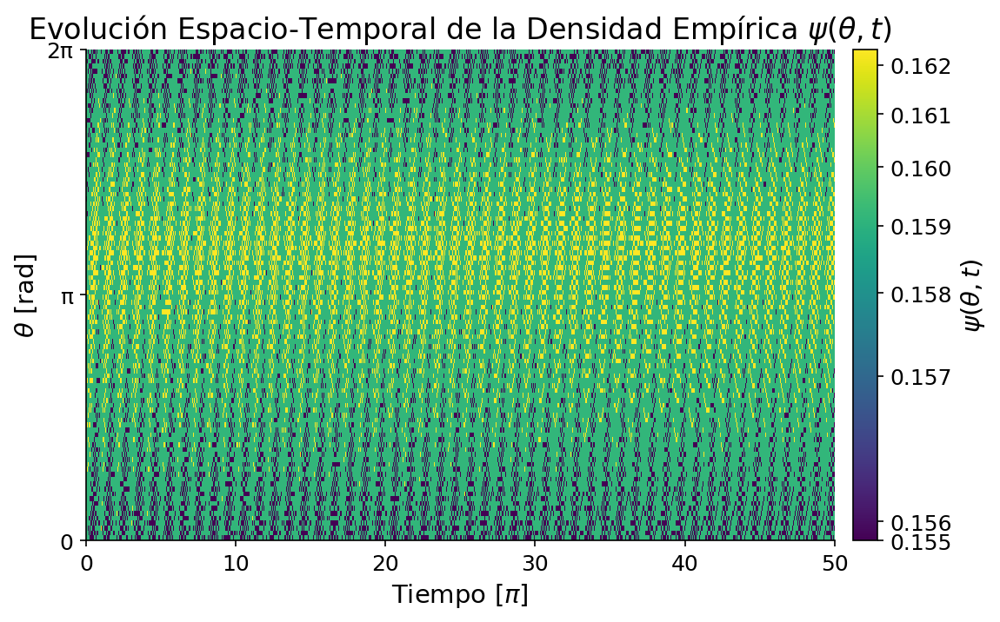

,Pico,ν / π,ν,T / π,T = 2π/ν,P(ν),P / P_dom,Dominante
0,1,0.636408,1.999334,1.000333,3.14264,1.259011e-06,1.000000,Sí
1,2,1.272815,3.998667,0.500167,1.57132,2.734852e-08,0.021722,


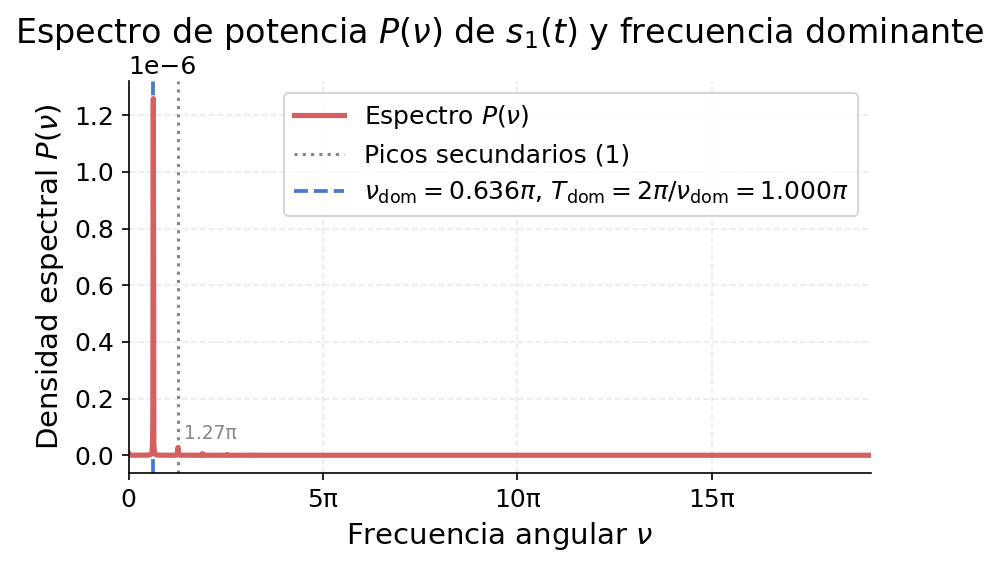

s₁ final = 0.0039 | s₁ᵉˢᵗ = 0.0032 | ν_dom = 0.6364π | T_dom = 2π/ν_dom = 1.0003π

  Tent + Delta | μ = -1.0


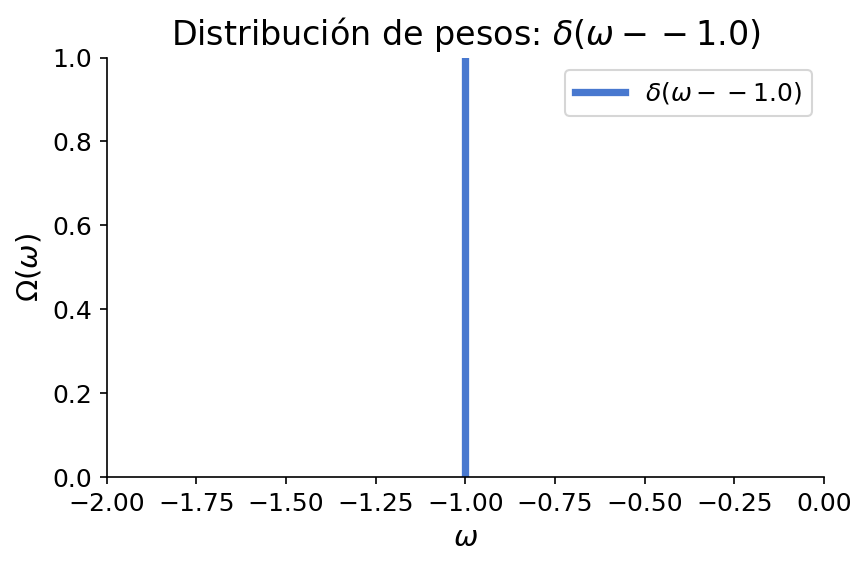

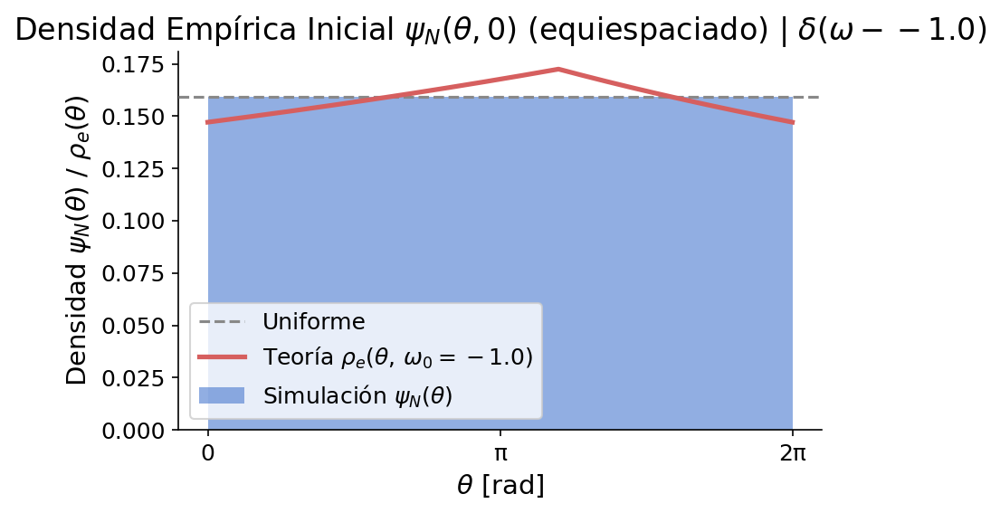

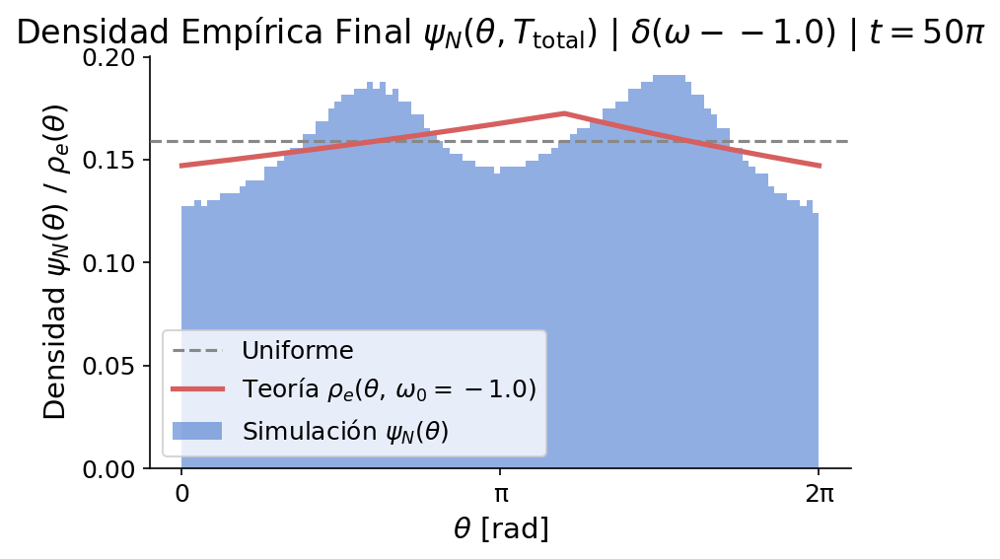

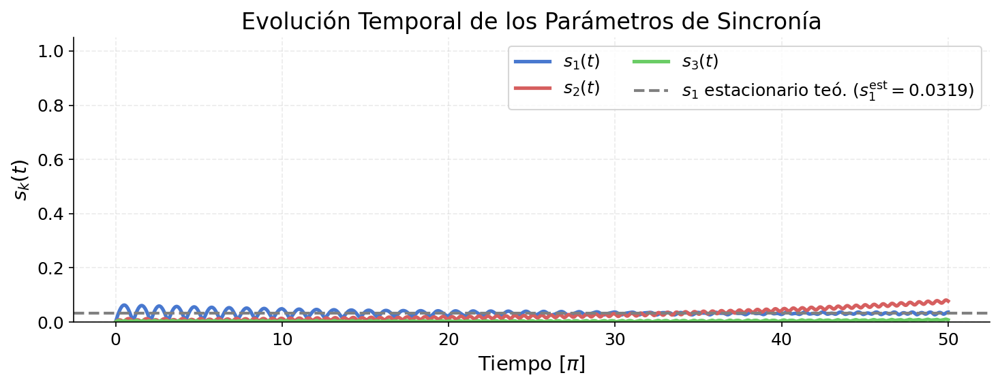

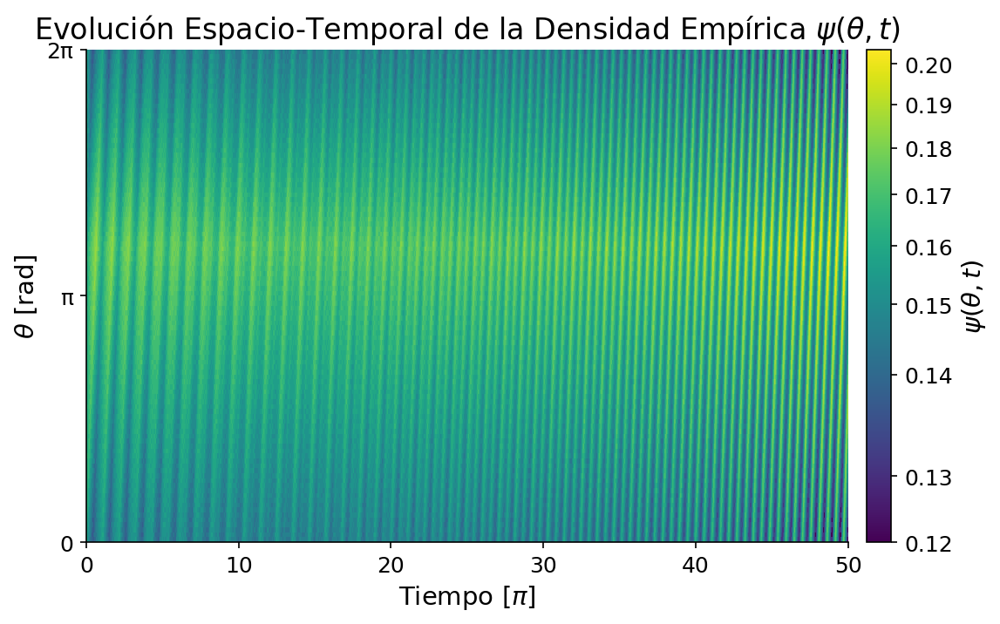

,Pico,ν / π,ν,T / π,T = 2π/ν,P(ν),P / P_dom,Dominante
0,1,0.610951,1.91936,1.042014,3.273583,1.740230e-05,1.000000,Sí
1,2,1.221903,3.83872,0.521007,1.636792,3.251312e-07,0.018683,
2,3,1.183718,3.71876,0.537814,1.689591,2.436751e-07,0.014002,


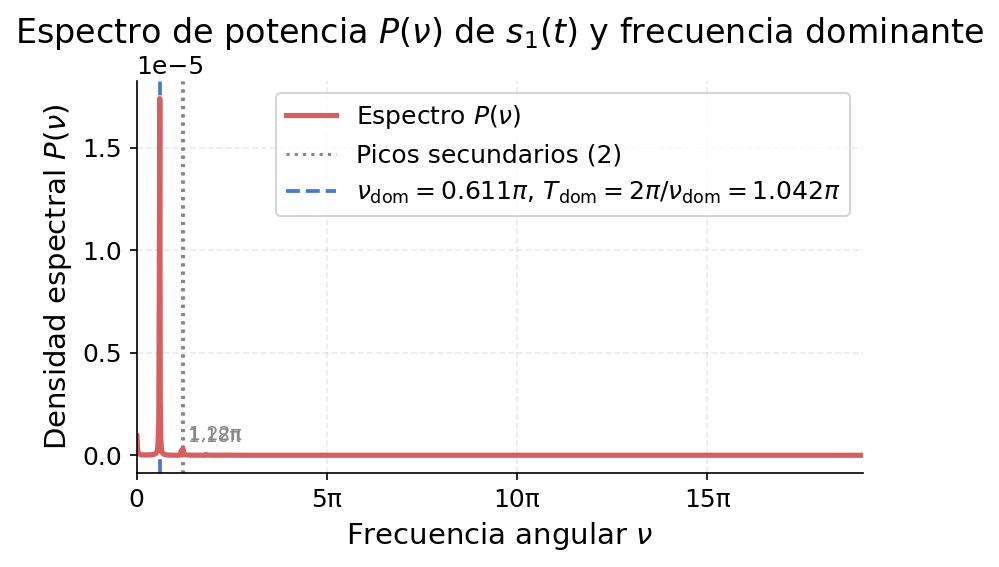

s₁ final = 0.0365 | s₁ᵉˢᵗ = 0.0319 | ν_dom = 0.6110π | T_dom = 2π/ν_dom = 1.0420π

  Tent + Delta | μ = -10.0


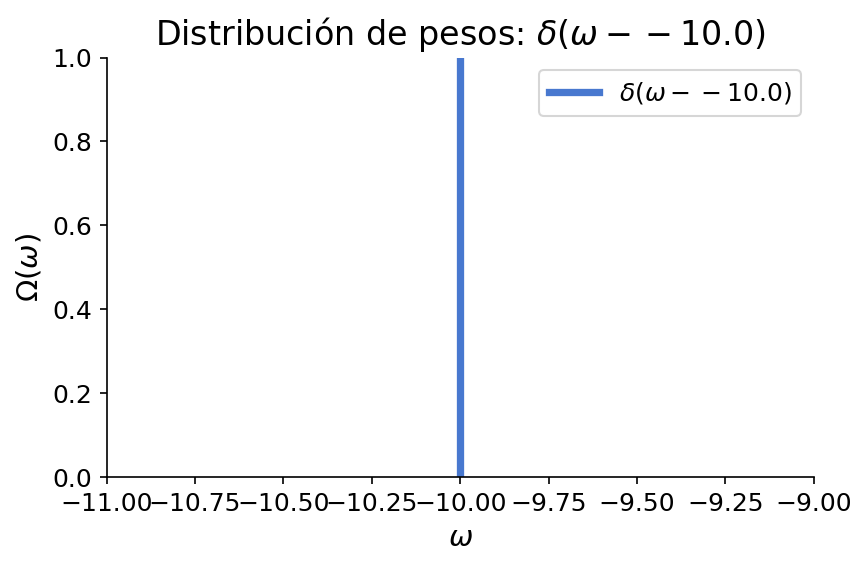

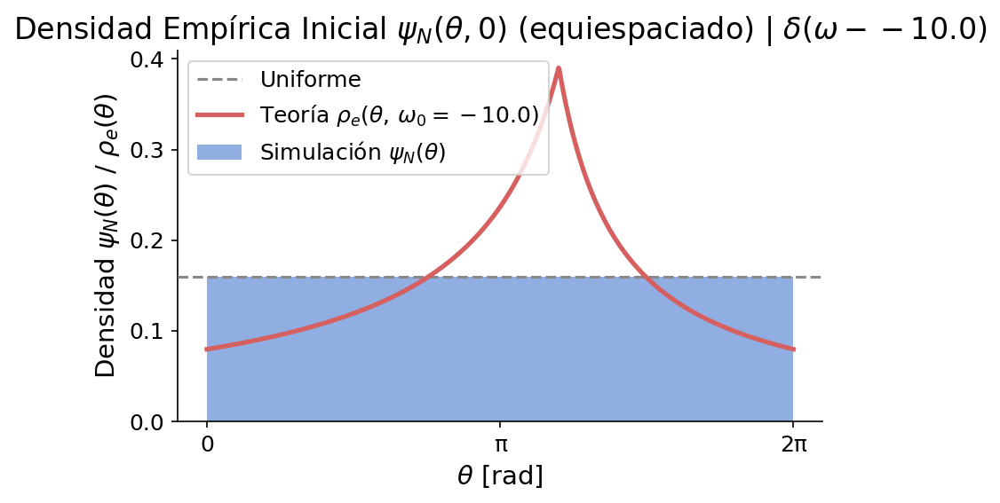

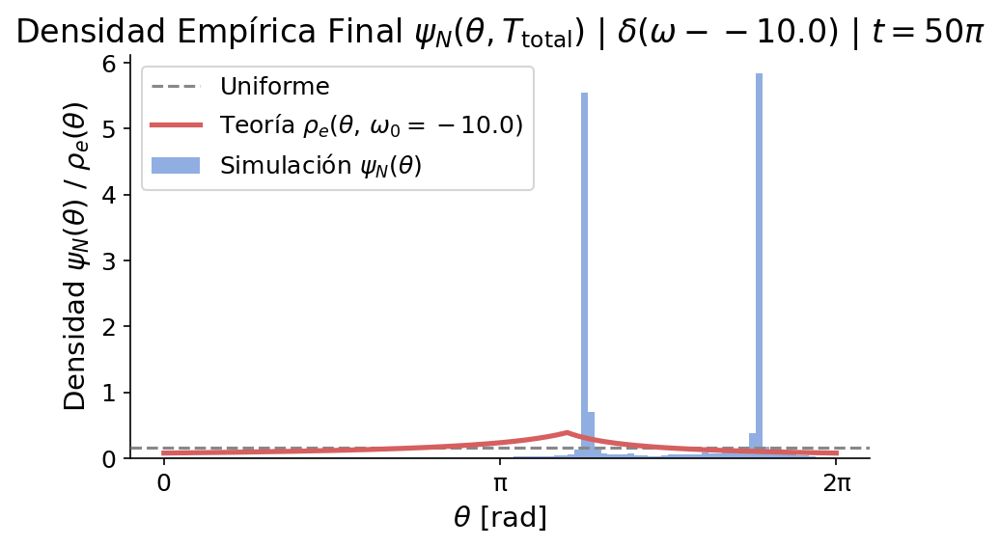

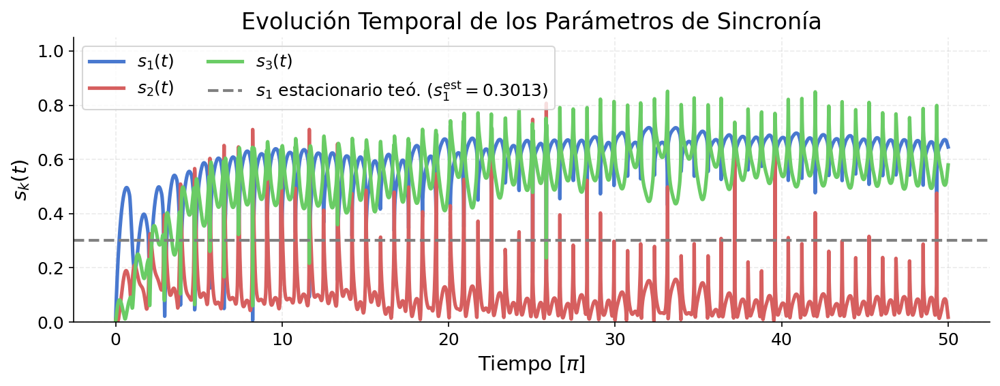

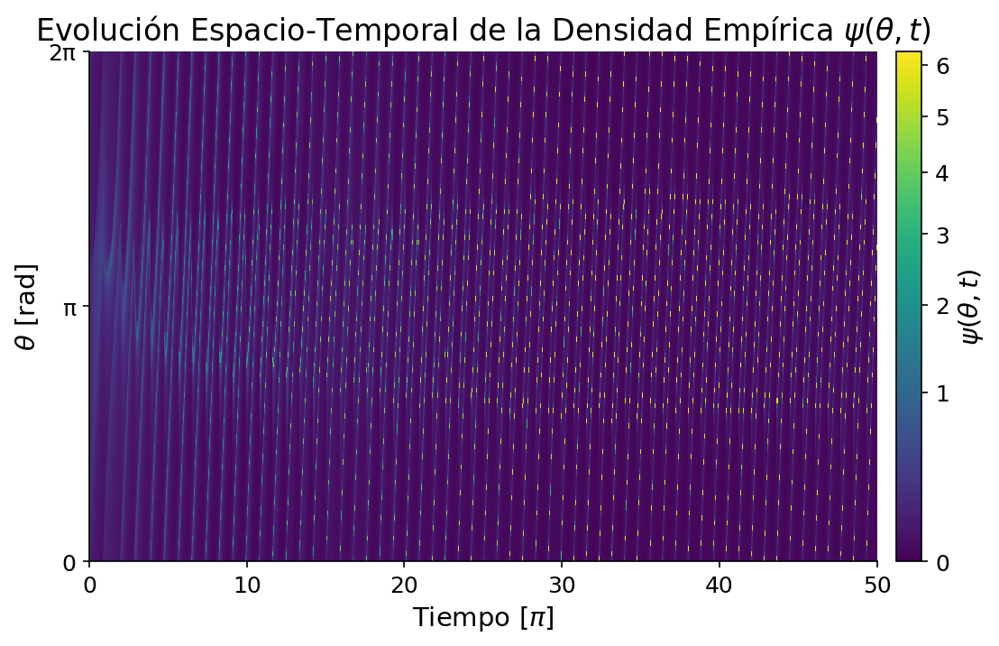

,Pico,ν / π,ν,T / π,T = 2π/ν,P(ν),P / P_dom,Dominante
0,1,0.012728,0.039987,50.016667,157.131993,0.001755,1.000000,Sí
1,2,0.038184,0.119960,16.672222,52.377331,0.000351,0.199926,
2,3,0.738233,2.319227,0.862356,2.709172,0.000219,0.124558,
3,4,0.776417,2.439187,0.819945,2.575934,0.000117,0.066420,
4,5,0.369116,1.159613,1.724713,5.418345,0.000059,0.033738,
5,6,1.489194,4.678441,0.427493,1.343008,0.000035,0.020188,
6,7,1.578291,4.958347,0.403360,1.267193,0.000024,0.013528,
7,8,0.407301,1.279573,1.563021,4.910375,0.000017,0.009889,
8,9,0.432757,1.359547,1.471078,4.621529,0.000016,0.008893,
9,10,2.252883,7.077641,0.282580,0.887751,0.000015,0.008486,


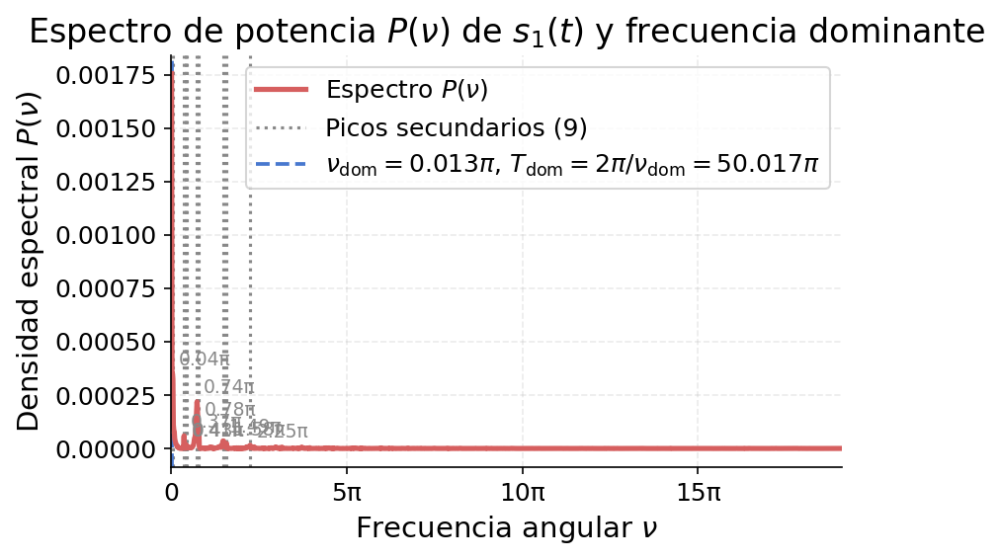

s₁ final = 0.6459 | s₁ᵉˢᵗ = 0.3013 | ν_dom = 0.0127π | T_dom = 2π/ν_dom = 50.0167π

  Tent + Delta | μ = -100.0


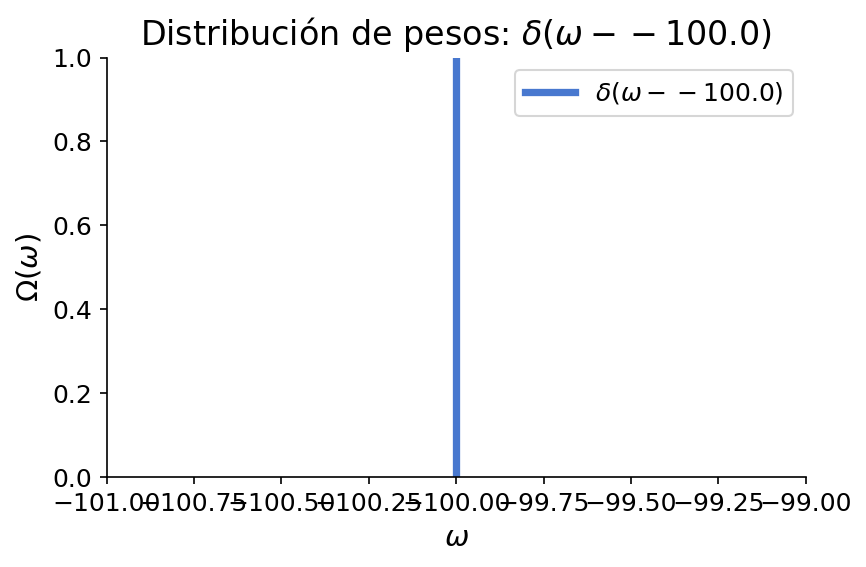

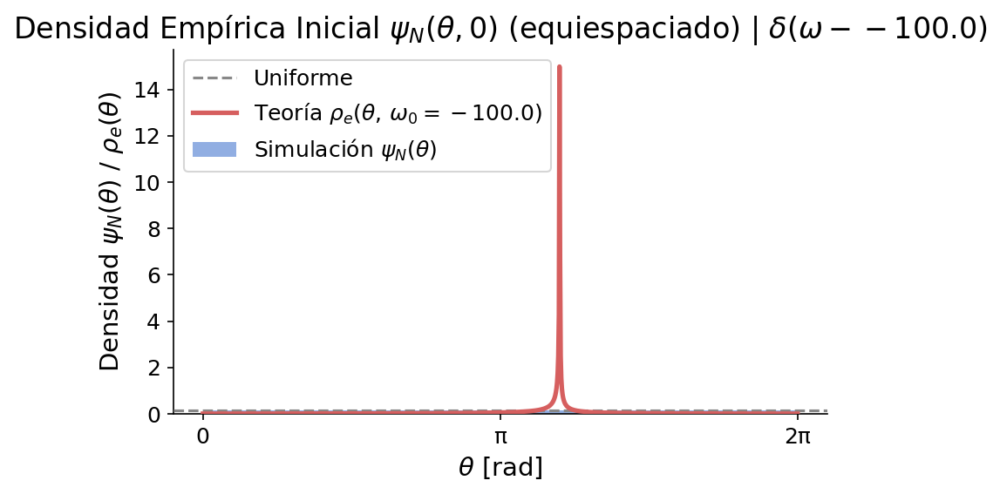

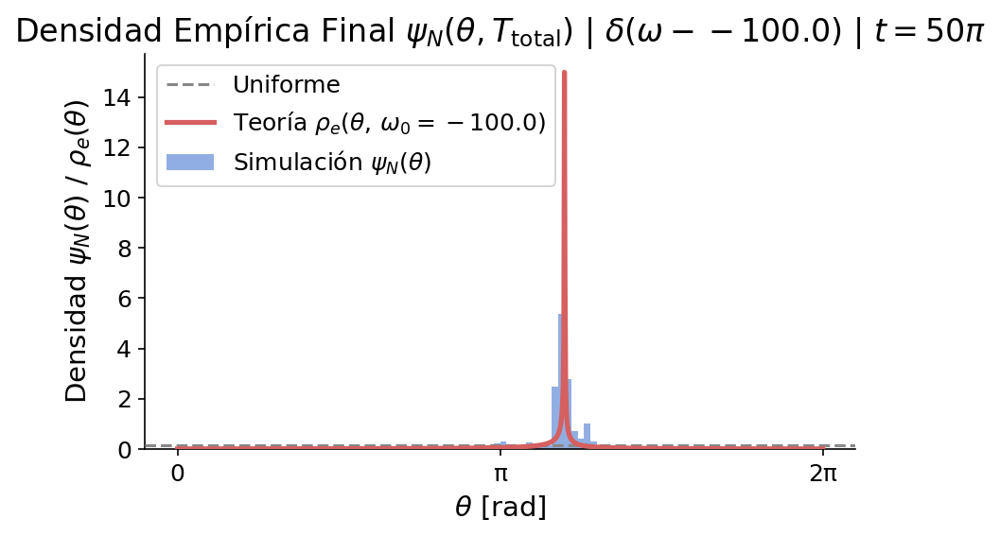

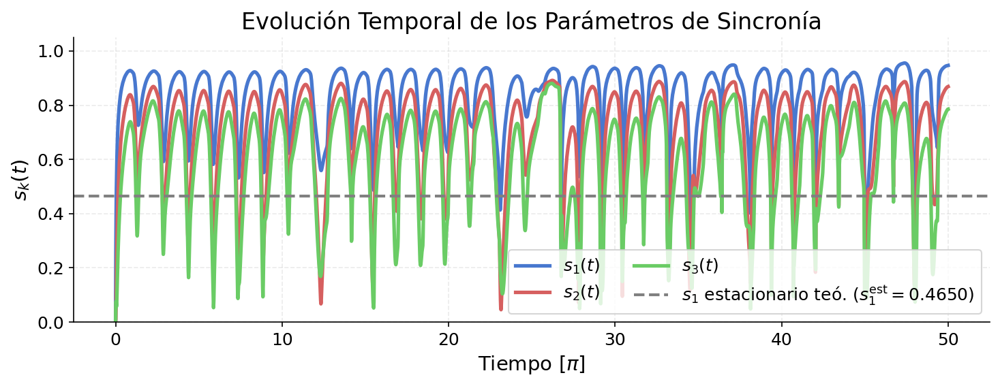

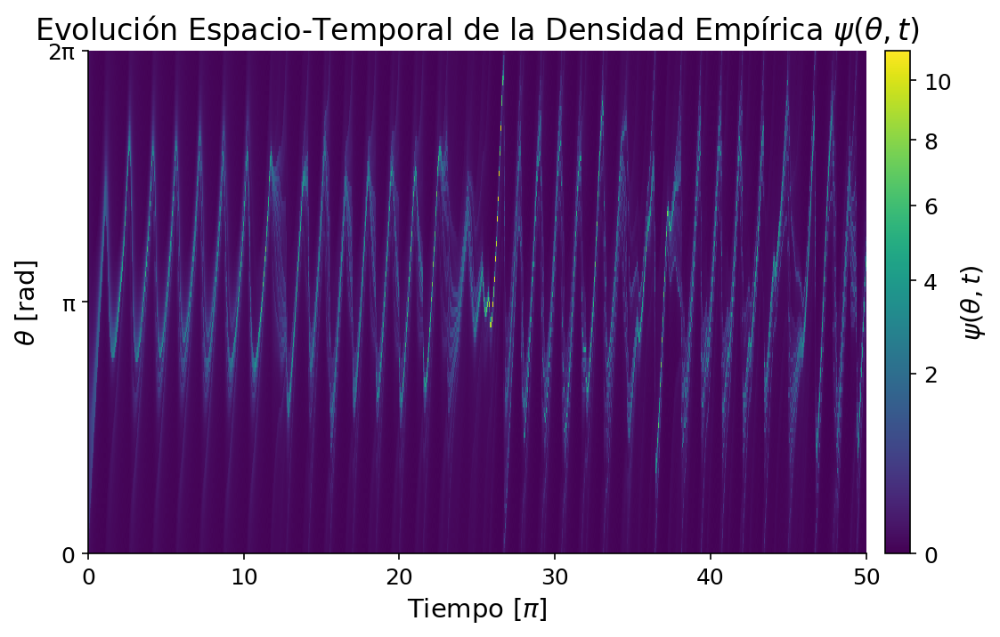

,Pico,ν / π,ν,T / π,T = 2π/ν,P(ν),P / P_dom,Dominante
0,1,0.420029,1.319560,1.515657,4.761576,0.000793,1.000000,Sí
1,2,0.458213,1.439520,1.389352,4.364778,0.000271,0.341420,
2,3,0.178194,0.559813,3.572619,11.223714,0.000254,0.319660,
3,4,0.254563,0.799733,2.500833,7.856600,0.000210,0.265287,
4,5,0.343660,1.079640,1.852469,5.819703,0.000206,0.260154,
5,6,0.509126,1.599467,1.250417,3.928300,0.000205,0.258287,
6,7,0.114553,0.359880,5.557407,17.459110,0.000135,0.169795,
7,8,0.865514,2.719094,0.735539,2.310765,0.000134,0.168355,
8,9,0.903699,2.839054,0.704460,2.213127,0.000129,0.163052,
9,10,0.369116,1.159613,1.724713,5.418345,0.000117,0.147484,


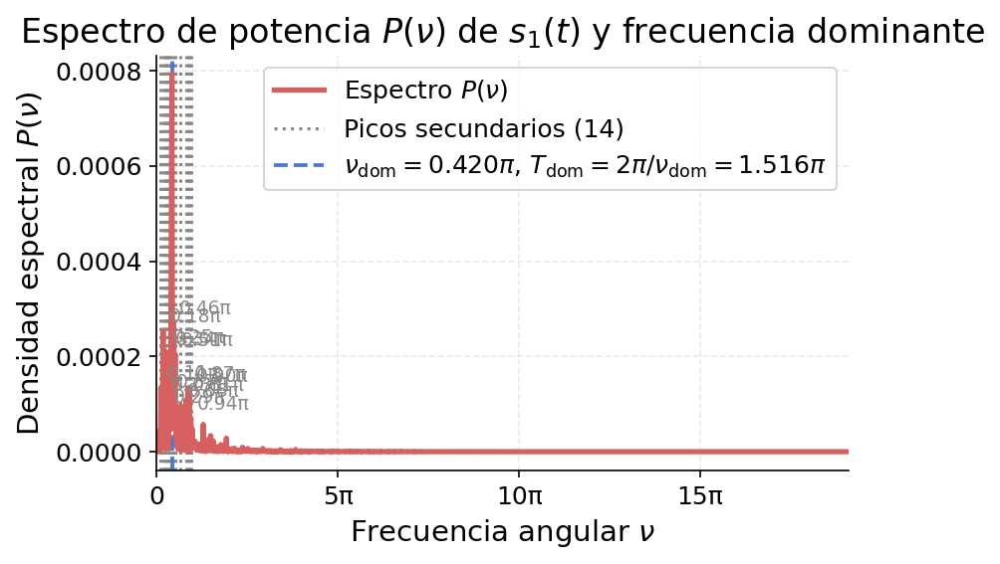

s₁ final = 0.9468 | s₁ᵉˢᵗ = 0.4650 | ν_dom = 0.4200π | T_dom = 2π/ν_dom = 1.5157π

  RESUMEN DEL BARRIDO E (TENT + DELTA): SINCRONÍA Y ESPECTRO P(ν)


,μ (Acoplamiento),s₁ final,s₁ᵉˢᵗ (teórico),ν_dom / π,T_dom / π,N° picos
0,-0.01,0.000050,0.000320,0.636408,1.000333,3
1,-0.10,0.003897,0.003195,0.636408,1.000333,2
2,-1.00,0.036479,0.031931,0.610951,1.042014,3
3,-10.00,0.645856,0.301346,0.012728,50.016667,10
4,-100.00,0.946832,0.465011,0.420029,1.515657,15


In [66]:
#  BARRIDO E | Modelo Tent — Distribución Delta

# 1. Configuración de parámetros y definición de la grilla inhibitoria
N              = 5000
I0             = 1.0
T_total        = 50 * np.pi
T_hist         = np.pi / 60
n_bins         = 100
omegas_barrido = [-0.01, -0.1, -1.0, -10.0, -100.0]

# 2. Contenedor de almacenamiento para los resultados del barrido
resultados_E = {}

# 3. Bucle iterativo sobre acoplamientos inhibitorios deterministas
for mu in omegas_barrido:
    print(f"\n{'='*60}\n  Tent + Delta | μ_ω = {mu}\n{'='*60}")

    # Muestreo constante homogéneo
    sampler, omega_info = make_omega_dist('delta', mu=mu)
    plot_omega_dist(omega_info)

    # Ejecución de la dinámica con PRC triangular tent (genera gráfico único sₖ(t) con s₁ᵉˢᵗ)
    phis_f, tiempos, s_dict, histogramas = simular_QIF(
        N            = N,
        sampler      = sampler,
        omega_info   = omega_info,
        Z_fn         = Z_tent,
        T            = np.pi,
        rho_e_fn     = rho_e_tent,
        I0           = I0,
        T_total      = T_total,
        T_hist       = T_hist,
        n_bins       = n_bins,
        cond_inicial = 'equiespaciado',
        mu_w_ref   = mu,
        guardar_figs = True,
    )

    # Espectro P(ν) de s₁(t) (ν = 2πf), picos prominentes y frecuencia dominante ν_dom
    s_1_serie = s_dict[1]
    T_dom, nu_dom, nus, psd, df_picos = calcular_periodo_fft(tiempos, s_1_serie)
    s1_est = calcular_s1_estacionario(rho_e_tent, mu, I0)

    # Tabla de picos y espectro P(ν) con ν en múltiplos de π (picos con líneas punteadas)
    display(df_picos)
    plot_espectro_fft(nus, psd, nu_dom, T_dom, df_picos=df_picos, fname=f'espectro_fft_tent_delta_mu_{mu}.png')

    # Persistencia de resultados con métricas espectrales
    resultados_E[mu] = dict(
        s_dict   = s_dict,
        tiempos  = tiempos,
        s1_est   = s1_est,
        nu_dom   = nu_dom,
        T_dom    = T_dom,
        nus      = nus,
        psd      = psd,
        picos    = df_picos,
    )

    print(f"s₁ final = {s_dict[1][-1]:.4f} | s₁ᵉˢᵗ = {s1_est:.4f} | ν_dom = {fmt_mult_pi(nu_dom, 4)} | T_dom = 2π/ν_dom = {fmt_mult_pi(T_dom, 4)}")

# 4. Tabla resumen comparativa del barrido paramétrico
tabla_resumen_E = pd.DataFrame([
    {
        'μ_ω [u.v.]': mu,
        's₁ final': float(res['s_dict'][1][-1]),
        's₁ᵉˢᵗ (teórico)': res['s1_est'],
        'ν_dom / π [rad/u.t.]': res['nu_dom'] / np.pi,      # Frecuencia angular dominante en múltiplos de π
        'T_dom / π [u.t.]': res['T_dom'] / np.pi,       # Período dominante T_dom = 2π/ν_dom en múltiplos de π
        'N° picos': len(res['picos']),
    }
    for mu, res in resultados_E.items()
])

print(f"\n{'='*70}\n  RESUMEN DEL BARRIDO E (TENT + DELTA): SINCRONÍA Y ESPECTRO P(ν)\n{'='*70}")
display(tabla_resumen_E)


### Barrido F | Modelo Tent — Distribución Uniforme (Inhibición Heterogénea $\Delta = |\mu_\omega|$)

1. **¿Qué hace esta celda?**  
   Examina la interacción entre la no linealidad angular de la PRC tent y las fluctuaciones estocásticas de desorden recocido en régimen inhibitorio, cuantificando la persistencia y período $T_{\text{dom}}$ de las oscilaciones colectivas vía FFT.

2. **¿Cómo lo hace?**  
   Ejecuta simulaciones para cada valor medio $\mu_\omega < 0$ sorteando pesos sinápticos $\omega_i \sim \mathcal{U}[\mu_\omega - \Delta/2, \mu_\omega + \Delta/2]$ con dispersión $\Delta = |\mu_\omega|$. Evalúa la simulación event-driven, calcula la FFT sobre $s_1(t)$ con `calcular_periodo_fft`, grafica el espectro $P(\nu)$ y almacena los resultados en `resultados_F`.

3. **¿Qué devuelve o cuál es su resultado/salida?**  
   Despliega los diagnósticos visuales y espectros $P(\nu)$ con tabla de picos correspondientes, registra las series y métricas espectrales en `resultados_F` y exhibe la tabla resumen comparativa del barrido.



  Tent + Uniforme | μ = -0.01, Δ = -0.01


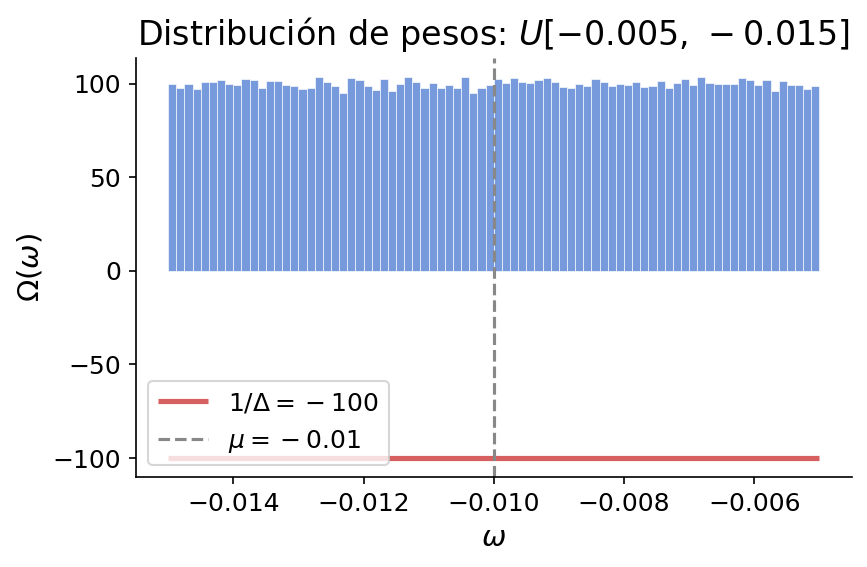

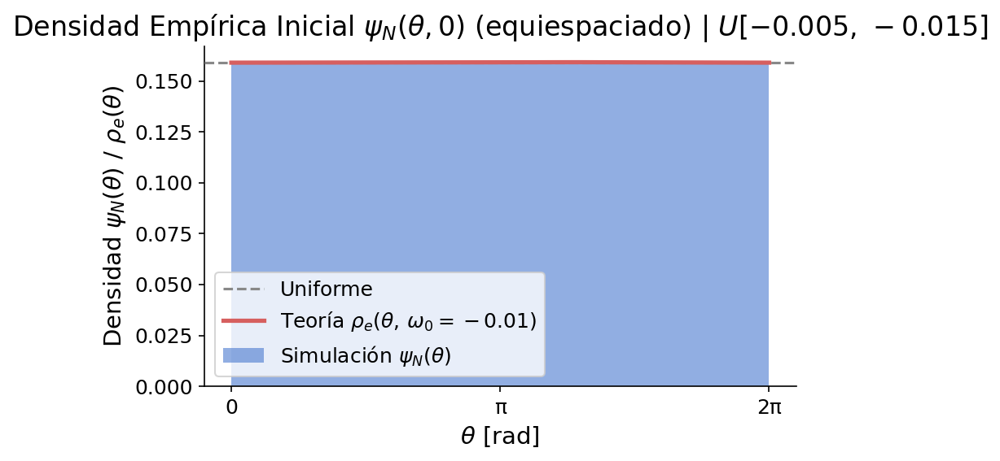

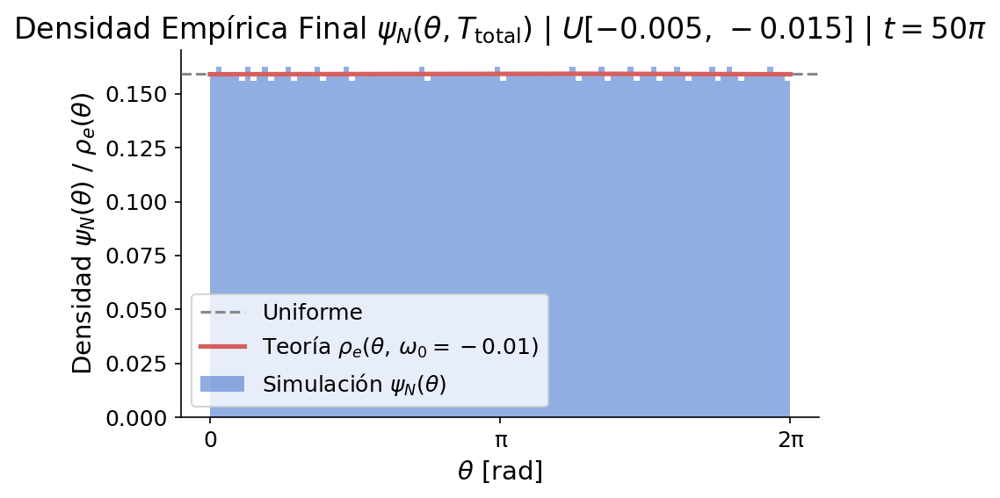

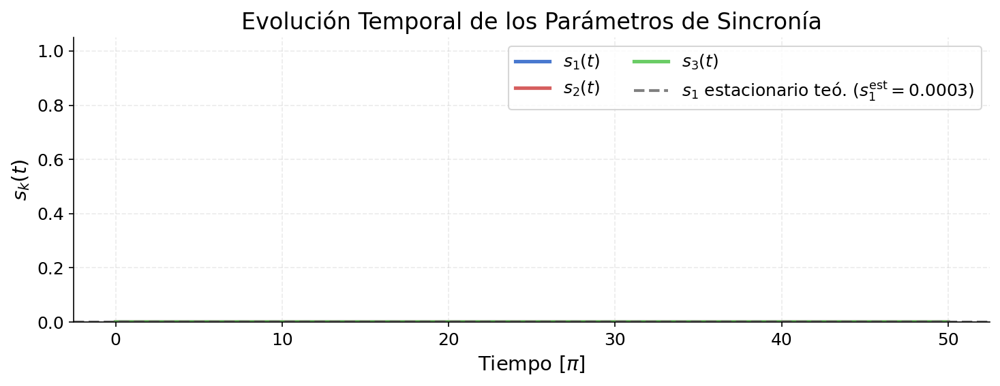

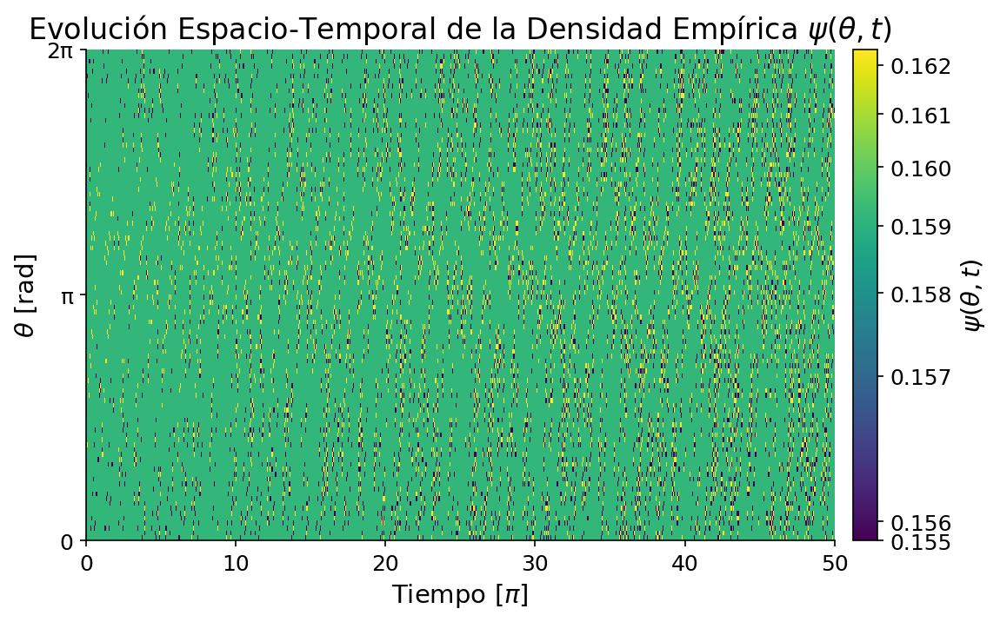

,Pico,ν / π,ν,T / π,T = 2π/ν,P(ν),P / P_dom,Dominante
0,1,0.636408,1.999334,1.000333,3.142640,1.796322e-08,1.000000,Sí
1,2,1.272815,3.998667,0.500167,1.571320,7.153871e-10,0.039825,
2,3,1.909223,5.998001,0.333444,1.047547,1.302823e-10,0.007253,


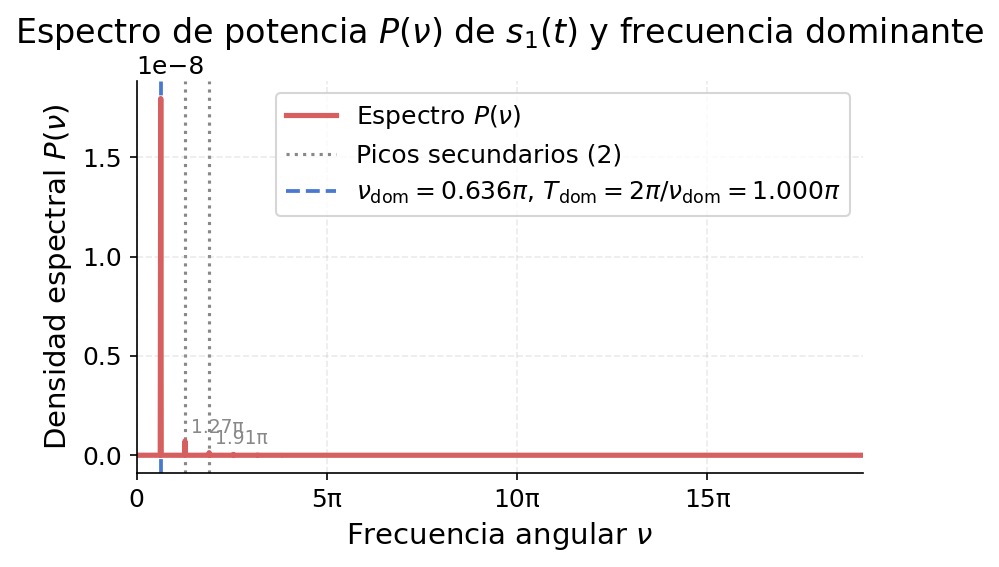

s₁ final = 0.0000 | s₁ᵉˢᵗ = 0.0003 | ν_dom = 0.6364π | T_dom = 2π/ν_dom = 1.0003π

  Tent + Uniforme | μ = -0.1, Δ = -0.1


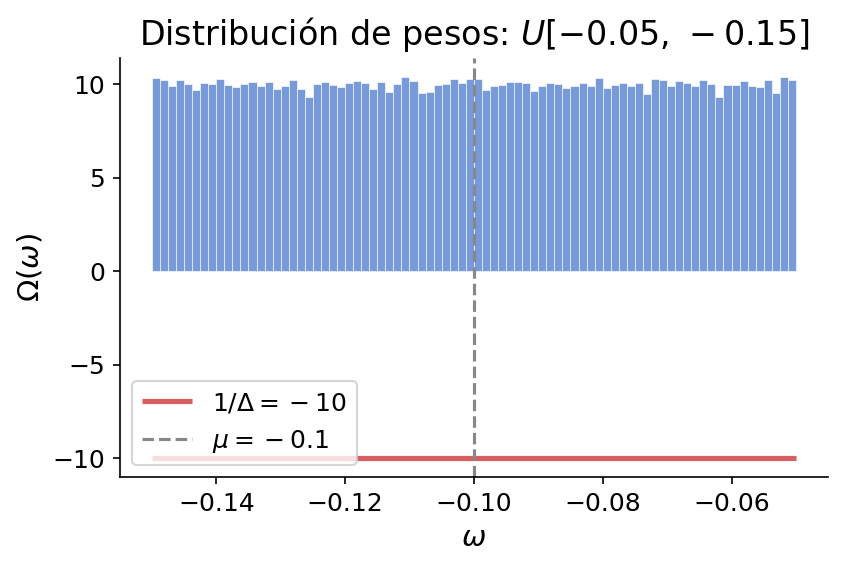

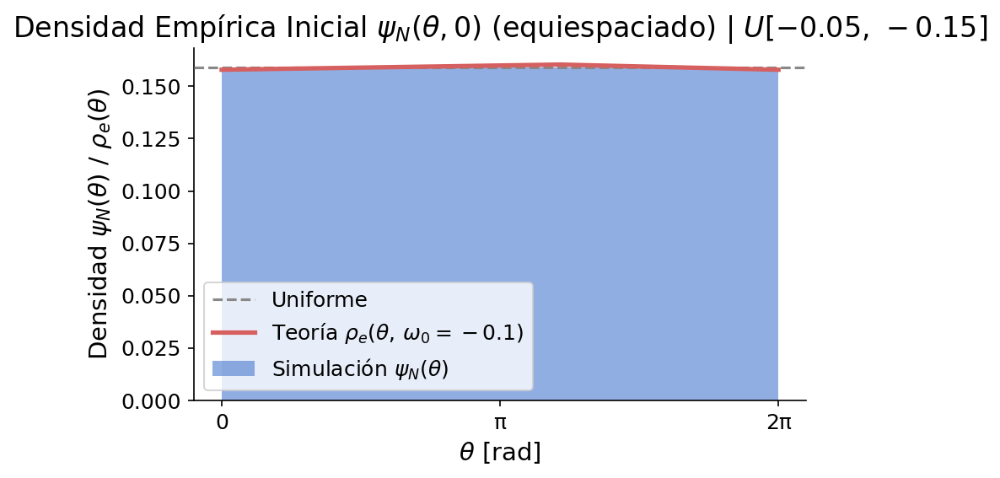

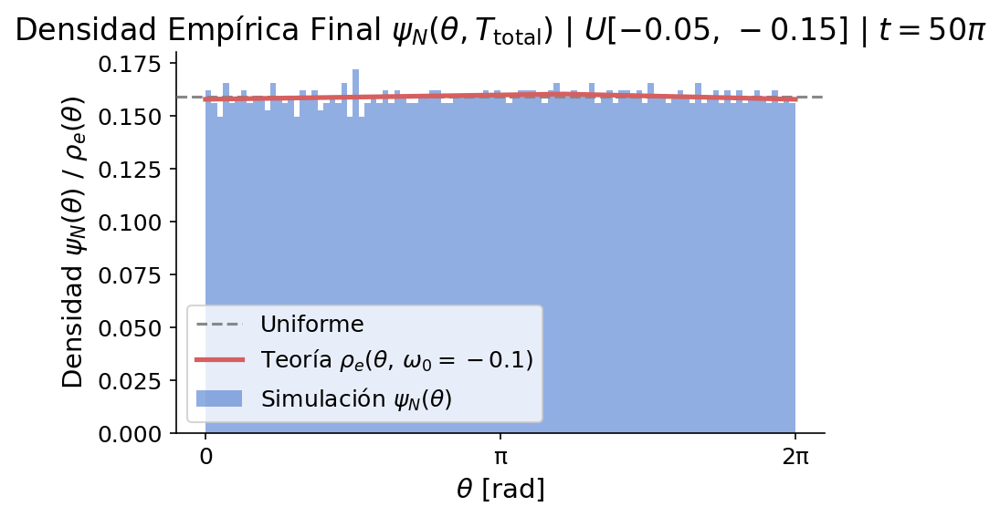

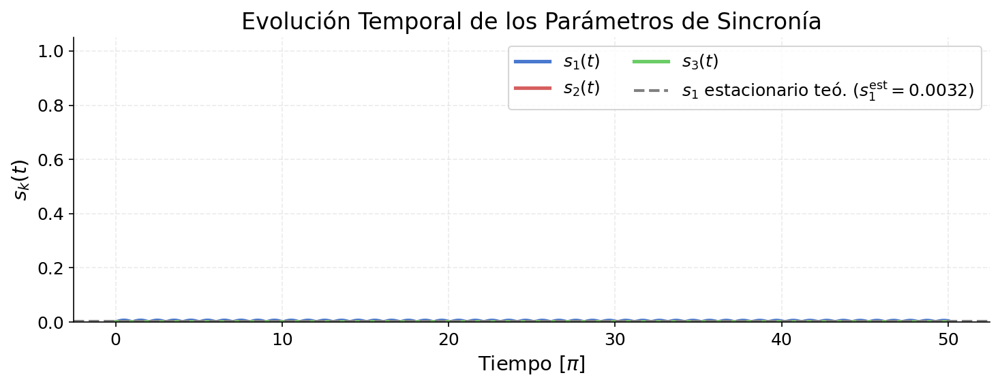

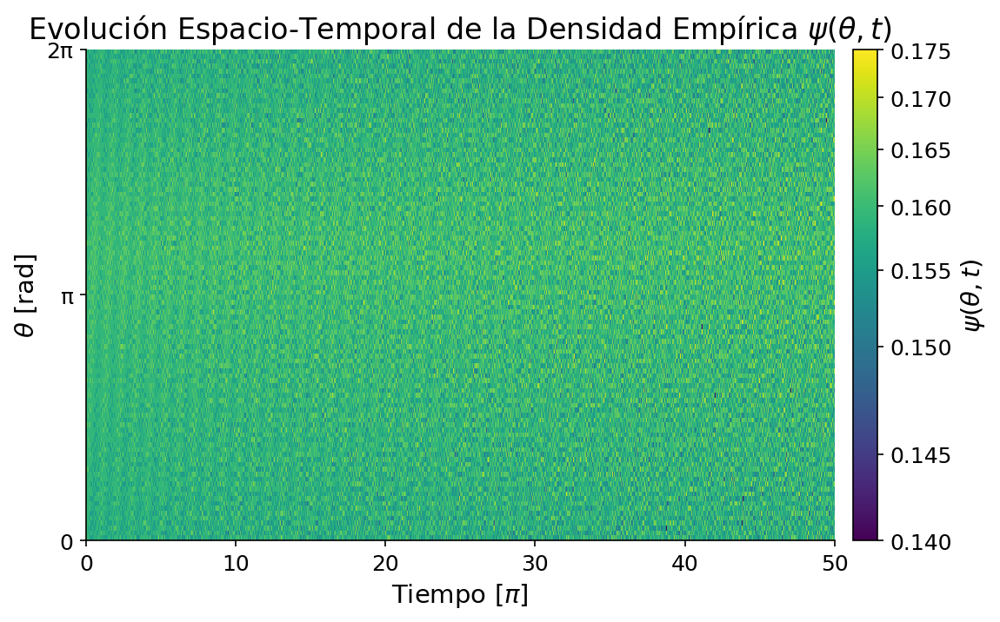

,Pico,ν / π,ν,T / π,T = 2π/ν,P(ν),P / P_dom,Dominante
0,1,0.636408,1.999334,1.000333,3.14264,1.260923e-06,1.000000,Sí
1,2,1.272815,3.998667,0.500167,1.57132,2.757870e-08,0.021872,


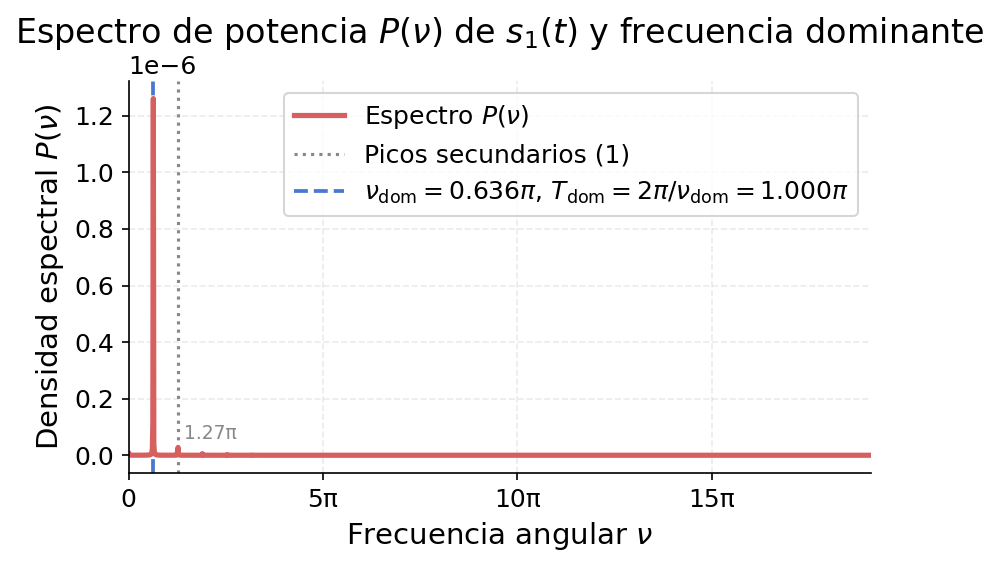

s₁ final = 0.0039 | s₁ᵉˢᵗ = 0.0032 | ν_dom = 0.6364π | T_dom = 2π/ν_dom = 1.0003π

  Tent + Uniforme | μ = -1.0, Δ = -1.0


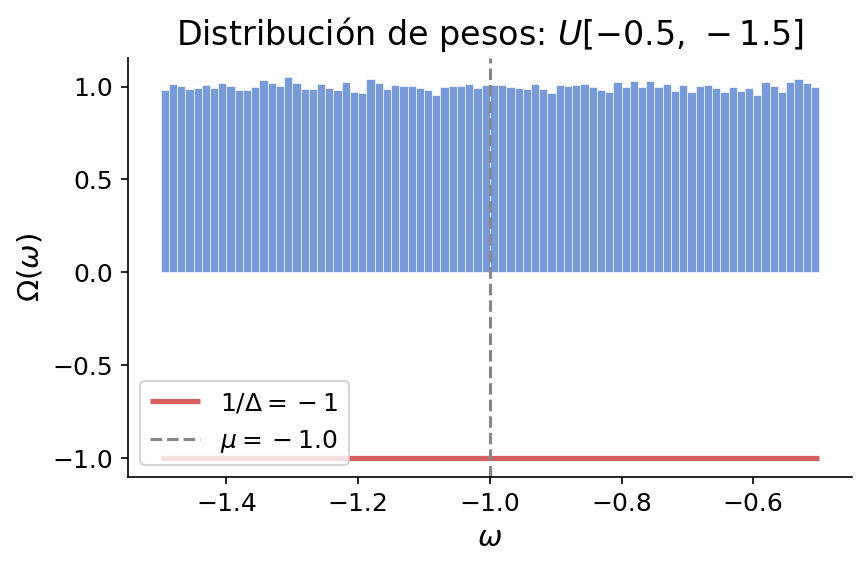

KeyboardInterrupt: 

In [67]:
#  BARRIDO F | Modelo Tent — Distribución Uniforme (Δ = μ_ω)

# 1. Configuración de parámetros y definición de la grilla
N              = 5000
I0             = 1.0
T_total        = 50 * np.pi
T_hist         = np.pi / 60
n_bins         = 100
omegas_barrido = [-0.01, -0.1, -1.0, -10.0, -100.0]

# 2. Contenedor de almacenamiento para los resultados del barrido
resultados_F = {}

# 3. Bucle iterativo con fluctuaciones estocásticas en el modelo tent
for mu in omegas_barrido:
    print(f"\n{'='*60}\n  Tent + Uniforme | μ_ω = {mu}, Δ = {mu}\n{'='*60}")

    # Distribución uniforme con desorden recocido
    sampler, omega_info = make_omega_dist('uniforme', mu=mu, Delta=mu)
    plot_omega_dist(omega_info)

    # Ejecución de la dinámica (genera gráfico único sₖ(t) con s₁ᵉˢᵗ)
    phis_f, tiempos, s_dict, histogramas = simular_QIF(
        N            = N,
        sampler      = sampler,
        omega_info   = omega_info,
        Z_fn         = Z_tent,
        T            = np.pi,
        rho_e_fn     = rho_e_tent,
        I0           = I0,
        T_total      = T_total,
        T_hist       = T_hist,
        n_bins       = n_bins,
        cond_inicial = 'equiespaciado',
        mu_w_ref   = mu,
        guardar_figs = True,
    )

    # Espectro P(ν) de s₁(t) (ν = 2πf), picos prominentes y frecuencia dominante ν_dom
    s_1_serie = s_dict[1]
    T_dom, nu_dom, nus, psd, df_picos = calcular_periodo_fft(tiempos, s_1_serie)
    s1_est = calcular_s1_estacionario(rho_e_tent, mu, I0)

    # Tabla de picos y espectro P(ν) con ν en múltiplos de π (picos con líneas punteadas)
    display(df_picos)
    plot_espectro_fft(nus, psd, nu_dom, T_dom, df_picos=df_picos, fname=f'espectro_fft_tent_unif_mu_{mu}.png')

    # Persistencia de resultados con métricas espectrales
    resultados_F[mu] = dict(
        s_dict   = s_dict,
        tiempos  = tiempos,
        s1_est   = s1_est,
        nu_dom   = nu_dom,
        T_dom    = T_dom,
        nus      = nus,
        psd      = psd,
        picos    = df_picos,
    )

    print(f"s₁ final = {s_dict[1][-1]:.4f} | s₁ᵉˢᵗ = {s1_est:.4f} | ν_dom = {fmt_mult_pi(nu_dom, 4)} | T_dom = 2π/ν_dom = {fmt_mult_pi(T_dom, 4)}")

# 4. Tabla resumen comparativa del barrido paramétrico
tabla_resumen_F = pd.DataFrame([
    {
        'μ_ω [u.v.]': mu,
        's₁ final': float(res['s_dict'][1][-1]),
        's₁ᵉˢᵗ (teórico)': res['s1_est'],
        'ν_dom / π [rad/u.t.]': res['nu_dom'] / np.pi,      # Frecuencia angular dominante en múltiplos de π
        'T_dom / π [u.t.]': res['T_dom'] / np.pi,       # Período dominante T_dom = 2π/ν_dom en múltiplos de π
        'N° picos': len(res['picos']),
    }
    for mu, res in resultados_F.items()
])

print(f"\n{'='*70}\n  RESUMEN DEL BARRIDO F (TENT + UNIFORME): SINCRONÍA Y ESPECTRO P(ν)\n{'='*70}")
display(tabla_resumen_F)


### Barrido G | Modelo SNL — Distribución Delta (Excitabilidad Tipo II Determinista)

1. **¿Qué hace esta celda?**  
   Investiga la sincronización y la frecuencia de oscilación colectiva en una red de osciladores cercanos a una bifurcación SNL (Saddle-Node Loop, excitabilidad Tipo II, $\vartheta = 0$) bajo acoplamientos inhibitorios homogéneos, midiendo el período $T_{\text{dom}}$ mediante FFT.

2. **¿Cómo lo hace?**  
   Aplica la PRC $Z_{\text{SNL}}(\phi) = I_0 \cos^2(\phi/4)$ y contrasta la dinámica con $\rho_{e,\text{SNL}}(\phi)$ para intensidades $\mu_\omega \in \{-0.01, -0.1, -1.0, -10.0, -100.0\}$. Aplica `simular_QIF`, realiza el análisis espectral con `calcular_periodo_fft`, grafica el espectro FFT vía `plot_espectro_fft` y almacena los resultados en `resultados_G`.

3. **¿Qué devuelve o cuál es su resultado/salida?**  
   Despliega los 4 paneles diagnósticos y el espectro FFT por cada valor de $\mu_\omega$, calcula la sincronía y el período colectivo en el diccionario `resultados_G`, y genera la tabla resumen final del barrido.


In [ ]:
#  BARRIDO G | Modelo SNL — Distribución Delta

# 1. Configuración de parámetros y grilla de barrido para excitabilidad Tipo II
N              = 5000
I0             = 1.0
T_total        = 50 * np.pi
T_hist         = np.pi / 60
n_bins         = 100
omegas_barrido = [-0.01, -0.1, -1.0, -10.0, -100.0]

# 2. Contenedor de almacenamiento para los resultados del barrido
resultados_G = {}

# 3. Bucle iterativo en el modelo SNL con interacción determinista
for mu in omegas_barrido:
    print(f"\n{'='*60}\n  SNL + Delta | μ_ω = {mu}\n{'='*60}")

    # Muestreo homogéneo determinista
    sampler, omega_info = make_omega_dist('delta', mu=mu)
    plot_omega_dist(omega_info)

    # Simulación con PRC de bifurcación SNL (genera gráfico único sₖ(t) con s₁ᵉˢᵗ)
    phis_f, tiempos, s_dict, histogramas = simular_QIF(
        N            = N,
        sampler      = sampler,
        omega_info   = omega_info,
        Z_fn         = Z_SNL,
        T            = np.pi,
        rho_e_fn     = rho_e_SNL,
        I0           = I0,
        T_total      = T_total,
        T_hist       = T_hist,
        n_bins       = n_bins,
        cond_inicial = 'equiespaciado',
        mu_w_ref   = mu,
        guardar_figs = True,
    )

    # Espectro P(ν) de s₁(t) (ν = 2πf), picos prominentes y frecuencia dominante ν_dom
    s_1_serie = s_dict[1]
    T_dom, nu_dom, nus, psd, df_picos = calcular_periodo_fft(tiempos, s_1_serie)
    s1_est = calcular_s1_estacionario(rho_e_SNL, mu, I0)

    # Tabla de picos y espectro P(ν) con ν en múltiplos de π (picos con líneas punteadas)
    display(df_picos)
    plot_espectro_fft(nus, psd, nu_dom, T_dom, df_picos=df_picos, fname=f'espectro_fft_SNL_delta_mu_{mu}.png')

    # Persistencia de resultados con métricas espectrales
    resultados_G[mu] = dict(
        s_dict   = s_dict,
        tiempos  = tiempos,
        s1_est   = s1_est,
        nu_dom   = nu_dom,
        T_dom    = T_dom,
        nus      = nus,
        psd      = psd,
        picos    = df_picos,
    )

    print(f"s₁ final = {s_dict[1][-1]:.4f} | s₁ᵉˢᵗ = {s1_est:.4f} | ν_dom = {fmt_mult_pi(nu_dom, 4)} | T_dom = 2π/ν_dom = {fmt_mult_pi(T_dom, 4)}")

# 4. Tabla resumen comparativa del barrido paramétrico
tabla_resumen_G = pd.DataFrame([
    {
        'μ_ω [u.v.]': mu,
        's₁ final': float(res['s_dict'][1][-1]),
        's₁ᵉˢᵗ (teórico)': res['s1_est'],
        'ν_dom / π [rad/u.t.]': res['nu_dom'] / np.pi,      # Frecuencia angular dominante en múltiplos de π
        'T_dom / π [u.t.]': res['T_dom'] / np.pi,       # Período dominante T_dom = 2π/ν_dom en múltiplos de π
        'N° picos': len(res['picos']),
    }
    for mu, res in resultados_G.items()
])

print(f"\n{'='*70}\n  RESUMEN DEL BARRIDO G (SNL + DELTA): SINCRONÍA Y ESPECTRO P(ν)\n{'='*70}")
display(tabla_resumen_G)
